<a href="https://colab.research.google.com/github/Favian92/BIAnalyst/blob/main/CTGAN%20with%20RSCV-Ensemble.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install xgboost imblearn imbalanced-learn scikit-optimize hyperopt pyswarms pyswarm optuna pygad deap ucimlrepo ctgan sdv

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.1/104.1 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.8/91.8 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.0/136.0 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.2/203.2 kB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.6/140.6 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.9/14.9 MB 76.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.5/74.5 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 202.3/202.3 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 78.3 MB/s eta 0:00:00
   ━━

In [2]:
#Data Analytics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#ML Model
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

#Hyperparameter & Balancing
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTETomek, SMOTEENN
from imblearn.over_sampling import SMOTE, ADASYN, SVMSMOTE
from imblearn.under_sampling import TomekLinks
from skopt import BayesSearchCV
from sklearn.base import clone
import pygad

#Preprocessing
from skopt.space import Integer, Real
from collections import Counter
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer

# Statistic & Testing
from scipy import stats
from scipy.stats import randint, uniform, f_oneway
import scipy.stats as st
import statsmodels.api as sm
from statsmodels.stats.multicomp import pairwise_tukeyhsd, MultiComparison

#Evaluation
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, roc_auc_score, precision_score, recall_score, roc_curve, balanced_accuracy_score, auc

import time
import json
import os
import warnings
warnings.filterwarnings

<function warnings.filterwarnings(action, message='', category=<class 'Warning'>, module='', lineno=0, append=False)>

Dataset 1 : Enviroment

In [3]:
DATA_PATH = "water_pollution_disease.csv"  # ganti dengan nama file datasetmu
df = pd.read_csv(DATA_PATH)

# === Label Biner untuk Kualitas Air (Layak / Tidak Layak) ===
conditions = ((df["pH Level"].between(6.5, 8.5)) &
              (df["Nitrate Level (mg/L)"] <= 50) &
              (df["Lead Concentration (µg/L)"] <= 10) &
              (df["Turbidity (NTU)"] <= 5) &
              (df["Dissolved Oxygen (mg/L)"] >= 5) )

df["Water_Quality"] = np.where(conditions, "Drinkable Water (1)", "Contaminated Water (0)")

# === Tentukan target ===
TARGET = "Water_Quality"

OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# === 1. Load data ===
X = df.drop(columns=[TARGET])
y = df[TARGET]
random_state = 42

df.to_csv(f"{OUTPUT_DIR}/data_dengan_label_water_quality.csv", index=False)

In [4]:
# === 2. Encoding Features ===
from sklearn.preprocessing import LabelEncoder

# Kolom untuk One Hot Encoding (nominal)
categorical_cols_ohe = ["Water Source Type","Water Treatment Method"]

# Kolom untuk Label Encoding (ordinal)
categorical_cols_le = []

# Kolom numerik (langsung dipakai)
numeric_cols = ["Contaminant Level (ppm)", "Rainfall (mm per year)",
                "Temperature (°C)","Population Density (people per km²)",
                "Bacteria Count (CFU/mL)","Access to Clean Water (% of Population)",
                "Sanitation Coverage (% of Population)","Healthcare Access Index (0-100)",
                "Urbanization Rate (%)"
                ]

# Drop kolom tidak relevant
drop_cols = ["Country",
             "Region",
             "Year",
             "GDP per Capita (USD)",
             "Diarrheal Cases per 100,000 people",
             "Cholera Cases per 100,000 people",
             "Typhoid Cases per 100,000 people",
             "Infant Mortality Rate (per 1,000 live births)",
             'pH Level','Nitrate Level (mg/L)','Lead Concentration (µg/L)','Bacteria Count (CFU/mL)','Turbidity (NTU)','Dissolved Oxygen (mg/L)'
            ]

# Buang ID dulu
X = X.drop(columns=drop_cols, errors="ignore")

# 1. Label Encoding untuk ordinal
for col in categorical_cols_le:
    if col in X.columns:
        le = LabelEncoder()
        X[col] = le.fit_transform(X[col].astype(str))
        print(f"Label Encoded: {col}")

# 2. One Hot Encoding untuk nominal
X = pd.get_dummies(X, columns=categorical_cols_ohe, drop_first=True)

# 3. Encode target
le_y = LabelEncoder()
y = le_y.fit_transform(y)

print("\nFirst 5 rows of X after Encoding:")
display(X.head())
print("\nFirst 5 values of y after Encoding:")
print(y[:5])
print("\nUnique values in y after Encoding:")
print(np.unique(y))


df_encoded = X.copy()
df_encoded["Water_Quality_Encoded"] = y
df_encoded.to_csv(f"{OUTPUT_DIR}/data_encoded_full.csv", index=False)


First 5 rows of X after Encoding:


,Contaminant Level (ppm),Access to Clean Water (% of Population),Healthcare Access Index (0-100),Urbanization Rate (%),Sanitation Coverage (% of Population),Rainfall (mm per year),Temperature (°C),Population Density (people per km²),Water Source Type_Pond,Water Source Type_River,Water Source Type_Spring,Water Source Type_Tap,Water Source Type_Well,Water Treatment Method_Chlorination,Water Treatment Method_Filtration
0,6.06,33.60,96.92,84.61,63.23,2800,4.94,593,False,False,False,False,False,False,True
1,5.24,89.54,84.73,73.37,29.12,1572,16.93,234,False,False,False,False,True,False,False
2,0.24,35.29,58.37,72.86,93.56,2074,21.73,57,True,False,False,False,False,False,False
3,7.91,57.53,39.07,71.07,94.25,937,3.79,555,False,False,False,False,True,False,False
4,0.12,36.60,23.03,55.55,69.23,2295,31.44,414,False,False,False,False,True,False,True



First 5 values of y after Encoding:
[0 0 0 0 0]

Unique values in y after Encoding:
[0 1]


<Figure size 1200x800 with 0 Axes>

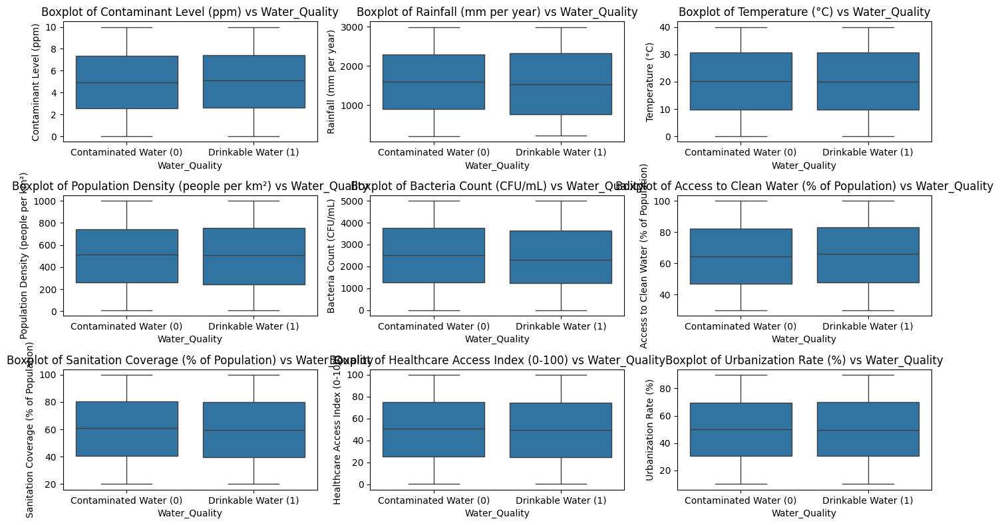

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# === Visualisasi Korelasi Fitur ===
plt.figure(figsize=(12, 8))

# Memilih fitur numerik yang relevan untuk visualisasi korelasi terhadap kualitas air
numeric_features = ["Contaminant Level (ppm)", "Rainfall (mm per year)", "Temperature (°C)",
                    "Population Density (people per km²)", "Bacteria Count (CFU/mL)",
                    "Access to Clean Water (% of Population)", "Sanitation Coverage (% of Population)",
                    "Healthcare Access Index (0-100)", "Urbanization Rate (%)"]

# Menggabungkan data dengan target untuk korelasi
df_corr = df[numeric_features + [TARGET]]

# Plot boxplot untuk setiap fitur terhadap target Water_Quality
plt.figure(figsize=(14, 8))

for i, feature in enumerate(numeric_features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=TARGET, y=feature, data=df_corr)
    plt.title(f'Boxplot of {feature} vs {TARGET}')
    plt.tight_layout()

# Menampilkan boxplot
plt.show()

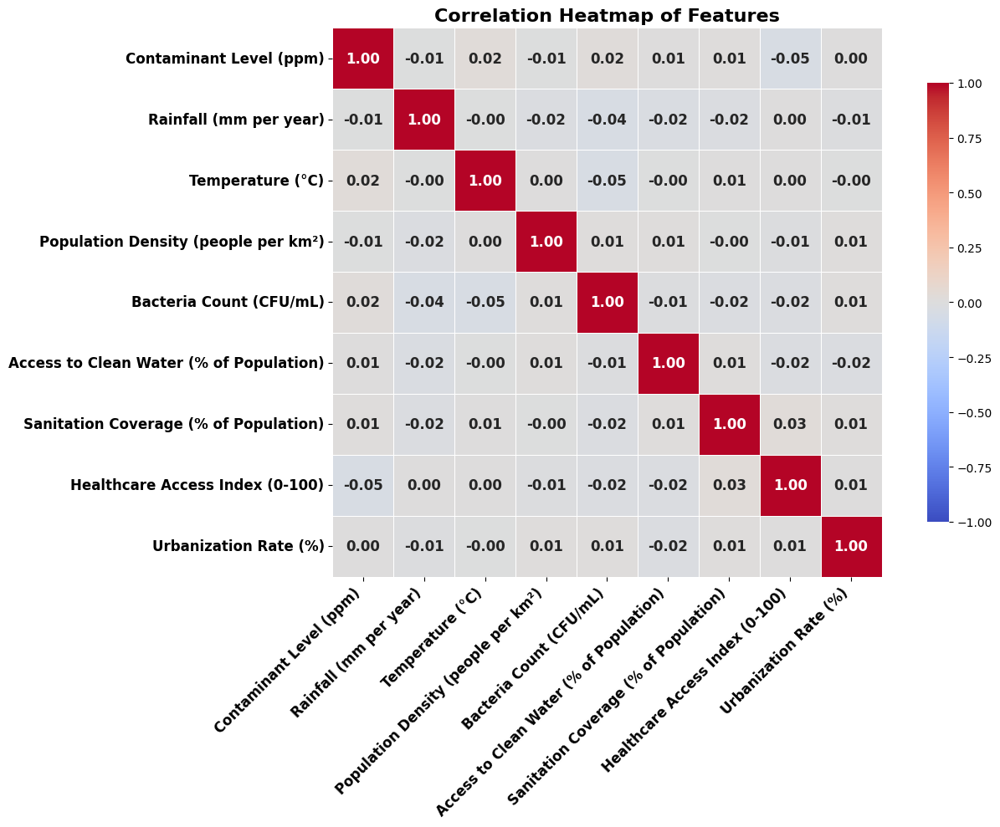

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# === Visualisasi Korelasi Fitur Menggunakan Heatmap (Birunya ke Merah, Nama Hitam) ===
plt.figure(figsize=(14, 10))  # Increase the figure size for larger cells

# Mengambil fitur numerik yang relevan untuk korelasi
numeric_features = ["Contaminant Level (ppm)", "Rainfall (mm per year)", "Temperature (°C)",
                    "Population Density (people per km²)", "Bacteria Count (CFU/mL)",
                    "Access to Clean Water (% of Population)", "Sanitation Coverage (% of Population)",
                    "Healthcare Access Index (0-100)", "Urbanization Rate (%)"]

# Menghitung korelasi antar fitur numerik
corr_matrix = df[numeric_features].corr()

# Membuat heatmap korelasi dengan colormap biru ke merah
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", cbar=True, vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={"size": 12, "weight": 'bold'}, square=True,
            xticklabels=corr_matrix.columns, yticklabels=corr_matrix.columns, cbar_kws={'shrink': 0.8})

# Menyesuaikan label agar lebih hemat ruang dan lebih cerah
plt.xticks(rotation=45, ha='right', fontsize=12, fontweight='bold', color='black')  # Set color to black
plt.yticks(rotation=0, ha='right', fontsize=12, fontweight='bold', color='black')  # Set color to black

plt.title('Correlation Heatmap of Features', fontsize=16, fontweight='bold', color='black')  # Title in black
plt.tight_layout()  # Mengoptimalkan ruang
plt.show()

In [8]:
# Tampilkan semua feature setelah encoding
all_features = X.columns.tolist()

print("Jumlah feature:", len(all_features))
print("Daftar feature:")
print(all_features)

Jumlah feature: 15
Daftar feature:
['Contaminant Level (ppm)', 'Access to Clean Water (% of Population)', 'Healthcare Access Index (0-100)', 'Urbanization Rate (%)', 'Sanitation Coverage (% of Population)', 'Rainfall (mm per year)', 'Temperature (°C)', 'Population Density (people per km²)', 'Water Source Type_Pond', 'Water Source Type_River', 'Water Source Type_Spring', 'Water Source Type_Tap', 'Water Source Type_Well', 'Water Treatment Method_Chlorination', 'Water Treatment Method_Filtration']


In [9]:
# === 3. Split data ===
from sklearn.model_selection import train_test_split

# Pastikan y tetap Series, bukan ndarray
if not isinstance(y, pd.Series):
    y = pd.Series(y, name=TARGET)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=random_state
)

# Simpan hasil split ke file
X_train.to_csv(f"{OUTPUT_DIR}/X_train.csv", index=False)
X_test.to_csv(f"{OUTPUT_DIR}/X_test.csv", index=False)
y_train.to_csv(f"{OUTPUT_DIR}/y_train.csv", index=False, header=True)
y_test.to_csv(f"{OUTPUT_DIR}/y_test.csv", index=False, header=True)

# Preview
print("Preview X_train:")
display(X_train.head())
print("Preview y_train:")
print(y_train.head())


# X_test.head()

Preview X_train:


,Contaminant Level (ppm),Access to Clean Water (% of Population),Healthcare Access Index (0-100),Urbanization Rate (%),Sanitation Coverage (% of Population),Rainfall (mm per year),Temperature (°C),Population Density (people per km²),Water Source Type_Pond,Water Source Type_River,Water Source Type_Spring,Water Source Type_Tap,Water Source Type_Well,Water Treatment Method_Chlorination,Water Treatment Method_Filtration
1054,5.18,71.29,29.36,83.37,58.66,2476,10.60,778,False,True,False,False,False,False,True
2873,1.23,98.54,65.21,53.98,58.74,959,11.04,173,False,True,False,False,False,True,False
827,2.43,79.55,38.41,81.71,54.76,2349,27.31,80,False,True,False,False,False,False,False
1999,8.47,70.82,15.92,79.44,31.17,1391,36.33,176,False,False,False,False,False,False,True
1295,9.53,34.25,15.20,46.47,51.59,939,11.02,85,False,False,False,False,True,True,False


Preview y_train:
1054    0
2873    0
827     0
1999    0
1295    0
Name: Water_Quality, dtype: int64


In [10]:
# === 4. Cek Missing ===
import numpy as np

# Ganti berbagai jenis missing value menjadi np.nan
missing_values = ["#NUM!", "NaN", "nan", "NA", "?", "", " "]

X_train = X_train.replace(missing_values, np.nan)
X_test = X_test.replace(missing_values, np.nan)

# Tambahan: jika ada whitespace lebih dari satu
X_train = X_train.applymap(lambda x: np.nan if isinstance(x, str) and x.strip() == "" else x)
X_test = X_test.applymap(lambda x: np.nan if isinstance(x, str) and x.strip() == "" else x)

print("\nMissing Values Sebelum Imputasi:")
print("X_train:")
print(X_train.isnull().sum())
print("\nX_test:")
print(X_test.isnull().sum())


Missing Values Sebelum Imputasi:
X_train:
Contaminant Level (ppm)                    0
Access to Clean Water (% of Population)    0
Healthcare Access Index (0-100)            0
Urbanization Rate (%)                      0
Sanitation Coverage (% of Population)      0
Rainfall (mm per year)                     0
Temperature (°C)                           0
Population Density (people per km²)        0
Water Source Type_Pond                     0
Water Source Type_River                    0
Water Source Type_Spring                   0
Water Source Type_Tap                      0
Water Source Type_Well                     0
Water Treatment Method_Chlorination        0
Water Treatment Method_Filtration          0
dtype: int64

X_test:
Contaminant Level (ppm)                    0
Access to Clean Water (% of Population)    0
Healthcare Access Index (0-100)            0
Urbanization Rate (%)                      0
Sanitation Coverage (% of Population)      0
Rainfall (mm per year)             

/tmp/ipykernel_10631/1970393462.py:11: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  X_train = X_train.applymap(lambda x: np.nan if isinstance(x, str) and x.strip() == "" else x)
/tmp/ipykernel_10631/1970393462.py:12: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  X_test = X_test.applymap(lambda x: np.nan if isinstance(x, str) and x.strip() == "" else x)


In [11]:
# === 5. Imputasi (fit di train) ===
num_imputer = SimpleImputer(strategy="mean")
X_train_imp = num_imputer.fit_transform(X_train)
X_test_imp = num_imputer.transform(X_test)

X_train_imp_df = pd.DataFrame(X_train_imp, columns=X_train.columns)
X_test_imp_df = pd.DataFrame(X_test_imp, columns=X_test.columns)
X_train_imp_df.to_csv(f"{OUTPUT_DIR}/X_train_imputed.csv", index=False)
X_test_imp_df.to_csv(f"{OUTPUT_DIR}/X_test_imputed.csv", index=False)

print("\nMissing Values Setelah Imputasi:")
print(X_train_imp_df.isnull().sum())
print(X_test_imp_df.isnull().sum())


Missing Values Setelah Imputasi:
Contaminant Level (ppm)                    0
Access to Clean Water (% of Population)    0
Healthcare Access Index (0-100)            0
Urbanization Rate (%)                      0
Sanitation Coverage (% of Population)      0
Rainfall (mm per year)                     0
Temperature (°C)                           0
Population Density (people per km²)        0
Water Source Type_Pond                     0
Water Source Type_River                    0
Water Source Type_Spring                   0
Water Source Type_Tap                      0
Water Source Type_Well                     0
Water Treatment Method_Chlorination        0
Water Treatment Method_Filtration          0
dtype: int64
Contaminant Level (ppm)                    0
Access to Clean Water (% of Population)    0
Healthcare Access Index (0-100)            0
Urbanization Rate (%)                      0
Sanitation Coverage (% of Population)      0
Rainfall (mm per year)                     0
Temperat

In [12]:
# === 6. Standarisasi ===
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Pisahkan kolom numerik dan kategorikal
num_cols = X_train_imp_df.select_dtypes(include=np.number).columns
cat_cols = X_train_imp_df.select_dtypes(exclude=np.number).columns

# Normalisasi kolom numerik
scaler = StandardScaler()
X_train_num_scaled = pd.DataFrame(scaler.fit_transform(X_train_imp_df[num_cols]), columns=num_cols)
X_test_num_scaled = pd.DataFrame(scaler.transform(X_test_imp_df[num_cols]), columns=num_cols)

# Gabungkan kolom numerik dan kategorikal (belum dikodekan)
X_train_scaled_df = pd.concat([X_train_num_scaled, X_train_imp_df[cat_cols].reset_index(drop=True)], axis=1)
X_test_scaled_df = pd.concat([X_test_num_scaled, X_test_imp_df[cat_cols].reset_index(drop=True)], axis=1)

# Ubah kolom kategorikal menjadi kode integer agar konsisten dengan SMOTENC
X_train_coded = X_train_scaled_df.copy()
X_test_coded = X_test_scaled_df.copy()

for col in cat_cols:
    X_train_coded[col] = X_train_coded[col].astype('category').cat.codes
    X_test_coded[col] = X_test_coded[col].astype('category').cat.codes

# Simpan hasil
X_train_scaled_df.to_csv(f"{OUTPUT_DIR}/X_train_normalized.csv", index=False)
X_test_scaled_df.to_csv(f"{OUTPUT_DIR}/X_test_normalized.csv", index=False)
X_train_coded.to_csv(f"{OUTPUT_DIR}/X_train_coded.csv", index=False)
X_test_coded.to_csv(f"{OUTPUT_DIR}/X_test_coded.csv", index=False)

print("Hasil Normalisasi dan Encoding Data X_train")
X_train_coded.head()


Hasil Normalisasi dan Encoding Data X_train


,Contaminant Level (ppm),Access to Clean Water (% of Population),Healthcare Access Index (0-100),Urbanization Rate (%),Sanitation Coverage (% of Population),Rainfall (mm per year),Temperature (°C),Population Density (people per km²),Water Source Type_Pond,Water Source Type_River,Water Source Type_Spring,Water Source Type_Tap,Water Source Type_Well,Water Treatment Method_Chlorination,Water Treatment Method_Filtration
0,0.089825,0.337396,-0.726038,1.466499,-0.087332,1.068969,-0.819823,0.967969,-0.417335,2.140419,-0.468521,-0.441162,-0.446543,-0.586973,1.759421
1,-1.290394,1.685970,0.514133,0.172514,-0.083857,-0.774380,-0.782024,-1.171622,-0.417335,2.140419,-0.468521,-0.441162,-0.446543,1.703655,-0.568369
2,-0.871087,0.746175,-0.412968,1.393412,-0.256717,0.914648,0.615717,-1.500517,-0.417335,2.140419,-0.468521,-0.441162,-0.446543,-0.586973,-0.568369
3,1.239425,0.314136,-1.190972,1.293469,-1.281284,-0.249444,1.390616,-1.161012,-0.417335,-0.467198,-0.468521,-0.441162,-0.446543,-0.586973,1.759421
4,1.609812,-1.495676,-1.215880,-0.158137,-0.394398,-0.798682,-0.783742,-1.482835,-0.417335,-0.467198,-0.468521,-0.441162,2.239428,1.703655,-0.568369


Distribusi kelas target:
                        count  percentage
Water_Quality                            
Contaminated Water (0)   2163        72.1
Drinkable Water (1)       837        27.9


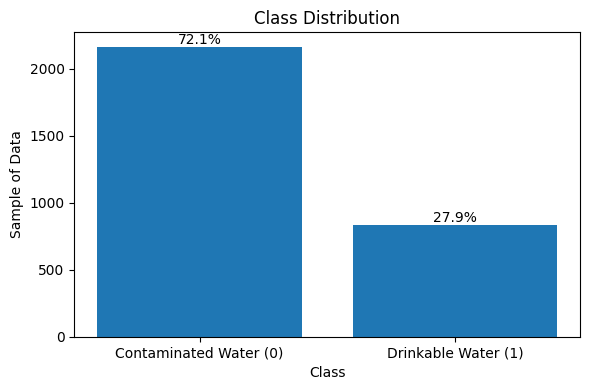

In [13]:
# === 7. Cek imbalance ===
y_train.value_counts().to_csv(f"{OUTPUT_DIR}/class_distribution.csv")

# === Hitung distribusi kelas target ===
class_counts = df[TARGET].value_counts()
class_percent = df[TARGET].value_counts(normalize=True) * 100

# Gabungkan jadi tabel ringkas
imbalance_summary = pd.DataFrame({
    "count": class_counts,
    "percentage": class_percent.round(2)
})
imbalance_summary.to_csv("imbalanced_summary.csv")

print("Distribusi kelas target:")
print(imbalance_summary)

# === 3. Plot distribusi kelas ===
plt.figure(figsize=(6,4))
bars = plt.bar(class_counts.index.astype(str), class_counts.values)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Sample of Data")

# Tambahkan persentase di atas bar
for bar, pct in zip(bars, class_percent.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{pct:.1f}%",
        ha="center", va="bottom"
    )

plt.tight_layout()
plt.savefig("imbalanced_plot.png")  # simpan chart ke file
plt.show()


=== SMOTENC Oversampling ===
               count  percent
Water_Quality                
0               1730     50.0
1               1730     50.0


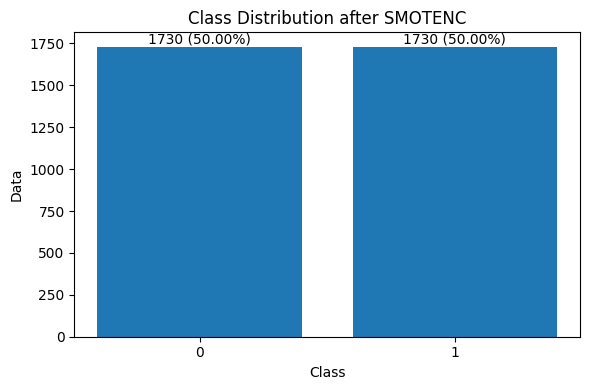


=== CTGAN Oversampling ===


/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:178: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:134: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


        count  percent
target                
0        3041     50.0
1        3041     50.0


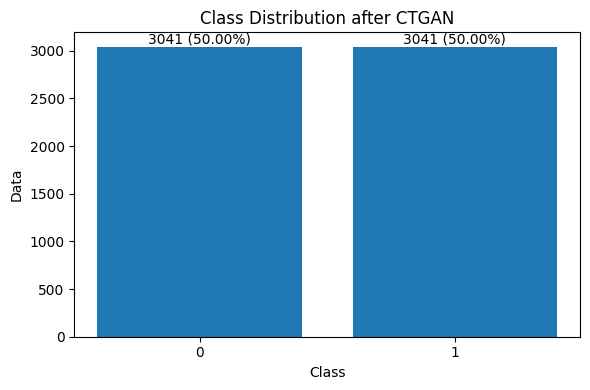

In [14]:
# === Import Library ===
from imblearn.over_sampling import SMOTENC, RandomOverSampler
from sdv.single_table import CTGANSynthesizer
from sdv.metadata import SingleTableMetadata
import pandas as pd
import matplotlib.pyplot as plt

# === Konfigurasi ===
RANDOM_STATE = 42
OUTPUT_DIR = "./output"

# === Load Data ===
X_train_coded_df = pd.read_csv(f"{OUTPUT_DIR}/X_train_coded.csv")
y_train = pd.read_csv(f"{OUTPUT_DIR}/y_train.csv").squeeze()

# === Kolom kategorikal ===
categorical_features = [
    'Water Source Type_Pond',
    'Water Source Type_River',
    'Water Source Type_Spring',
    'Water Source Type_Tap',
    'Water Source Type_Well',
    'Water Treatment Method_Chlorination',
    'Water Treatment Method_Filtration'
]
categorical_indices = [
    X_train_coded_df.columns.get_loc(col) for col in categorical_features
]

# === Simpan hasil setiap metode ===
resampled_data = {}

# === Definisikan semua oversampler (termasuk CTGAN) ===
oversamplers = {
    "SMOTENC": SMOTENC(
        categorical_features=categorical_indices,
        k_neighbors=1,
        random_state=RANDOM_STATE
    ),
    # "ROS": RandomOverSampler(
    #     sampling_strategy=0.95,
    #     random_state=RANDOM_STATE
    # ),
    "CTGAN": None  # CTGAN tidak punya class bawaan imblearn
}

# === Loop oversampling ===
for oversampler_name, oversampler in oversamplers.items():
    print(f"\n=== {oversampler_name} Oversampling ===")

    if oversampler_name in ["SMOTENC"]:
        # Jalankan metode imblearn biasa
        X_res, y_res = oversampler.fit_resample(X_train_coded_df, y_train)

    # if oversampler_name in ["SMOTENC", "ROS"]:
    #     # Jalankan metode imblearn biasa
    #     X_res, y_res = oversampler.fit_resample(X_train_coded_df, y_train)

    elif oversampler_name == "CTGAN":
        # ✅ Gabungkan X dan y
        train_df = X_train_coded_df.copy()
        train_df["target"] = y_train.values

        # ✅ Buat metadata dari seluruh dataset (bukan hanya minoritas)
        metadata = SingleTableMetadata()
        metadata.detect_from_dataframe(train_df)

        # ✅ Buat dan latih synthesizer dengan epoch lebih kecil
        synthesizer = CTGANSynthesizer(
            metadata,
            epochs=150,
            batch_size=128,
            pac=1,
            verbose=False
        )
        synthesizer.fit(train_df)

        # ✅ Generate data sintetis sebanyak data asli (biar variasi cukup)
        synthetic_data = synthesizer.sample(num_rows=len(train_df))
        synthetic_data = synthetic_data.dropna()

        # ✅ Gabungkan data asli dan sintetis
        combined_df = pd.concat([train_df, synthetic_data], ignore_index=True)

        # ✅ Samakan jumlah tiap kelas agar seimbang
        class_counts = combined_df["target"].value_counts()
        min_count = class_counts.max()

        balanced_df = pd.concat([
            combined_df[combined_df["target"] == c].sample(
                min_count, replace=True, random_state=RANDOM_STATE
            )
            for c in class_counts.index
        ], ignore_index=True)

        X_res = balanced_df.drop(columns=["target"])
        y_res = balanced_df["target"]

    # === Simpan hasil setiap metode ===
    resampled_data[oversampler_name] = (X_res, y_res)
    pd.DataFrame(X_res, columns=X_train_coded_df.columns).to_csv(
        f"{OUTPUT_DIR}/X_train_{oversampler_name}.csv", index=False)
    pd.Series(y_res, name="target").to_csv(
        f"{OUTPUT_DIR}/y_train_{oversampler_name}.csv", index=False)

    # === Distribusi kelas ===
    class_counts = pd.Series(y_res).value_counts()
    class_percent = pd.Series(y_res).value_counts(normalize=True) * 100
    print(pd.DataFrame({"count": class_counts, "percent": class_percent.round(2)}))

    # === Visualisasi distribusi ===
    plt.figure(figsize=(6, 4))
    bars = plt.bar(class_counts.index.astype(str), class_counts.values)
    plt.title(f"Class Distribution after {oversampler_name}")
    plt.xlabel("Class")
    plt.ylabel("Data")
    for bar, cnt, pct in zip(bars, class_counts.values, class_percent.values):
        plt.text(
                 bar.get_x() + bar.get_width() / 2,
                 bar.get_height(),
                 f"{cnt} ({pct:.2f}%)",
                 ha="center",
                 va="bottom"
        )
    plt.tight_layout()
    plt.show()


SEBELUM PENANGANAN

RF BAGGING


=== Training Random Forest Sebelum Penanganan ===


=== Training Bagging Sebelum Penanganan ===


=== Final Summary Random Forest vs Bagging ===
   mean_acc   std_acc  mean_precision  std_precision  mean_recall  std_recall  \
0  0.717067  0.003512        0.480452       0.120571     0.499020    0.003905   
1  0.714067  0.004515        0.542388       0.044150     0.506212    0.006454   

    mean_f1    std_f1  mean_roc_auc  std_roc_auc    model  
0  0.424348  0.006932      0.490866     0.014533       RF  
1  0.449354  0.011737      0.497212     0.013248  Bagging  

=== Random Forest Iteration Results ===
    iter  accuracy  precision    recall        f1   roc_auc
0      1  0.711667   0.359428  0.493072  0.415774  0.499156
1      2  0.720000   0.527638  0.500685  0.424329  0.475799
2      3  0.720000   0.561345  0.502524  0.429916  0.494683
3      4  0.713333   0.471517  0.497905  0.427379  0.488024
4      5  0.723333   0.648278  0.508512  0.442092  0.502392
5      6  0.716667   0.460504

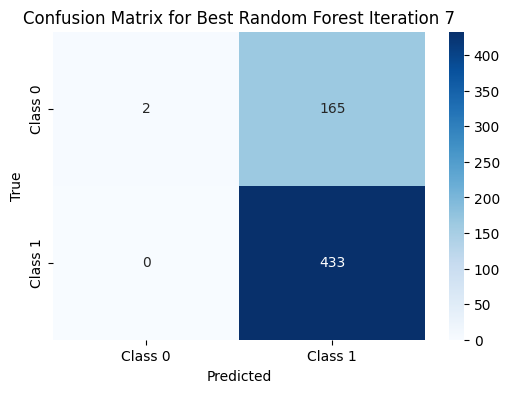


Best Iteration for Bagging: Iteration 15 with Accuracy 0.7250


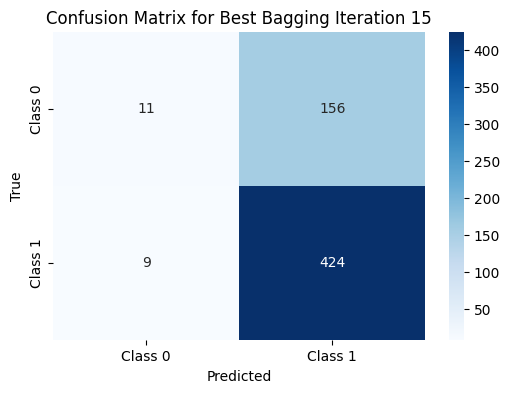

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42

y_train_int = y_train.astype(int)
y_test_int = y_test.astype(int)

# =========================
# RANDOM FOREST
# =========================
print("\n=== Training Random Forest Sebelum Penanganan ===\n")

results_rf = []
best_rf_iter = None
best_rf_acc = -1  # Start with a very low value for accuracy

# Loop untuk 25 iterasi
for i in range(25):
    rf = RandomForestClassifier(
        random_state=RANDOM_STATE + i,
        n_jobs=-1
    )
    rf.fit(X_train_scaled_df, y_train_int)

    y_prob = rf.predict_proba(X_test_scaled_df)[:, 1]
    y_pred = rf.predict(X_test_scaled_df)

    acc = accuracy_score(y_test_int, y_pred)

    # Track the best iteration based on accuracy
    if acc > best_rf_acc:
        best_rf_acc = acc
        best_rf_iter = i

    results_rf.append({
        "iter": i + 1,
        "accuracy": acc,
        "precision": precision_score(y_test_int, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_test_int, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_test_int, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_test_int, y_prob),
    })

# =========================
# BAGGING
# =========================
print("\n=== Training Bagging Sebelum Penanganan ===\n")

results_bag = []
best_bag_iter = None
best_bag_acc = -1  # Start with a very low value for accuracy

# Loop untuk 25 iterasi
for i in range(25):
    bag = BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE + i),
        n_estimators=100,
        random_state=RANDOM_STATE + i,
        n_jobs=-1
    )
    bag.fit(X_train_scaled_df, y_train_int)

    y_prob = bag.predict_proba(X_test_scaled_df)[:, 1]
    y_pred = bag.predict(X_test_scaled_df)

    acc = accuracy_score(y_test_int, y_pred)

    # Track the best iteration based on accuracy
    if acc > best_bag_acc:
        best_bag_acc = acc
        best_bag_iter = i

    results_bag.append({
        "iter": i + 1,
        "accuracy": acc,
        "precision": precision_score(y_test_int, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_test_int, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_test_int, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_test_int, y_prob),
    })

# =========================
# FINAL SUMMARY
# =========================

# Fungsi untuk menghasilkan ringkasan (mean dan std) dari hasil
def summarize_results(results):
    df = pd.DataFrame(results)
    summary = {
        "mean_acc": df['accuracy'].mean(),
        "std_acc": df['accuracy'].std(),
        "mean_precision": df['precision'].mean(),
        "std_precision": df['precision'].std(),
        "mean_recall": df['recall'].mean(),
        "std_recall": df['recall'].std(),
        "mean_f1": df['f1'].mean(),
        "std_f1": df['f1'].std(),
        "mean_roc_auc": df['roc_auc'].mean(),
        "std_roc_auc": df['roc_auc'].std(),
    }
    return summary

# Hasil Summary untuk Random Forest dan Bagging
rf_summary = summarize_results(results_rf)
rf_summary['model'] = 'RF'
bagging_summary = summarize_results(results_bag)
bagging_summary['model'] = 'Bagging'

# Gabungkan Summary Final
final_summary = pd.DataFrame([rf_summary, bagging_summary])

# Tampilkan hasil final summary
print("\n=== Final Summary Random Forest vs Bagging ===")
print(final_summary)

# Simpan hasil final summary
final_summary.to_csv(f"{OUTPUT_DIR}/final_summary_rf_vs_bagging.csv", index=False)

# =========================
# Display Results for Each Iteration
# =========================
# Display the results for Random Forest iteratively
df_rf = pd.DataFrame(results_rf)
print("\n=== Random Forest Iteration Results ===")
print(df_rf)

df_rf.to_csv(f"{OUTPUT_DIR}/rf_iteration_results.csv", index=False)

# Display the results for Bagging iteratively
df_bag = pd.DataFrame(results_bag)
print("\n=== Bagging Iteration Results ===")
print(df_bag)

df_bag.to_csv(f"{OUTPUT_DIR}/bagging_iteration_results.csv", index=False)

# Show Confusion Matrix for the best iteration based on accuracy
best_rf_result = results_rf[best_rf_iter]
print(f"\nBest Iteration for Random Forest: Iteration {best_rf_iter + 1} with Accuracy {best_rf_acc:.4f}")

# Confusion Matrix for Random Forest
rf = RandomForestClassifier(random_state=RANDOM_STATE + best_rf_iter, n_jobs=-1)
rf.fit(X_train_scaled_df, y_train_int)
y_pred_best_rf = rf.predict(X_test_scaled_df)
cm_rf = confusion_matrix(y_test_int, y_pred_best_rf)
# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues", xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.title(f'Confusion Matrix for Best Random Forest Iteration {best_rf_iter + 1}')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Show Confusion Matrix for Bagging
best_bag_result = results_bag[best_bag_iter]
print(f"\nBest Iteration for Bagging: Iteration {best_bag_iter + 1} with Accuracy {best_bag_acc:.4f}")

bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE + best_bag_iter), n_estimators=100, random_state=RANDOM_STATE + best_bag_iter, n_jobs=-1)
bag.fit(X_train_scaled_df, y_train_int)
y_pred_best_bag = bag.predict(X_test_scaled_df)
cm_bag = confusion_matrix(y_test_int, y_pred_best_bag)
# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm_bag, annot=True, fmt="d", cmap="Blues", xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.title(f'Confusion Matrix for Best Bagging Iteration {best_bag_iter + 1}')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

RSCV-RF BAGGING


=== Training Random Forest dengan RandomizedSearchCV ===


=== Training Bagging dengan RandomizedSearchCV ===


=== Final Summary Random Forest vs Bagging ===
   mean_acc   std_acc  mean_precision  std_precision  mean_recall  std_recall  \
0  0.721333  0.001273        0.402861       0.122465     0.500137    0.001753   
1  0.720733  0.001929        0.396232       0.111905     0.499721    0.001102   

    mean_f1    std_f1  mean_roc_auc  std_roc_auc    model  
0  0.420196  0.003866      0.495468     0.011591       RF  
1  0.419969  0.003197      0.524604     0.013930  Bagging  

=== Random Forest Iteration Results ===
    iter  accuracy  precision    recall        f1   roc_auc
0      1  0.721667   0.360833  0.500000  0.419167  0.512356
1      2  0.721667   0.360833  0.500000  0.419167  0.508152
2      3  0.720000   0.360601  0.498845  0.418605  0.473524
3      4  0.721667   0.360833  0.500000  0.419167  0.486620
4      5  0.721667   0.611204  0.501839  0.424928  0.503354
5      6  0.721

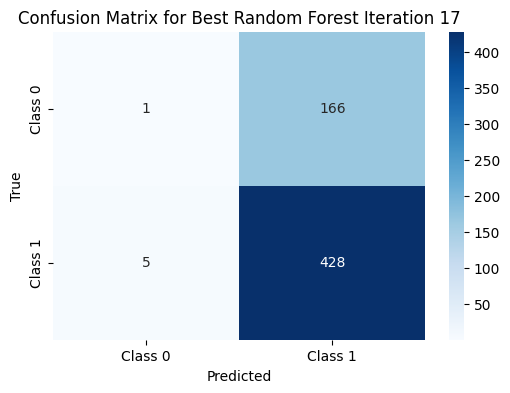


Best Iteration for Bagging: Iteration 6 with Accuracy 0.7233


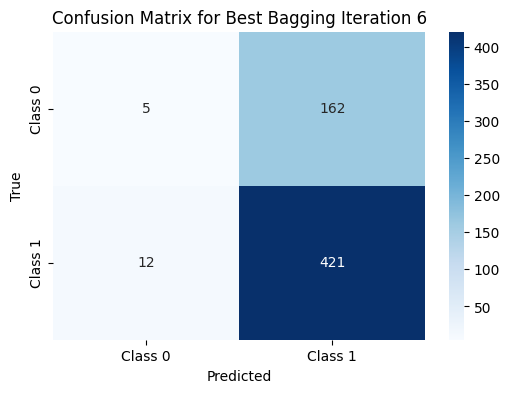

In [ ]:
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

RANDOM_STATE = 42

# Parameter grid untuk RandomizedSearch pada Random Forest
param_dist_rf = {
    'n_estimators': [50, 100, 200],
    'max_features': ['sqrt'],  # Gantilah 'auto' dengan 'sqrt' atau 'log2'
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

# Parameter grid untuk RandomizedSearch pada Bagging
param_dist_bag = {
    'n_estimators': [50, 100, 200, 300],
    'max_samples': [0.5, 0.7, 1.0],
    'max_features': [0.5, 0.7, 1.0],
    'bootstrap': [True, False]
}

# =========================
# RANDOM FOREST dengan RandomizedSearchCV
# =========================
print("\n=== Training Random Forest dengan RandomizedSearchCV ===\n")

results_rf = []
best_rf_iter = None
best_rf_acc = -1  # Start with a very low value for accuracy

# Melakukan RandomizedSearchCV untuk Random Forest
for i in range(25):
    rf = RandomForestClassifier(random_state=RANDOM_STATE + i)
    random_search_rf = RandomizedSearchCV(estimator=rf, param_distributions=param_dist_rf, n_iter=10, cv=5, random_state=RANDOM_STATE + i, n_jobs=-1)

    random_search_rf.fit(X_train_scaled_df, y_train_int)
    best_rf = random_search_rf.best_estimator_

    # Prediksi dan probabilitas
    y_prob = best_rf.predict_proba(X_test_scaled_df)[:, 1]
    y_pred = best_rf.predict(X_test_scaled_df)

    acc = accuracy_score(y_test_int, y_pred)

    # Track the best iteration based on accuracy
    if acc > best_rf_acc:
        best_rf_acc = acc
        best_rf_iter = i

    results_rf.append({
        "iter": i + 1,
        "accuracy": acc,
        "precision": precision_score(y_test_int, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_test_int, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_test_int, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_test_int, y_prob),
    })

# =========================
# BAGGING dengan RandomizedSearchCV
# =========================
print("\n=== Training Bagging dengan RandomizedSearchCV ===\n")

results_bag = []
best_bag_iter = None
best_bag_acc = -1  # Start with a very low value for accuracy

# Melakukan RandomizedSearchCV untuk Bagging
for i in range(25):
    bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE + i), random_state=RANDOM_STATE + i)
    random_search_bag = RandomizedSearchCV(estimator=bag, param_distributions=param_dist_bag, n_iter=10, cv=5, random_state=RANDOM_STATE + i, n_jobs=-1)

    random_search_bag.fit(X_train_scaled_df, y_train_int)
    best_bag = random_search_bag.best_estimator_

    # Prediksi dan probabilitas
    y_prob = best_bag.predict_proba(X_test_scaled_df)[:, 1]
    y_pred = best_bag.predict(X_test_scaled_df)

    acc = accuracy_score(y_test_int, y_pred)

    # Track the best iteration based on accuracy
    if acc > best_bag_acc:
        best_bag_acc = acc
        best_bag_iter = i

    results_bag.append({
        "iter": i + 1,
        "accuracy": acc,
        "precision": precision_score(y_test_int, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_test_int, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_test_int, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_test_int, y_prob),
    })

# =========================
# FINAL SUMMARY
# =========================
def summarize_results(results):
    df = pd.DataFrame(results)
    summary = {
        "mean_acc": df['accuracy'].mean(),
        "std_acc": df['accuracy'].std(),
        "mean_precision": df['precision'].mean(),
        "std_precision": df['precision'].std(),
        "mean_recall": df['recall'].mean(),
        "std_recall": df['recall'].std(),
        "mean_f1": df['f1'].mean(),
        "std_f1": df['f1'].std(),
        "mean_roc_auc": df['roc_auc'].mean(),
        "std_roc_auc": df['roc_auc'].std(),
    }
    return summary

# Hasil Summary untuk Random Forest dan Bagging
rf_summary = summarize_results(results_rf)
rf_summary['model'] = 'RF'
bagging_summary = summarize_results(results_bag)
bagging_summary['model'] = 'Bagging'

# Gabungkan Summary Final
final_summary = pd.DataFrame([rf_summary, bagging_summary])

# Tampilkan hasil final summary
print("\n=== Final Summary Random Forest vs Bagging ===")
print(final_summary)

# Simpan hasil final summary
final_summary.to_csv(f"{OUTPUT_DIR}/final_summary_rf_vs_bagging.csv", index=False)

# =========================
# Display Results for Each Iteration
# =========================
# Display the results for Random Forest iteratively
df_rf = pd.DataFrame(results_rf)
print("\n=== Random Forest Iteration Results ===")
print(df_rf)

df_rf.to_csv(f"{OUTPUT_DIR}/rf_iteration_results.csv", index=False)

# Display the results for Bagging iteratively
df_bag = pd.DataFrame(results_bag)
print("\n=== Bagging Iteration Results ===")
print(df_bag)

df_bag.to_csv(f"{OUTPUT_DIR}/bagging_iteration_results.csv", index=False)

# Show Confusion Matrix for the best iteration based on accuracy
best_rf_result = results_rf[best_rf_iter]
print(f"\nBest Iteration for Random Forest: Iteration {best_rf_iter + 1} with Accuracy {best_rf_acc:.4f}")

# Confusion Matrix for Random Forest
rf = RandomForestClassifier(random_state=RANDOM_STATE + best_rf_iter, n_jobs=-1)
rf.fit(X_train_scaled_df, y_train_int)
y_pred_best_rf = rf.predict(X_test_scaled_df)
cm_rf = confusion_matrix(y_test_int, y_pred_best_rf)
# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues", xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.title(f'Confusion Matrix for Best Random Forest Iteration {best_rf_iter + 1}')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Show Confusion Matrix for Bagging
best_bag_result = results_bag[best_bag_iter]
print(f"\nBest Iteration for Bagging: Iteration {best_bag_iter + 1} with Accuracy {best_bag_acc:.4f}")

bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE + best_bag_iter), n_estimators=100, random_state=RANDOM_STATE + best_bag_iter, n_jobs=-1)
bag.fit(X_train_scaled_df, y_train_int)
y_pred_best_bag = bag.predict(X_test_scaled_df)
cm_bag = confusion_matrix(y_test_int, y_pred_best_bag)
# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm_bag, annot=True, fmt="d", cmap="Blues", xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.title(f'Confusion Matrix for Best Bagging Iteration {best_bag_iter + 1}')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

SETELAH PENANGANAN

RF BAGGING


=== Training Random Forest dan Bagging Tanpa RandomizedSearchCV ===


=== Final Summary Random Forest vs Bagging | SMOTENC ===
   mean_acc   std_acc  mean_precision  std_precision  mean_recall  \
0  0.636067  0.010529        0.485143       0.016783     0.489397   
1  0.545000  0.000000        0.486451       0.000000     0.484276   

     std_recall  mean_f1        std_f1  mean_roc_auc   std_roc_auc    model  
0  1.188190e-02  0.47995  1.377421e-02      0.463032  1.538431e-02       RF  
1  2.266233e-16  0.48079  3.399350e-16      0.471470  1.699675e-16  Bagging  

=== Random Forest Iteration Results | SMOTENC ===
    iter  accuracy  precision    recall        f1   roc_auc
0      1  0.643333   0.493383  0.495388  0.485939  0.464667
1      2  0.628333   0.479870  0.484995  0.476671  0.435356
2      3  0.630000   0.478493  0.484311  0.475020  0.455816
3      4  0.645000   0.495000  0.496543  0.486976  0.466015
4      5  0.633333   0.475525  0.482942  0.471526  0.460144
5      6  0.625000 

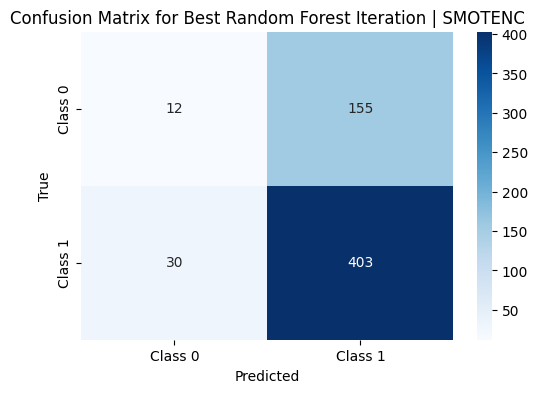


Best Bagging Iteration: Iteration 1 with Accuracy 0.5450


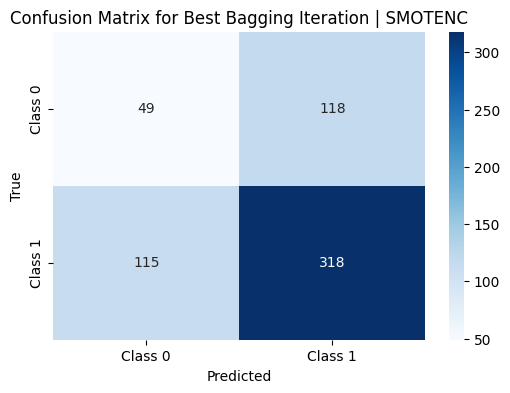


=== Final Summary Random Forest vs Bagging | CTGAN ===
   mean_acc       std_acc  mean_precision  std_precision  mean_recall  \
0  0.674800  8.475455e-03        0.448801       0.025136     0.482537   
1  0.611667  2.266233e-16        0.514069       0.000000     0.513912   

     std_recall   mean_f1        std_f1  mean_roc_auc   std_roc_auc    model  
0  8.757548e-03  0.439806  1.203773e-02      0.500863  1.273202e-02       RF  
1  3.399350e-16  0.513974  2.266233e-16      0.513808  1.133117e-16  Bagging  

=== Random Forest Iteration Results | CTGAN ===
    iter  accuracy  precision    recall        f1   roc_auc
0      1  0.661667   0.438645  0.474983  0.437047  0.501120
1      2  0.691667   0.484929  0.495768  0.451557  0.509985
2      3  0.670000   0.433634  0.477078  0.432816  0.505947
3      4  0.678333   0.484489  0.493888  0.460992  0.522002
4      5  0.675000   0.439964  0.480542  0.435107  0.500422
5      6  0.666667   0.437350  0.476608  0.435411  0.508242
6      7  0.671667

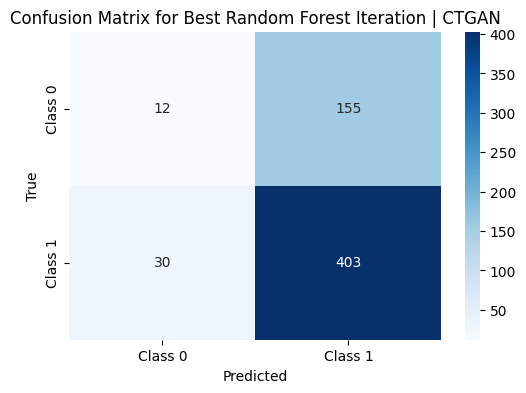


Best Bagging Iteration: Iteration 1 with Accuracy 0.6117


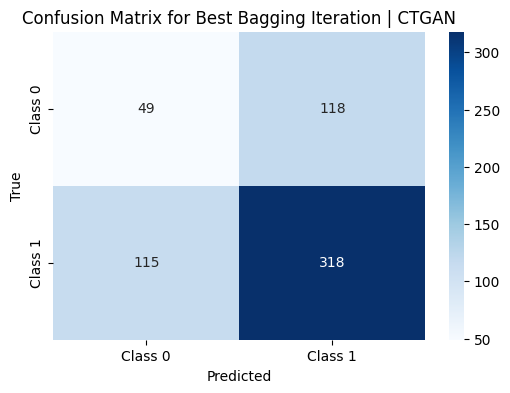

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
import warnings

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42

# =========================
# TRAINING RANDOM FOREST & BAGGING tanpa RandomizedSearch
# =========================
print("\n=== Training Random Forest dan Bagging Tanpa RandomizedSearchCV ===\n")

# Dictionary untuk menyimpan hasil iterasi untuk Random Forest dan Bagging
results_rf = {}
results_bag = {}

# Loop untuk setiap dataset hasil oversampling (misalnya SMOTENC, CTGAN)
for hybrid_name, (X_res, y_res) in resampled_data.items():

    X_res_df = pd.DataFrame(X_res, columns=X_train.columns)

    # Initialize lists to store iteration results for each hybrid_name
    results_rf[hybrid_name] = []
    results_bag[hybrid_name] = []

    # =========================
    # TRAINING RANDOM FOREST
    # =========================
    for i in range(25):  # 25 percobaan untuk setiap dataset
        rf = RandomForestClassifier(random_state=RANDOM_STATE + i, class_weight="balanced", n_jobs=-1)
        rf.fit(X_res_df, y_res)
        y_pred_rf = rf.predict(X_test_scaled_df)
        y_prob_rf = rf.predict_proba(X_test_scaled_df)[:, 1]

        acc_rf = accuracy_score(y_test_int, y_pred_rf)
        precision_rf = precision_score(y_test_int, y_pred_rf, average="macro", zero_division=0)
        recall_rf = recall_score(y_test_int, y_pred_rf, average="macro", zero_division=0)
        f1_rf = f1_score(y_test_int, y_pred_rf, average="macro", zero_division=0)
        roc_auc_rf = roc_auc_score(y_test_int, y_prob_rf)

        results_rf[hybrid_name].append({
            "iter": i + 1,
            "accuracy": acc_rf,
            "precision": precision_rf,
            "recall": recall_rf,
            "f1": f1_rf,
            "roc_auc": roc_auc_rf,
        })

    # =========================
    # TRAINING BAGGING
    # =========================
    for i in range(25):  # 25 percobaan untuk setiap dataset
        bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE + i), random_state=RANDOM_STATE)
        bag.fit(X_res_df, y_res)
        y_pred_bag = bag.predict(X_test_scaled_df)
        y_prob_bag = bag.predict_proba(X_test_scaled_df)[:, 1]

        acc_bag = accuracy_score(y_test_int, y_pred_bag)
        precision_bag = precision_score(y_test_int, y_pred_bag, average="macro", zero_division=0)
        recall_bag = recall_score(y_test_int, y_pred_bag, average="macro", zero_division=0)
        f1_bag = f1_score(y_test_int, y_pred_bag, average="macro", zero_division=0)
        roc_auc_bag = roc_auc_score(y_test_int, y_prob_bag)

        results_bag[hybrid_name].append({
            "iter": i + 1,
            "accuracy": acc_bag,
            "precision": precision_bag,
            "recall": recall_bag,
            "f1": f1_bag,
            "roc_auc": roc_auc_bag,
        })

# =========================
# FINAL SUMMARY
# =========================

# Fungsi untuk menghasilkan ringkasan (mean dan std) dari hasil
def summarize_results(results):
    df = pd.DataFrame(results)
    summary = {
        "mean_acc": df['accuracy'].mean(),
        "std_acc": df['accuracy'].std(),
        "mean_precision": df['precision'].mean(),
        "std_precision": df['precision'].std(),
        "mean_recall": df['recall'].mean(),
        "std_recall": df['recall'].std(),
        "mean_f1": df['f1'].mean(),
        "std_f1": df['f1'].std(),
        "mean_roc_auc": df['roc_auc'].mean(),
        "std_roc_auc": df['roc_auc'].std(),
    }
    return summary

# Menghasilkan Final Summary untuk setiap dataset oversampling (SMOTENC, CTGAN, dll.)
for hybrid_name in resampled_data.keys():
    rf_summary = summarize_results(results_rf[hybrid_name])
    rf_summary['model'] = 'RF'
    bagging_summary = summarize_results(results_bag[hybrid_name])
    bagging_summary['model'] = 'Bagging'

    # Gabungkan Summary Final
    final_summary = pd.DataFrame([rf_summary, bagging_summary])

    # Tampilkan hasil final summary untuk setiap dataset
    print(f"\n=== Final Summary Random Forest vs Bagging | {hybrid_name} ===")
    print(final_summary)

    # Simpan hasil final summary dengan menyertakan hybrid_name dalam penamaan file
    final_summary.to_csv(
        f"{OUTPUT_DIR}/final_summary_rf_vs_bagging_without_randomized_search_{hybrid_name}.csv",
        index=False
    )

    # =========================
    # Display Results for Each Iteration
    # =========================
    # Display the results for Random Forest iteratively
    df_rf = pd.DataFrame(results_rf[hybrid_name])
    print(f"\n=== Random Forest Iteration Results | {hybrid_name} ===")
    print(df_rf)

    # Simpan hasil iterasi Random Forest untuk setiap dataset
    df_rf.to_csv(f"{OUTPUT_DIR}/rf_iteration_results_without_randomized_search_{hybrid_name}.csv", index=False)

    # Display the results for Bagging iteratively
    df_bag = pd.DataFrame(results_bag[hybrid_name])
    print(f"\n=== Bagging Iteration Results | {hybrid_name} ===")
    print(df_bag)

    # Simpan hasil iterasi Bagging untuk setiap dataset
    df_bag.to_csv(f"{OUTPUT_DIR}/bagging_iteration_results_without_randomized_search_{hybrid_name}.csv", index=False)

    # Show Confusion Matrix for the best iteration based on accuracy
    best_rf_result = results_rf[hybrid_name][0]
    print(f"\nBest Random Forest Iteration: Iteration {best_rf_result['iter']} with Accuracy {best_rf_result['accuracy']:.4f}")

    # Confusion Matrix for Random Forest
    cm_rf = confusion_matrix(y_test_int, y_pred_rf)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues", xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
    plt.title(f'Confusion Matrix for Best Random Forest Iteration | {hybrid_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

    # Show Confusion Matrix for Bagging
    best_bag_result = results_bag[hybrid_name][0]
    print(f"\nBest Bagging Iteration: Iteration {best_bag_result['iter']} with Accuracy {best_bag_result['accuracy']:.4f}")

    # Confusion Matrix for Bagging
    cm_bag = confusion_matrix(y_test_int, y_pred_bag)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm_bag, annot=True, fmt="d", cmap="Blues", xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
    plt.title(f'Confusion Matrix for Best Bagging Iteration | {hybrid_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

RSCV-RF BAGGING


=== Training Random Forest dan Bagging dengan RandomizedSearchCV ===


=== Final Summary Random Forest vs Bagging | SMOTENC ===
   mean_acc       std_acc  mean_precision  std_precision  mean_recall  \
0  0.638333  2.266233e-16        0.483000   1.133117e-16     0.488245   
1  0.648333  0.000000e+00        0.506126   2.266233e-16     0.504370   

     std_recall   mean_f1        std_f1  mean_roc_auc   std_roc_auc    model  
0  1.133117e-16  0.477341  2.832792e-16      0.462043  1.894897e-05       RF  
1  3.399350e-16  0.497138  2.832792e-16      0.456362  1.699675e-16  Bagging  

=== Random Forest Iteration Results | SMOTENC ===
    iter  accuracy  precision    recall        f1   roc_auc
0      1  0.638333      0.483  0.488245  0.477341  0.462025
1      2  0.638333      0.483  0.488245  0.477341  0.462039
2      3  0.638333      0.483  0.488245  0.477341  0.462046
3      4  0.638333      0.483  0.488245  0.477341  0.462018
4      5  0.638333      0.483  0.488245  0.477341  0.462025
5  

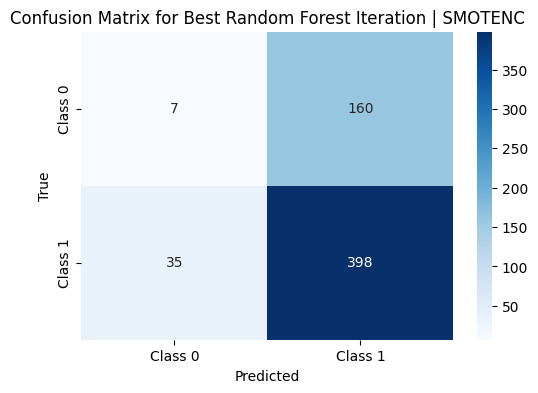


Best Bagging Iteration: Iteration 1 with Accuracy 0.6483


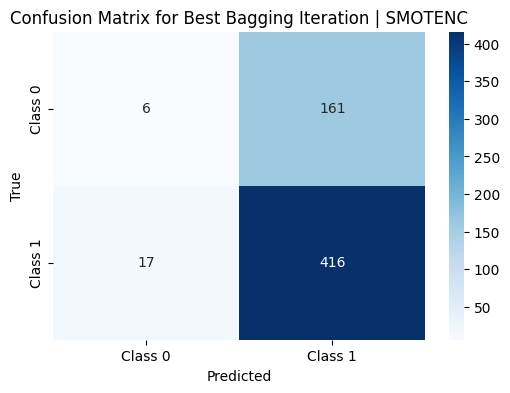


=== Final Summary Random Forest vs Bagging | CTGAN ===
   mean_acc       std_acc  mean_precision  std_precision  mean_recall  \
0  0.675000  2.266233e-16        0.439964   1.133117e-16     0.480542   
1  0.703333  1.133117e-16        0.490920   1.699675e-16     0.498334   

     std_recall   mean_f1        std_f1  mean_roc_auc   std_roc_auc    model  
0  2.266233e-16  0.435107  0.000000e+00      0.485486  5.988200e-06       RF  
1  1.133117e-16  0.443460  1.699675e-16      0.531226  2.266233e-16  Bagging  

=== Random Forest Iteration Results | CTGAN ===
    iter  accuracy  precision    recall        f1   roc_auc
0      1     0.675   0.439964  0.480542  0.435107  0.485486
1      2     0.675   0.439964  0.480542  0.435107  0.485486
2      3     0.675   0.439964  0.480542  0.435107  0.485486
3      4     0.675   0.439964  0.480542  0.435107  0.485486
4      5     0.675   0.439964  0.480542  0.435107  0.485479
5      6     0.675   0.439964  0.480542  0.435107  0.485479
6      7     0.675

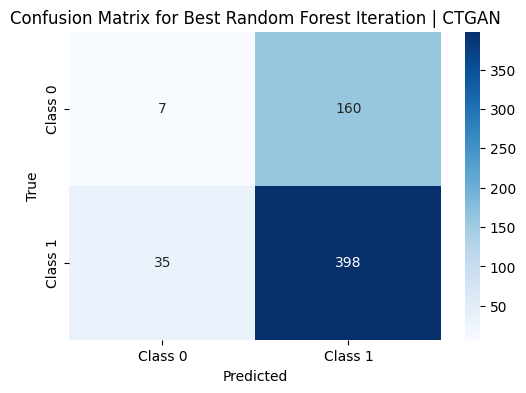


Best Bagging Iteration: Iteration 1 with Accuracy 0.7033


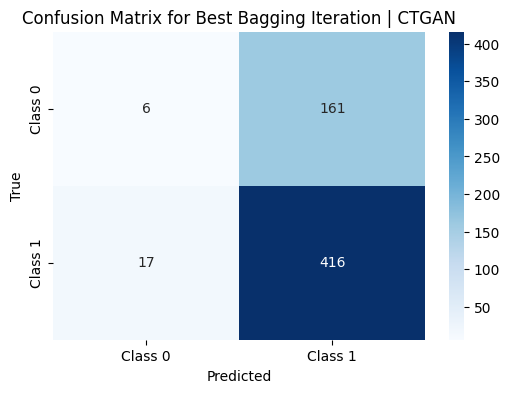

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
import warnings

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42

# Parameter grid untuk RandomizedSearch pada Random Forest
param_dist_rf = {
    'n_estimators': [50, 100, 200, 300],
    'max_features': ['sqrt'],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

# Parameter grid untuk RandomizedSearch pada Bagging
param_dist_bag = {
    'n_estimators': [50, 100, 200, 300],
    'max_samples': [0.5, 0.7, 1.0],
    'max_features': [0.5, 0.7, 1.0],
    'bootstrap': [True, False]
}

# =========================
# TRAINING RANDOM FOREST & BAGGING dengan RandomizedSearchCV
# =========================
print("\n=== Training Random Forest dan Bagging dengan RandomizedSearchCV ===\n")

results_rf = {}
results_bag = {}

# Loop untuk setiap dataset hasil oversampling (misalnya SMOTENC, CTGAN)
for hybrid_name, (X_res, y_res) in resampled_data.items():

    X_res_df = pd.DataFrame(X_res, columns=X_train.columns)

    # Initialize lists to store iteration results for each hybrid_name
    results_rf[hybrid_name] = []
    results_bag[hybrid_name] = []

    # =========================
    # TRAINING RANDOM FOREST dengan RandomizedSearchCV
    # =========================
    rf = RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1)
    random_search_rf = RandomizedSearchCV(estimator=rf, param_distributions=param_dist_rf, n_iter=10, cv=5, random_state=RANDOM_STATE, n_jobs=-1)
    random_search_rf.fit(X_res_df, y_res)

    # Best model Random Forest dari RandomizedSearchCV
    best_rf = random_search_rf.best_estimator_

    for i in range(25):  # 25 percobaan untuk setiap dataset
        # Prediksi
        y_pred_rf = best_rf.predict(X_test_scaled_df)
        y_prob_rf = best_rf.predict_proba(X_test_scaled_df)[:, 1]

        acc_rf = accuracy_score(y_test_int, y_pred_rf)
        precision_rf = precision_score(y_test_int, y_pred_rf, average="macro", zero_division=0)
        recall_rf = recall_score(y_test_int, y_pred_rf, average="macro", zero_division=0)
        f1_rf = f1_score(y_test_int, y_pred_rf, average="macro", zero_division=0)
        roc_auc_rf = roc_auc_score(y_test_int, y_prob_rf)

        results_rf[hybrid_name].append({
            "iter": i + 1,
            "accuracy": acc_rf,
            "precision": precision_rf,
            "recall": recall_rf,
            "f1": f1_rf,
            "roc_auc": roc_auc_rf,
        })

    # =========================
    # TRAINING BAGGING dengan RandomizedSearchCV
    # =========================
    bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE), random_state=RANDOM_STATE)
    random_search_bag = RandomizedSearchCV(estimator=bag, param_distributions=param_dist_bag, n_iter=10, cv=5, random_state=RANDOM_STATE, n_jobs=-1)
    random_search_bag.fit(X_res_df, y_res)

    # Best model Bagging dari RandomizedSearchCV
    best_bag = random_search_bag.best_estimator_

    for i in range(25):  # 25 percobaan untuk setiap dataset
        # Prediksi
        y_pred_bag = best_bag.predict(X_test_scaled_df)
        y_prob_bag = best_bag.predict_proba(X_test_scaled_df)[:, 1]

        acc_bag = accuracy_score(y_test_int, y_pred_bag)
        precision_bag = precision_score(y_test_int, y_pred_bag, average="macro", zero_division=0)
        recall_bag = recall_score(y_test_int, y_pred_bag, average="macro", zero_division=0)
        f1_bag = f1_score(y_test_int, y_pred_bag, average="macro", zero_division=0)
        roc_auc_bag = roc_auc_score(y_test_int, y_prob_bag)

        results_bag[hybrid_name].append({
            "iter": i + 1,
            "accuracy": acc_bag,
            "precision": precision_bag,
            "recall": recall_bag,
            "f1": f1_bag,
            "roc_auc": roc_auc_bag,
        })

# =========================
# FINAL SUMMARY
# =========================

# Fungsi untuk menghasilkan ringkasan (mean dan std) dari hasil
def summarize_results(results):
    df = pd.DataFrame(results)
    summary = {
        "mean_acc": df['accuracy'].mean(),
        "std_acc": df['accuracy'].std(),
        "mean_precision": df['precision'].mean(),
        "std_precision": df['precision'].std(),
        "mean_recall": df['recall'].mean(),
        "std_recall": df['recall'].std(),
        "mean_f1": df['f1'].mean(),
        "std_f1": df['f1'].std(),
        "mean_roc_auc": df['roc_auc'].mean(),
        "std_roc_auc": df['roc_auc'].std(),
    }
    return summary

# Menghasilkan Final Summary untuk setiap dataset oversampling (SMOTENC, CTGAN, dll.)
for hybrid_name in resampled_data.keys():
    rf_summary = summarize_results(results_rf[hybrid_name])
    rf_summary['model'] = 'RF'
    bagging_summary = summarize_results(results_bag[hybrid_name])
    bagging_summary['model'] = 'Bagging'

    # Gabungkan Summary Final
    final_summary = pd.DataFrame([rf_summary, bagging_summary])

    # Tampilkan hasil final summary untuk setiap dataset
    print(f"\n=== Final Summary Random Forest vs Bagging | {hybrid_name} ===")
    print(final_summary)

    # Simpan hasil final summary dengan menyertakan hybrid_name dalam penamaan file
    final_summary.to_csv(
        f"{OUTPUT_DIR}/final_summary_rf_vs_bagging_with_randomized_search_{hybrid_name}.csv",
        index=False
    )

    # =========================
    # Display Results for Each Iteration
    # =========================
    # Display the results for Random Forest iteratively
    df_rf = pd.DataFrame(results_rf[hybrid_name])
    print(f"\n=== Random Forest Iteration Results | {hybrid_name} ===")
    print(df_rf)

    # Simpan hasil iterasi Random Forest untuk setiap dataset
    df_rf.to_csv(f"{OUTPUT_DIR}/rf_iteration_results_with_randomized_search_{hybrid_name}.csv", index=False)

    # Display the results for Bagging iteratively
    df_bag = pd.DataFrame(results_bag[hybrid_name])
    print(f"\n=== Bagging Iteration Results | {hybrid_name} ===")
    print(df_bag)

    # Simpan hasil iterasi Bagging untuk setiap dataset
    df_bag.to_csv(f"{OUTPUT_DIR}/bagging_iteration_results_with_randomized_search_{hybrid_name}.csv", index=False)

    # Show Confusion Matrix for the best iteration based on accuracy
    best_rf_result = results_rf[hybrid_name][0]
    print(f"\nBest Random Forest Iteration: Iteration {best_rf_result['iter']} with Accuracy {best_rf_result['accuracy']:.4f}")

    # Confusion Matrix for Random Forest
    cm_rf = confusion_matrix(y_test_int, y_pred_rf)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues", xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
    plt.title(f'Confusion Matrix for Best Random Forest Iteration | {hybrid_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

    # Show Confusion Matrix for Bagging
    best_bag_result = results_bag[hybrid_name][0]
    print(f"\nBest Bagging Iteration: Iteration {best_bag_result['iter']} with Accuracy {best_bag_result['accuracy']:.4f}")

    # Confusion Matrix for Bagging
    cm_bag = confusion_matrix(y_test_int, y_pred_bag)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm_bag, annot=True, fmt="d", cmap="Blues", xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
    plt.title(f'Confusion Matrix for Best Bagging Iteration | {hybrid_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()


=== Feature Importance RSCV Random Forest | CTGAN ===



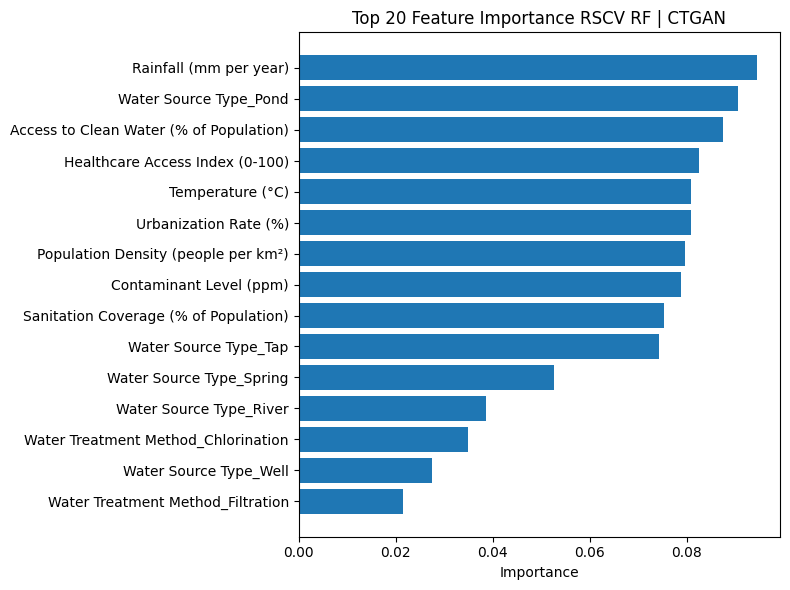

In [ ]:
import matplotlib.pyplot as plt

# =========================
# FEATURE IMPORTANCE VISUAL
# =========================
print(f"\n=== Feature Importance RSCV Random Forest | {hybrid_name} ===\n")

rscv_rf_full = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ),
    param_distributions=param_dist_rf,
    n_iter=15,
    cv=3,
    scoring="roc_auc",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0
)

rscv_rf_full.fit(X_res_df, y_res)
best_rf_full = rscv_rf_full.best_estimator_

importances = best_rf_full.feature_importances_
feature_names = X_res_df.columns

fi_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

fi_df.to_csv(
    f"{OUTPUT_DIR}/feature_importance_random_rf_{hybrid_name}.csv",
    index=False
)

top_k = 20
fi_top = fi_df.head(top_k)

plt.figure(figsize=(8, 6))
plt.barh(fi_top["feature"], fi_top["importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title(f"Top {top_k} Feature Importance RSCV RF | {hybrid_name}")
plt.tight_layout()
plt.show()

### **GRAFIK ROC_AUC, PRESISI_RECALL, KALIBRASI**

RF no RSCV

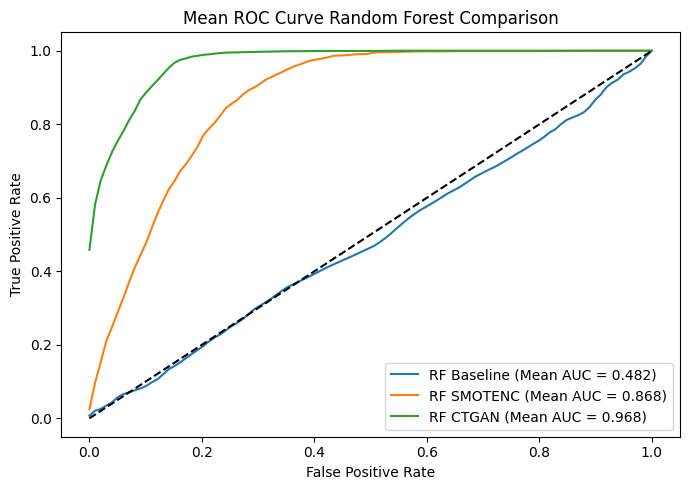

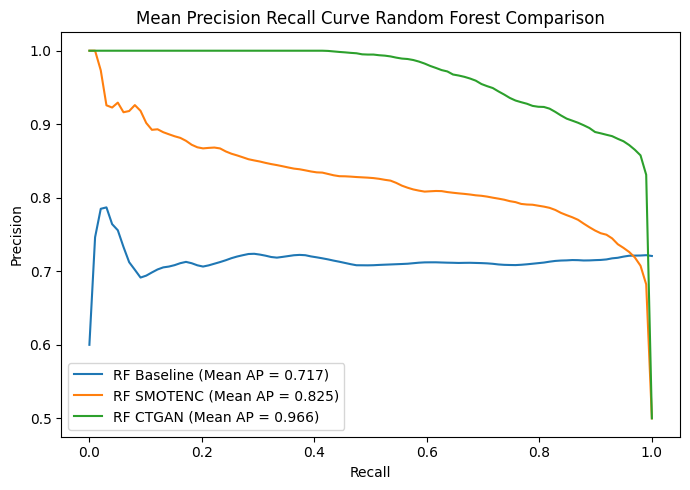

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
N_SPLITS = 5

# =========================
# DATASET PERBANDINGAN RF DAN BAGGING
# =========================
datasets = {
    "RF Baseline": (X_train.values, y_train.values),
    "RF SMOTENC": resampled_data["SMOTENC"],
    "RF CTGAN": resampled_data["CTGAN"]
}

# =========================
# 1. ROC CURVE
# =========================
plt.figure(figsize=(7, 5))

for label, (X_res, y_res) in datasets.items():
    X_res = np.array(X_res)
    y_res = np.array(y_res).astype(int)

    imputer = SimpleImputer(strategy="mean")
    X_res = imputer.fit_transform(X_res)

    kf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    mean_fpr = np.linspace(0, 1, 100)
    tprs_rf = []
    tprs_bag = []
    aucs_rf = []
    aucs_bag = []

    for train_idx, val_idx in kf.split(X_res, y_res):
        X_train_fold = X_res[train_idx]
        X_val_fold = X_res[val_idx]
        y_train_fold = y_res[train_idx]
        y_val_fold = y_res[val_idx]

        # Random Forest
        rf = RandomForestClassifier(
            random_state=RANDOM_STATE,
            class_weight="balanced",
            n_jobs=-1
        )
        rf.fit(X_train_fold, y_train_fold)
        y_prob_rf = rf.predict_proba(X_val_fold)[:, 1]
        fpr_rf, tpr_rf, _ = roc_curve(y_val_fold, y_prob_rf)
        tprs_rf.append(np.interp(mean_fpr, fpr_rf, tpr_rf))
        aucs_rf.append(auc(fpr_rf, tpr_rf))

        # Bagging
        bag = BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
            n_estimators=100,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        bag.fit(X_train_fold, y_train_fold)
        y_prob_bag = bag.predict_proba(X_val_fold)[:, 1]
        fpr_bag, tpr_bag, _ = roc_curve(y_val_fold, y_prob_bag)
        tprs_bag.append(np.interp(mean_fpr, fpr_bag, tpr_bag))
        aucs_bag.append(auc(fpr_bag, tpr_bag))

    mean_tpr_rf = np.mean(tprs_rf, axis=0)
    mean_auc_rf = np.mean(aucs_rf)
    mean_tpr_bag = np.mean(tprs_bag, axis=0)
    mean_auc_bag = np.mean(aucs_bag)

    plt.plot(
        mean_fpr,
        mean_tpr_rf,
        label=f"{label} RF (Mean AUC = {mean_auc_rf:.3f})"
    )
    plt.plot(
        mean_fpr,
        mean_tpr_bag,
        label=f"{label} Bagging (Mean AUC = {mean_auc_bag:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--")
plt.title("Mean ROC Curve Random Forest vs Bagging Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/roc_auc_rf_vs_bagging.png")
plt.show()

# =========================
# 2. PRECISION RECALL CURVE
# =========================
plt.figure(figsize=(7, 5))

for label, (X_res, y_res) in datasets.items():
    X_res = np.array(X_res)
    y_res = np.array(y_res).astype(int)

    imputer = SimpleImputer(strategy="mean")
    X_res = imputer.fit_transform(X_res)

    kf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    mean_recall = np.linspace(0, 1, 100)
    precisions_rf = []
    precisions_bag = []
    aps_rf = []
    aps_bag = []

    for train_idx, val_idx in kf.split(X_res, y_res):
        X_train_fold = X_res[train_idx]
        X_val_fold = X_res[val_idx]
        y_train_fold = y_res[train_idx]
        y_val_fold = y_res[val_idx]

        # Random Forest
        rf = RandomForestClassifier(
            random_state=RANDOM_STATE,
            class_weight="balanced",
            n_jobs=-1
        )
        rf.fit(X_train_fold, y_train_fold)
        y_prob_rf = rf.predict_proba(X_val_fold)[:, 1]
        precision_rf, recall_rf, _ = precision_recall_curve(y_val_fold, y_prob_rf)
        aps_rf.append(average_precision_score(y_val_fold, y_prob_rf))
        interp_precision_rf = np.interp(mean_recall, recall_rf[::-1], precision_rf[::-1])
        precisions_rf.append(interp_precision_rf)

        # Bagging
        bag = BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
            n_estimators=100,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
        bag.fit(X_train_fold, y_train_fold)
        y_prob_bag = bag.predict_proba(X_val_fold)[:, 1]
        precision_bag, recall_bag, _ = precision_recall_curve(y_val_fold, y_prob_bag)
        aps_bag.append(average_precision_score(y_val_fold, y_prob_bag))
        interp_precision_bag = np.interp(mean_recall, recall_bag[::-1], precision_bag[::-1])
        precisions_bag.append(interp_precision_bag)

    mean_precision_rf = np.mean(precisions_rf, axis=0)
    mean_ap_rf = np.mean(aps_rf)
    mean_precision_bag = np.mean(precisions_bag, axis=0)
    mean_ap_bag = np.mean(aps_bag)

    plt.plot(
        mean_recall,
        mean_precision_rf,
        label=f"{label} RF (Mean AP = {mean_ap_rf:.3f})"
    )
    plt.plot(
        mean_recall,
        mean_precision_bag,
        label=f"{label} Bagging (Mean AP = {mean_ap_bag:.3f})"
    )

plt.title("Mean Precision Recall Curve Random Forest vs Bagging Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/pr_curve_rf_vs_bagging.png")
plt.show()

Bagging no RSCV

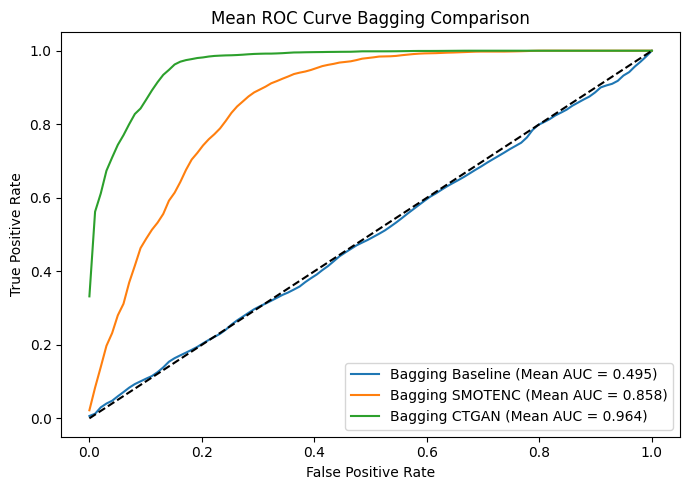

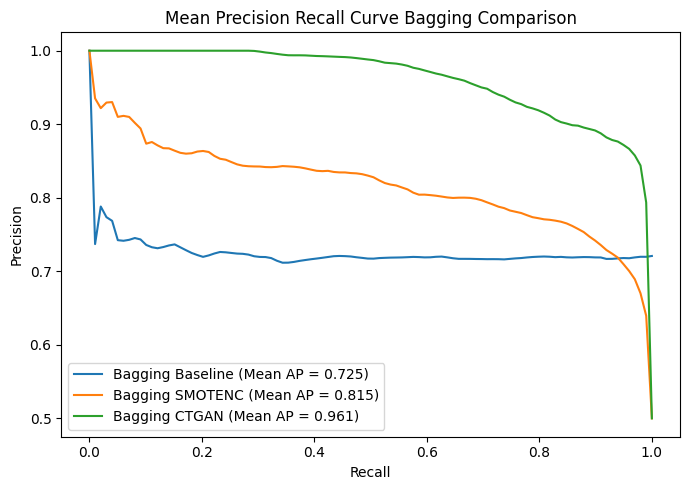

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
N_SPLITS = 5

# =========================
# DATASET PERBANDINGAN BAGGING
# =========================
bagging_datasets = {
    "Bagging Baseline": (X_train.values, y_train.values),
    "Bagging SMOTENC": resampled_data["SMOTENC"],
    "Bagging CTGAN": resampled_data["CTGAN"]
}

# =========================
# 1. ROC CURVE
# =========================
plt.figure(figsize=(7, 5))

for label, (X_res, y_res) in bagging_datasets.items():
    X_res = np.array(X_res)
    y_res = np.array(y_res).astype(int)

    imputer = SimpleImputer(strategy="mean")
    X_res = imputer.fit_transform(X_res)

    kf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    mean_fpr = np.linspace(0, 1, 100)
    tprs = []
    aucs = []

    for train_idx, val_idx in kf.split(X_res, y_res):
        X_train_fold = X_res[train_idx]
        X_val_fold = X_res[val_idx]
        y_train_fold = y_res[train_idx]
        y_val_fold = y_res[val_idx]

        bag = BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
            n_estimators=100,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

        bag.fit(X_train_fold, y_train_fold)
        y_prob = bag.predict_proba(X_val_fold)[:, 1]

        fpr, tpr, _ = roc_curve(y_val_fold, y_prob)
        tprs.append(np.interp(mean_fpr, fpr, tpr))
        aucs.append(auc(fpr, tpr))

    mean_tpr = np.mean(tprs, axis=0)
    mean_auc = np.mean(aucs)

    plt.plot(
        mean_fpr,
        mean_tpr,
        label=f"{label} (Mean AUC = {mean_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--")
plt.title("Mean ROC Curve Bagging Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/roc_auc_bagging_baseline_smotenc_ctgan.png")
plt.show()

# =========================
# 2. PRECISION RECALL CURVE
# =========================
plt.figure(figsize=(7, 5))

for label, (X_res, y_res) in bagging_datasets.items():
    X_res = np.array(X_res)
    y_res = np.array(y_res).astype(int)

    imputer = SimpleImputer(strategy="mean")
    X_res = imputer.fit_transform(X_res)

    kf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    mean_recall = np.linspace(0, 1, 100)
    precisions = []
    aps = []

    for train_idx, val_idx in kf.split(X_res, y_res):
        X_train_fold = X_res[train_idx]
        X_val_fold = X_res[val_idx]
        y_train_fold = y_res[train_idx]
        y_val_fold = y_res[val_idx]

        bag = BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
            n_estimators=100,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

        bag.fit(X_train_fold, y_train_fold)
        y_prob = bag.predict_proba(X_val_fold)[:, 1]

        precision, recall, _ = precision_recall_curve(y_val_fold, y_prob)
        aps.append(average_precision_score(y_val_fold, y_prob))

        interp_precision = np.interp(
            mean_recall,
            recall[::-1],
            precision[::-1]
        )
        precisions.append(interp_precision)

    mean_precision = np.mean(precisions, axis=0)
    mean_ap = np.mean(aps)

    plt.plot(
        mean_recall,
        mean_precision,
        label=f"{label} (Mean AP = {mean_ap:.3f})"
    )

plt.title("Mean Precision Recall Curve Bagging Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/pr_curve_bagging_baseline_smotenc_ctgan.png")
plt.show()


RSCV RF

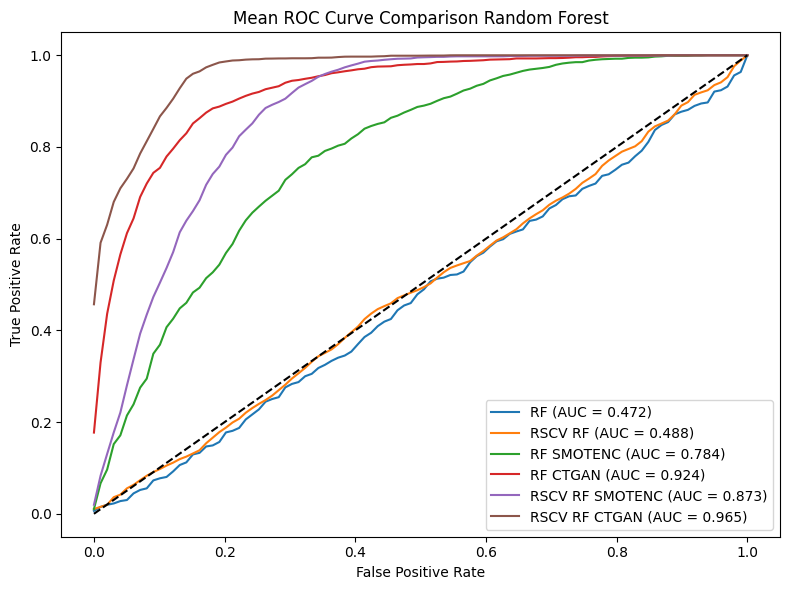

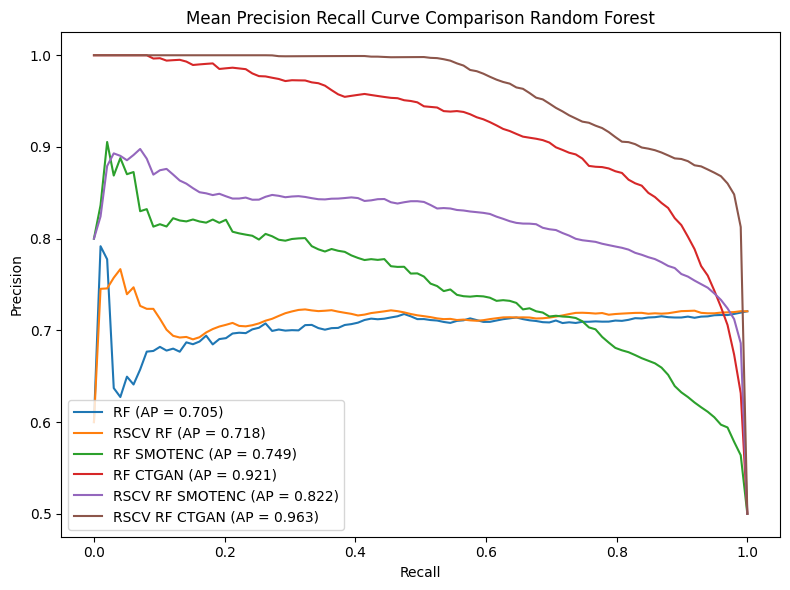

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
N_SPLITS = 5

rf_configs = {
    "RF": {
        "Xy": (X_train.values, y_train.values),
        "rscv": True
    },
    "RSCV RF": {
        "Xy": (X_train.values, y_train.values),
        "rscv": False
    },
    "RF SMOTENC": {
        "Xy": resampled_data["SMOTENC"],
        "rscv": True
    },
    "RF CTGAN": {
        "Xy": resampled_data["CTGAN"],
        "rscv": True
    },
    "RSCV RF SMOTENC": {
        "Xy": resampled_data["SMOTENC"],
        "rscv": False
    },
    "RSCV RF CTGAN": {
        "Xy": resampled_data["CTGAN"],
        "rscv": False
    }
}

def build_rf(use_rscv, seed):
    if use_rscv:
        return RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features="sqrt",
            bootstrap=True,
            class_weight="balanced",
            random_state=seed,
            n_jobs=-1
        )
    else:
        return RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=seed,
            n_jobs=-1
        )

# =========================
# ROC CURVE
# =========================
plt.figure(figsize=(8, 6))

for label, cfg in rf_configs.items():
    X_res, y_res = cfg["Xy"]
    use_rscv = cfg["rscv"]

    X_res = np.asarray(X_res)
    y_res = np.asarray(y_res).astype(int)

    X_res = SimpleImputer(strategy="mean").fit_transform(X_res)

    kf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    mean_fpr = np.linspace(0, 1, 100)
    tprs = []
    aucs = []

    for fold_id, (tr, va) in enumerate(kf.split(X_res, y_res)):
        rf = build_rf(use_rscv, RANDOM_STATE + fold_id)

        rf.fit(X_res[tr], y_res[tr])
        y_prob = rf.predict_proba(X_res[va])[:, 1]

        fpr, tpr, _ = roc_curve(y_res[va], y_prob)
        tprs.append(np.interp(mean_fpr, fpr, tpr))
        aucs.append(auc(fpr, tpr))

    plt.plot(
        mean_fpr,
        np.mean(tprs, axis=0),
        label=f"{label} (AUC = {np.mean(aucs):.3f})"
    )

plt.plot([0, 1], [0, 1], "k--")
plt.title("Mean ROC Curve Comparison Random Forest")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/roc_auc_rf_full_comparison.png")
plt.show()

# =========================
# PRECISION RECALL CURVE
# =========================
plt.figure(figsize=(8, 6))

for label, cfg in rf_configs.items():
    X_res, y_res = cfg["Xy"]
    use_rscv = cfg["rscv"]

    X_res = np.asarray(X_res)
    y_res = np.asarray(y_res).astype(int)

    X_res = SimpleImputer(strategy="mean").fit_transform(X_res)

    kf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    mean_recall = np.linspace(0, 1, 100)
    precisions = []
    aps = []

    for fold_id, (tr, va) in enumerate(kf.split(X_res, y_res)):
        rf = build_rf(use_rscv, RANDOM_STATE + fold_id)

        rf.fit(X_res[tr], y_res[tr])
        y_prob = rf.predict_proba(X_res[va])[:, 1]

        p, r, _ = precision_recall_curve(y_res[va], y_prob)
        aps.append(average_precision_score(y_res[va], y_prob))
        precisions.append(np.interp(mean_recall, r[::-1], p[::-1]))

    plt.plot(
        mean_recall,
        np.mean(precisions, axis=0),
        label=f"{label} (AP = {np.mean(aps):.3f})"
    )

plt.title("Mean Precision Recall Curve Comparison Random Forest")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/pr_curve_rf_full_comparison.png")
plt.show()


RSCV Bagging

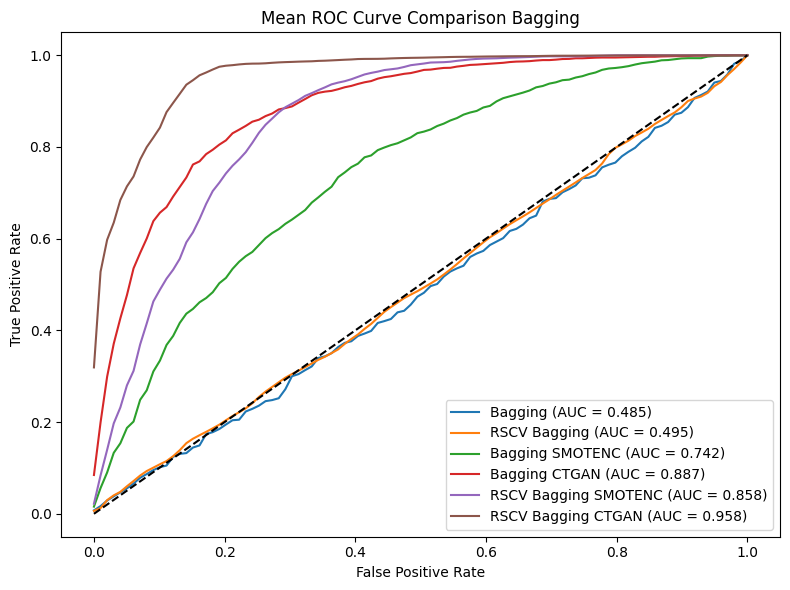

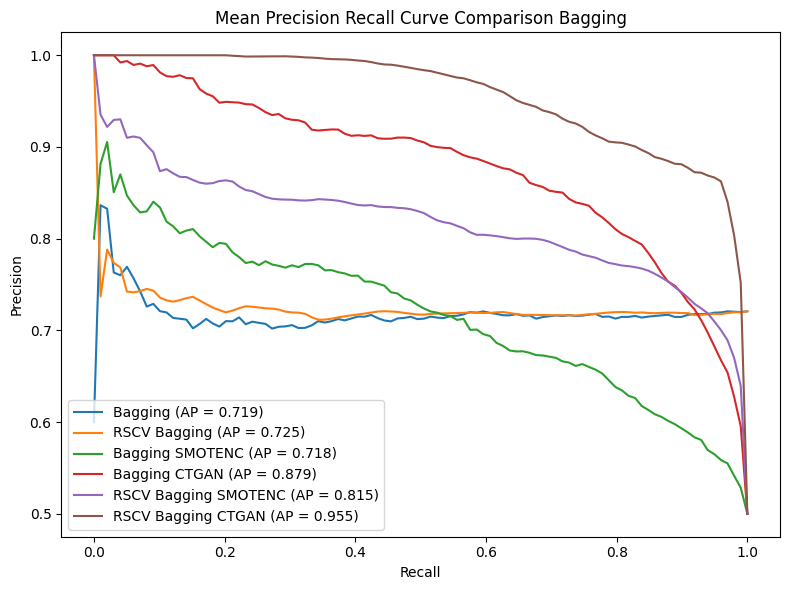

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
N_SPLITS = 5

# =========================
# DATASET DAN MODEL BAGGING
# =========================
bag_configs = {
    "Bagging": {
        "Xy": (X_train.values, y_train.values),
        "rscv": True
    },
    "RSCV Bagging": {
        "Xy": (X_train.values, y_train.values),
        "rscv": False
    },
    "Bagging SMOTENC": {
        "Xy": resampled_data["SMOTENC"],
        "rscv": True
    },
    "Bagging CTGAN": {
        "Xy": resampled_data["CTGAN"],
        "rscv": True
    },
    "RSCV Bagging SMOTENC": {
        "Xy": resampled_data["SMOTENC"],
        "rscv": False
    },
    "RSCV Bagging CTGAN": {
        "Xy": resampled_data["CTGAN"],
        "rscv": False
    }
}

# =========================
# 1. ROC CURVE
# =========================
plt.figure(figsize=(8, 6))

for label, cfg in bag_configs.items():
    X_res, y_res = cfg["Xy"]
    use_rscv = cfg["rscv"]

    X_res = np.array(X_res)
    y_res = np.array(y_res).astype(int)

    imputer = SimpleImputer(strategy="mean")
    X_res = imputer.fit_transform(X_res)

    kf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    mean_fpr = np.linspace(0, 1, 100)
    tprs = []
    aucs = []

    for train_idx, val_idx in kf.split(X_res, y_res):
        X_train_fold = X_res[train_idx]
        X_val_fold = X_res[val_idx]
        y_train_fold = y_res[train_idx]
        y_val_fold = y_res[val_idx]

        if use_rscv:
            bag = BaggingClassifier(
                estimator=DecisionTreeClassifier(
                    max_depth=8,
                    min_samples_split=4,
                    min_samples_leaf=2,
                    random_state=RANDOM_STATE
                ),
                n_estimators=200,
                max_samples=0.7,
                max_features=0.7,
                bootstrap=True,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        else:
            bag = BaggingClassifier(
                estimator=DecisionTreeClassifier(
                    random_state=RANDOM_STATE
                ),
                n_estimators=100,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )

        bag.fit(X_train_fold, y_train_fold)
        y_prob = bag.predict_proba(X_val_fold)[:, 1]

        fpr, tpr, _ = roc_curve(y_val_fold, y_prob)
        tprs.append(np.interp(mean_fpr, fpr, tpr))
        aucs.append(auc(fpr, tpr))

    mean_tpr = np.mean(tprs, axis=0)
    mean_auc = np.mean(aucs)

    plt.plot(
        mean_fpr,
        mean_tpr,
        label=f"{label} (AUC = {mean_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--")
plt.title("Mean ROC Curve Comparison Bagging")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/roc_auc_bagging_full_comparison.png")
plt.show()

# =========================
# 2. PRECISION RECALL CURVE
# =========================
plt.figure(figsize=(8, 6))

for label, cfg in bag_configs.items():
    X_res, y_res = cfg["Xy"]
    use_rscv = cfg["rscv"]

    X_res = np.array(X_res)
    y_res = np.array(y_res).astype(int)

    imputer = SimpleImputer(strategy="mean")
    X_res = imputer.fit_transform(X_res)

    kf = StratifiedKFold(
        n_splits=N_SPLITS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    mean_recall = np.linspace(0, 1, 100)
    precisions = []
    aps = []

    for train_idx, val_idx in kf.split(X_res, y_res):
        X_train_fold = X_res[train_idx]
        X_val_fold = X_res[val_idx]
        y_train_fold = y_res[train_idx]
        y_val_fold = y_res[val_idx]

        if use_rscv:
            bag = BaggingClassifier(
                estimator=DecisionTreeClassifier(
                    max_depth=8,
                    min_samples_split=4,
                    min_samples_leaf=2,
                    random_state=RANDOM_STATE
                ),
                n_estimators=200,
                max_samples=0.7,
                max_features=0.7,
                bootstrap=True,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        else:
            bag = BaggingClassifier(
                estimator=DecisionTreeClassifier(
                    random_state=RANDOM_STATE
                ),
                n_estimators=100,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )

        bag.fit(X_train_fold, y_train_fold)
        y_prob = bag.predict_proba(X_val_fold)[:, 1]

        precision, recall, _ = precision_recall_curve(y_val_fold, y_prob)
        aps.append(average_precision_score(y_val_fold, y_prob))

        interp_precision = np.interp(
            mean_recall,
            recall[::-1],
            precision[::-1]
        )
        precisions.append(interp_precision)

    mean_precision = np.mean(precisions, axis=0)
    mean_ap = np.mean(aps)

    plt.plot(
        mean_recall,
        mean_precision,
        label=f"{label} (AP = {mean_ap:.3f})"
    )

plt.title("Mean Precision Recall Curve Comparison Bagging")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/pr_curve_bagging_full_comparison.png")
plt.show()


**# UJI STATISTIK**

In [ ]:
import pandas as pd
import itertools
from scipy.stats import ttest_rel, t

# =========================
# SETUP
# =========================

OUTPUT_DIR = "output"   # sesuaikan jika berbeda

model_files = {
    "rf_plain_no_threshold": "random_rf_plain_no_threshold.csv",
    "bayes_rf_plain_no_threshold": "rf_plain_no_threshold.csv",
    "rf_kfold_5fold_25iter_SMOTENC": "random_rf_kfold_5fold_25iter_SMOTENC.csv",
    "rf_kfold_5fold_25iter_CTGAN": "random_rf_kfold_5fold_25iter_CTGAN.csv",
    "bayes_rf_kfold_5fold_25iter_SMOTENC": "rf_train_test_split_25iter_SMOTENC.csv",
    "bayes_rf_kfold_5fold_25iter_CTGAN": "rf_train_test_split_25iter_CTGAN.csv"
}

metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

alpha = 0.05

# =========================
# LOAD DATA
# =========================

model_data = {}

for name, file in model_files.items():
    df = pd.read_csv(f"{OUTPUT_DIR}/{file}")
    model_data[name] = df

n = len(next(iter(model_data.values())))
dfree = n - 1
t_critical = t.ppf(1 - alpha/2, dfree)

print("Jumlah iterasi:", n)
print("Degree of freedom:", dfree)
print("Alpha:", alpha)
print("T critical (two-tailed):", t_critical)
print("\n============================\n")

# =========================
# PAIRED T TEST
# =========================

results = []

model_pairs = list(itertools.combinations(model_data.keys(), 2))

for model1, model2 in model_pairs:
    df1 = model_data[model1]
    df2 = model_data[model2]

    for metric in metrics:

        t_stat, p_value = ttest_rel(df1[metric], df2[metric])

        significant = "Significant" if p_value < alpha else "Not Significant"

        results.append({
            "Model_1": model1,
            "Model_2": model2,
            "Metric": metric,
            "t_value": t_stat,
            "p_value": p_value,
            "alpha": alpha,
            "t_critical": t_critical,
            "Significance": significant
        })

results_df = pd.DataFrame(results)

print(results_df)

results_df.to_csv(
    f"{OUTPUT_DIR}/paired_ttest_all_models.csv",
    index=False
)


Jumlah iterasi: 25
Degree of freedom: 24
Alpha: 0.05
T critical (two-tailed): 2.0638985616280205


                                Model_1                            Model_2  \
0                 rf_plain_no_threshold        bayes_rf_plain_no_threshold   
1                 rf_plain_no_threshold        bayes_rf_plain_no_threshold   
2                 rf_plain_no_threshold        bayes_rf_plain_no_threshold   
3                 rf_plain_no_threshold        bayes_rf_plain_no_threshold   
4                 rf_plain_no_threshold        bayes_rf_plain_no_threshold   
..                                  ...                                ...   
70  bayes_rf_kfold_5fold_25iter_SMOTENC  bayes_rf_kfold_5fold_25iter_CTGAN   
71  bayes_rf_kfold_5fold_25iter_SMOTENC  bayes_rf_kfold_5fold_25iter_CTGAN   
72  bayes_rf_kfold_5fold_25iter_SMOTENC  bayes_rf_kfold_5fold_25iter_CTGAN   
73  bayes_rf_kfold_5fold_25iter_SMOTENC  bayes_rf_kfold_5fold_25iter_CTGAN   
74  bayes_rf_kfold_5fold_25iter_SMOTENC  ba

Model 1: RF_Baseline
Model 2: RF_SMOTENC
Metric : accuracy
t value: -13.236810089938503
p value: 1.5982531008440338e-12
t critical: 2.0638985616280205


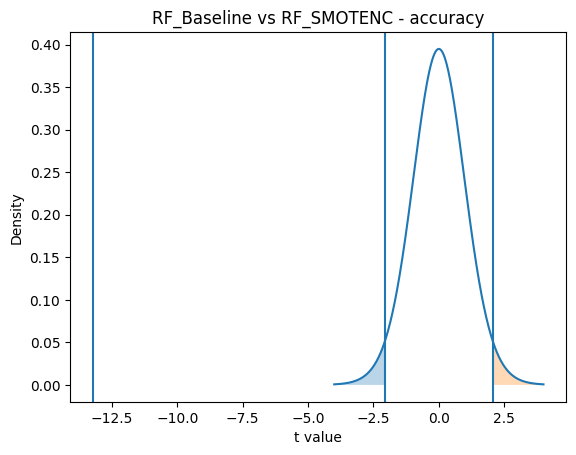

Model 1: RF_Baseline
Model 2: RF_SMOTENC
Metric : precision
t value: -54.17091390116764
p value: 1.314139224089798e-26
t critical: 2.0638985616280205


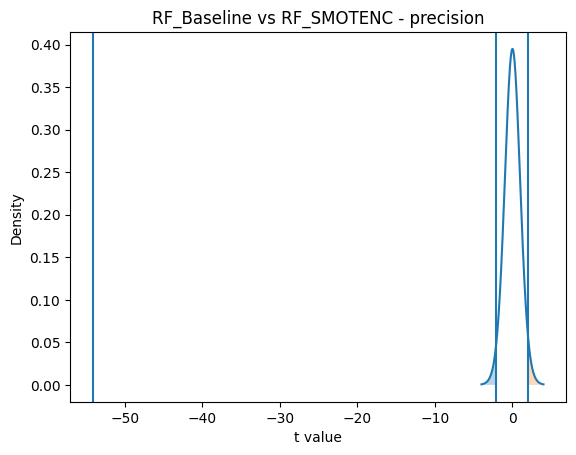

Model 1: RF_Baseline
Model 2: RF_SMOTENC
Metric : recall
t value: -51.77960081063415
p value: 3.8492884206257564e-26
t critical: 2.0638985616280205


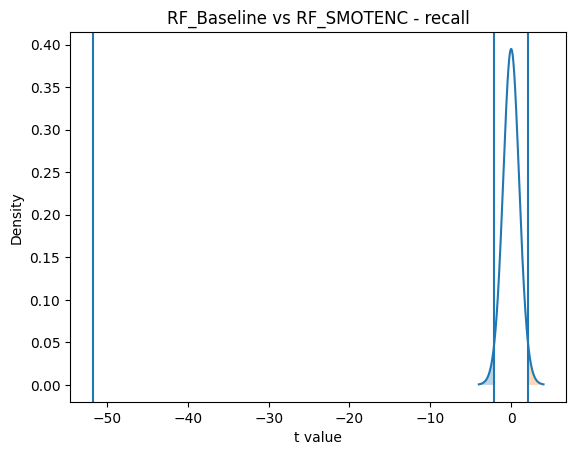

Model 1: RF_Baseline
Model 2: RF_SMOTENC
Metric : f1
t value: -57.39119804004022
p value: 3.320307759813981e-27
t critical: 2.0638985616280205


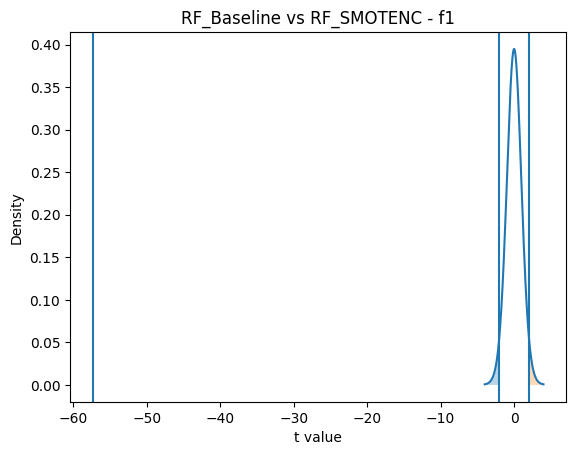

Model 1: RF_Baseline
Model 2: RF_SMOTENC
Metric : roc_auc
t value: -62.16131150532826
p value: 4.946911475754785e-28
t critical: 2.0638985616280205


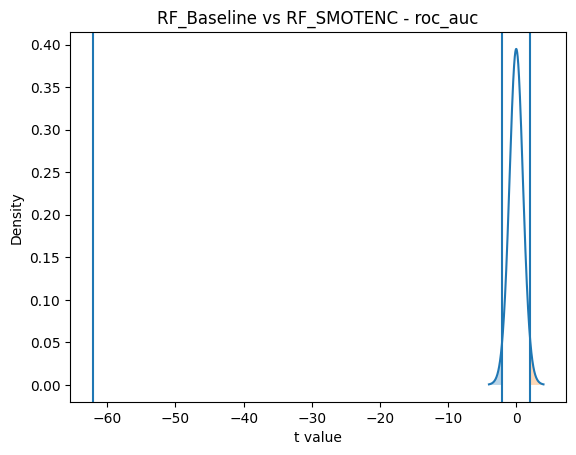

Model 1: RF_Baseline
Model 2: RF_CTGAN
Metric : accuracy
t value: -24.340500255642947
p value: 1.990384601275048e-18
t critical: 2.0638985616280205


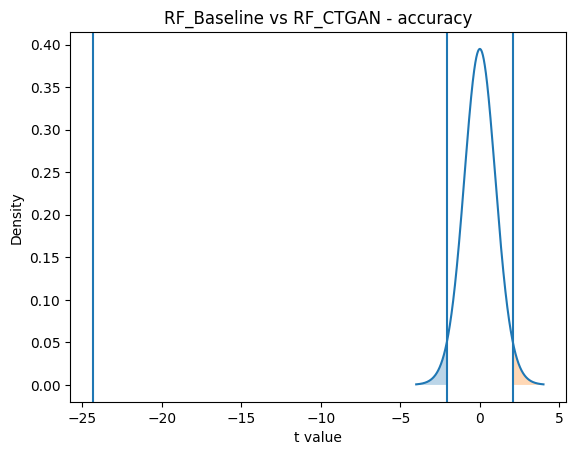

Model 1: RF_Baseline
Model 2: RF_CTGAN
Metric : precision
t value: -107.31490045712893
p value: 1.0557813316828862e-33
t critical: 2.0638985616280205


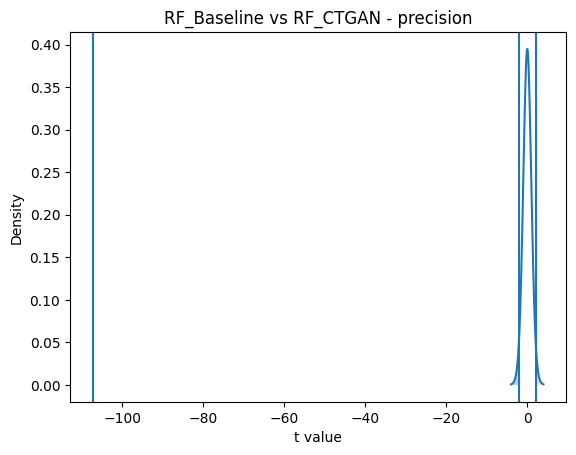

Model 1: RF_Baseline
Model 2: RF_CTGAN
Metric : recall
t value: -95.77771013746542
p value: 1.6084466825250577e-32
t critical: 2.0638985616280205


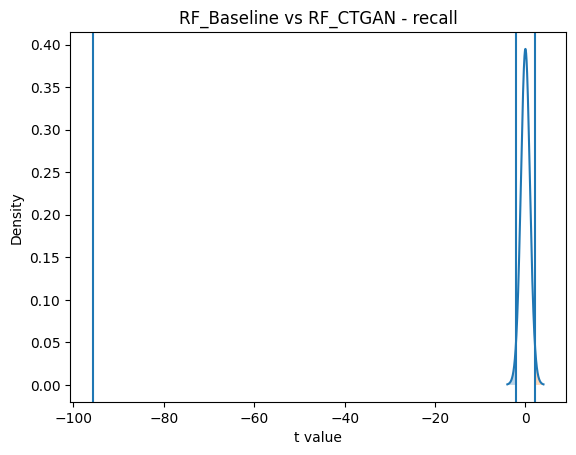

Model 1: RF_Baseline
Model 2: RF_CTGAN
Metric : f1
t value: -94.10874716491078
p value: 2.4499982121017522e-32
t critical: 2.0638985616280205


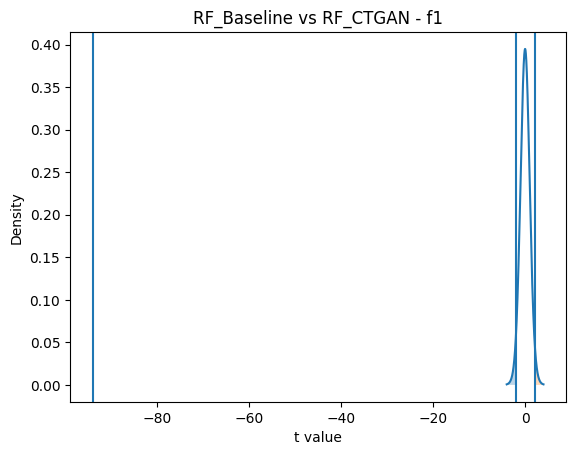

Model 1: RF_Baseline
Model 2: RF_CTGAN
Metric : roc_auc
t value: -127.76283125941153
p value: 1.617244731937606e-35
t critical: 2.0638985616280205


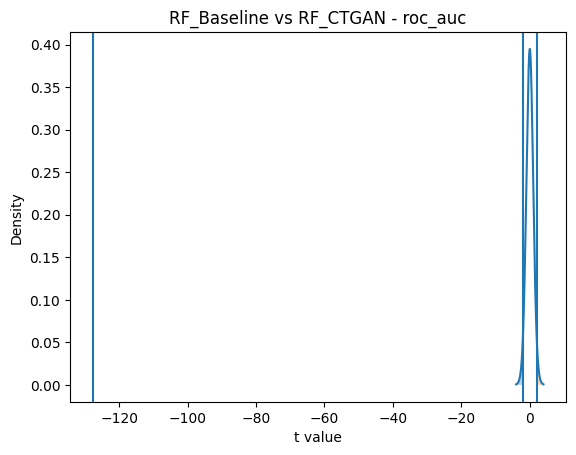

Model 1: RF_Baseline
Model 2: RSCV_RF_Baseline
Metric : accuracy
t value: -11.904660835977209
p value: 1.4740145111143042e-11
t critical: 2.0638985616280205


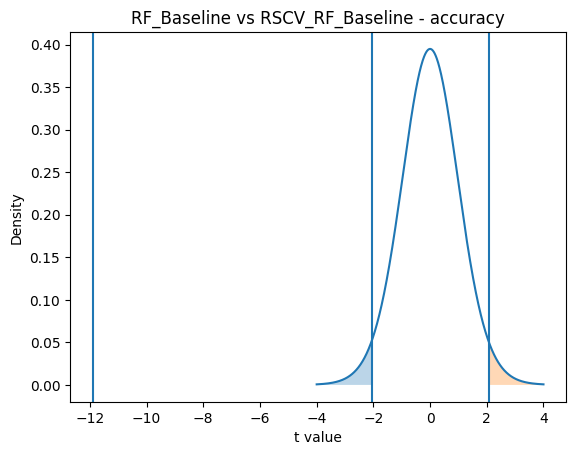

Model 1: RF_Baseline
Model 2: RSCV_RF_Baseline
Metric : precision
t value: 1.006048643687119
p value: 0.3244282992066204
t critical: 2.0638985616280205


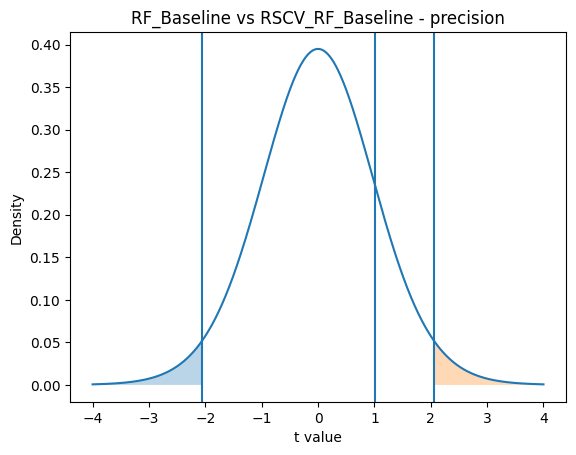

Model 1: RF_Baseline
Model 2: RSCV_RF_Baseline
Metric : recall
t value: 2.361929538613797
p value: 0.02663290472585612
t critical: 2.0638985616280205


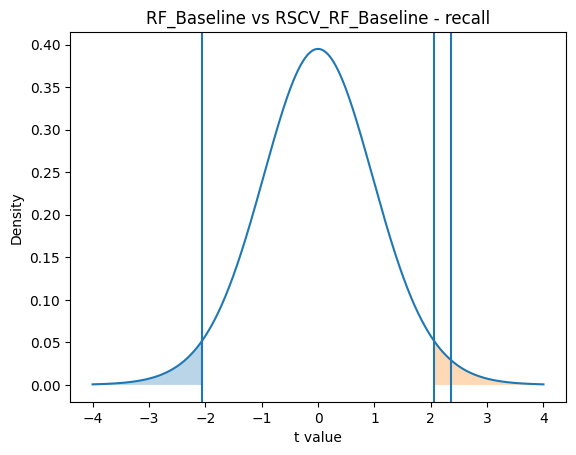

Model 1: RF_Baseline
Model 2: RSCV_RF_Baseline
Metric : f1
t value: 22.951096700022145
p value: 7.714054585227784e-18
t critical: 2.0638985616280205


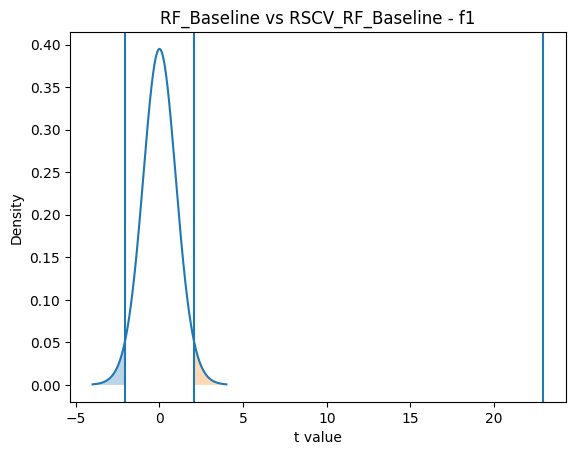

Model 1: RF_Baseline
Model 2: RSCV_RF_Baseline
Metric : roc_auc
t value: 1.0932619754502053
p value: 0.28513119781986185
t critical: 2.0638985616280205


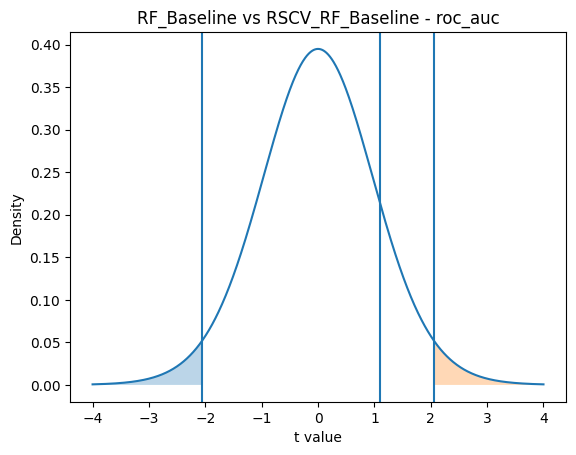

Model 1: RF_Baseline
Model 2: RSCV_RF_SMOTENC
Metric : accuracy
t value: -15.958356314137333
p value: 2.7975332974944486e-14
t critical: 2.0638985616280205


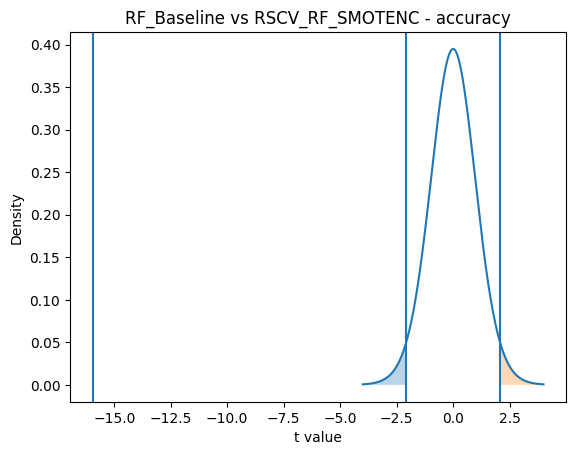

Model 1: RF_Baseline
Model 2: RSCV_RF_SMOTENC
Metric : precision
t value: -70.78283932247547
p value: 2.226528070302861e-29
t critical: 2.0638985616280205


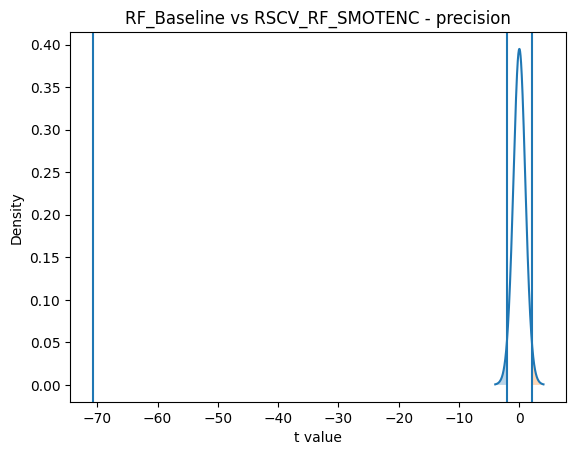

Model 1: RF_Baseline
Model 2: RSCV_RF_SMOTENC
Metric : recall
t value: -71.53087076668562
p value: 1.7320182785454858e-29
t critical: 2.0638985616280205


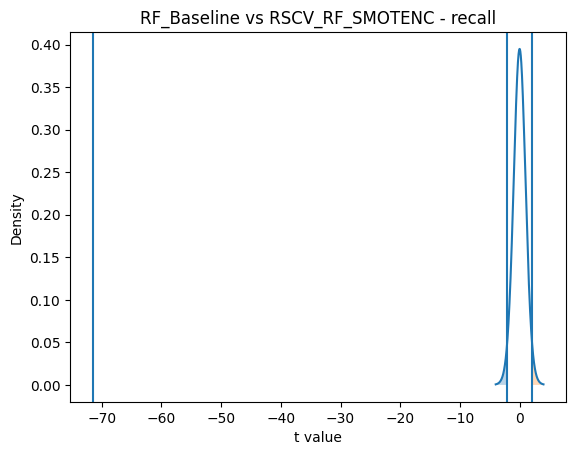

Model 1: RF_Baseline
Model 2: RSCV_RF_SMOTENC
Metric : f1
t value: -61.82685949564664
p value: 5.62639404797268e-28
t critical: 2.0638985616280205


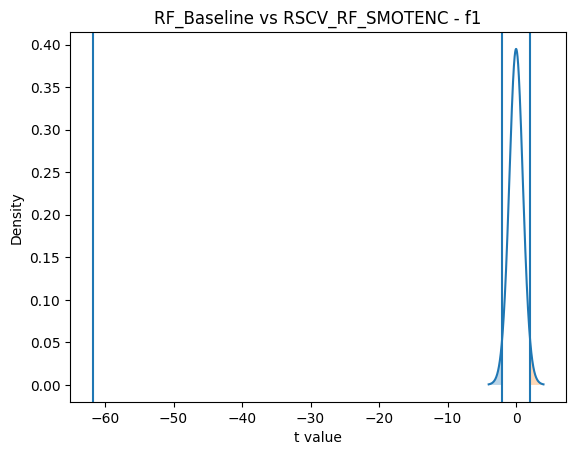

Model 1: RF_Baseline
Model 2: RSCV_RF_SMOTENC
Metric : roc_auc
t value: -112.21330796481432
p value: 3.624431675572771e-34
t critical: 2.0638985616280205


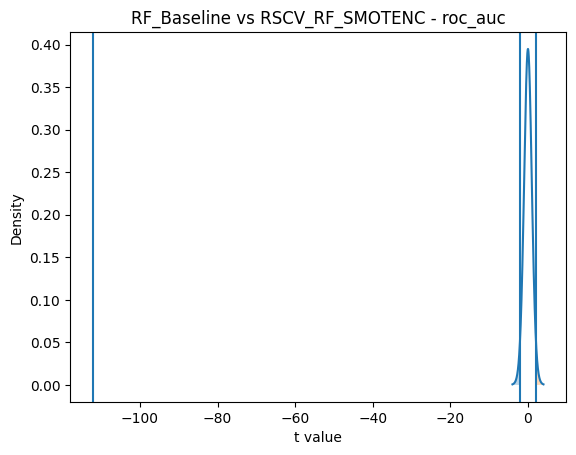

Model 1: RF_Baseline
Model 2: RSCV_RF_CTGAN
Metric : accuracy
t value: -26.084575168682317
p value: 4.007903197655528e-19
t critical: 2.0638985616280205


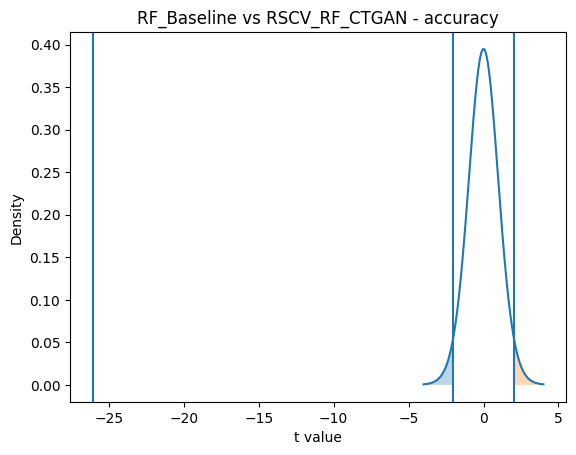

Model 1: RF_Baseline
Model 2: RSCV_RF_CTGAN
Metric : precision
t value: -155.4175111505205
p value: 1.475269614612614e-37
t critical: 2.0638985616280205


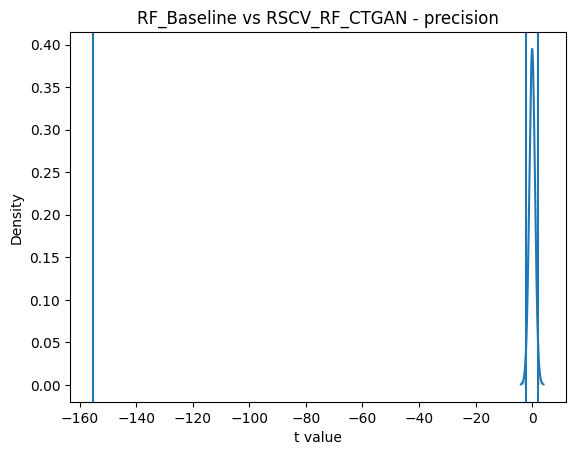

Model 1: RF_Baseline
Model 2: RSCV_RF_CTGAN
Metric : recall
t value: -148.82054518037918
p value: 4.173592730769654e-37
t critical: 2.0638985616280205


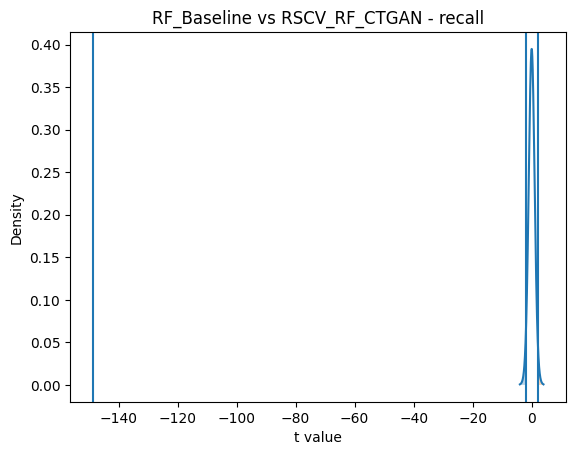

Model 1: RF_Baseline
Model 2: RSCV_RF_CTGAN
Metric : f1
t value: -132.87704962460586
p value: 6.313067166112392e-36
t critical: 2.0638985616280205


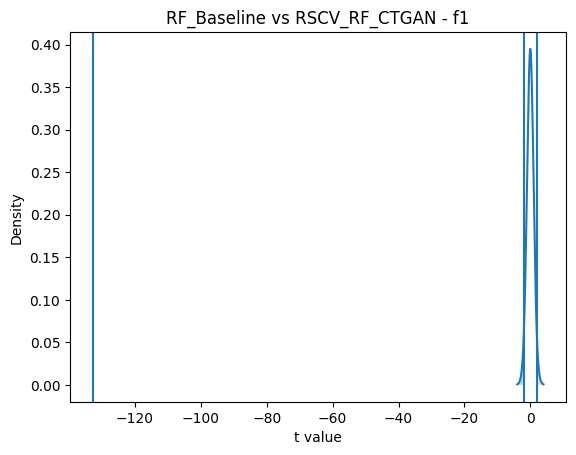

Model 1: RF_Baseline
Model 2: RSCV_RF_CTGAN
Metric : roc_auc
t value: -161.38685414683417
p value: 5.975793988102647e-38
t critical: 2.0638985616280205


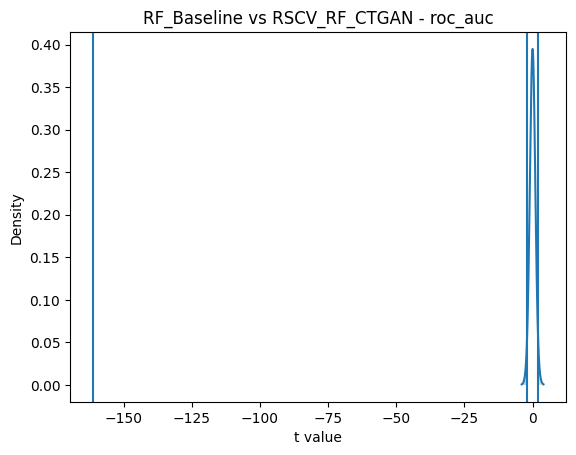

Model 1: RF_SMOTENC
Model 2: RF_CTGAN
Metric : accuracy
t value: -42.2370735246178
p value: 4.8554378319629206e-24
t critical: 2.0638985616280205


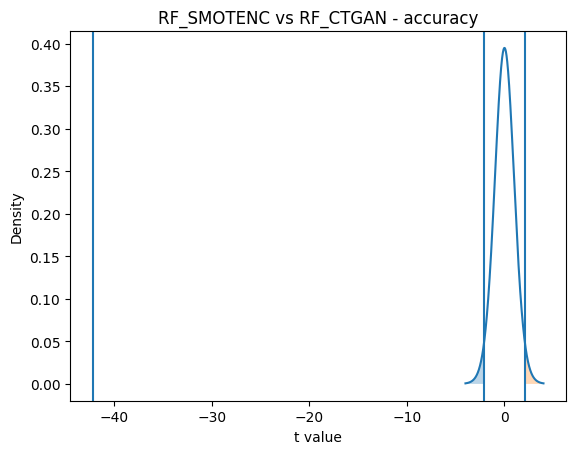

Model 1: RF_SMOTENC
Model 2: RF_CTGAN
Metric : precision
t value: -44.56529687748005
p value: 1.3605999010219715e-24
t critical: 2.0638985616280205


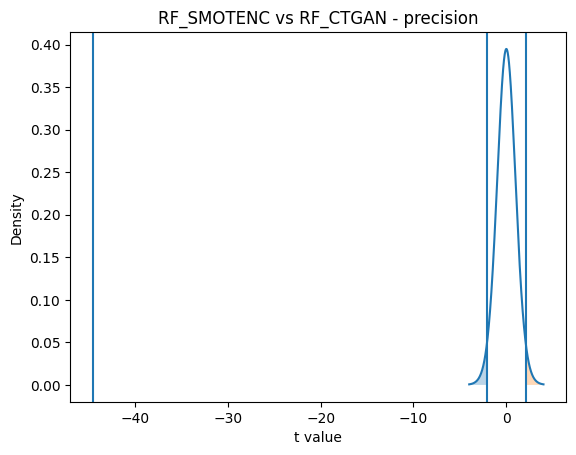

Model 1: RF_SMOTENC
Model 2: RF_CTGAN
Metric : recall
t value: -42.23428882667543
p value: 4.863028813084093e-24
t critical: 2.0638985616280205


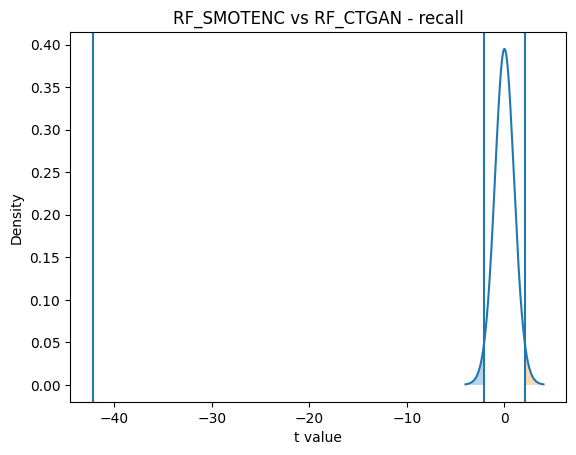

Model 1: RF_SMOTENC
Model 2: RF_CTGAN
Metric : f1
t value: -41.81612680737535
p value: 6.155777294141026e-24
t critical: 2.0638985616280205


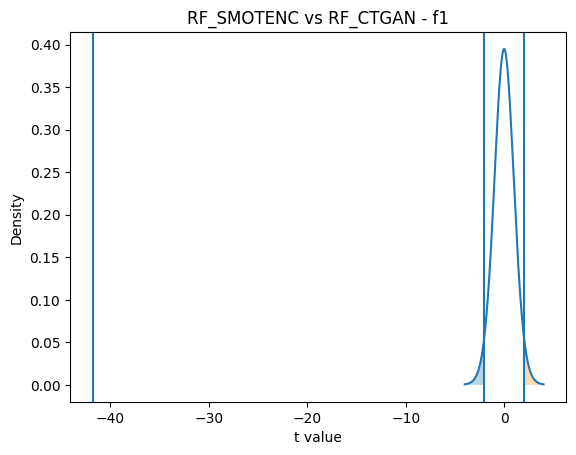

Model 1: RF_SMOTENC
Model 2: RF_CTGAN
Metric : roc_auc
t value: -39.865043232334884
p value: 1.9077481426021854e-23
t critical: 2.0638985616280205


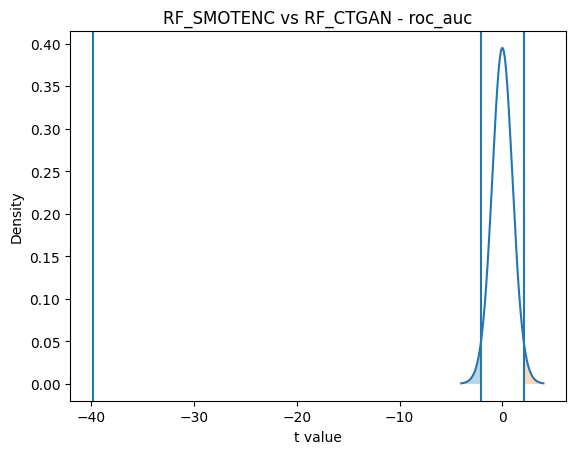

Model 1: RF_SMOTENC
Model 2: RSCV_RF_Baseline
Metric : accuracy
t value: 6.095240141905715
p value: 2.6971383547784487e-06
t critical: 2.0638985616280205


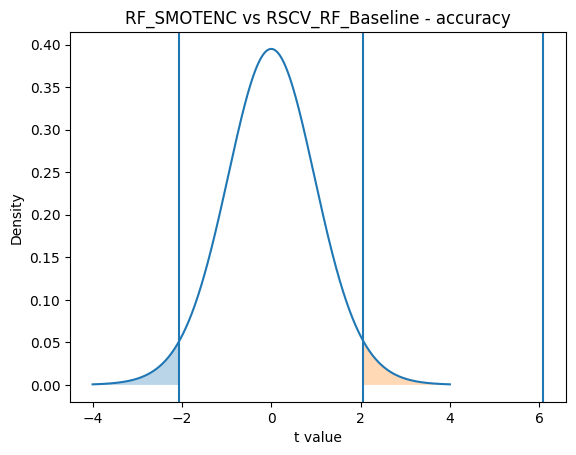

Model 1: RF_SMOTENC
Model 2: RSCV_RF_Baseline
Metric : precision
t value: 10.85260122787795
p value: 9.714778751567032e-11
t critical: 2.0638985616280205


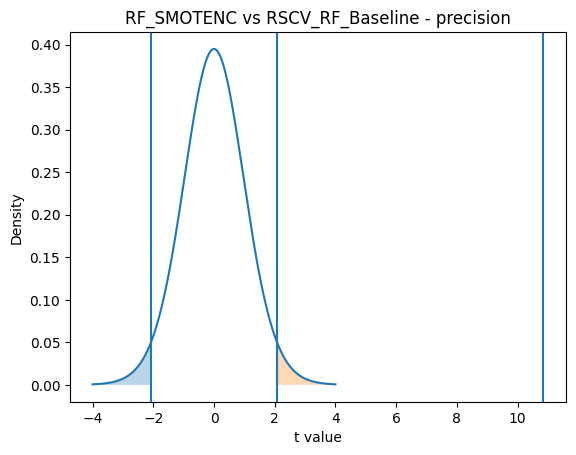

Model 1: RF_SMOTENC
Model 2: RSCV_RF_Baseline
Metric : recall
t value: 59.1118884305842
p value: 1.6419103026563407e-27
t critical: 2.0638985616280205


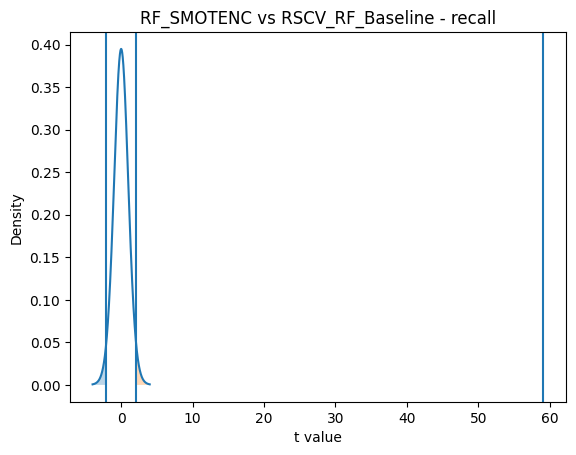

Model 1: RF_SMOTENC
Model 2: RSCV_RF_Baseline
Metric : f1
t value: 77.71760058933064
p value: 2.3851151174063478e-30
t critical: 2.0638985616280205


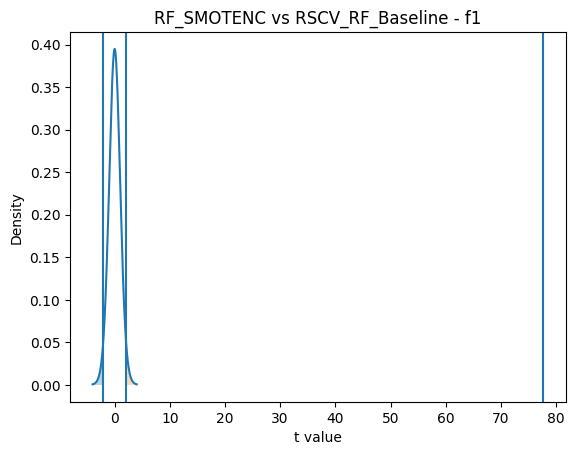

Model 1: RF_SMOTENC
Model 2: RSCV_RF_Baseline
Metric : roc_auc
t value: 54.143072404829695
p value: 1.3303255749268698e-26
t critical: 2.0638985616280205


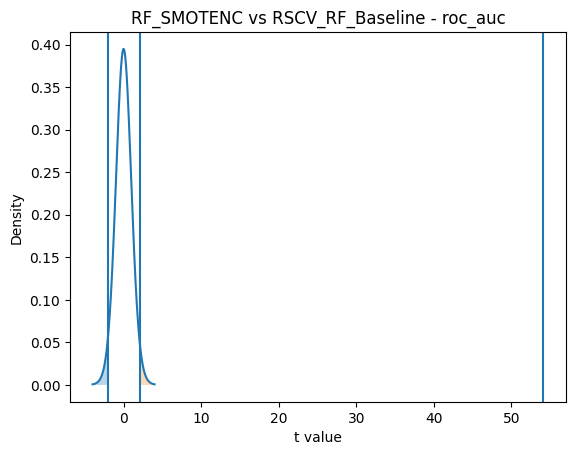

Model 1: RF_SMOTENC
Model 2: RSCV_RF_SMOTENC
Metric : accuracy
t value: -6.521806001886385
p value: 9.582634457297124e-07
t critical: 2.0638985616280205


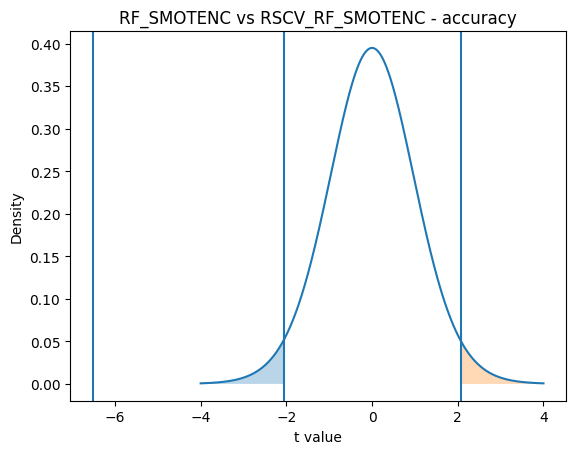

Model 1: RF_SMOTENC
Model 2: RSCV_RF_SMOTENC
Metric : precision
t value: -6.46916680280071
p value: 1.0875815255480409e-06
t critical: 2.0638985616280205


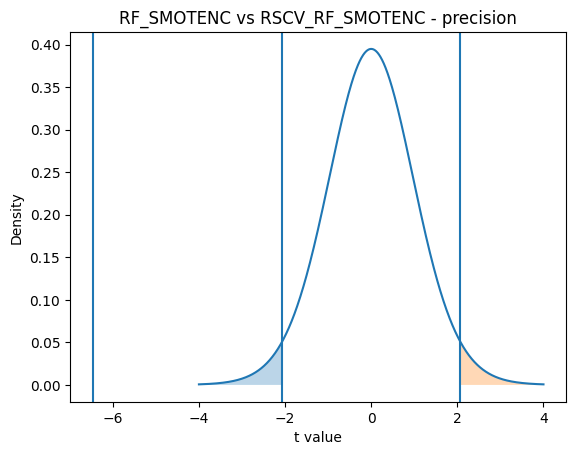

Model 1: RF_SMOTENC
Model 2: RSCV_RF_SMOTENC
Metric : recall
t value: -6.568605784278811
p value: 8.564955682006828e-07
t critical: 2.0638985616280205


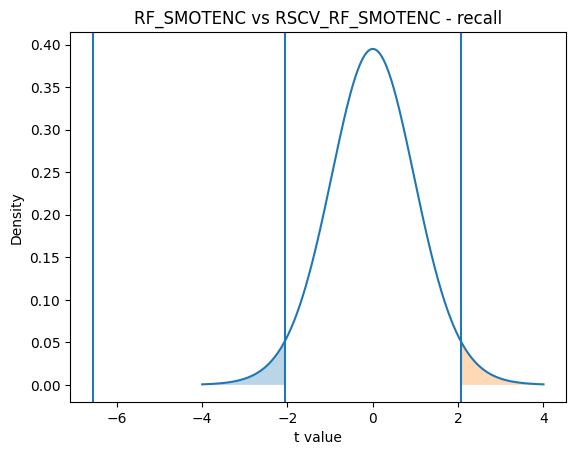

Model 1: RF_SMOTENC
Model 2: RSCV_RF_SMOTENC
Metric : f1
t value: -6.526576011921566
p value: 9.473490418082945e-07
t critical: 2.0638985616280205


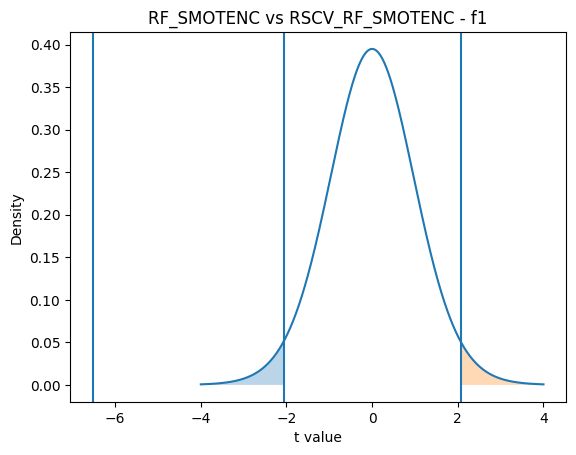

Model 1: RF_SMOTENC
Model 2: RSCV_RF_SMOTENC
Metric : roc_auc
t value: -7.271876913377728
p value: 1.6369485394074847e-07
t critical: 2.0638985616280205


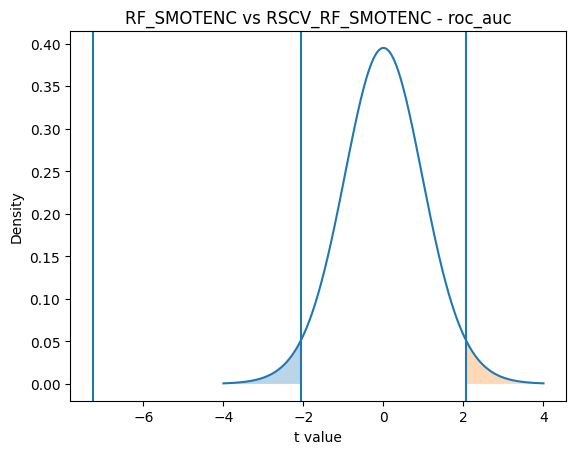

Model 1: RF_SMOTENC
Model 2: RSCV_RF_CTGAN
Metric : accuracy
t value: -35.715892459007385
p value: 2.5571955204621704e-22
t critical: 2.0638985616280205


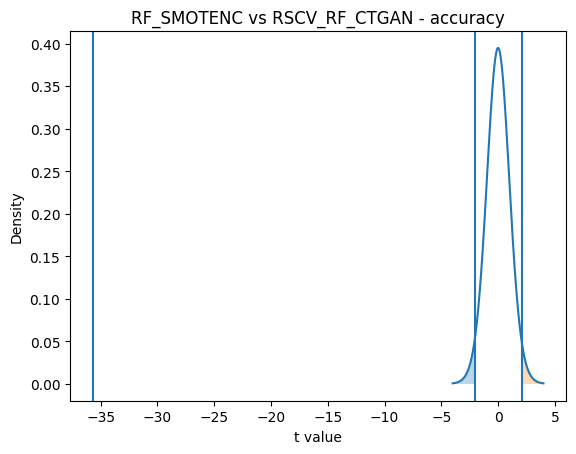

Model 1: RF_SMOTENC
Model 2: RSCV_RF_CTGAN
Metric : precision
t value: -35.92164874810753
p value: 2.2332999250146816e-22
t critical: 2.0638985616280205


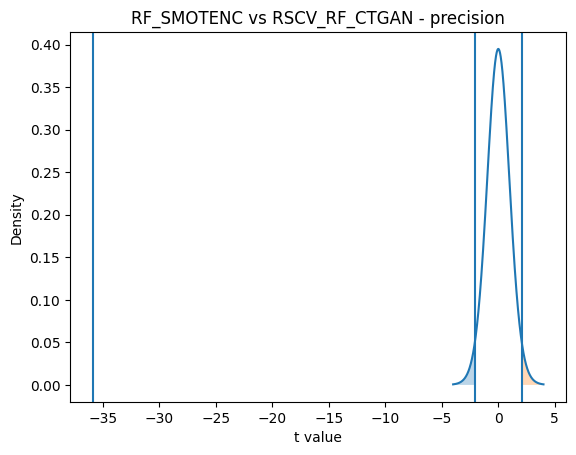

Model 1: RF_SMOTENC
Model 2: RSCV_RF_CTGAN
Metric : recall
t value: -35.679988121297555
p value: 2.6185503282386604e-22
t critical: 2.0638985616280205


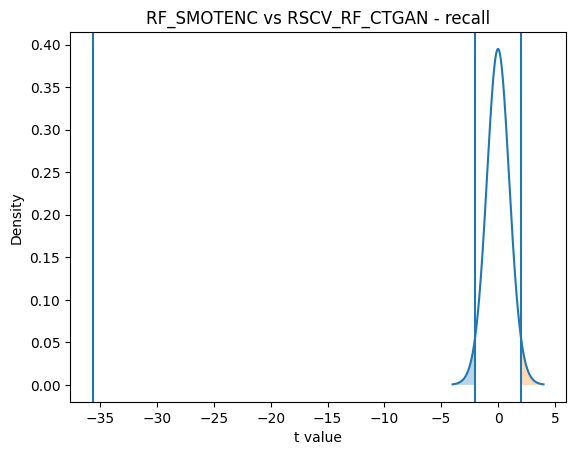

Model 1: RF_SMOTENC
Model 2: RSCV_RF_CTGAN
Metric : f1
t value: -35.664937024017654
p value: 2.6447242444501133e-22
t critical: 2.0638985616280205


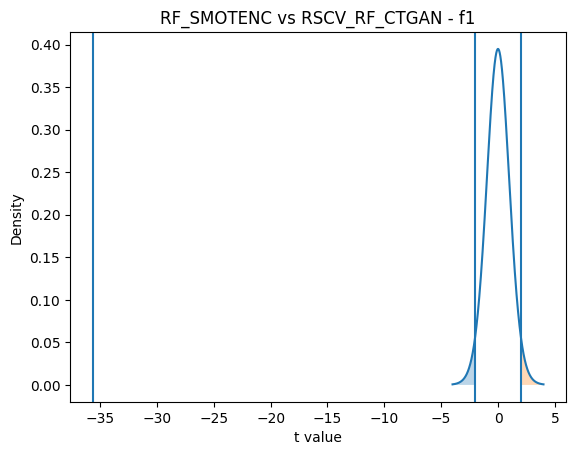

Model 1: RF_SMOTENC
Model 2: RSCV_RF_CTGAN
Metric : roc_auc
t value: -34.60384636095717
p value: 5.387844784421735e-22
t critical: 2.0638985616280205


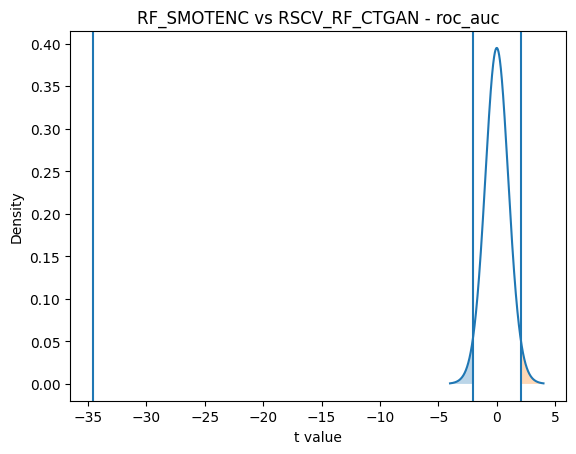

Model 1: RF_CTGAN
Model 2: RSCV_RF_Baseline
Metric : accuracy
t value: 41.01943022752614
p value: 9.707842146990306e-24
t critical: 2.0638985616280205


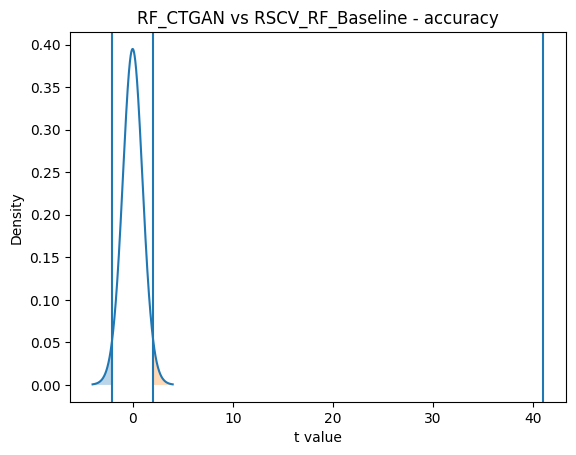

Model 1: RF_CTGAN
Model 2: RSCV_RF_Baseline
Metric : precision
t value: 15.618509521669663
p value: 4.4893778767662704e-14
t critical: 2.0638985616280205


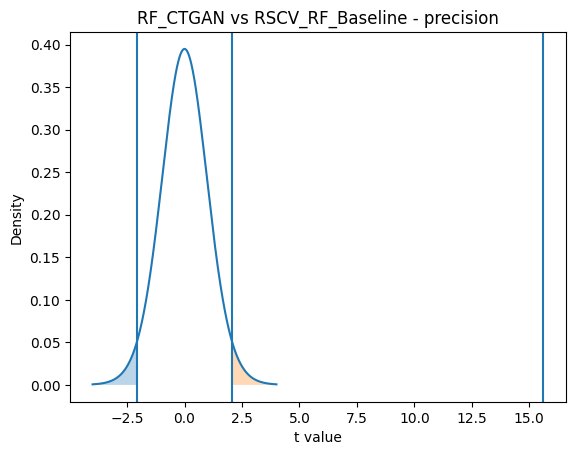

Model 1: RF_CTGAN
Model 2: RSCV_RF_Baseline
Metric : recall
t value: 97.53008902186488
p value: 1.0420588907937543e-32
t critical: 2.0638985616280205


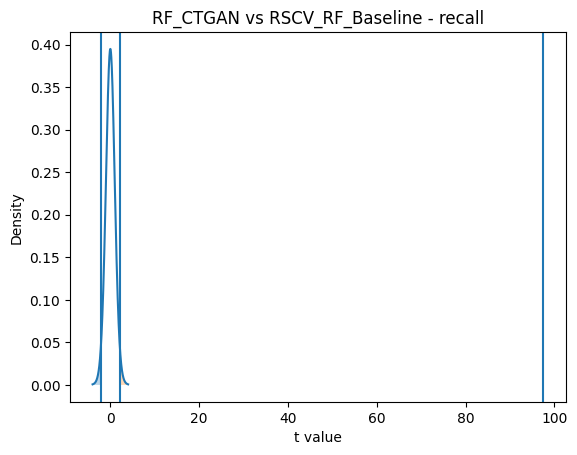

Model 1: RF_CTGAN
Model 2: RSCV_RF_Baseline
Metric : f1
t value: 110.63252032772738
p value: 5.091467406317775e-34
t critical: 2.0638985616280205


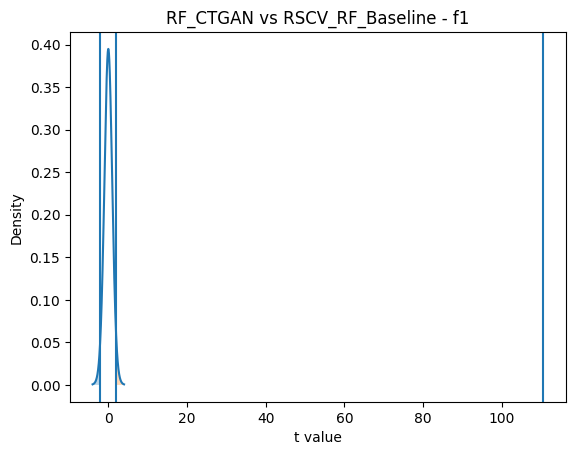

Model 1: RF_CTGAN
Model 2: RSCV_RF_Baseline
Metric : roc_auc
t value: 99.65291067508743
p value: 6.2228747814085e-33
t critical: 2.0638985616280205


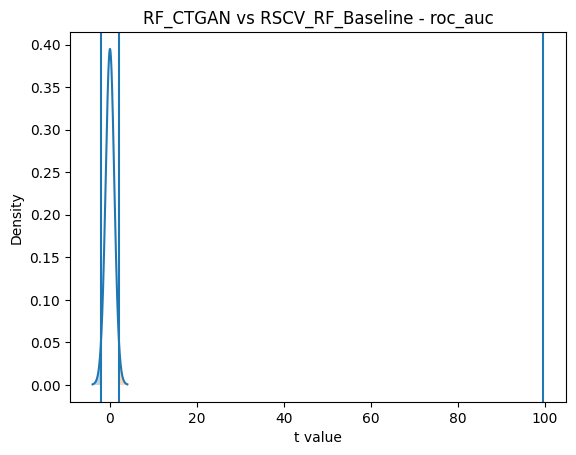

Model 1: RF_CTGAN
Model 2: RSCV_RF_SMOTENC
Metric : accuracy
t value: 20.348004039877093
p value: 1.21042746470717e-16
t critical: 2.0638985616280205


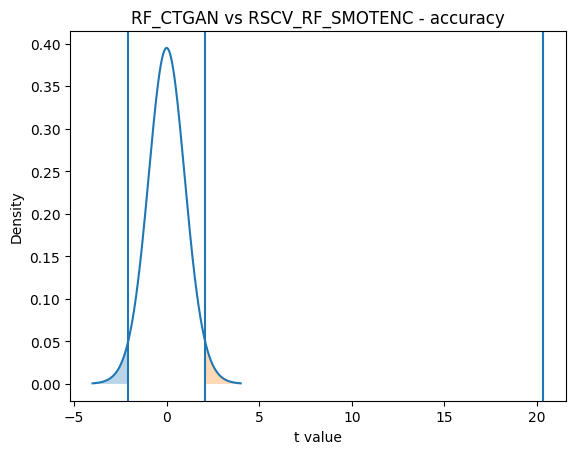

Model 1: RF_CTGAN
Model 2: RSCV_RF_SMOTENC
Metric : precision
t value: 21.707311799983366
p value: 2.7691208712864023e-17
t critical: 2.0638985616280205


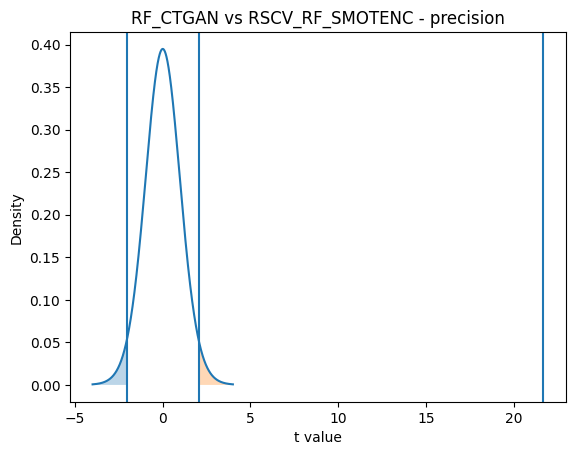

Model 1: RF_CTGAN
Model 2: RSCV_RF_SMOTENC
Metric : recall
t value: 20.304908182191998
p value: 1.270196409832775e-16
t critical: 2.0638985616280205


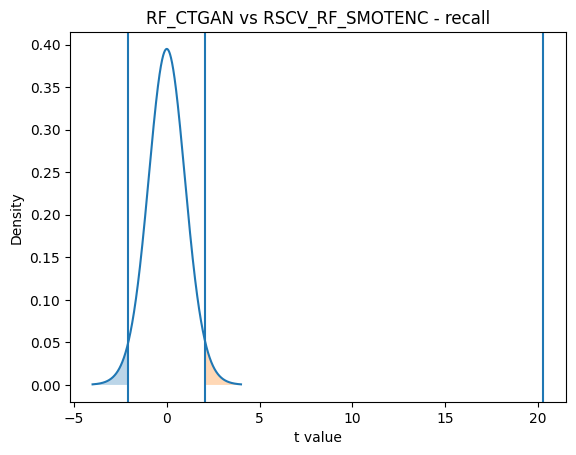

Model 1: RF_CTGAN
Model 2: RSCV_RF_SMOTENC
Metric : f1
t value: 20.205650742875697
p value: 1.4198183793356977e-16
t critical: 2.0638985616280205


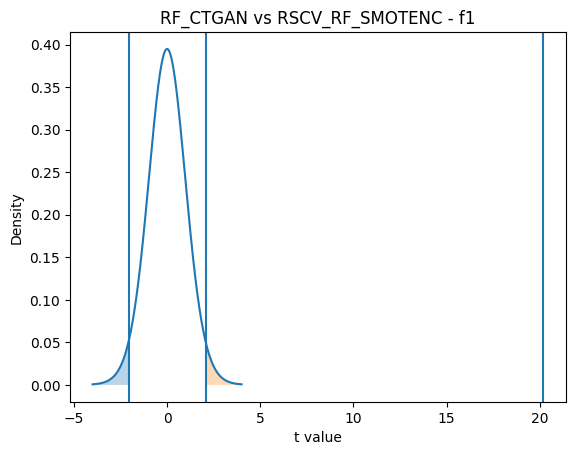

Model 1: RF_CTGAN
Model 2: RSCV_RF_SMOTENC
Metric : roc_auc
t value: 24.2727814710141
p value: 2.122686216646765e-18
t critical: 2.0638985616280205


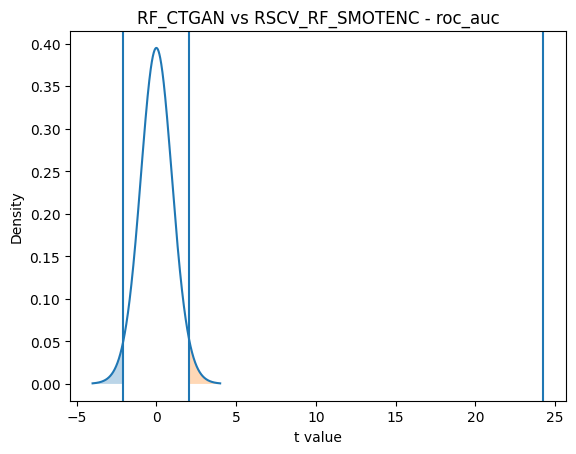

Model 1: RF_CTGAN
Model 2: RSCV_RF_CTGAN
Metric : accuracy
t value: -2.0422065982665485
p value: 0.052266596759198605
t critical: 2.0638985616280205


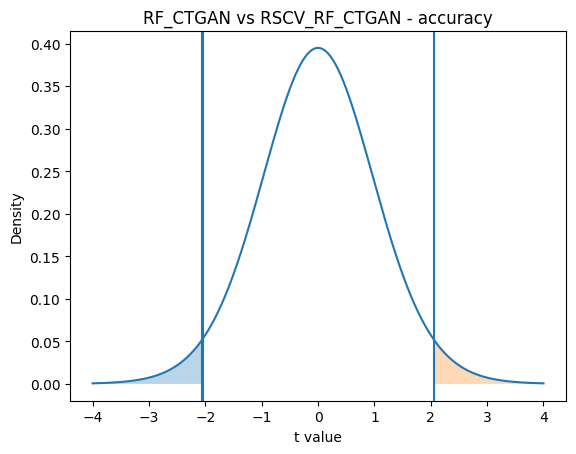

Model 1: RF_CTGAN
Model 2: RSCV_RF_CTGAN
Metric : precision
t value: -1.8453577502070753
p value: 0.07735969007834118
t critical: 2.0638985616280205


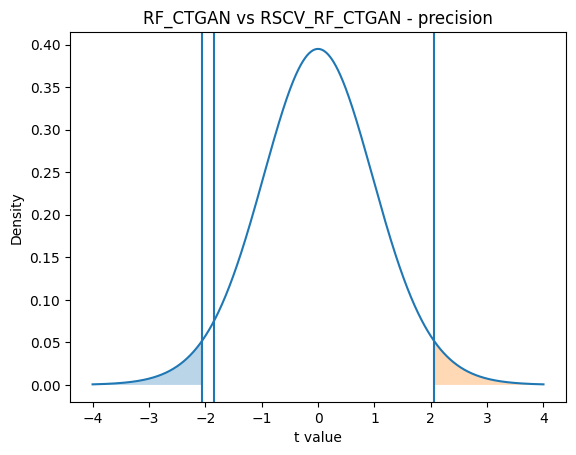

Model 1: RF_CTGAN
Model 2: RSCV_RF_CTGAN
Metric : recall
t value: -2.0671517856283885
p value: 0.04966772908493749
t critical: 2.0638985616280205


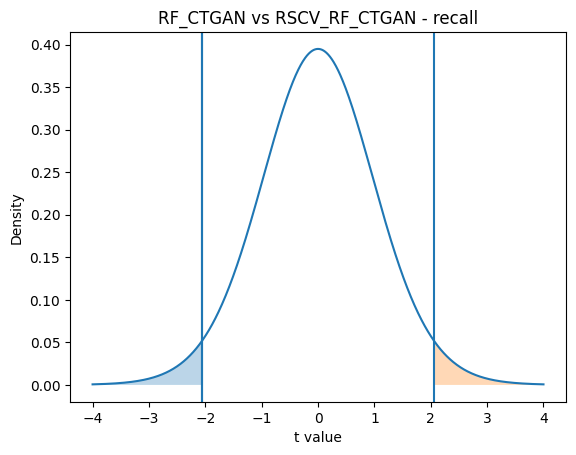

Model 1: RF_CTGAN
Model 2: RSCV_RF_CTGAN
Metric : f1
t value: -2.05251400586989
p value: 0.0511784191041055
t critical: 2.0638985616280205


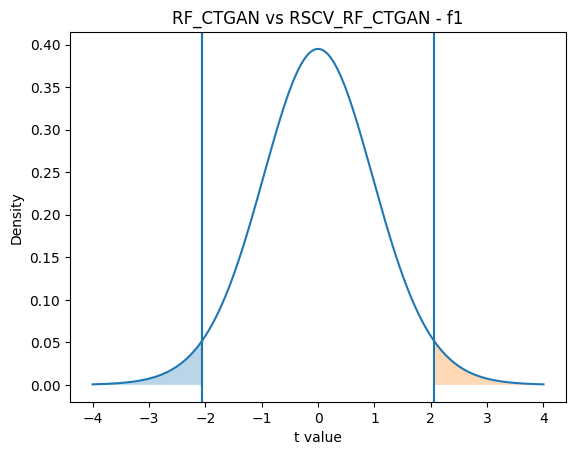

Model 1: RF_CTGAN
Model 2: RSCV_RF_CTGAN
Metric : roc_auc
t value: -6.140724088543884
p value: 2.413071131731852e-06
t critical: 2.0638985616280205


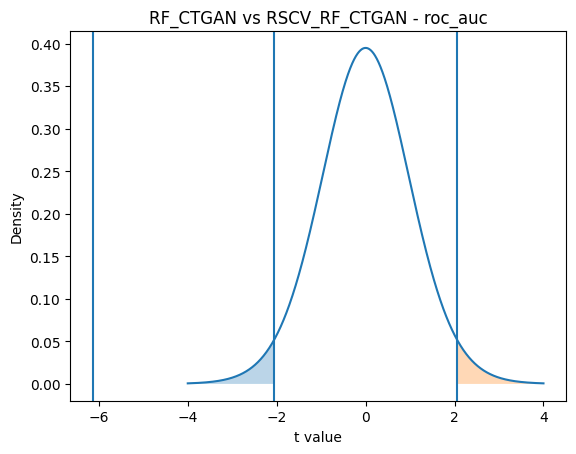

Model 1: RSCV_RF_Baseline
Model 2: RSCV_RF_SMOTENC
Metric : accuracy
t value: -22.95221792729011
p value: 7.705394170211113e-18
t critical: 2.0638985616280205


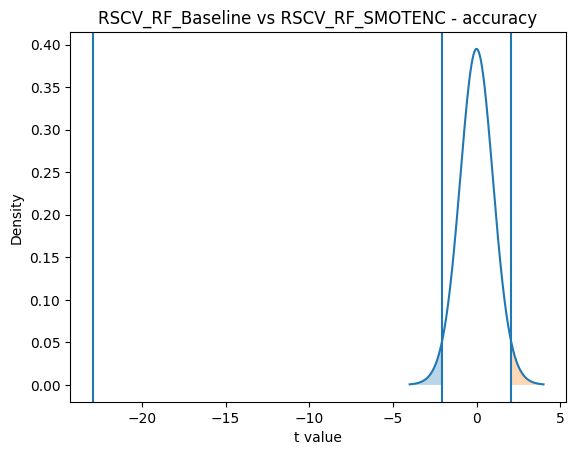

Model 1: RSCV_RF_Baseline
Model 2: RSCV_RF_SMOTENC
Metric : precision
t value: -12.57211522668993
p value: 4.737187356976338e-12
t critical: 2.0638985616280205


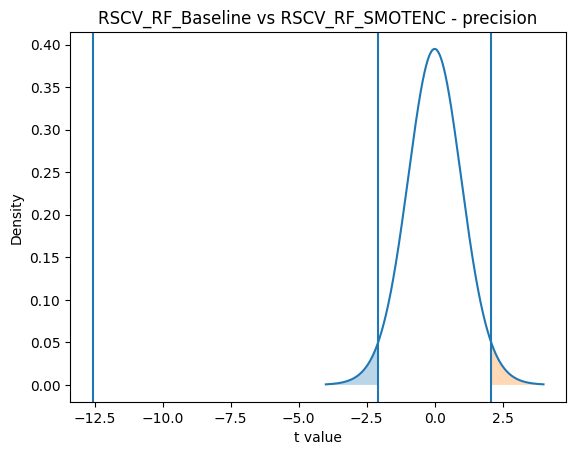

Model 1: RSCV_RF_Baseline
Model 2: RSCV_RF_SMOTENC
Metric : recall
t value: -105.59878791697567
p value: 1.5533122585251278e-33
t critical: 2.0638985616280205


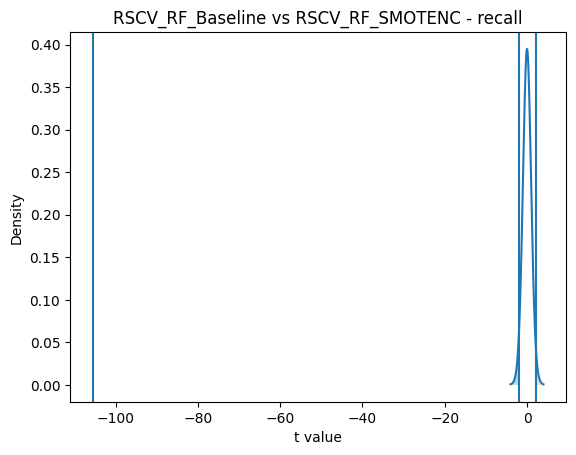

Model 1: RSCV_RF_Baseline
Model 2: RSCV_RF_SMOTENC
Metric : f1
t value: -121.30372524408088
p value: 5.606615976987787e-35
t critical: 2.0638985616280205


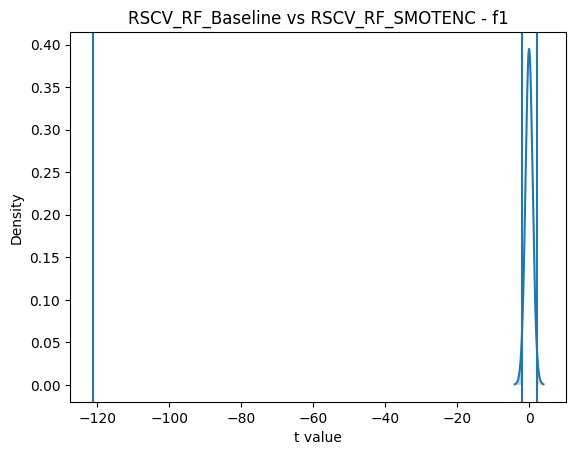

Model 1: RSCV_RF_Baseline
Model 2: RSCV_RF_SMOTENC
Metric : roc_auc
t value: -82.93766596993832
p value: 5.039062082118869e-31
t critical: 2.0638985616280205


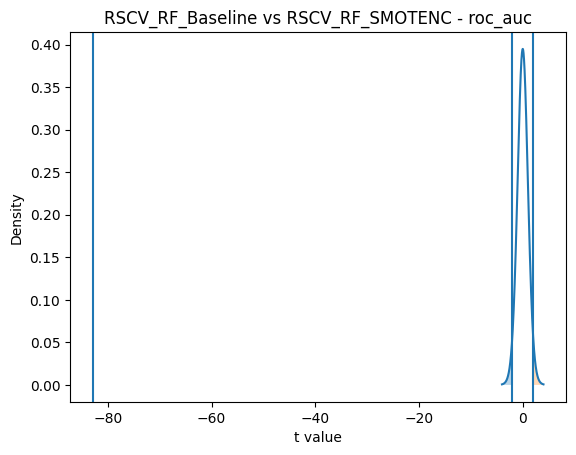

Model 1: RSCV_RF_Baseline
Model 2: RSCV_RF_CTGAN
Metric : accuracy
t value: -80.63858589633529
p value: 9.870880211656107e-31
t critical: 2.0638985616280205


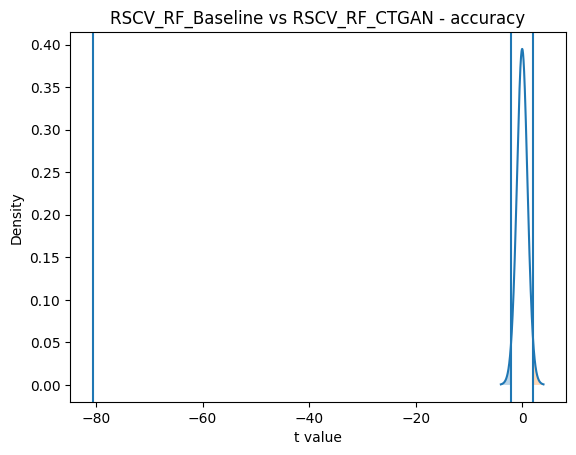

Model 1: RSCV_RF_Baseline
Model 2: RSCV_RF_CTGAN
Metric : precision
t value: -16.522929173423663
p value: 1.2986210396636429e-14
t critical: 2.0638985616280205


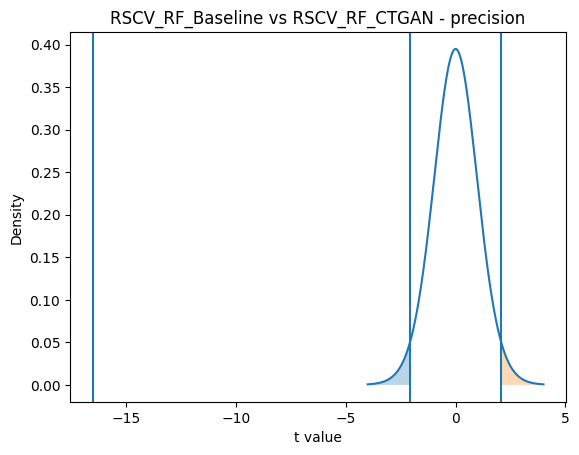

Model 1: RSCV_RF_Baseline
Model 2: RSCV_RF_CTGAN
Metric : recall
t value: -187.60164354788856
p value: 1.6171539930673406e-39
t critical: 2.0638985616280205


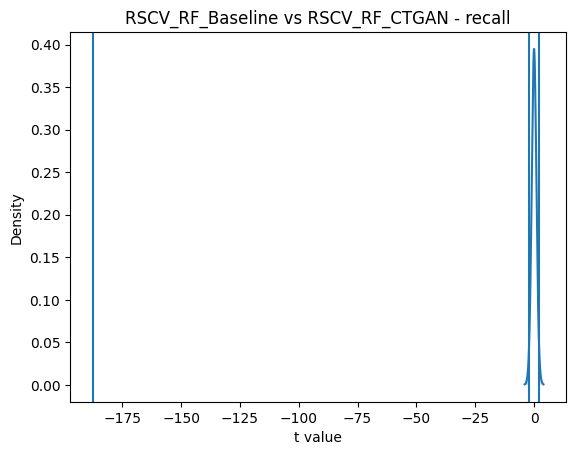

Model 1: RSCV_RF_Baseline
Model 2: RSCV_RF_CTGAN
Metric : f1
t value: -197.52491011119216
p value: 4.6972131457743316e-40
t critical: 2.0638985616280205


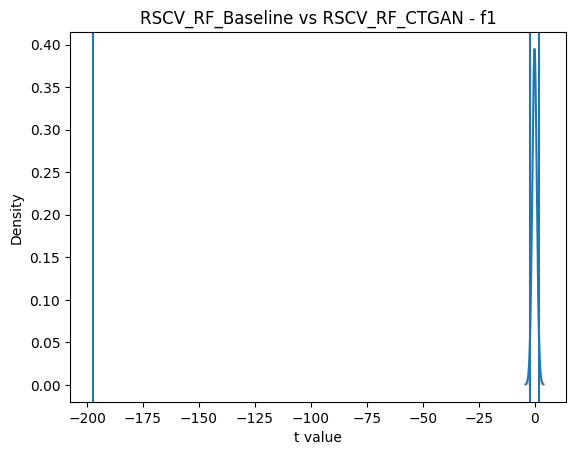

Model 1: RSCV_RF_Baseline
Model 2: RSCV_RF_CTGAN
Metric : roc_auc
t value: -147.8948192386703
p value: 4.847080980244972e-37
t critical: 2.0638985616280205


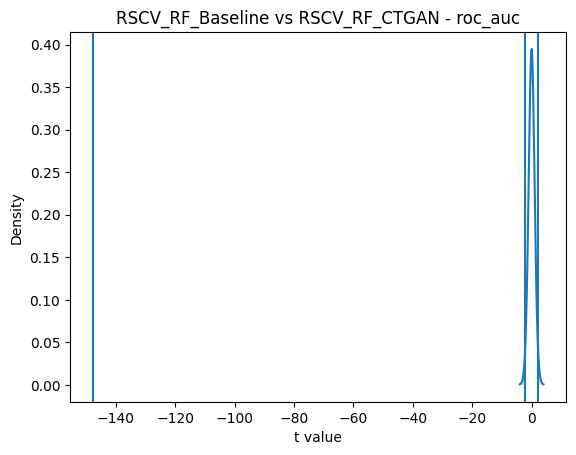

Model 1: RSCV_RF_SMOTENC
Model 2: RSCV_RF_CTGAN
Metric : accuracy
t value: -33.908374801260614
p value: 8.688676881782218e-22
t critical: 2.0638985616280205


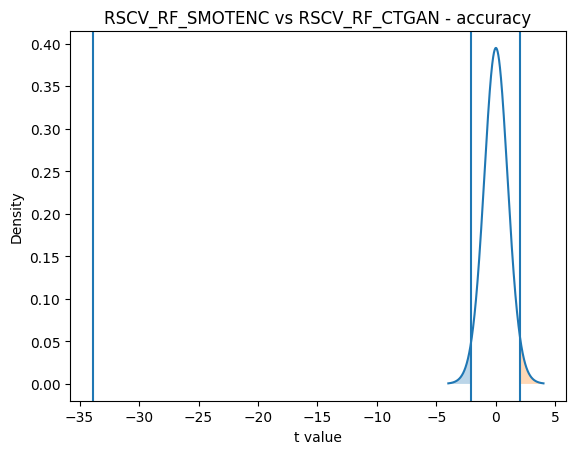

Model 1: RSCV_RF_SMOTENC
Model 2: RSCV_RF_CTGAN
Metric : precision
t value: -34.387803770640765
p value: 6.243850812414068e-22
t critical: 2.0638985616280205


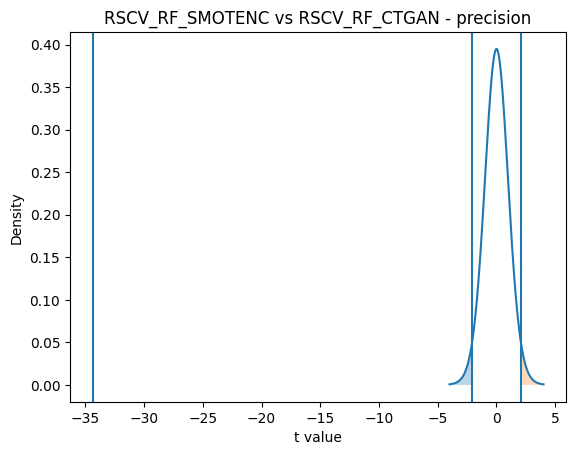

Model 1: RSCV_RF_SMOTENC
Model 2: RSCV_RF_CTGAN
Metric : recall
t value: -33.93711015097837
p value: 8.517220742028096e-22
t critical: 2.0638985616280205


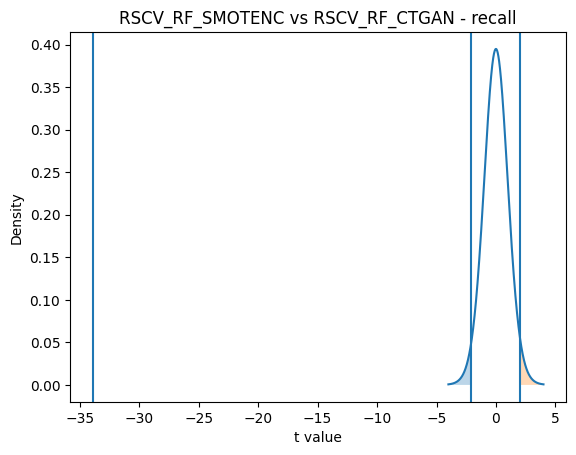

Model 1: RSCV_RF_SMOTENC
Model 2: RSCV_RF_CTGAN
Metric : f1
t value: -33.87915011159744
p value: 8.866740982690046e-22
t critical: 2.0638985616280205


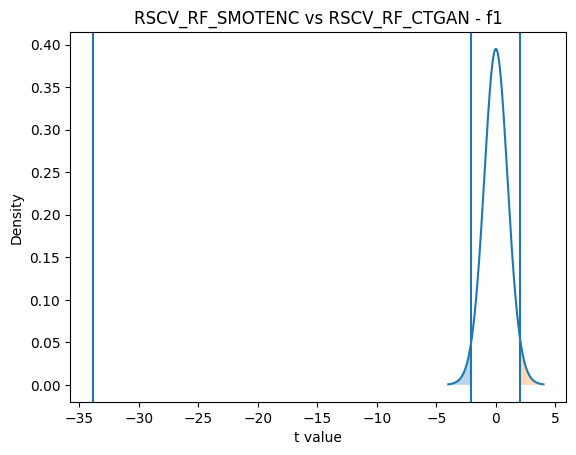

Model 1: RSCV_RF_SMOTENC
Model 2: RSCV_RF_CTGAN
Metric : roc_auc
t value: -33.801893640821305
p value: 9.355990177625763e-22
t critical: 2.0638985616280205


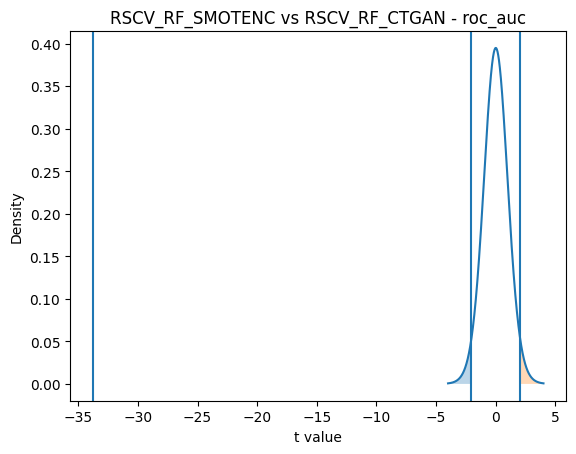

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, t
import pandas as pd
import itertools

# =========================
# LOAD SEMUA MODEL
# =========================

models = {
    "RF_Baseline": pd.read_csv("output/random_rf_plain_no_threshold.csv"),
    "RF_SMOTENC": pd.read_csv("output/random_rf_kfold_5fold_25iter_SMOTENC.csv"),
    "RF_CTGAN": pd.read_csv("output/random_rf_kfold_5fold_25iter_CTGAN.csv"),
    "RSCV_RF_Baseline": pd.read_csv("output/rf_plain_no_threshold.csv"),
    "RSCV_RF_SMOTENC": pd.read_csv("output/rf_train_test_split_25iter_SMOTENC.csv"),
    "RSCV_RF_CTGAN": pd.read_csv("output/rf_train_test_split_25iter_CTGAN.csv"),
}

metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
alpha = 0.05

# =========================
# LOOP SEMUA PASANGAN
# =========================

for (name1, df1), (name2, df2) in itertools.combinations(models.items(), 2):

    n = len(df1)
    dfree = n - 1
    t_critical = t.ppf(1 - alpha/2, dfree)

    for metric in metrics:

        t_stat, p_value = ttest_rel(df1[metric], df2[metric])

        print("====================================")
        print("Model 1:", name1)
        print("Model 2:", name2)
        print("Metric :", metric)
        print("t value:", t_stat)
        print("p value:", p_value)
        print("t critical:", t_critical)

        # Plot distribusi
        x = np.linspace(-4, 4, 1000)
        y = t.pdf(x, dfree)

        plt.figure()
        plt.plot(x, y)
        plt.axvline(-t_critical)
        plt.axvline(t_critical)
        plt.axvline(t_stat)

        plt.fill_between(x, y, where=(x <= -t_critical), alpha=0.3)
        plt.fill_between(x, y, where=(x >= t_critical), alpha=0.3)

        plt.title(f"{name1} vs {name2} - {metric}")
        plt.xlabel("t value")
        plt.ylabel("Density")

        plt.show()


BAGGING & RF

In [ ]:
import pandas as pd
import itertools
from scipy.stats import ttest_rel, t

# =========================
# SETUP
# =========================

OUTPUT_DIR = "output"   # sesuaikan jika berbeda

model_files = {
    # RANDOM FOREST
    "RF Baseline": "random_rf_plain_no_threshold.csv",
    "RSCV RF Baseline": "rf_plain_no_threshold.csv",
    "RF SMOTENC": "random_rf_kfold_5fold_25iter_SMOTENC.csv",
    "RF CTGAN": "random_rf_kfold_5fold_25iter_CTGAN.csv",
    "RSCV RF SMOTENC": "rf_train_test_split_25iter_SMOTENC.csv",
    "RSCV RF CTGAN": "rf_train_test_split_25iter_CTGAN.csv",

    # BAGGING
    "Bagging Baseline": "random_bagging_plain_no_threshold.csv",
    "RSCV Bagging Baseline": "bagging_plain_no_threshold.csv",
    "Bagging SMOTENC": "random_bagging_kfold_5fold_25iter_SMOTENC.csv",
    "Bagging CTGAN": "random_bagging_kfold_5fold_25iter_CTGAN.csv",
    "RSCV Bagging SMOTENC": "bagging_train_test_split_25iter_SMOTENC.csv",
    "RSCV Bagging CTGAN": "bagging_train_test_split_25iter_CTGAN.csv",
}


metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

alpha = 0.05

# =========================
# LOAD DATA
# =========================

model_data = {}

for name, file in model_files.items():
    df = pd.read_csv(f"{OUTPUT_DIR}/{file}")
    model_data[name] = df

n = len(next(iter(model_data.values())))
dfree = n - 1
t_critical = t.ppf(1 - alpha/2, dfree)

print("Jumlah iterasi:", n)
print("Degree of freedom:", dfree)
print("Alpha:", alpha)
print("T critical (two-tailed):", t_critical)
print("\n============================\n")

# =========================
# PAIRED T TEST
# =========================

results = []

model_pairs = list(itertools.combinations(model_data.keys(), 2))

for model1, model2 in model_pairs:
    df1 = model_data[model1]
    df2 = model_data[model2]

    for metric in metrics:

        t_stat, p_value = ttest_rel(df1[metric], df2[metric])

        significant = "Significant" if p_value < alpha else "Not Significant"

        results.append({
            "Model_1": model1,
            "Model_2": model2,
            "Metric": metric,
            "t_value": t_stat,
            "p_value": p_value,
            "alpha": alpha,
            "t_critical": t_critical,
            "Significance": significant
        })

results_df = pd.DataFrame(results)

print(results_df)

results_df.to_csv(
    f"{OUTPUT_DIR}/paired_ttest_all_ensembles.csv",
    index=False
)


Jumlah iterasi: 25
Degree of freedom: 24
Alpha: 0.05
T critical (two-tailed): 2.0638985616280205


                  Model_1             Model_2     Metric    t_value  \
0             RF Baseline    RSCV RF Baseline   accuracy -11.904661   
1             RF Baseline    RSCV RF Baseline  precision   1.006049   
2             RF Baseline    RSCV RF Baseline     recall   2.361930   
3             RF Baseline    RSCV RF Baseline         f1  22.951097   
4             RF Baseline    RSCV RF Baseline    roc_auc   1.093262   
..                    ...                 ...        ...        ...   
325  RSCV Bagging SMOTENC  RSCV Bagging CTGAN   accuracy -33.357739   
326  RSCV Bagging SMOTENC  RSCV Bagging CTGAN  precision -33.052579   
327  RSCV Bagging SMOTENC  RSCV Bagging CTGAN     recall -33.568035   
328  RSCV Bagging SMOTENC  RSCV Bagging CTGAN         f1 -33.460412   
329  RSCV Bagging SMOTENC  RSCV Bagging CTGAN    roc_auc -34.742022   

          p_value  alpha  t_critical     Signifi

In [ ]:
import pandas as pd
import itertools
from scipy.stats import ttest_rel, t

# =========================
# SETUP
# =========================

OUTPUT_DIR = "output"   # Adjust if necessary

model_files = {
    # RANDOM FOREST
    "RF Baseline": "random_rf_plain_no_threshold.csv",
    "RSCV RF Baseline": "rf_plain_no_threshold.csv",
    "RF SMOTENC": "random_rf_kfold_5fold_25iter_SMOTENC.csv",
    "RF CTGAN": "random_rf_kfold_5fold_25iter_CTGAN.csv",
    "RSCV RF SMOTENC": "rf_train_test_split_25iter_SMOTENC.csv",
    "RSCV RF CTGAN": "rf_train_test_split_25iter_CTGAN.csv",

    # BAGGING
    "Bagging Baseline": "random_bagging_plain_no_threshold.csv",
    "RSCV Bagging Baseline": "bagging_plain_no_threshold.csv",
    "Bagging SMOTENC": "random_bagging_kfold_5fold_25iter_SMOTENC.csv",
    "Bagging CTGAN": "random_bagging_kfold_5fold_25iter_CTGAN.csv",
    "RSCV Bagging SMOTENC": "bagging_train_test_split_25iter_SMOTENC.csv",
    "RSCV Bagging CTGAN": "bagging_train_test_split_25iter_CTGAN.csv",
}

# Only use accuracy for evaluation
metrics = ["accuracy"]

alpha = 0.05

# =========================
# LOAD DATA
# =========================

model_data = {}

for name, file in model_files.items():
    df = pd.read_csv(f"{OUTPUT_DIR}/{file}")
    model_data[name] = df

n = len(next(iter(model_data.values())))
dfree = n - 1
t_critical = t.ppf(1 - alpha/2, dfree)

print("Jumlah iterasi:", n)
print("Degree of freedom:", dfree)
print("Alpha:", alpha)
print("T critical (two-tailed):", t_critical)
print("\n============================\n")

# =========================
# PAIRED T TEST
# =========================

results = []

model_pairs = list(itertools.combinations(model_data.keys(), 2))

for model1, model2 in model_pairs:
    df1 = model_data[model1]
    df2 = model_data[model2]

    for metric in metrics:  # Now only iterating through "accuracy"
        t_stat, p_value = ttest_rel(df1[metric], df2[metric])

        significant = "Significant" if p_value < alpha else "Not Significant"

        results.append({
            "Model_1": model1,
            "Model_2": model2,
            "Metric": metric,
            "t_value": t_stat,
            "p_value": p_value,
            "alpha": alpha,
            "t_critical": t_critical,
            "Significance": significant
        })

results_df = pd.DataFrame(results)

print(results_df)

results_df.to_csv(
    f"{OUTPUT_DIR}/paired_ttest_accuracy.csv",  # Adjusted file name to reflect only accuracy
    index=False
)

Jumlah iterasi: 25
Degree of freedom: 24
Alpha: 0.05
T critical (two-tailed): 2.0638985616280205


                 Model_1               Model_2    Metric    t_value  \
0            RF Baseline      RSCV RF Baseline  accuracy -11.904661   
1            RF Baseline            RF SMOTENC  accuracy -13.236810   
2            RF Baseline              RF CTGAN  accuracy -24.340500   
3            RF Baseline       RSCV RF SMOTENC  accuracy -15.958356   
4            RF Baseline         RSCV RF CTGAN  accuracy -26.084575   
..                   ...                   ...       ...        ...   
61       Bagging SMOTENC  RSCV Bagging SMOTENC  accuracy   5.585559   
62       Bagging SMOTENC    RSCV Bagging CTGAN  accuracy -45.936459   
63         Bagging CTGAN  RSCV Bagging SMOTENC  accuracy  57.202437   
64         Bagging CTGAN    RSCV Bagging CTGAN  accuracy  10.367701   
65  RSCV Bagging SMOTENC    RSCV Bagging CTGAN  accuracy -33.357739   

         p_value  alpha  t_critical Significance

In [ ]:
import pandas as pd
import itertools
from scipy.stats import ttest_rel, t

# =========================
# SETUP
# =========================

OUTPUT_DIR = "output"   # Adjust if necessary

model_files = {
    # RANDOM FOREST
    "RF Baseline": "random_rf_plain_no_threshold.csv",
    "RSCV RF Baseline": "rf_plain_no_threshold.csv",
    "RF SMOTENC": "random_rf_kfold_5fold_25iter_SMOTENC.csv",
    "RF CTGAN": "random_rf_kfold_5fold_25iter_CTGAN.csv",
    "RSCV RF SMOTENC": "rf_train_test_split_25iter_SMOTENC.csv",
    "RSCV RF CTGAN": "rf_train_test_split_25iter_CTGAN.csv",

    # BAGGING
    # "Bagging Baseline": "random_bagging_plain_no_threshold.csv",
    # "RSCV Bagging Baseline": "bagging_plain_no_threshold.csv",
    # "Bagging SMOTENC": "random_bagging_kfold_5fold_25iter_SMOTENC.csv",
    # "Bagging CTGAN": "random_bagging_kfold_5fold_25iter_CTGAN.csv",
    # "RSCV Bagging SMOTENC": "bagging_train_test_split_25iter_SMOTENC.csv",
    # "RSCV Bagging CTGAN": "bagging_train_test_split_25iter_CTGAN.csv",
}
# Only use accuracy for evaluation
metrics = ["f1"]

alpha = 0.05

# =========================
# LOAD DATA
# =========================

model_data = {}

for name, file in model_files.items():
    df = pd.read_csv(f"{OUTPUT_DIR}/{file}")
    model_data[name] = df

n = len(next(iter(model_data.values())))
dfree = n - 1
t_critical = t.ppf(1 - alpha/2, dfree)

print("Jumlah iterasi:", n)
print("Degree of freedom:", dfree)
print("Alpha:", alpha)
print("T critical (two-tailed):", t_critical)
print("\n============================\n")

# =========================
# PAIRED T TEST
# =========================

results = []

model_pairs = list(itertools.combinations(model_data.keys(), 2))

for model1, model2 in model_pairs:
    df1 = model_data[model1]
    df2 = model_data[model2]

    for metric in metrics:  # Now only iterating through "accuracy"
        t_stat, p_value = ttest_rel(df1[metric], df2[metric])

        significant = "Significant" if p_value < alpha else "Not Significant"

        results.append({
            "Model_1": model1,
            "Model_2": model2,
            "Metric": metric,
            "t_value": t_stat,
            "p_value": p_value,
            "alpha": alpha,
            "t_critical": t_critical,
            "Significance": significant
        })

results_df = pd.DataFrame(results)

print(results_df)

results_df.to_csv(
    f"{OUTPUT_DIR}/paired_ttest_accuracy.csv",  # Adjusted file name to reflect only accuracy
    index=False
)

Jumlah iterasi: 25
Degree of freedom: 24
Alpha: 0.05
T critical (two-tailed): 2.0638985616280205


             Model_1           Model_2 Metric     t_value       p_value  \
0        RF Baseline  RSCV RF Baseline     f1   22.951097  7.714055e-18   
1        RF Baseline        RF SMOTENC     f1  -57.391198  3.320308e-27   
2        RF Baseline          RF CTGAN     f1  -94.108747  2.449998e-32   
3        RF Baseline   RSCV RF SMOTENC     f1  -61.826859  5.626394e-28   
4        RF Baseline     RSCV RF CTGAN     f1 -132.877050  6.313067e-36   
5   RSCV RF Baseline        RF SMOTENC     f1  -77.717601  2.385115e-30   
6   RSCV RF Baseline          RF CTGAN     f1 -110.632520  5.091467e-34   
7   RSCV RF Baseline   RSCV RF SMOTENC     f1 -121.303725  5.606616e-35   
8   RSCV RF Baseline     RSCV RF CTGAN     f1 -197.524910  4.697213e-40   
9         RF SMOTENC          RF CTGAN     f1  -41.816127  6.155777e-24   
10        RF SMOTENC   RSCV RF SMOTENC     f1   -6.526576  9.473490e-07   
1

Model 1: RF Baseline
Model 2: RF SMOTENC
Metric : accuracy
t value: -13.236810089938503
p value: 1.5982531008440338e-12
t critical: 2.0638985616280205


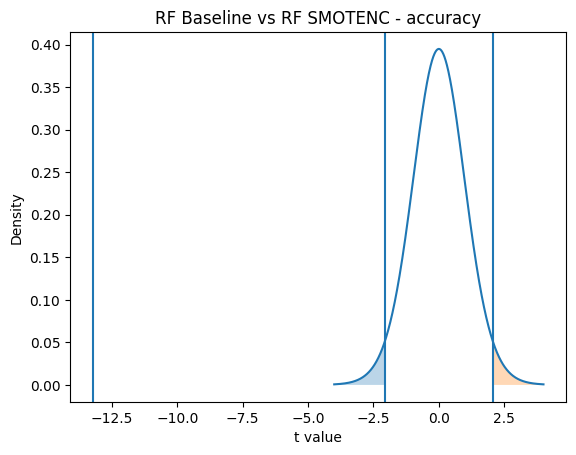

Model 1: RF Baseline
Model 2: RF SMOTENC
Metric : precision
t value: -54.17091390116764
p value: 1.314139224089798e-26
t critical: 2.0638985616280205


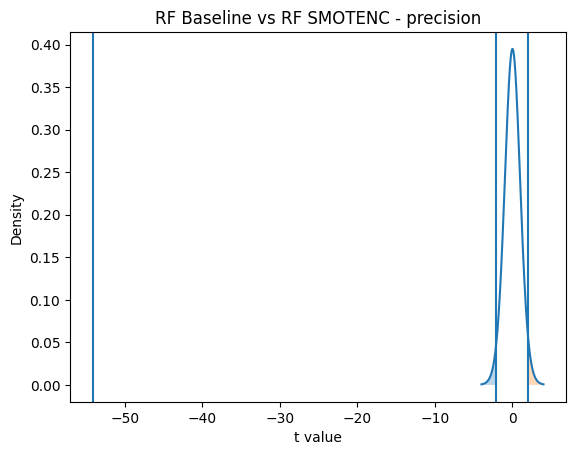

Model 1: RF Baseline
Model 2: RF SMOTENC
Metric : recall
t value: -51.77960081063415
p value: 3.8492884206257564e-26
t critical: 2.0638985616280205


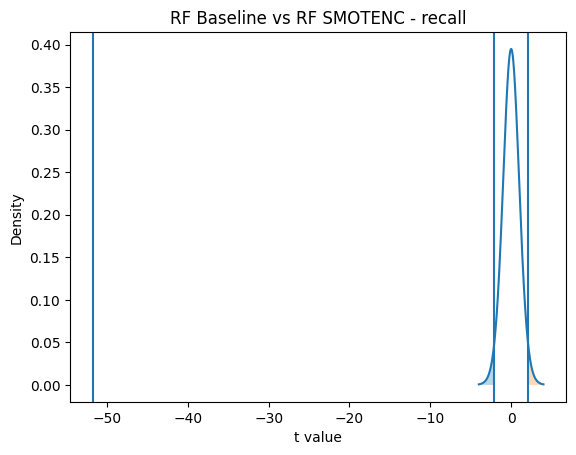

Model 1: RF Baseline
Model 2: RF SMOTENC
Metric : f1
t value: -57.39119804004022
p value: 3.320307759813981e-27
t critical: 2.0638985616280205


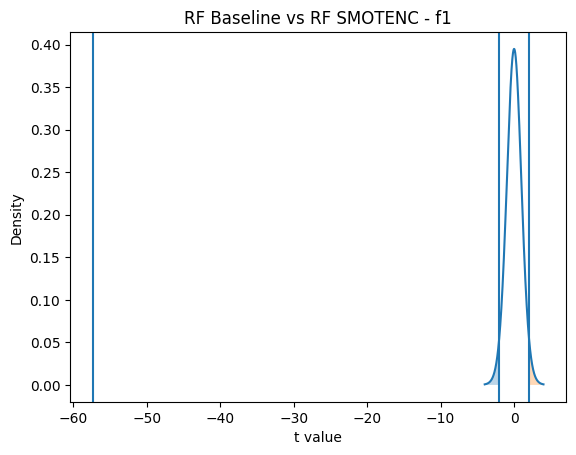

Model 1: RF Baseline
Model 2: RF SMOTENC
Metric : roc_auc
t value: -62.16131150532826
p value: 4.946911475754785e-28
t critical: 2.0638985616280205


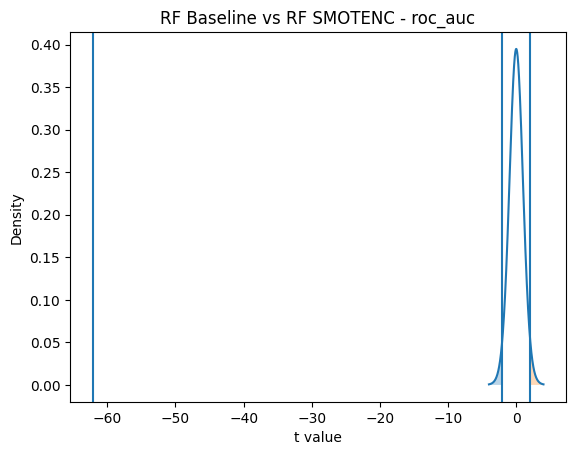

Model 1: RF Baseline
Model 2: RF CTGAN
Metric : accuracy
t value: -24.340500255642947
p value: 1.990384601275048e-18
t critical: 2.0638985616280205


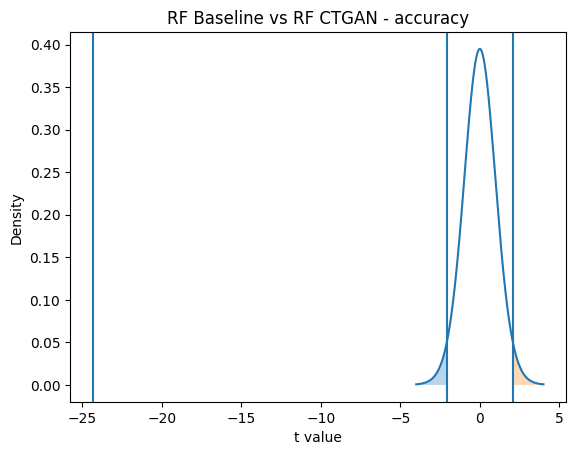

Model 1: RF Baseline
Model 2: RF CTGAN
Metric : precision
t value: -107.31490045712893
p value: 1.0557813316828862e-33
t critical: 2.0638985616280205


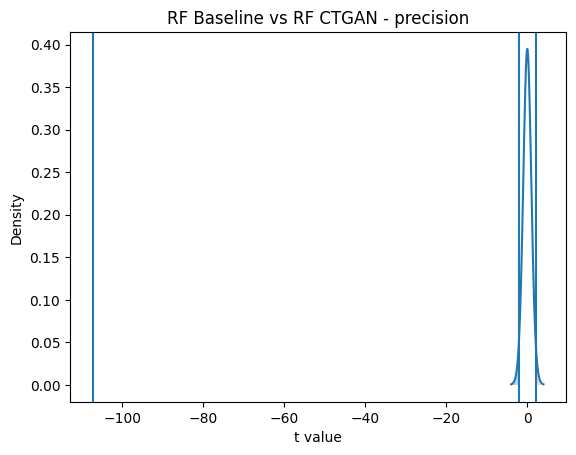

Model 1: RF Baseline
Model 2: RF CTGAN
Metric : recall
t value: -95.77771013746542
p value: 1.6084466825250577e-32
t critical: 2.0638985616280205


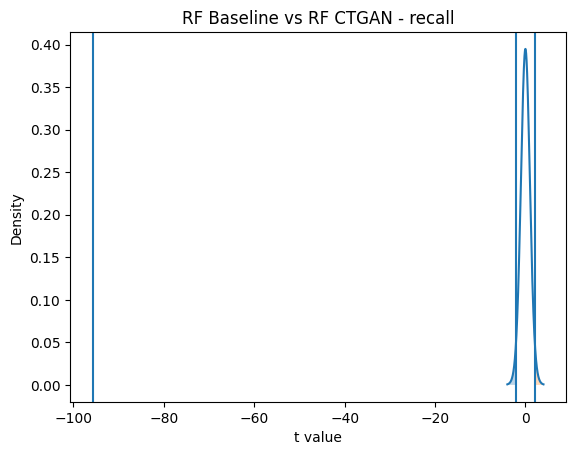

Model 1: RF Baseline
Model 2: RF CTGAN
Metric : f1
t value: -94.10874716491078
p value: 2.4499982121017522e-32
t critical: 2.0638985616280205


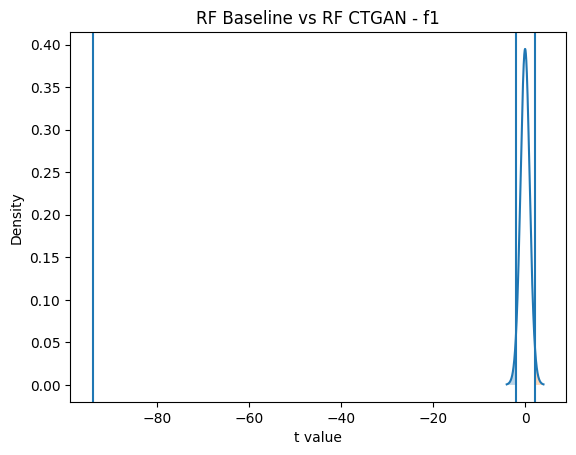

Model 1: RF Baseline
Model 2: RF CTGAN
Metric : roc_auc
t value: -127.76283125941153
p value: 1.617244731937606e-35
t critical: 2.0638985616280205


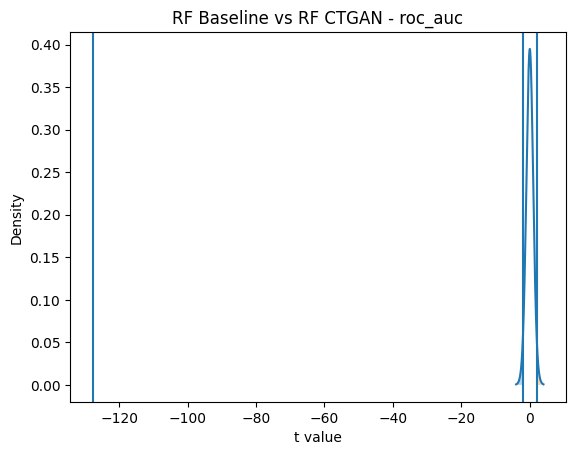

Model 1: RF Baseline
Model 2: RSCV RF Baseline
Metric : accuracy
t value: -11.904660835977209
p value: 1.4740145111143042e-11
t critical: 2.0638985616280205


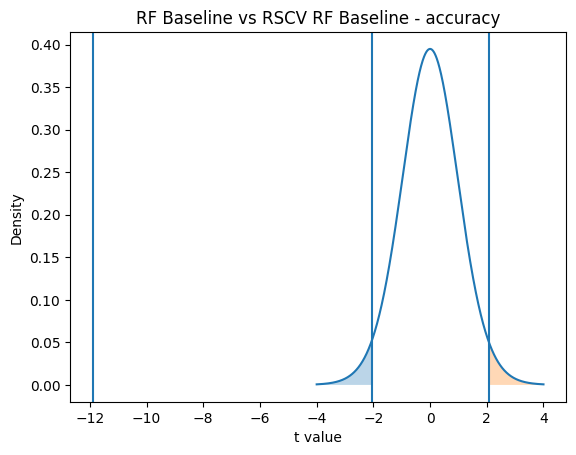

Model 1: RF Baseline
Model 2: RSCV RF Baseline
Metric : precision
t value: 1.006048643687119
p value: 0.3244282992066204
t critical: 2.0638985616280205


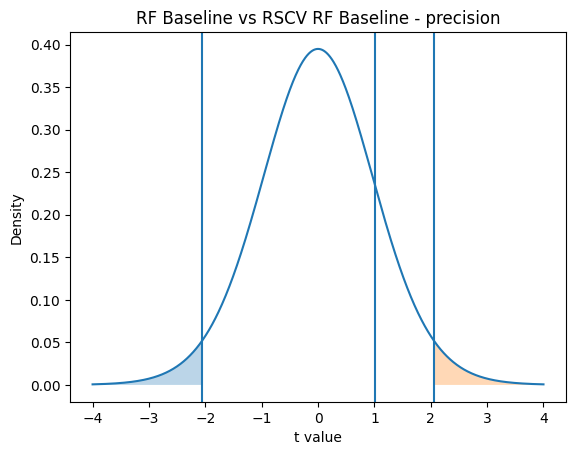

Model 1: RF Baseline
Model 2: RSCV RF Baseline
Metric : recall
t value: 2.361929538613797
p value: 0.02663290472585612
t critical: 2.0638985616280205


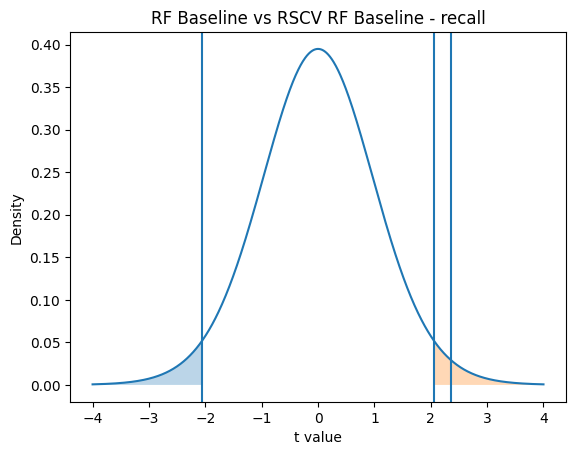

Model 1: RF Baseline
Model 2: RSCV RF Baseline
Metric : f1
t value: 22.951096700022145
p value: 7.714054585227784e-18
t critical: 2.0638985616280205


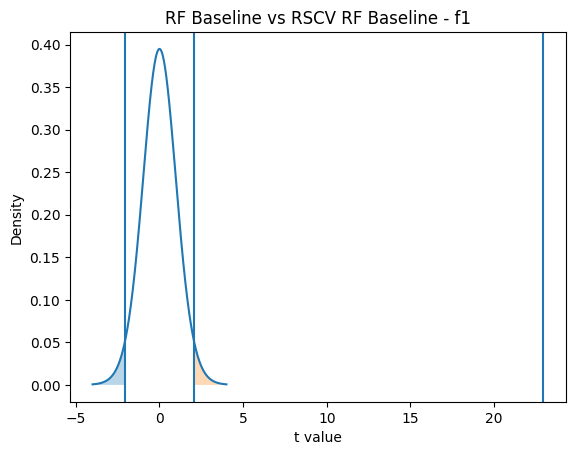

Model 1: RF Baseline
Model 2: RSCV RF Baseline
Metric : roc_auc
t value: 1.0932619754502053
p value: 0.28513119781986185
t critical: 2.0638985616280205


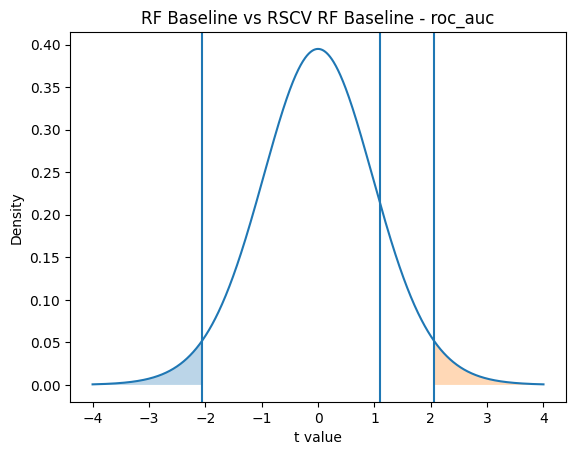

Model 1: RF Baseline
Model 2: RSCV RF SMOTENC
Metric : accuracy
t value: -15.958356314137333
p value: 2.7975332974944486e-14
t critical: 2.0638985616280205


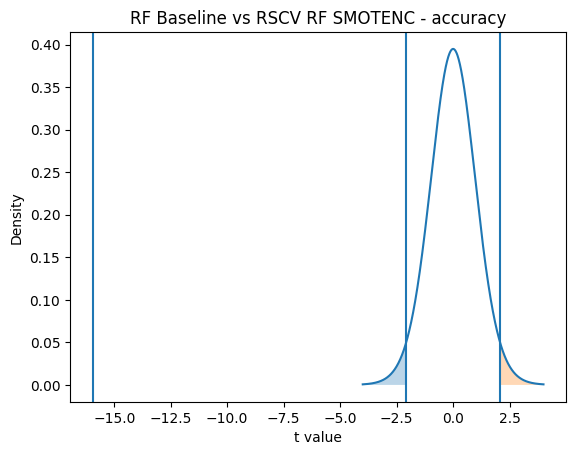

Model 1: RF Baseline
Model 2: RSCV RF SMOTENC
Metric : precision
t value: -70.78283932247547
p value: 2.226528070302861e-29
t critical: 2.0638985616280205


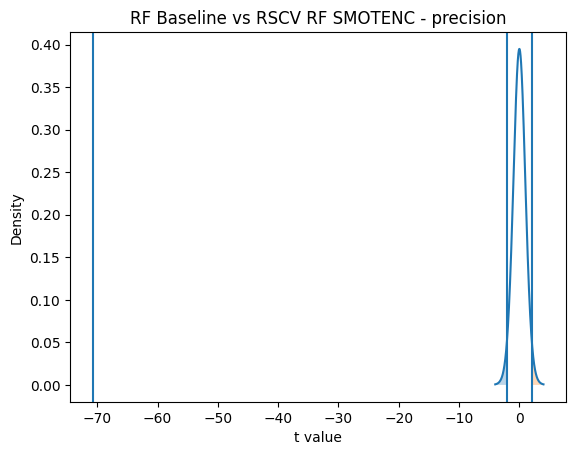

Model 1: RF Baseline
Model 2: RSCV RF SMOTENC
Metric : recall
t value: -71.53087076668562
p value: 1.7320182785454858e-29
t critical: 2.0638985616280205


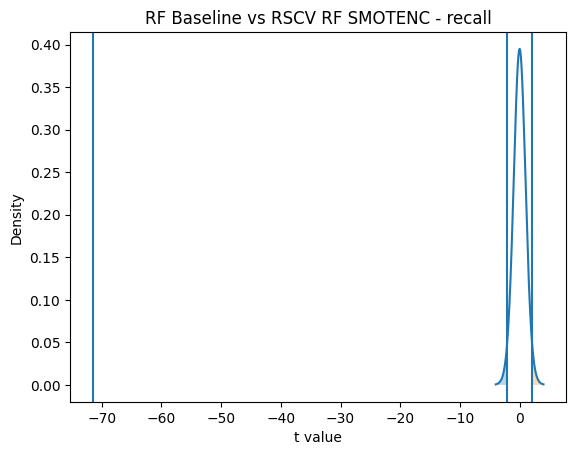

Model 1: RF Baseline
Model 2: RSCV RF SMOTENC
Metric : f1
t value: -61.82685949564664
p value: 5.62639404797268e-28
t critical: 2.0638985616280205


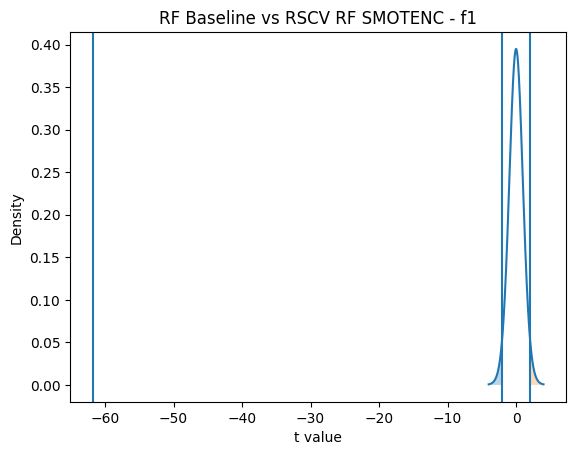

Model 1: RF Baseline
Model 2: RSCV RF SMOTENC
Metric : roc_auc
t value: -112.21330796481432
p value: 3.624431675572771e-34
t critical: 2.0638985616280205


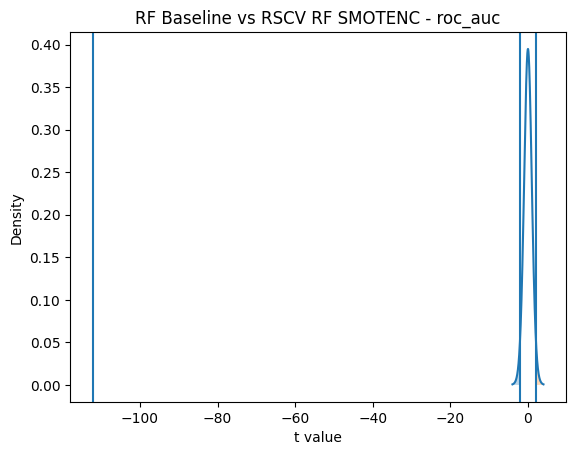

Model 1: RF Baseline
Model 2: RSCV RF CTGAN
Metric : accuracy
t value: -26.084575168682317
p value: 4.007903197655528e-19
t critical: 2.0638985616280205


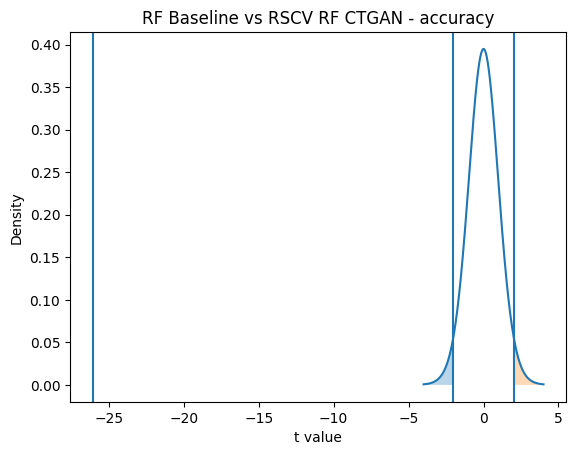

Model 1: RF Baseline
Model 2: RSCV RF CTGAN
Metric : precision
t value: -155.4175111505205
p value: 1.475269614612614e-37
t critical: 2.0638985616280205


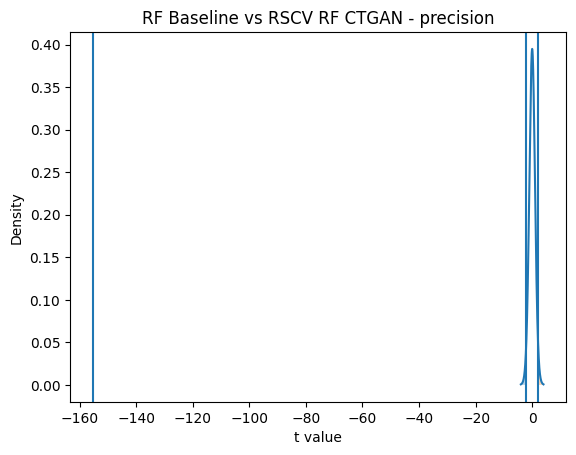

Model 1: RF Baseline
Model 2: RSCV RF CTGAN
Metric : recall
t value: -148.82054518037918
p value: 4.173592730769654e-37
t critical: 2.0638985616280205


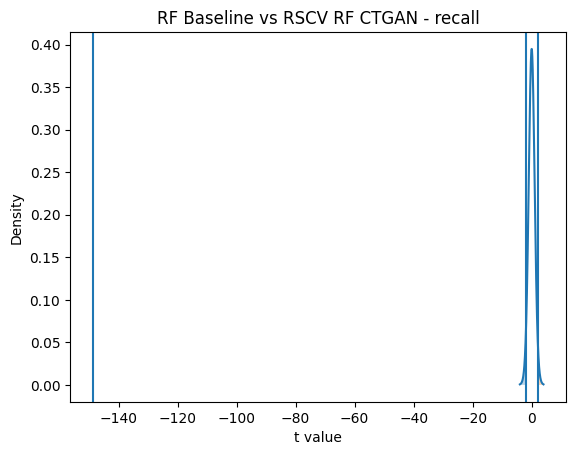

Model 1: RF Baseline
Model 2: RSCV RF CTGAN
Metric : f1
t value: -132.87704962460586
p value: 6.313067166112392e-36
t critical: 2.0638985616280205


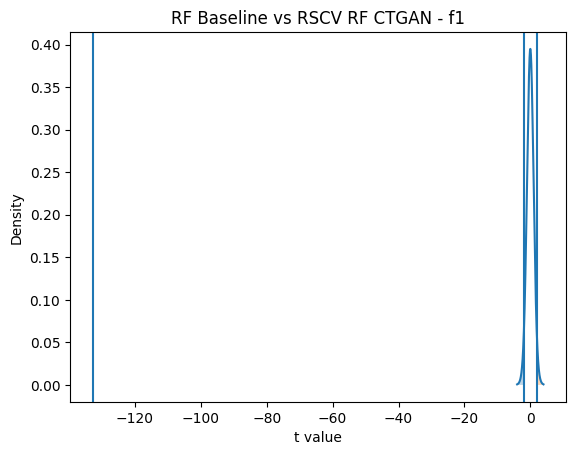

Model 1: RF Baseline
Model 2: RSCV RF CTGAN
Metric : roc_auc
t value: -161.38685414683417
p value: 5.975793988102647e-38
t critical: 2.0638985616280205


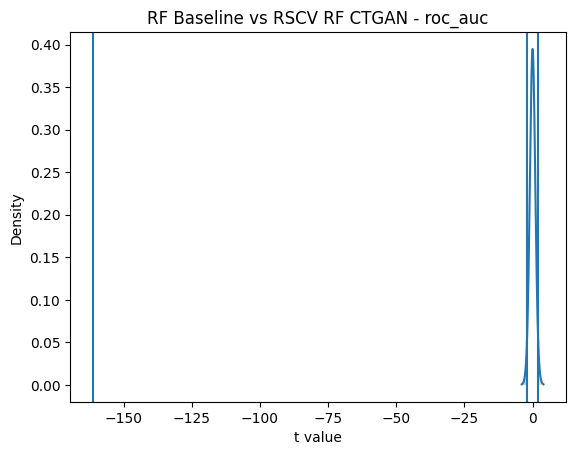

Model 1: RF Baseline
Model 2: Bagging Baseline
Metric : accuracy
t value: -3.7298228647840923
p value: 0.0010397707208596263
t critical: 2.0638985616280205


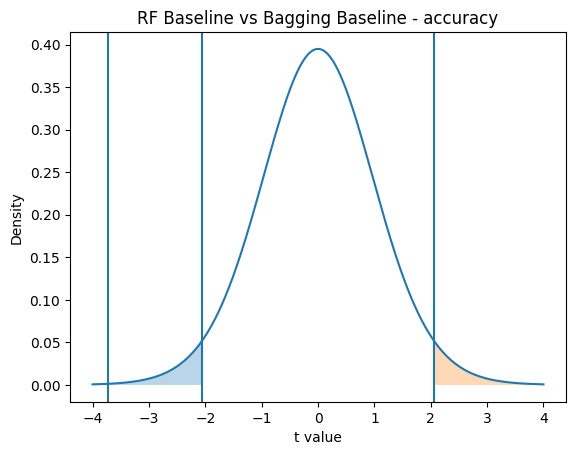

Model 1: RF Baseline
Model 2: Bagging Baseline
Metric : precision
t value: -0.6761750368221001
p value: 0.5053940294272494
t critical: 2.0638985616280205


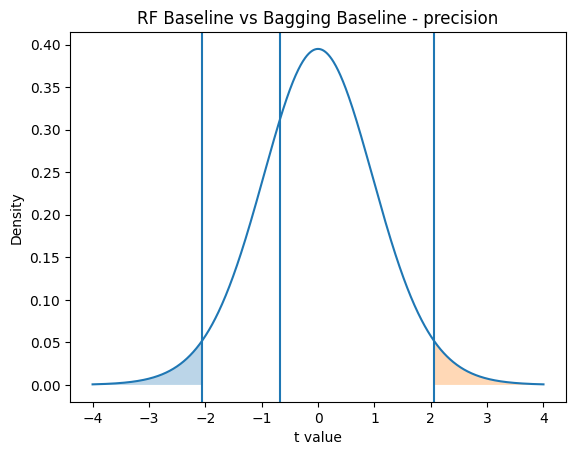

Model 1: RF Baseline
Model 2: Bagging Baseline
Metric : recall
t value: -0.968387662803689
p value: 0.3425091680830904
t critical: 2.0638985616280205


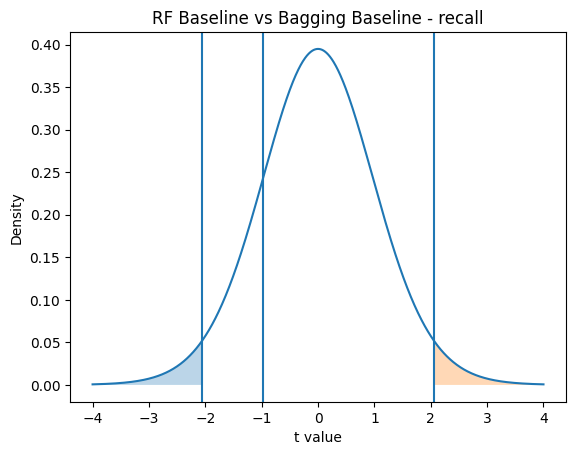

Model 1: RF Baseline
Model 2: Bagging Baseline
Metric : f1
t value: 2.2510096034215508
p value: 0.03381571241390904
t critical: 2.0638985616280205


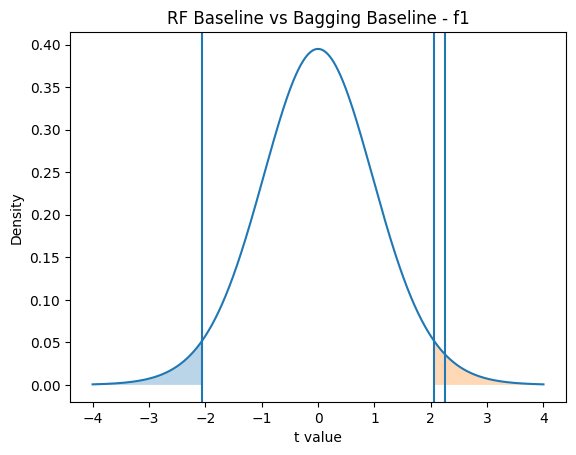

Model 1: RF Baseline
Model 2: Bagging Baseline
Metric : roc_auc
t value: -5.107823438854167
p value: 3.1638086260093474e-05
t critical: 2.0638985616280205


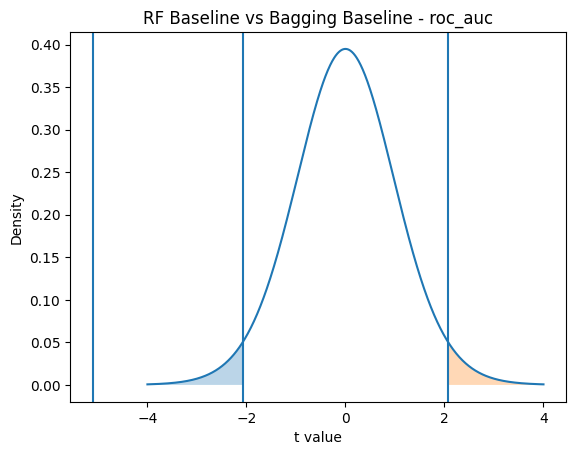

Model 1: RF Baseline
Model 2: Bagging SMOTENC
Metric : accuracy
t value: -17.762705109664605
p value: 2.5954732881078557e-15
t critical: 2.0638985616280205


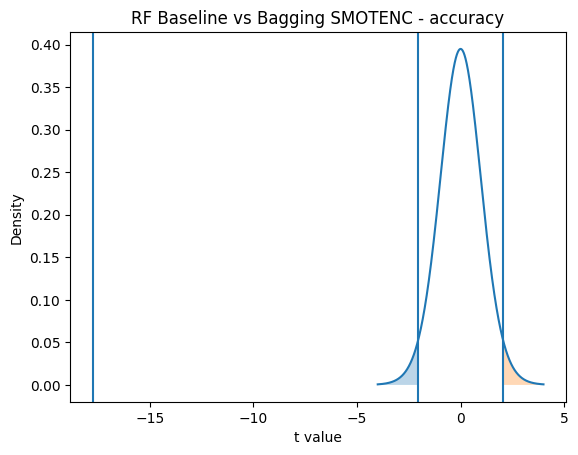

Model 1: RF Baseline
Model 2: Bagging SMOTENC
Metric : precision
t value: -106.72505452322186
p value: 1.2047747872881396e-33
t critical: 2.0638985616280205


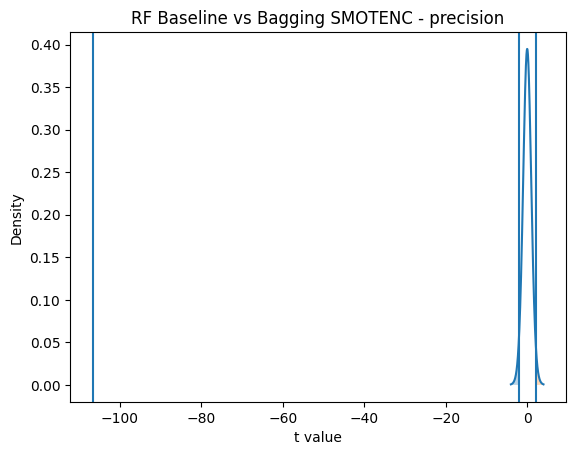

Model 1: RF Baseline
Model 2: Bagging SMOTENC
Metric : recall
t value: -99.81847680324503
p value: 5.98037340453564e-33
t critical: 2.0638985616280205


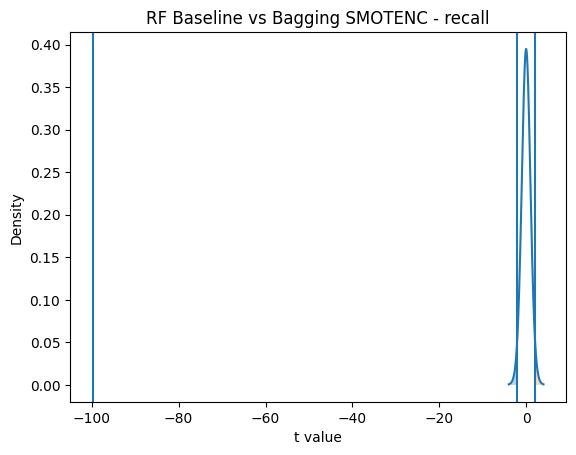

Model 1: RF Baseline
Model 2: Bagging SMOTENC
Metric : f1
t value: -94.98044874045078
p value: 1.964770423799958e-32
t critical: 2.0638985616280205


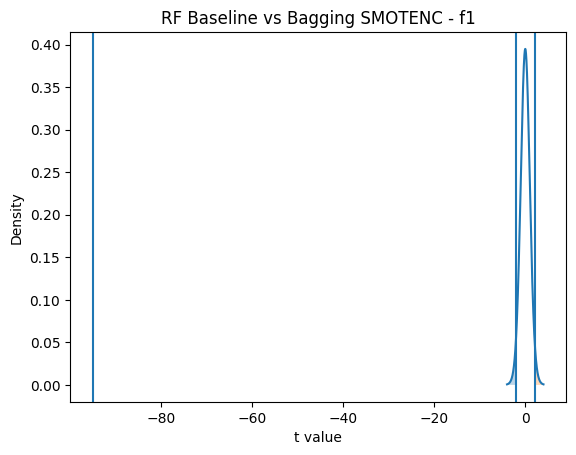

Model 1: RF Baseline
Model 2: Bagging SMOTENC
Metric : roc_auc
t value: -118.04831913376596
p value: 1.0759411235255936e-34
t critical: 2.0638985616280205


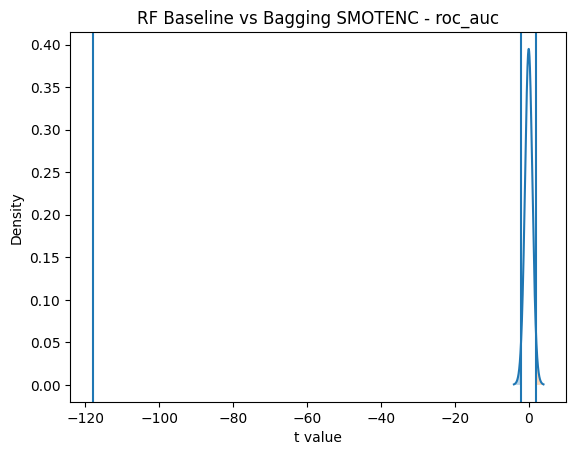

Model 1: RF Baseline
Model 2: Bagging CTGAN
Metric : accuracy
t value: -28.503697352319513
p value: 5.0854490062735394e-20
t critical: 2.0638985616280205


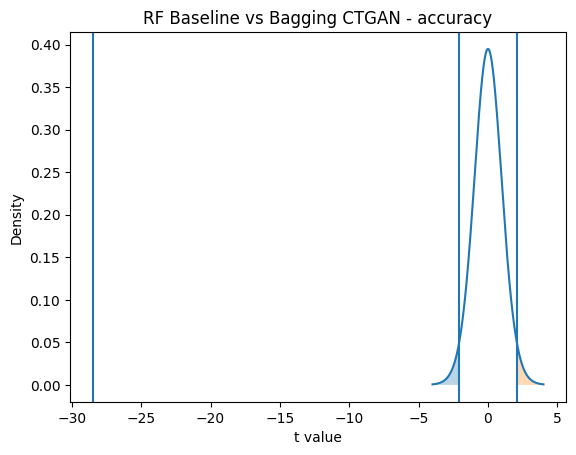

Model 1: RF Baseline
Model 2: Bagging CTGAN
Metric : precision
t value: -203.57394122992892
p value: 2.278311693470033e-40
t critical: 2.0638985616280205


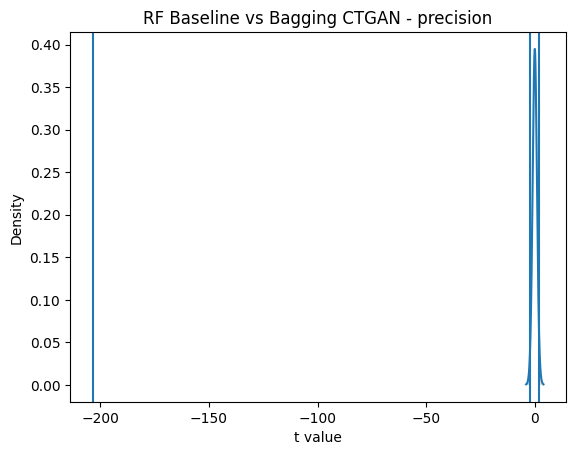

Model 1: RF Baseline
Model 2: Bagging CTGAN
Metric : recall
t value: -190.65957280682227
p value: 1.0973182398823251e-39
t critical: 2.0638985616280205


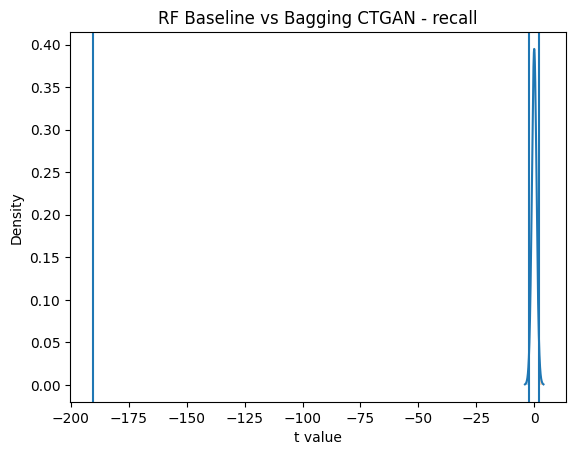

Model 1: RF Baseline
Model 2: Bagging CTGAN
Metric : f1
t value: -165.22686779820322
p value: 3.400221652712569e-38
t critical: 2.0638985616280205


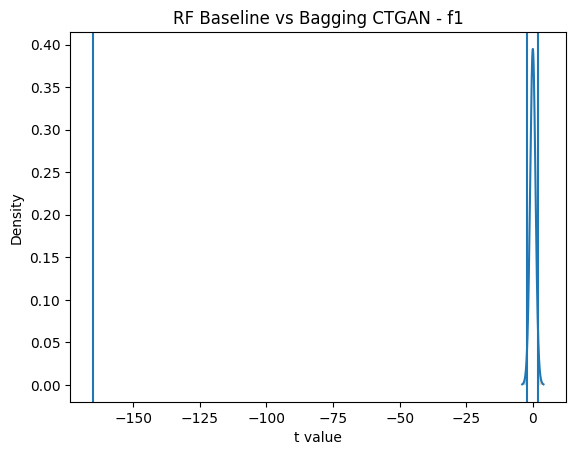

Model 1: RF Baseline
Model 2: Bagging CTGAN
Metric : roc_auc
t value: -177.3002165042294
p value: 6.266138597873657e-39
t critical: 2.0638985616280205


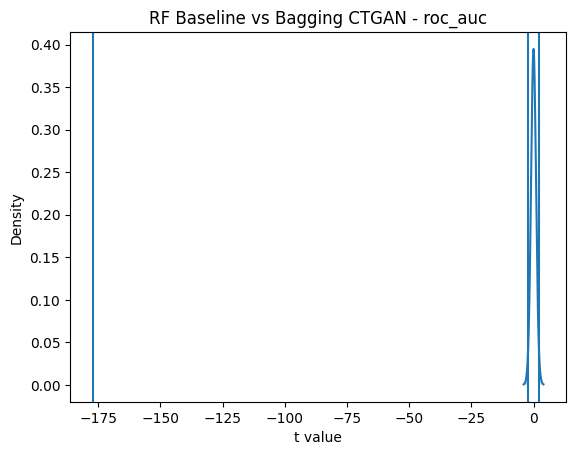

Model 1: RF Baseline
Model 2: RSCV Bagging Baseline
Metric : accuracy
t value: -11.88516408399932
p value: 1.524763915116044e-11
t critical: 2.0638985616280205


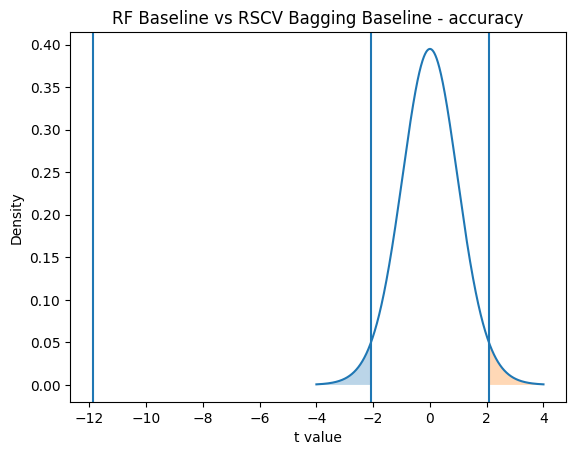

Model 1: RF Baseline
Model 2: RSCV Bagging Baseline
Metric : precision
t value: -4.073494414352403
p value: 0.0004375302205477648
t critical: 2.0638985616280205


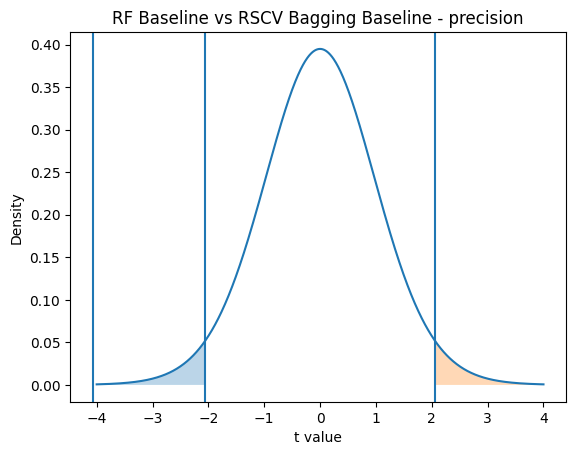

Model 1: RF Baseline
Model 2: RSCV Bagging Baseline
Metric : recall
t value: -0.4762694723097135
p value: 0.6381897083074726
t critical: 2.0638985616280205


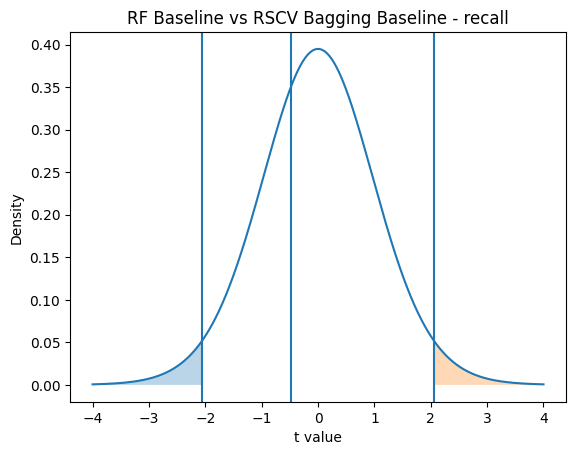

Model 1: RF Baseline
Model 2: RSCV Bagging Baseline
Metric : f1
t value: 13.062468395266542
p value: 2.11659213942891e-12
t critical: 2.0638985616280205


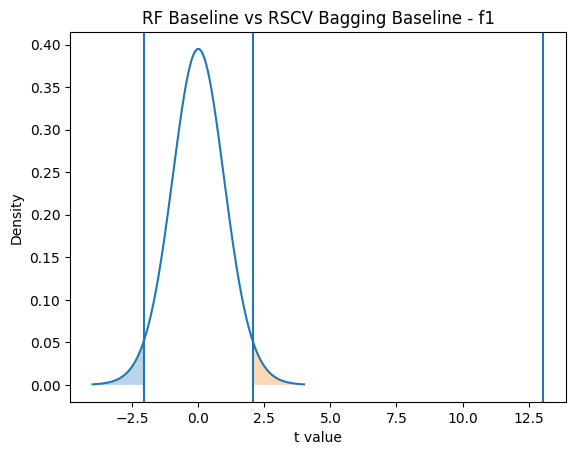

Model 1: RF Baseline
Model 2: RSCV Bagging Baseline
Metric : roc_auc
t value: -0.7664970738681749
p value: 0.45085473790772246
t critical: 2.0638985616280205


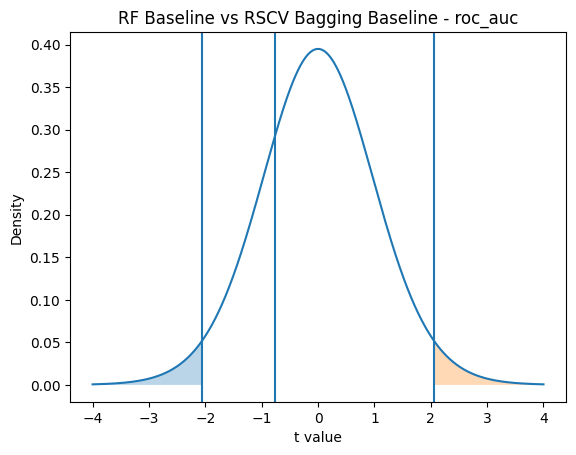

Model 1: RF Baseline
Model 2: RSCV Bagging SMOTENC
Metric : accuracy
t value: -15.936690810666326
p value: 2.8824457175080417e-14
t critical: 2.0638985616280205


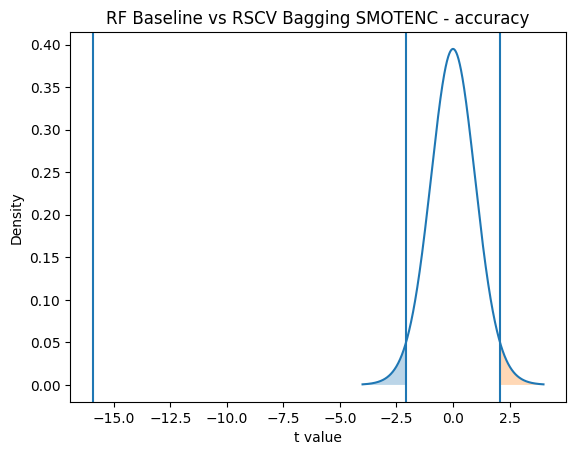

Model 1: RF Baseline
Model 2: RSCV Bagging SMOTENC
Metric : precision
t value: -83.55162951335822
p value: 4.224059982651379e-31
t critical: 2.0638985616280205


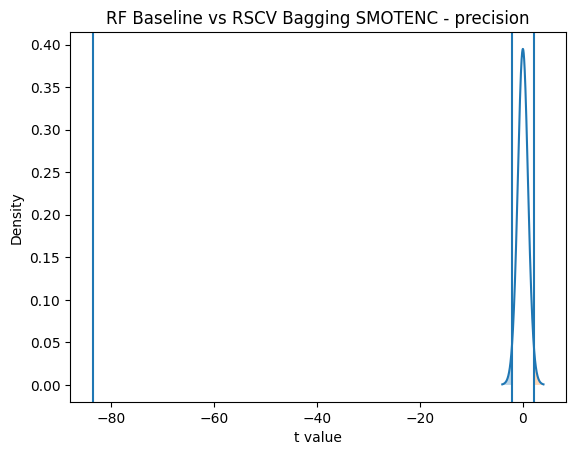

Model 1: RF Baseline
Model 2: RSCV Bagging SMOTENC
Metric : recall
t value: -83.7116298114499
p value: 4.0351036270025415e-31
t critical: 2.0638985616280205


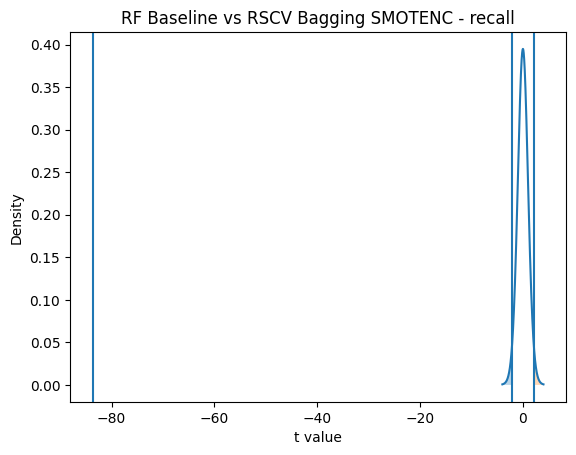

Model 1: RF Baseline
Model 2: RSCV Bagging SMOTENC
Metric : f1
t value: -72.01992625105139
p value: 1.471801653902097e-29
t critical: 2.0638985616280205


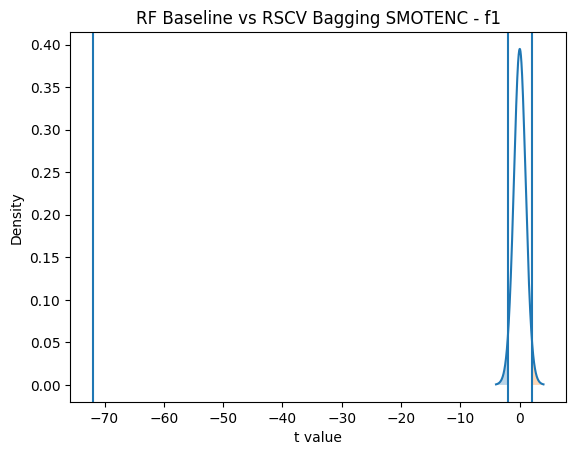

Model 1: RF Baseline
Model 2: RSCV Bagging SMOTENC
Metric : roc_auc
t value: -109.65297930401091
p value: 6.300338159688751e-34
t critical: 2.0638985616280205


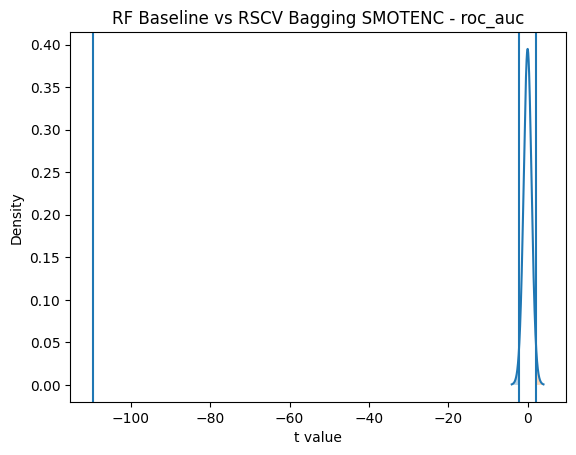

Model 1: RF Baseline
Model 2: RSCV Bagging CTGAN
Metric : accuracy
t value: -26.324073046195334
p value: 3.2415100958740625e-19
t critical: 2.0638985616280205


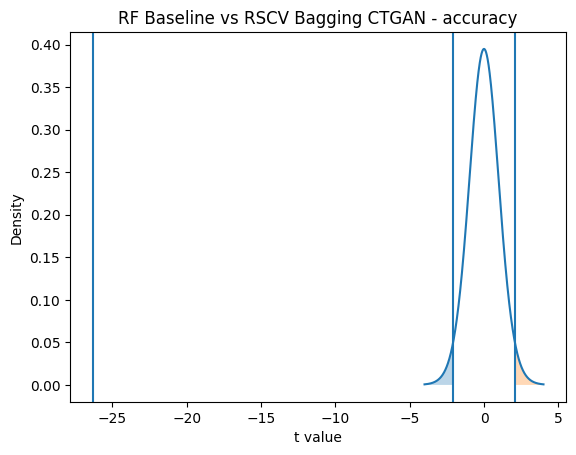

Model 1: RF Baseline
Model 2: RSCV Bagging CTGAN
Metric : precision
t value: -161.30818985671507
p value: 6.046065368181353e-38
t critical: 2.0638985616280205


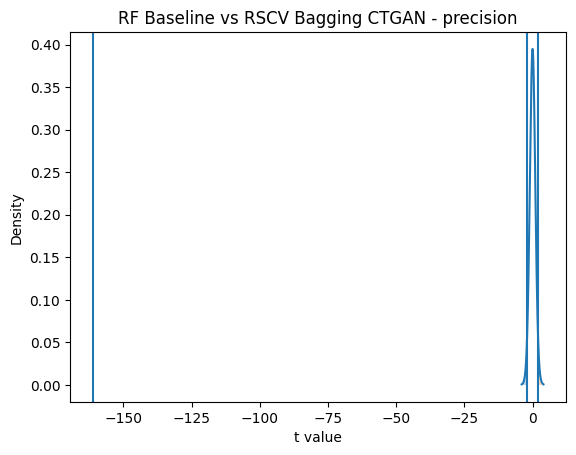

Model 1: RF Baseline
Model 2: RSCV Bagging CTGAN
Metric : recall
t value: -150.96028887911274
p value: 2.963922902766985e-37
t critical: 2.0638985616280205


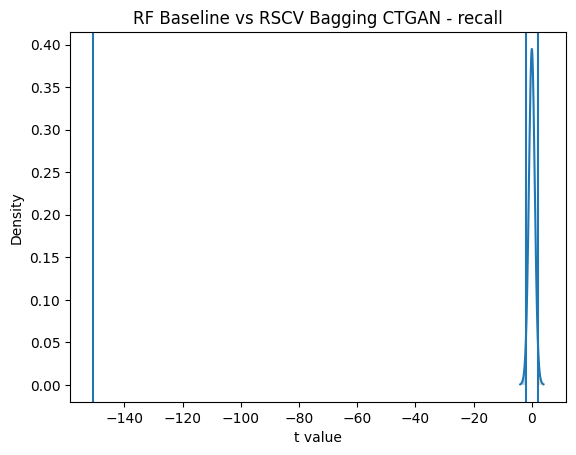

Model 1: RF Baseline
Model 2: RSCV Bagging CTGAN
Metric : f1
t value: -154.17278774942295
p value: 1.788974480291496e-37
t critical: 2.0638985616280205


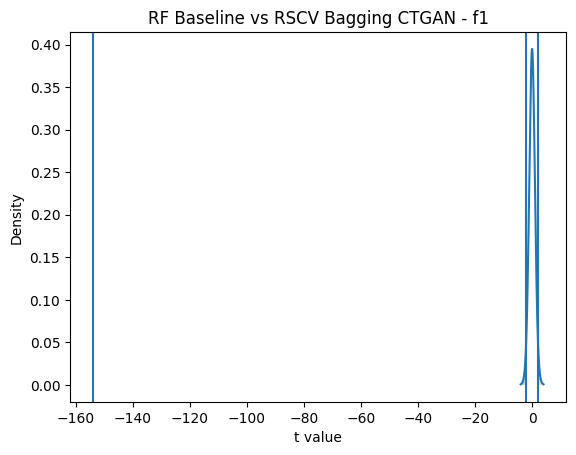

Model 1: RF Baseline
Model 2: RSCV Bagging CTGAN
Metric : roc_auc
t value: -161.85470119073435
p value: 5.575070395476173e-38
t critical: 2.0638985616280205


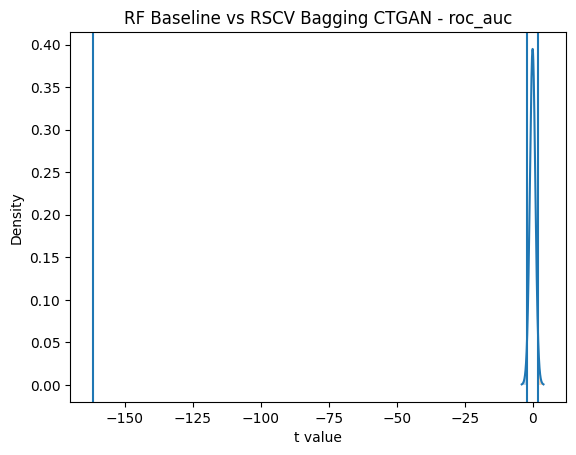

Model 1: RF SMOTENC
Model 2: RF CTGAN
Metric : accuracy
t value: -42.2370735246178
p value: 4.8554378319629206e-24
t critical: 2.0638985616280205


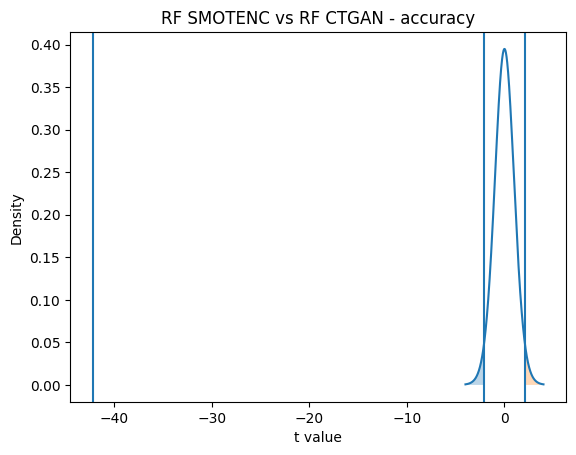

Model 1: RF SMOTENC
Model 2: RF CTGAN
Metric : precision
t value: -44.56529687748005
p value: 1.3605999010219715e-24
t critical: 2.0638985616280205


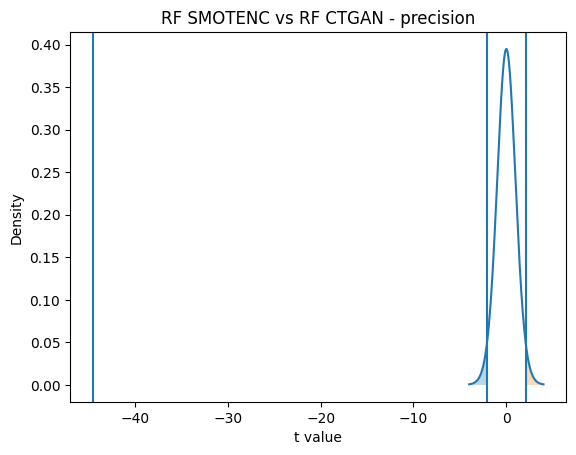

Model 1: RF SMOTENC
Model 2: RF CTGAN
Metric : recall
t value: -42.23428882667543
p value: 4.863028813084093e-24
t critical: 2.0638985616280205


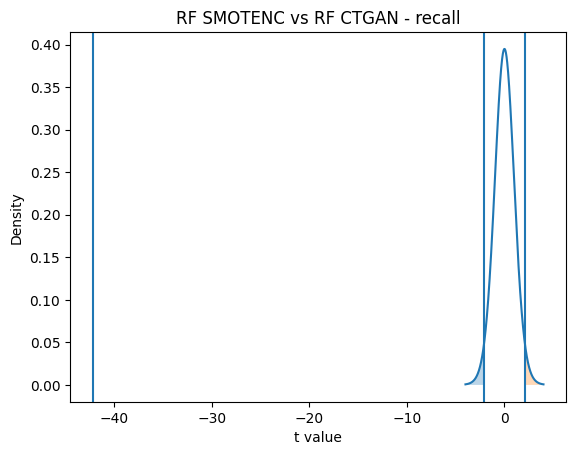

Model 1: RF SMOTENC
Model 2: RF CTGAN
Metric : f1
t value: -41.81612680737535
p value: 6.155777294141026e-24
t critical: 2.0638985616280205


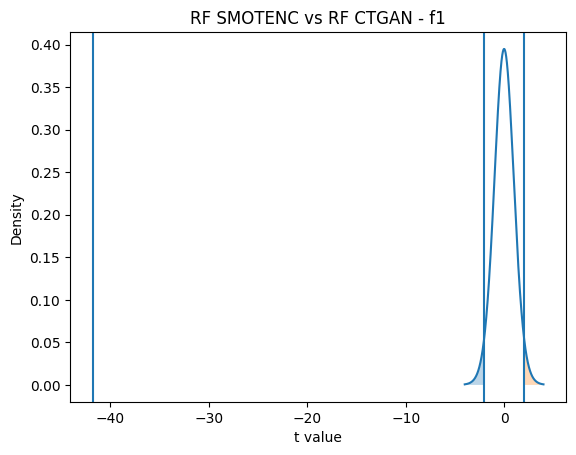

Model 1: RF SMOTENC
Model 2: RF CTGAN
Metric : roc_auc
t value: -39.865043232334884
p value: 1.9077481426021854e-23
t critical: 2.0638985616280205


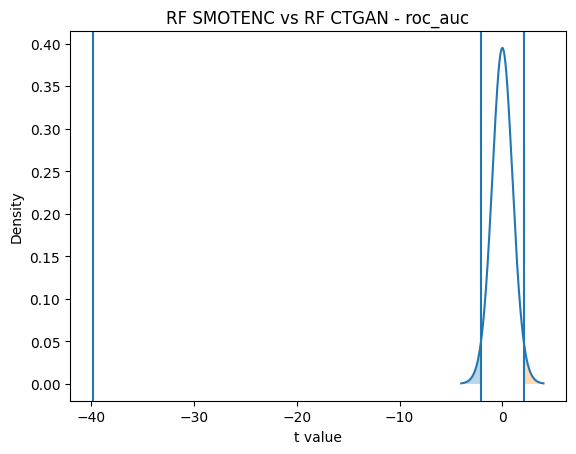

Model 1: RF SMOTENC
Model 2: RSCV RF Baseline
Metric : accuracy
t value: 6.095240141905715
p value: 2.6971383547784487e-06
t critical: 2.0638985616280205


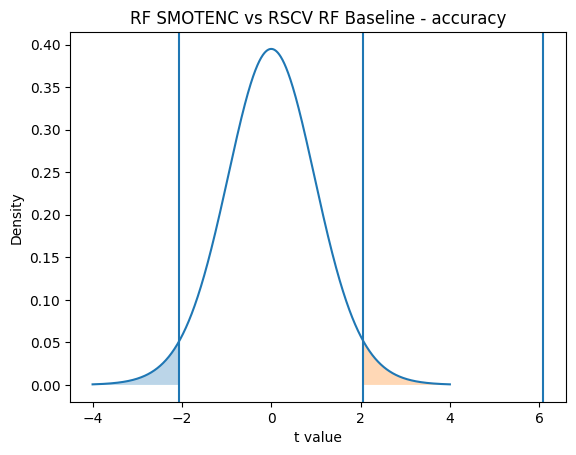

Model 1: RF SMOTENC
Model 2: RSCV RF Baseline
Metric : precision
t value: 10.85260122787795
p value: 9.714778751567032e-11
t critical: 2.0638985616280205


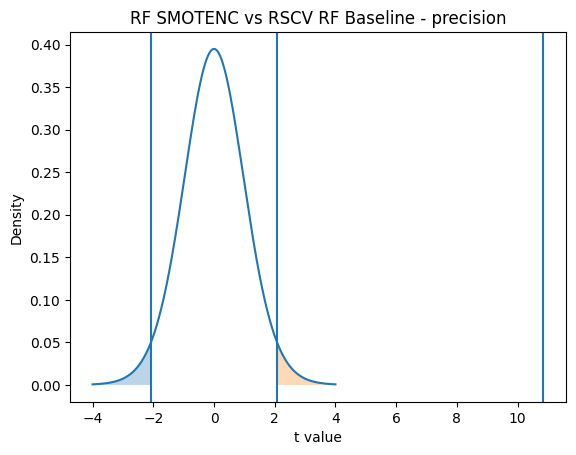

Model 1: RF SMOTENC
Model 2: RSCV RF Baseline
Metric : recall
t value: 59.1118884305842
p value: 1.6419103026563407e-27
t critical: 2.0638985616280205


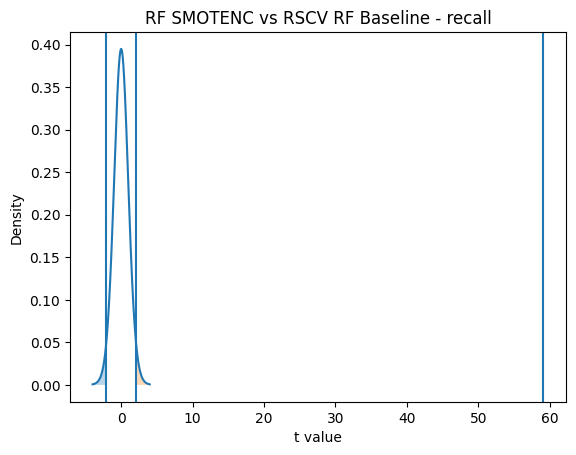

Model 1: RF SMOTENC
Model 2: RSCV RF Baseline
Metric : f1
t value: 77.71760058933064
p value: 2.3851151174063478e-30
t critical: 2.0638985616280205


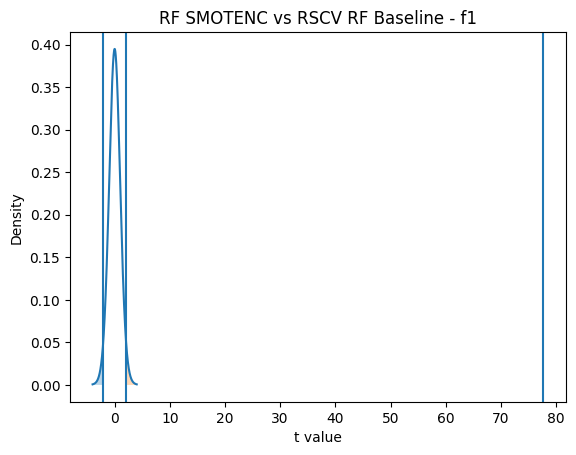

Model 1: RF SMOTENC
Model 2: RSCV RF Baseline
Metric : roc_auc
t value: 54.143072404829695
p value: 1.3303255749268698e-26
t critical: 2.0638985616280205


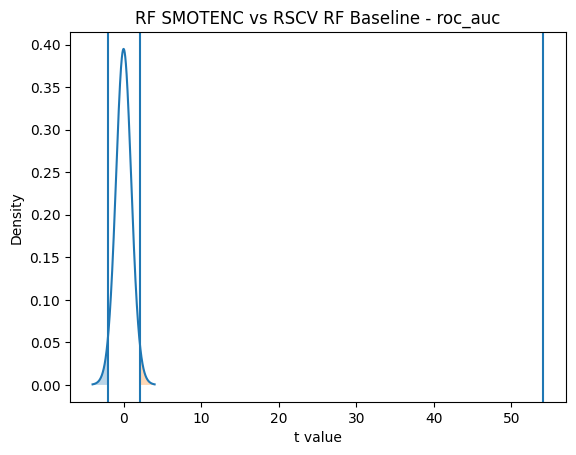

Model 1: RF SMOTENC
Model 2: RSCV RF SMOTENC
Metric : accuracy
t value: -6.521806001886385
p value: 9.582634457297124e-07
t critical: 2.0638985616280205


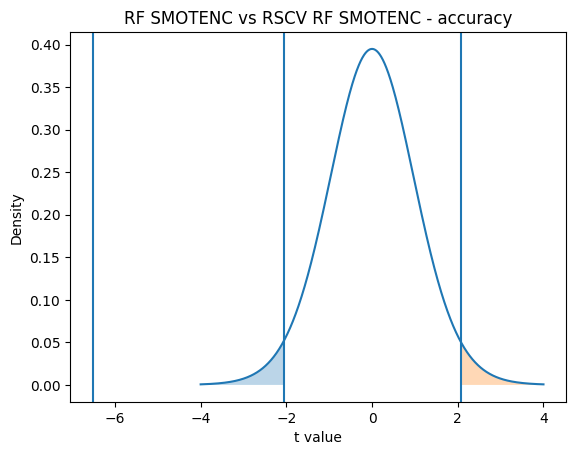

Model 1: RF SMOTENC
Model 2: RSCV RF SMOTENC
Metric : precision
t value: -6.46916680280071
p value: 1.0875815255480409e-06
t critical: 2.0638985616280205


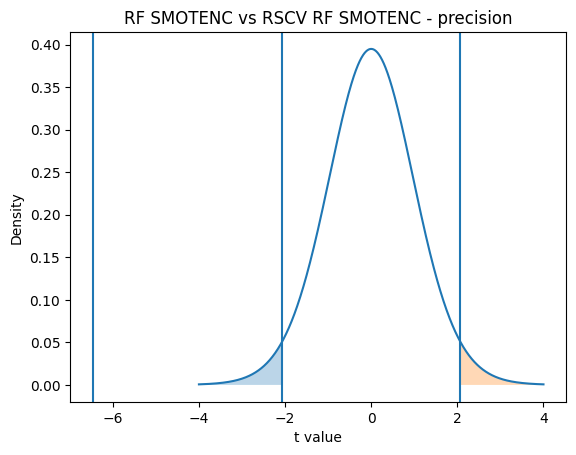

Model 1: RF SMOTENC
Model 2: RSCV RF SMOTENC
Metric : recall
t value: -6.568605784278811
p value: 8.564955682006828e-07
t critical: 2.0638985616280205


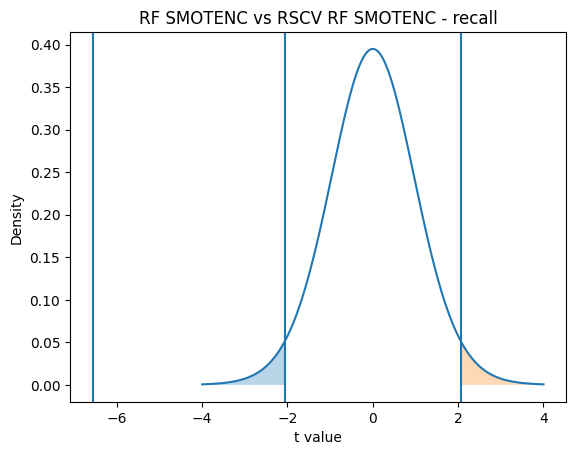

Model 1: RF SMOTENC
Model 2: RSCV RF SMOTENC
Metric : f1
t value: -6.526576011921566
p value: 9.473490418082945e-07
t critical: 2.0638985616280205


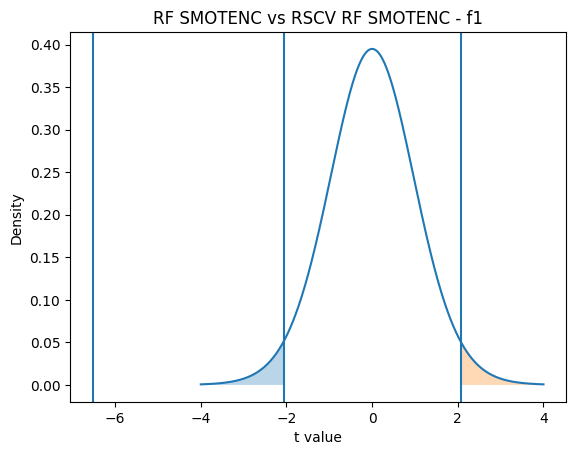

Model 1: RF SMOTENC
Model 2: RSCV RF SMOTENC
Metric : roc_auc
t value: -7.271876913377728
p value: 1.6369485394074847e-07
t critical: 2.0638985616280205


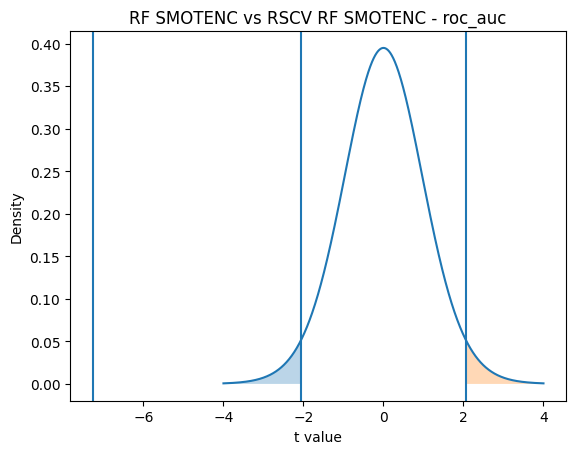

Model 1: RF SMOTENC
Model 2: RSCV RF CTGAN
Metric : accuracy
t value: -35.715892459007385
p value: 2.5571955204621704e-22
t critical: 2.0638985616280205


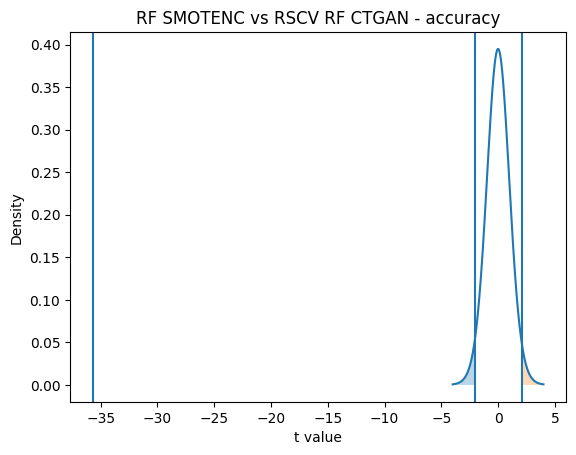

Model 1: RF SMOTENC
Model 2: RSCV RF CTGAN
Metric : precision
t value: -35.92164874810753
p value: 2.2332999250146816e-22
t critical: 2.0638985616280205


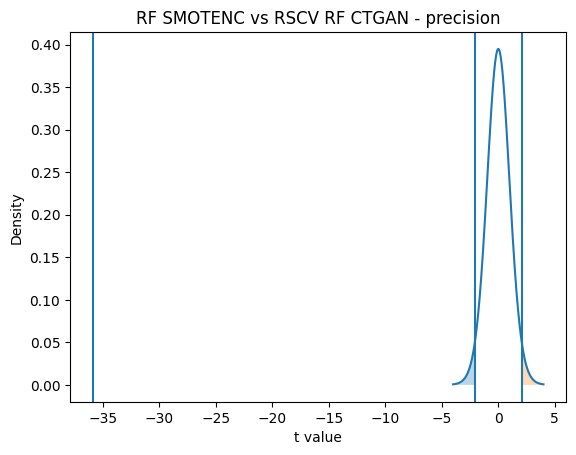

Model 1: RF SMOTENC
Model 2: RSCV RF CTGAN
Metric : recall
t value: -35.679988121297555
p value: 2.6185503282386604e-22
t critical: 2.0638985616280205


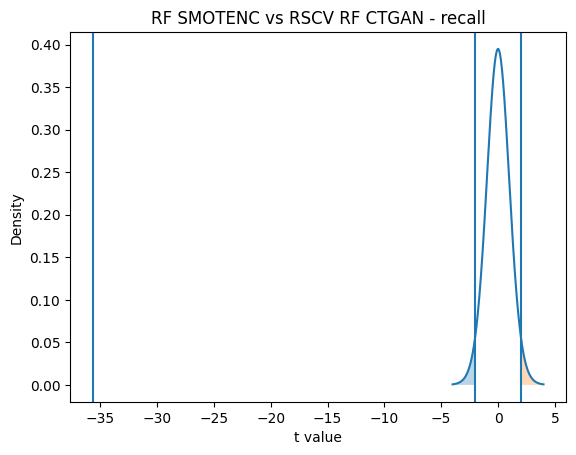

Model 1: RF SMOTENC
Model 2: RSCV RF CTGAN
Metric : f1
t value: -35.664937024017654
p value: 2.6447242444501133e-22
t critical: 2.0638985616280205


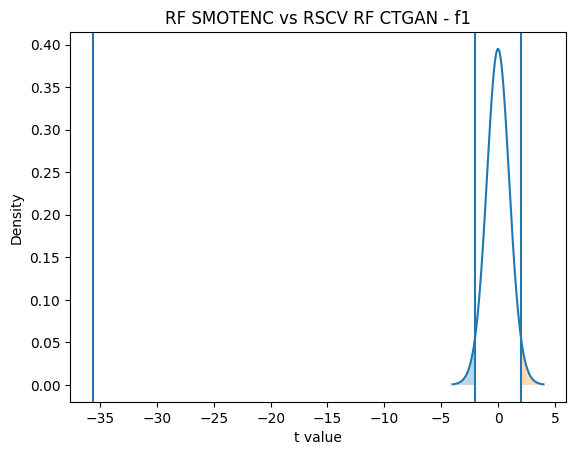

Model 1: RF SMOTENC
Model 2: RSCV RF CTGAN
Metric : roc_auc
t value: -34.60384636095717
p value: 5.387844784421735e-22
t critical: 2.0638985616280205


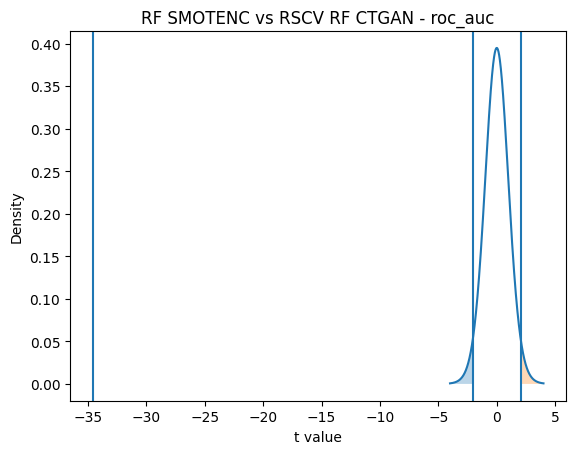

Model 1: RF SMOTENC
Model 2: Bagging Baseline
Metric : accuracy
t value: 6.585928233641984
p value: 8.216855770758774e-07
t critical: 2.0638985616280205


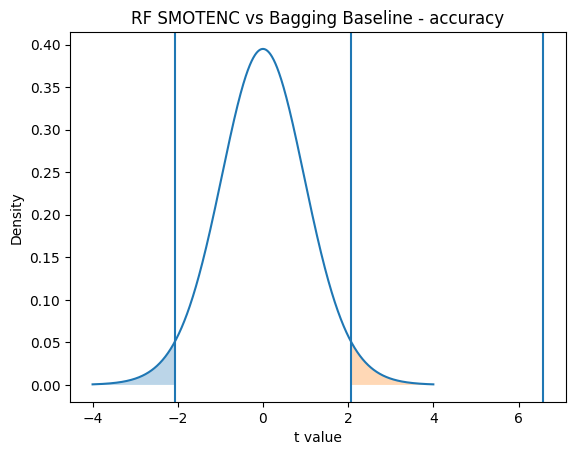

Model 1: RF SMOTENC
Model 2: Bagging Baseline
Metric : precision
t value: 14.400216517627182
p value: 2.630958652962025e-13
t critical: 2.0638985616280205


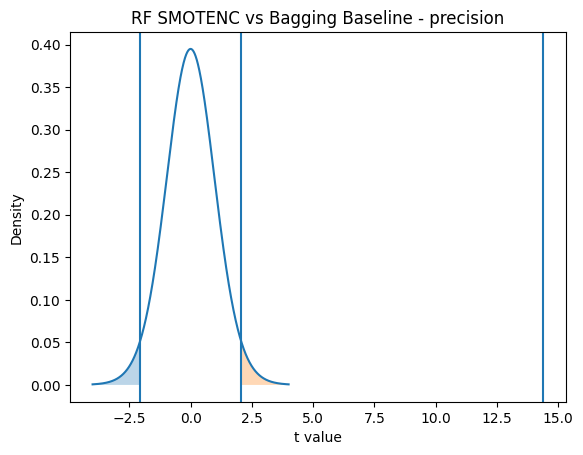

Model 1: RF SMOTENC
Model 2: Bagging Baseline
Metric : recall
t value: 46.81799621791541
p value: 4.220545320334611e-25
t critical: 2.0638985616280205


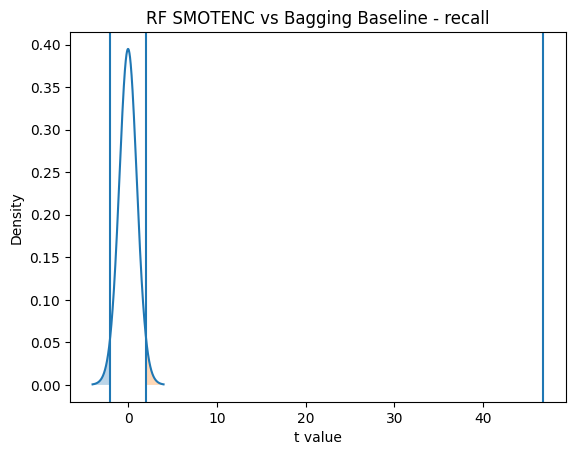

Model 1: RF SMOTENC
Model 2: Bagging Baseline
Metric : f1
t value: 30.048417150056167
p value: 1.4813726097847398e-20
t critical: 2.0638985616280205


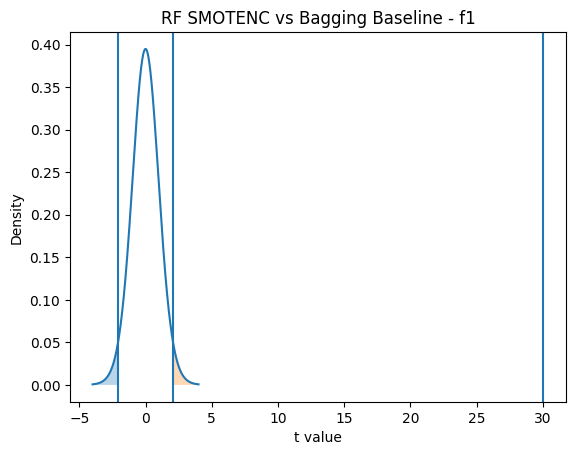

Model 1: RF SMOTENC
Model 2: Bagging Baseline
Metric : roc_auc
t value: 59.094401965324714
p value: 1.6535335066748973e-27
t critical: 2.0638985616280205


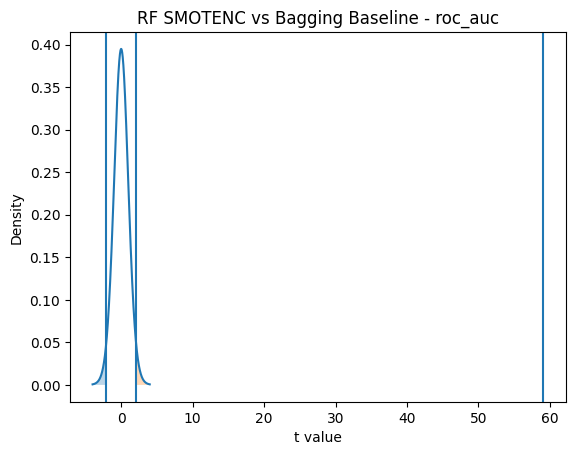

Model 1: RF SMOTENC
Model 2: Bagging SMOTENC
Metric : accuracy
t value: -8.55723201176758
p value: 9.390303513055788e-09
t critical: 2.0638985616280205


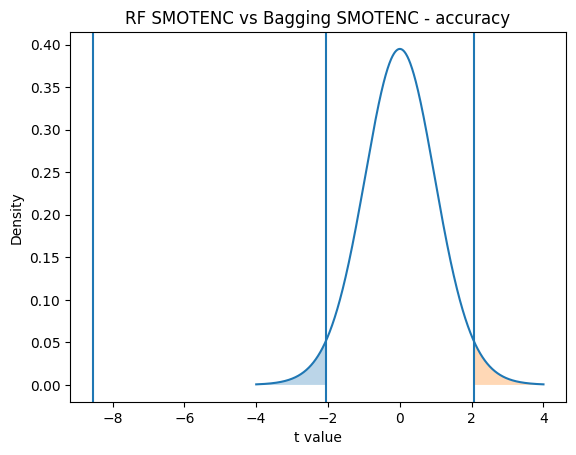

Model 1: RF SMOTENC
Model 2: Bagging SMOTENC
Metric : precision
t value: -8.627424547443301
p value: 8.084148312759945e-09
t critical: 2.0638985616280205


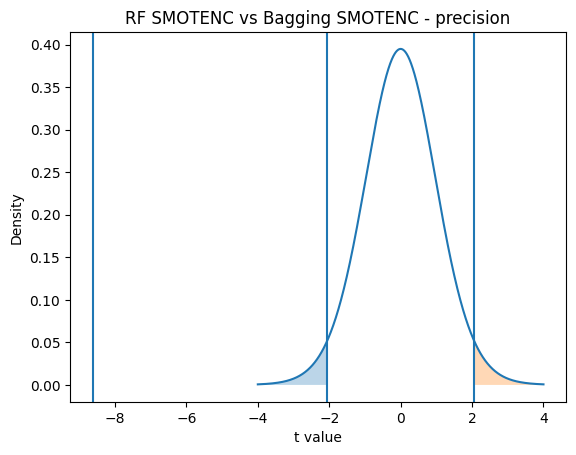

Model 1: RF SMOTENC
Model 2: Bagging SMOTENC
Metric : recall
t value: -8.557232011767589
p value: 9.39030351305562e-09
t critical: 2.0638985616280205


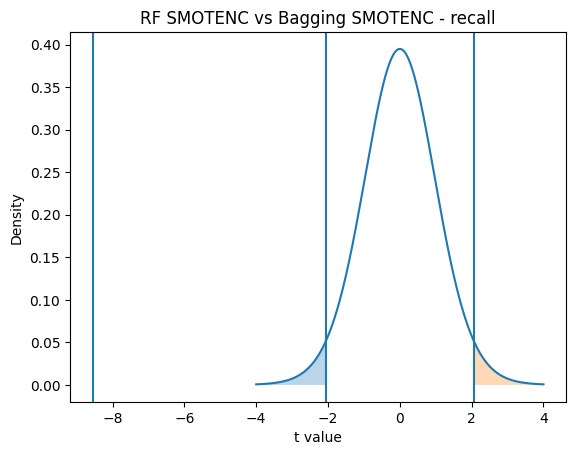

Model 1: RF SMOTENC
Model 2: Bagging SMOTENC
Metric : f1
t value: -8.540403141759446
p value: 9.734565243264571e-09
t critical: 2.0638985616280205


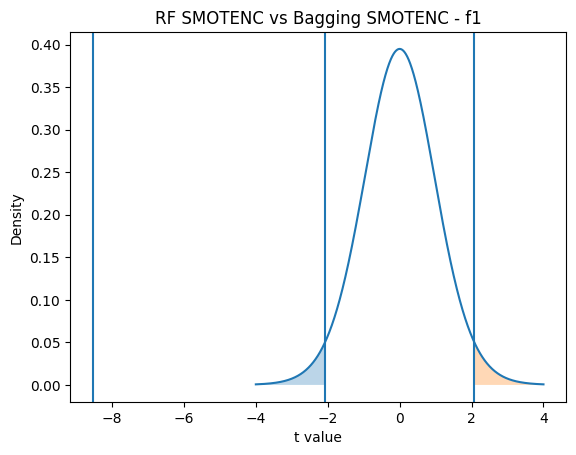

Model 1: RF SMOTENC
Model 2: Bagging SMOTENC
Metric : roc_auc
t value: -9.31972822302076
p value: 1.9104886662461677e-09
t critical: 2.0638985616280205


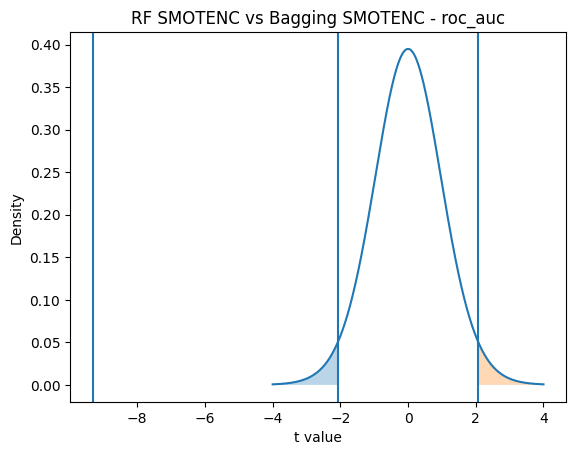

Model 1: RF SMOTENC
Model 2: Bagging CTGAN
Metric : accuracy
t value: -38.61766047125601
p value: 4.04557326887754e-23
t critical: 2.0638985616280205


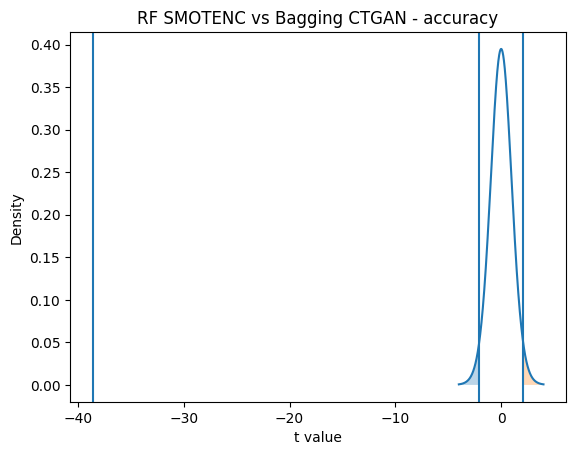

Model 1: RF SMOTENC
Model 2: Bagging CTGAN
Metric : precision
t value: -38.80301072453465
p value: 3.612679522903485e-23
t critical: 2.0638985616280205


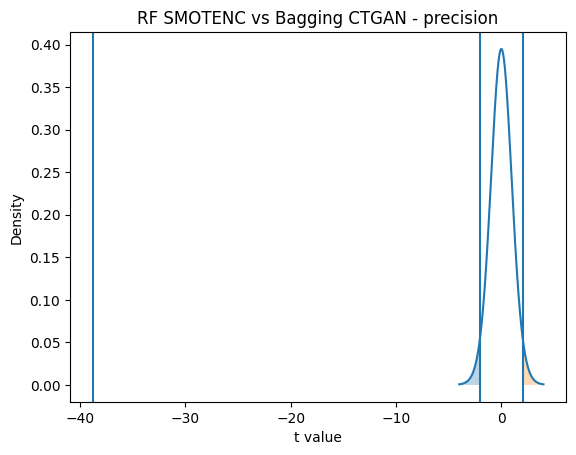

Model 1: RF SMOTENC
Model 2: Bagging CTGAN
Metric : recall
t value: -38.61686741322733
p value: 4.04753732991582e-23
t critical: 2.0638985616280205


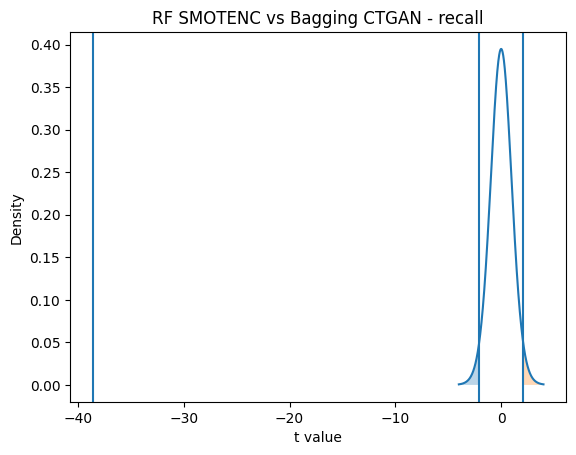

Model 1: RF SMOTENC
Model 2: Bagging CTGAN
Metric : f1
t value: -38.58866095378876
p value: 4.1180419337532865e-23
t critical: 2.0638985616280205


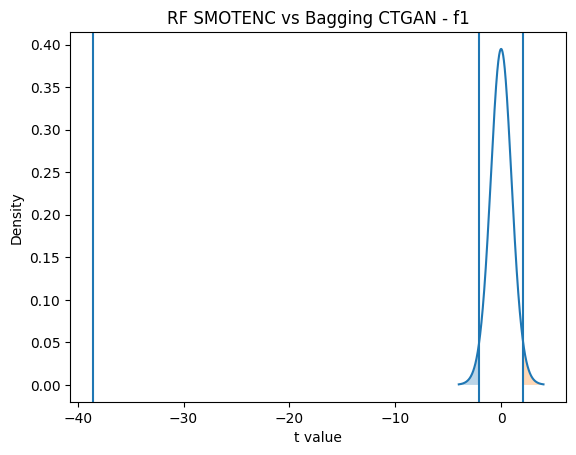

Model 1: RF SMOTENC
Model 2: Bagging CTGAN
Metric : roc_auc
t value: -35.40360924441695
p value: 3.1452823316961657e-22
t critical: 2.0638985616280205


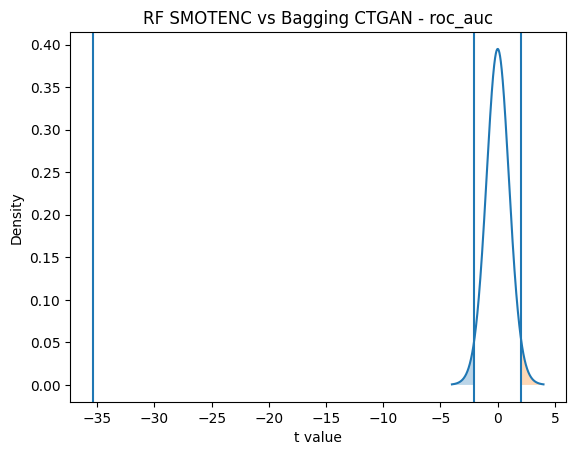

Model 1: RF SMOTENC
Model 2: RSCV Bagging Baseline
Metric : accuracy
t value: 6.639939531723435
p value: 7.221387080068284e-07
t critical: 2.0638985616280205


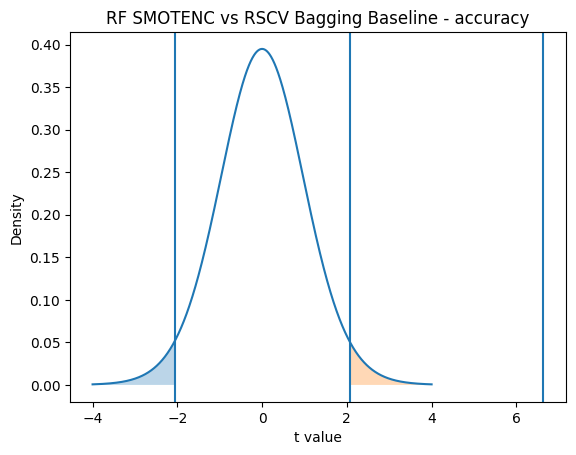

Model 1: RF SMOTENC
Model 2: RSCV Bagging Baseline
Metric : precision
t value: 19.624969061961405
p value: 2.7509481005681206e-16
t critical: 2.0638985616280205


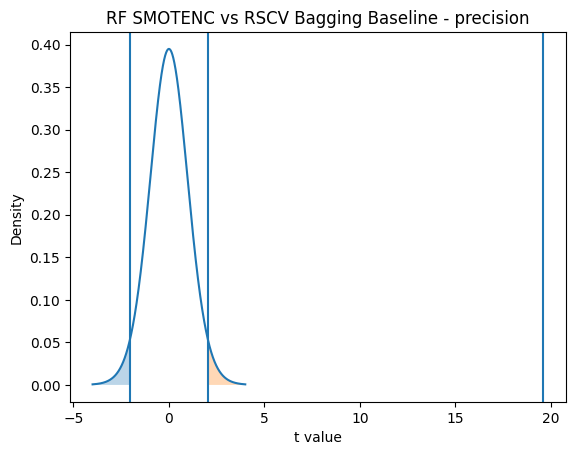

Model 1: RF SMOTENC
Model 2: RSCV Bagging Baseline
Metric : recall
t value: 54.58885953600919
p value: 1.0943416053359966e-26
t critical: 2.0638985616280205


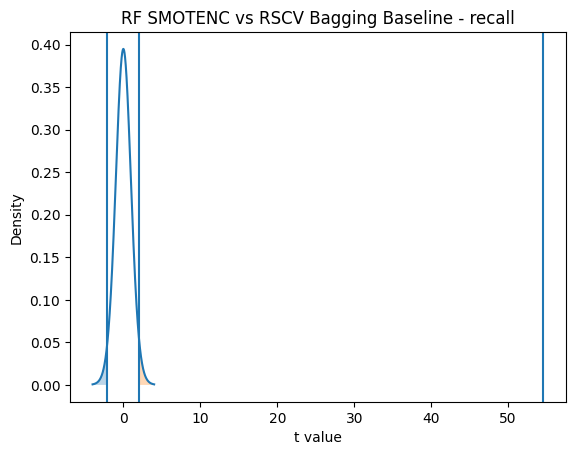

Model 1: RF SMOTENC
Model 2: RSCV Bagging Baseline
Metric : f1
t value: 62.6362227178694
p value: 4.125457070756734e-28
t critical: 2.0638985616280205


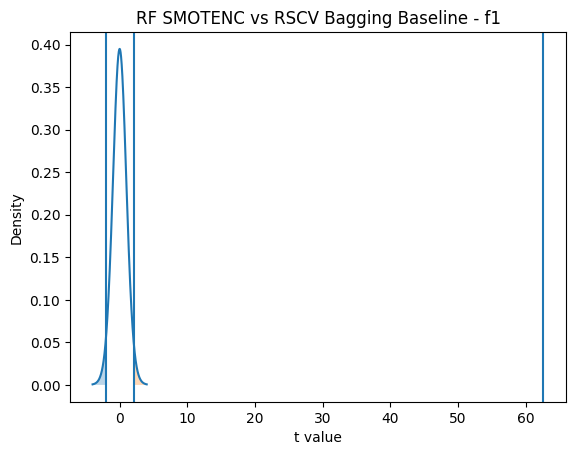

Model 1: RF SMOTENC
Model 2: RSCV Bagging Baseline
Metric : roc_auc
t value: 64.57839476352255
p value: 1.9906597581478887e-28
t critical: 2.0638985616280205


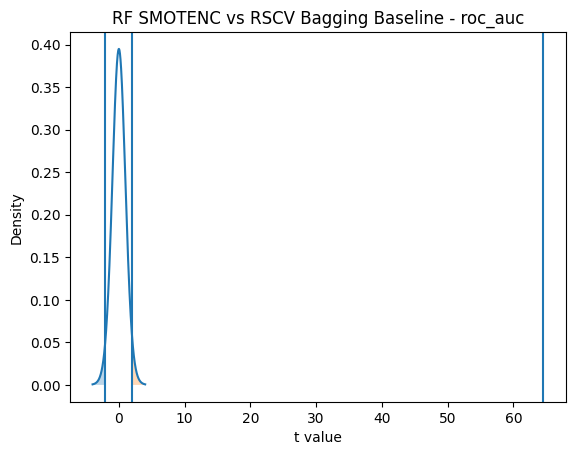

Model 1: RF SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : accuracy
t value: -3.7933837475961685
p value: 0.0008866456389692244
t critical: 2.0638985616280205


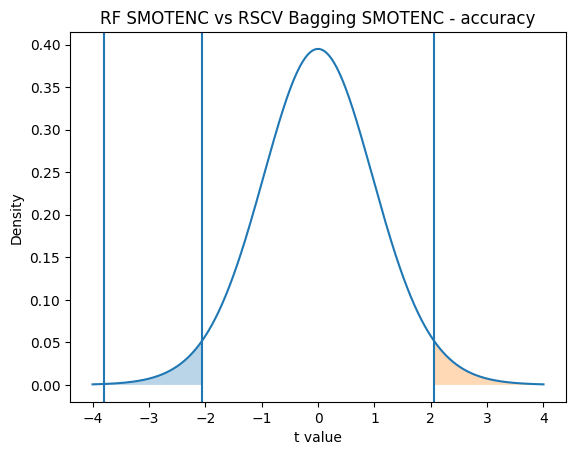

Model 1: RF SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : precision
t value: -3.8462176233689838
p value: 0.0007764375191067553
t critical: 2.0638985616280205


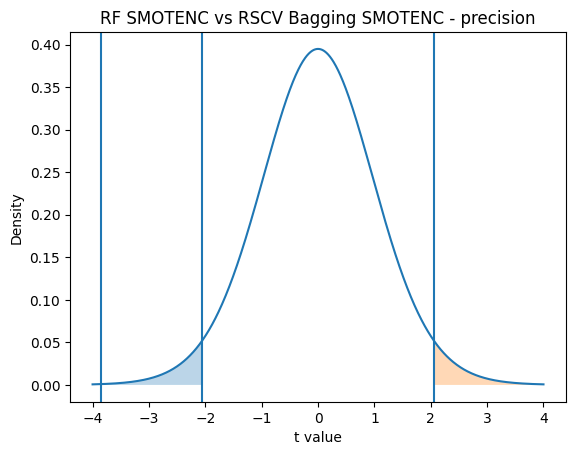

Model 1: RF SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : recall
t value: -3.8277372775968783
p value: 0.000813358844295649
t critical: 2.0638985616280205


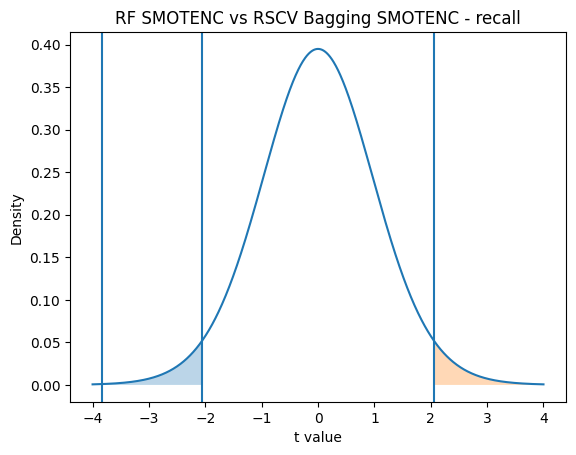

Model 1: RF SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : f1
t value: -3.7745212811625226
p value: 0.0009296108755600914
t critical: 2.0638985616280205


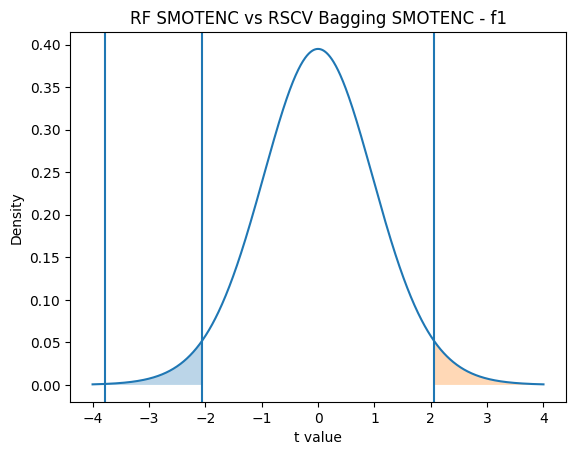

Model 1: RF SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : roc_auc
t value: -5.28551612964411
p value: 2.020285287799927e-05
t critical: 2.0638985616280205


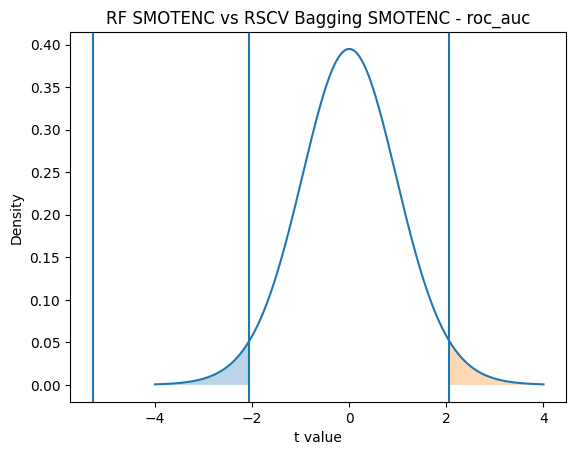

Model 1: RF SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : accuracy
t value: -36.768778082108405
p value: 1.2887427548036718e-22
t critical: 2.0638985616280205


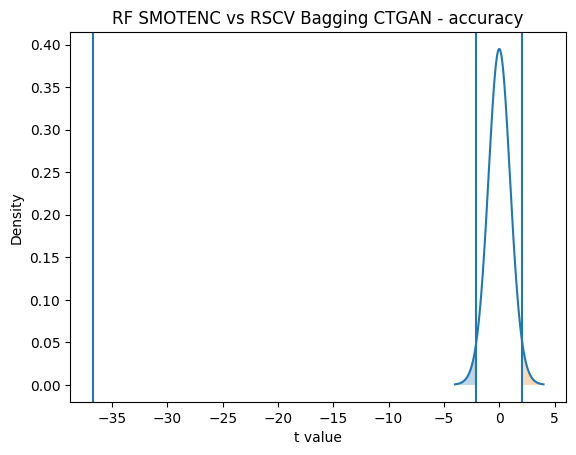

Model 1: RF SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : precision
t value: -37.06132631703418
p value: 1.0689040241101786e-22
t critical: 2.0638985616280205


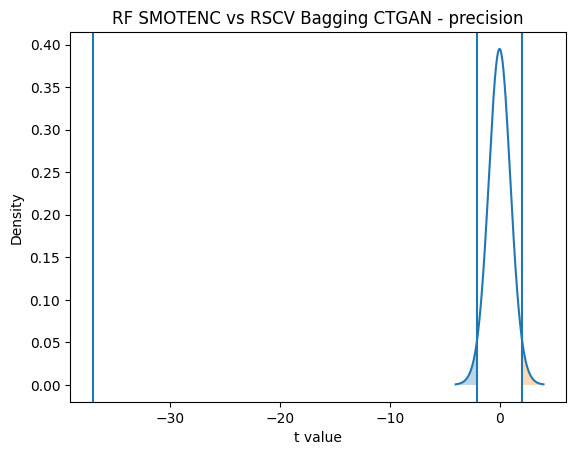

Model 1: RF SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : recall
t value: -36.71699340036604
p value: 1.3323231349815525e-22
t critical: 2.0638985616280205


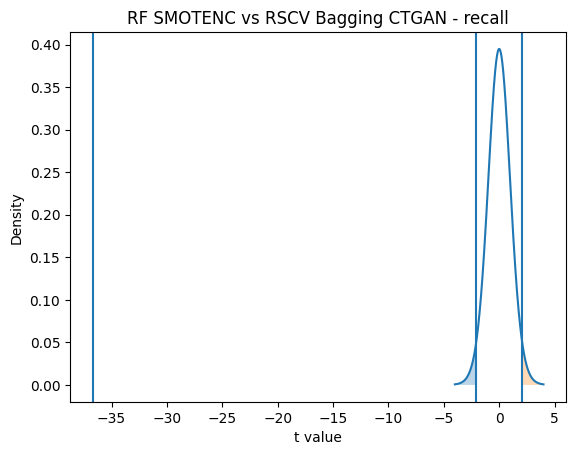

Model 1: RF SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : f1
t value: -36.69869569156243
p value: 1.3480863587160836e-22
t critical: 2.0638985616280205


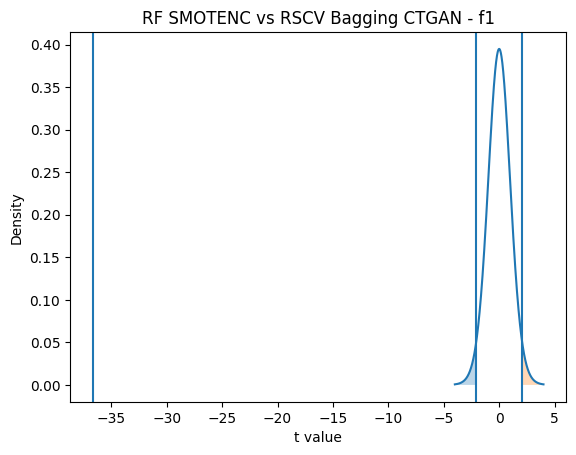

Model 1: RF SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : roc_auc
t value: -32.387843147603235
p value: 2.5545538108684595e-21
t critical: 2.0638985616280205


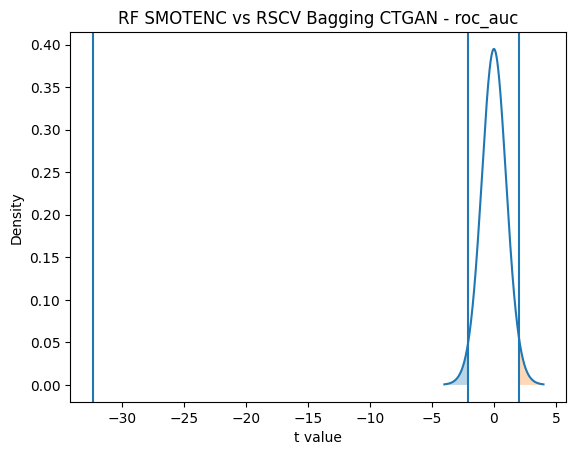

Model 1: RF CTGAN
Model 2: RSCV RF Baseline
Metric : accuracy
t value: 41.01943022752614
p value: 9.707842146990306e-24
t critical: 2.0638985616280205


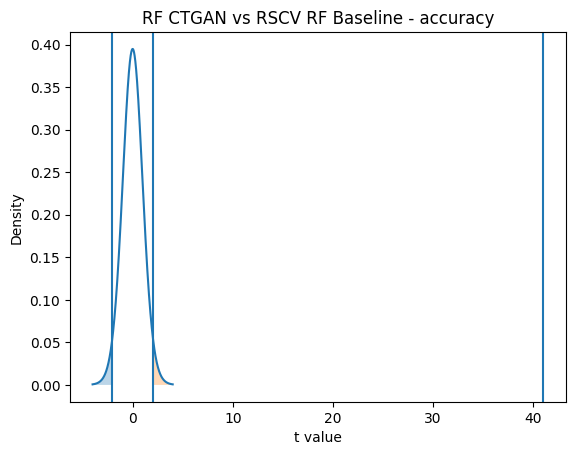

Model 1: RF CTGAN
Model 2: RSCV RF Baseline
Metric : precision
t value: 15.618509521669663
p value: 4.4893778767662704e-14
t critical: 2.0638985616280205


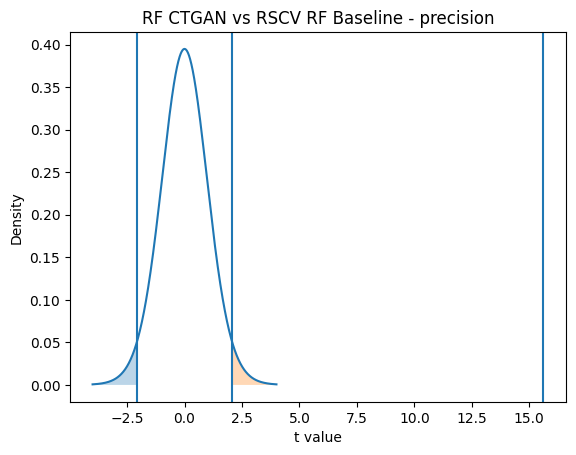

Model 1: RF CTGAN
Model 2: RSCV RF Baseline
Metric : recall
t value: 97.53008902186488
p value: 1.0420588907937543e-32
t critical: 2.0638985616280205


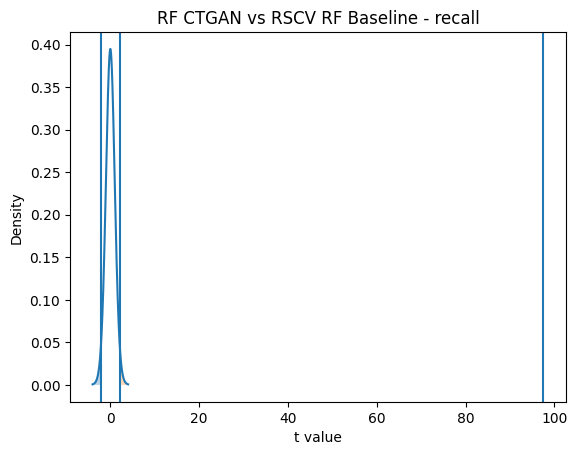

Model 1: RF CTGAN
Model 2: RSCV RF Baseline
Metric : f1
t value: 110.63252032772738
p value: 5.091467406317775e-34
t critical: 2.0638985616280205


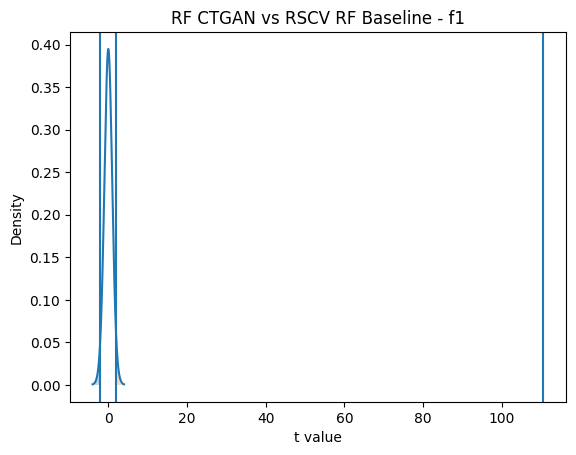

Model 1: RF CTGAN
Model 2: RSCV RF Baseline
Metric : roc_auc
t value: 99.65291067508743
p value: 6.2228747814085e-33
t critical: 2.0638985616280205


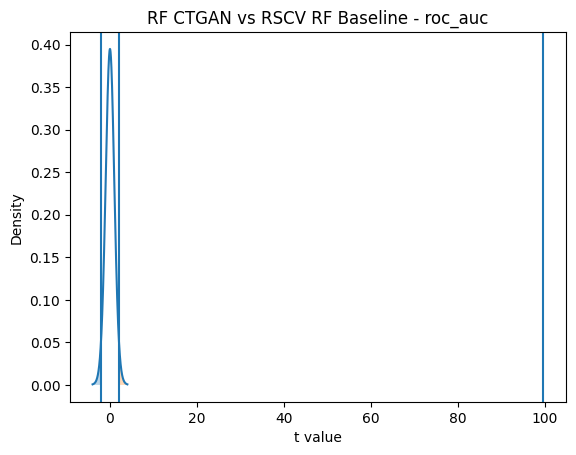

Model 1: RF CTGAN
Model 2: RSCV RF SMOTENC
Metric : accuracy
t value: 20.348004039877093
p value: 1.21042746470717e-16
t critical: 2.0638985616280205


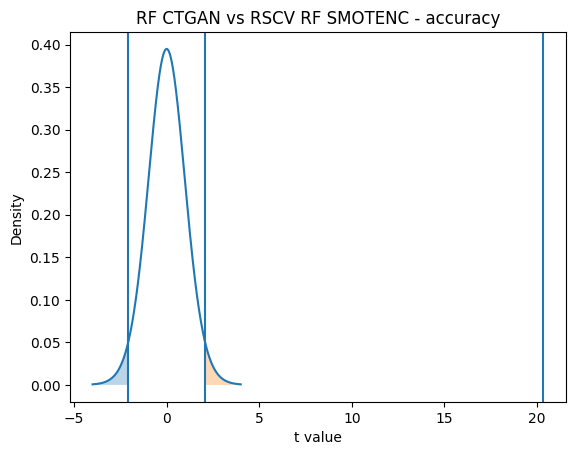

Model 1: RF CTGAN
Model 2: RSCV RF SMOTENC
Metric : precision
t value: 21.707311799983366
p value: 2.7691208712864023e-17
t critical: 2.0638985616280205


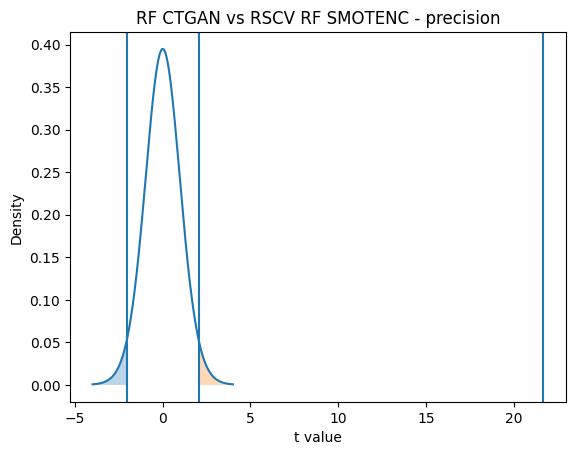

Model 1: RF CTGAN
Model 2: RSCV RF SMOTENC
Metric : recall
t value: 20.304908182191998
p value: 1.270196409832775e-16
t critical: 2.0638985616280205


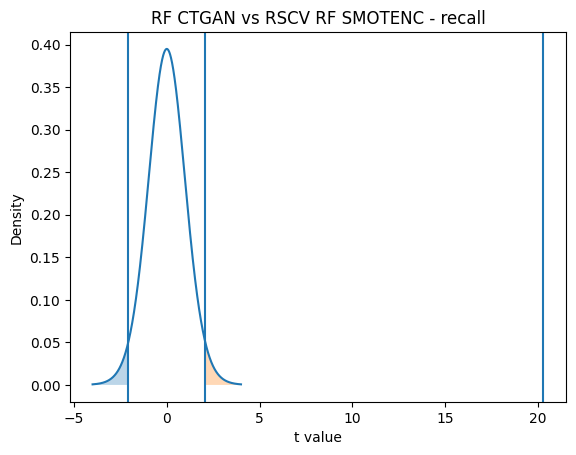

Model 1: RF CTGAN
Model 2: RSCV RF SMOTENC
Metric : f1
t value: 20.205650742875697
p value: 1.4198183793356977e-16
t critical: 2.0638985616280205


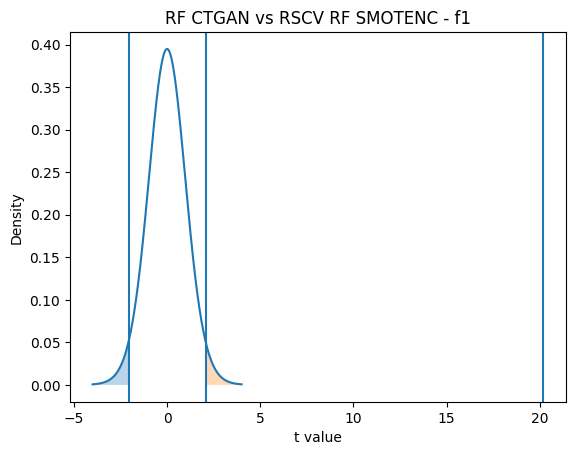

Model 1: RF CTGAN
Model 2: RSCV RF SMOTENC
Metric : roc_auc
t value: 24.2727814710141
p value: 2.122686216646765e-18
t critical: 2.0638985616280205


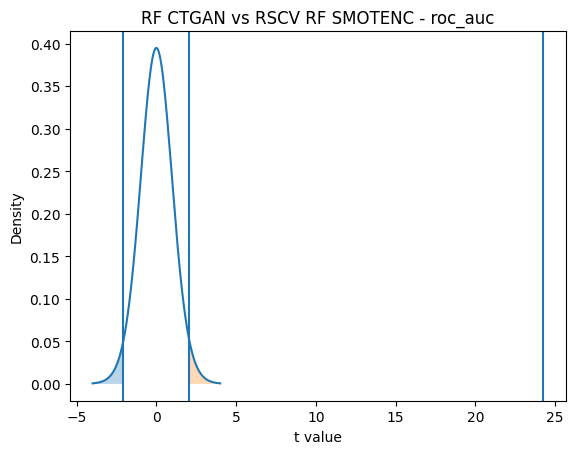

Model 1: RF CTGAN
Model 2: RSCV RF CTGAN
Metric : accuracy
t value: -2.0422065982665485
p value: 0.052266596759198605
t critical: 2.0638985616280205


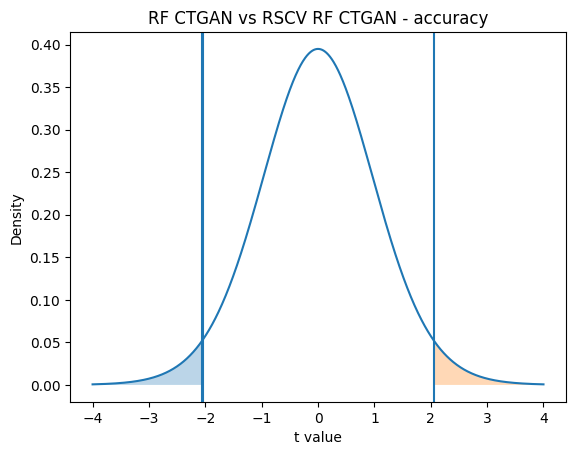

Model 1: RF CTGAN
Model 2: RSCV RF CTGAN
Metric : precision
t value: -1.8453577502070753
p value: 0.07735969007834118
t critical: 2.0638985616280205


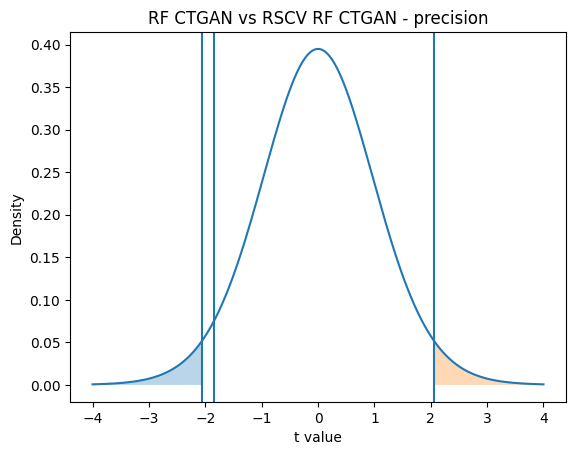

Model 1: RF CTGAN
Model 2: RSCV RF CTGAN
Metric : recall
t value: -2.0671517856283885
p value: 0.04966772908493749
t critical: 2.0638985616280205


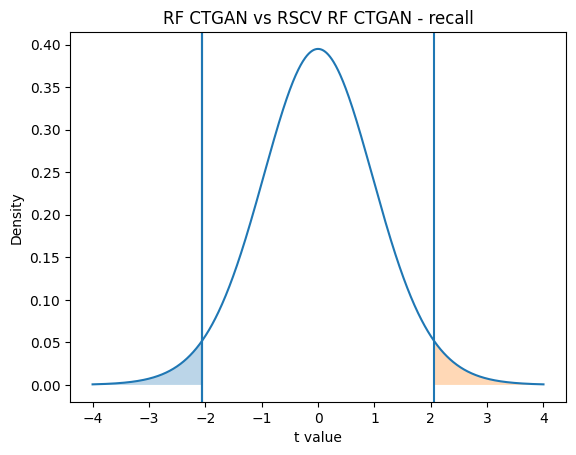

Model 1: RF CTGAN
Model 2: RSCV RF CTGAN
Metric : f1
t value: -2.05251400586989
p value: 0.0511784191041055
t critical: 2.0638985616280205


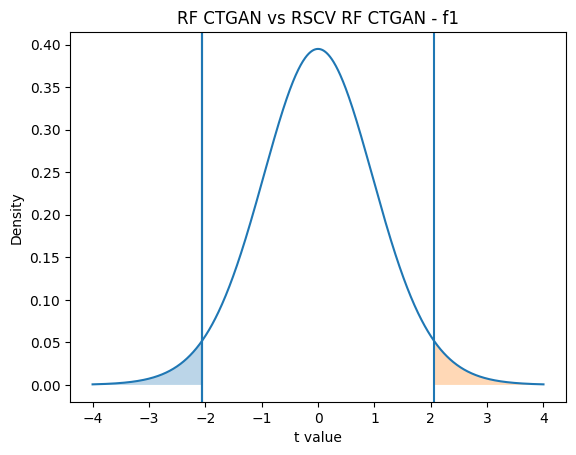

Model 1: RF CTGAN
Model 2: RSCV RF CTGAN
Metric : roc_auc
t value: -6.140724088543884
p value: 2.413071131731852e-06
t critical: 2.0638985616280205


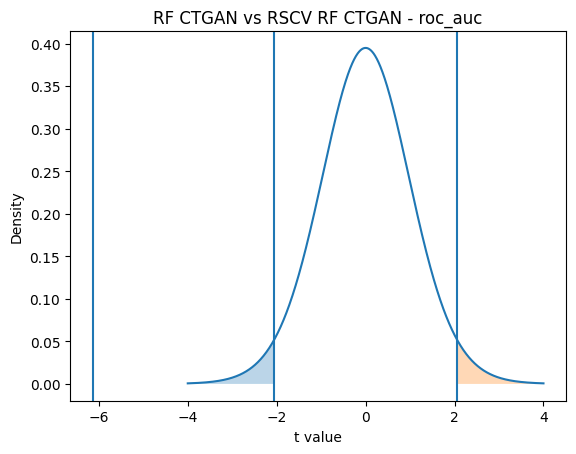

Model 1: RF CTGAN
Model 2: Bagging Baseline
Metric : accuracy
t value: 16.616351461911375
p value: 1.1461961243107544e-14
t critical: 2.0638985616280205


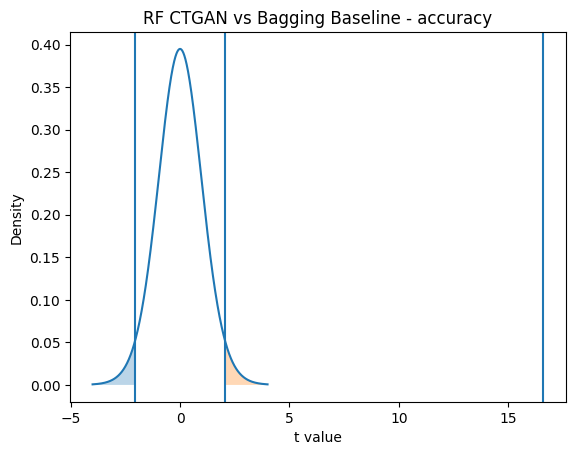

Model 1: RF CTGAN
Model 2: Bagging Baseline
Metric : precision
t value: 23.85527437126872
p value: 3.1681615439107218e-18
t critical: 2.0638985616280205


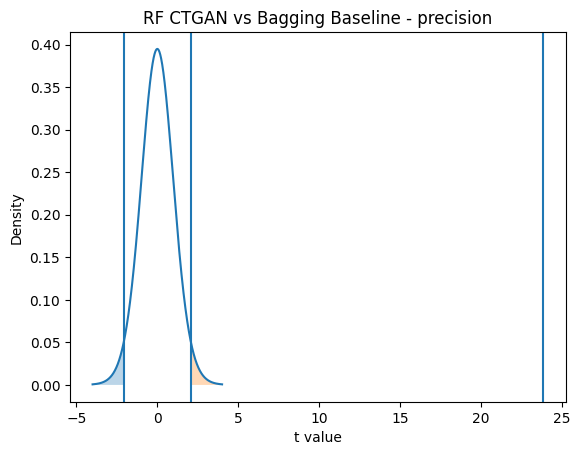

Model 1: RF CTGAN
Model 2: Bagging Baseline
Metric : recall
t value: 86.332291072392
p value: 1.93009270552642e-31
t critical: 2.0638985616280205


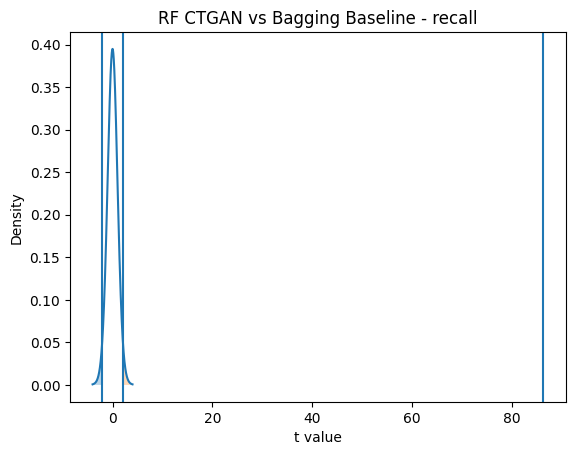

Model 1: RF CTGAN
Model 2: Bagging Baseline
Metric : f1
t value: 46.72891348929326
p value: 4.415834353660583e-25
t critical: 2.0638985616280205


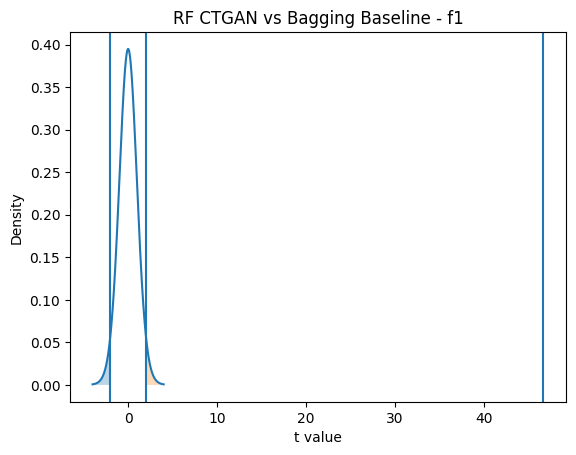

Model 1: RF CTGAN
Model 2: Bagging Baseline
Metric : roc_auc
t value: 112.99551476037693
p value: 3.068790863880951e-34
t critical: 2.0638985616280205


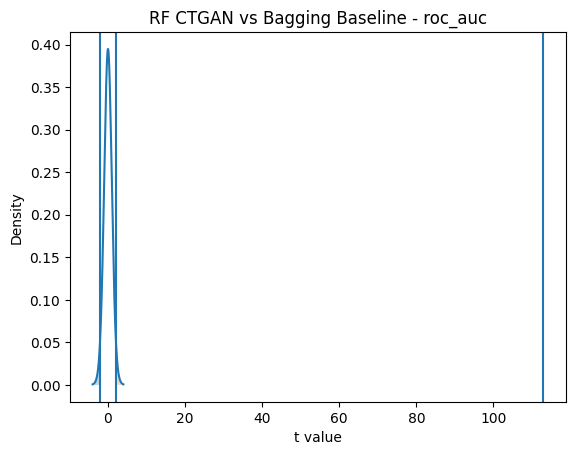

Model 1: RF CTGAN
Model 2: Bagging SMOTENC
Metric : accuracy
t value: 25.323873355733767
p value: 7.961645153894379e-19
t critical: 2.0638985616280205


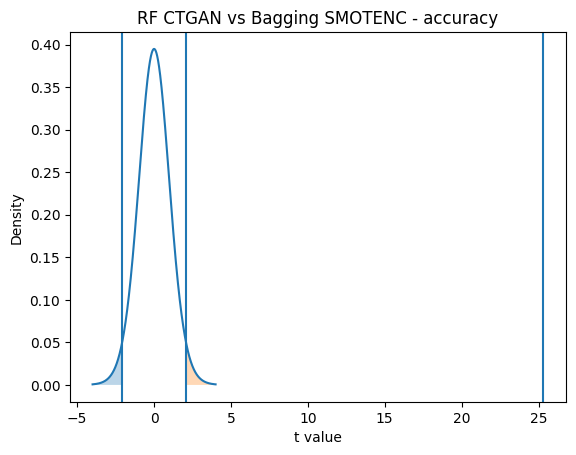

Model 1: RF CTGAN
Model 2: Bagging SMOTENC
Metric : precision
t value: 27.44294578947846
p value: 1.2311262245660304e-19
t critical: 2.0638985616280205


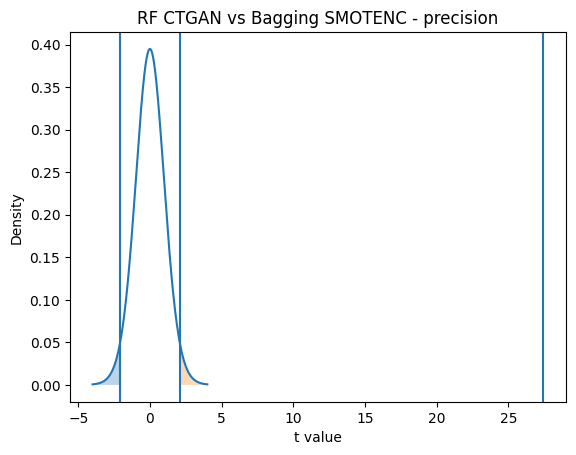

Model 1: RF CTGAN
Model 2: Bagging SMOTENC
Metric : recall
t value: 25.321584746739568
p value: 7.978332808088229e-19
t critical: 2.0638985616280205


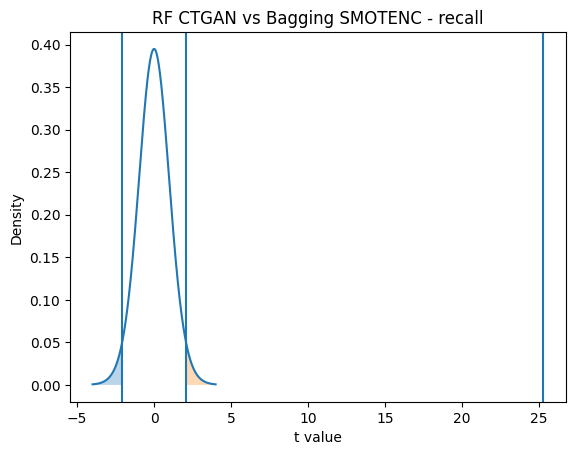

Model 1: RF CTGAN
Model 2: Bagging SMOTENC
Metric : f1
t value: 25.074550744971614
p value: 1.0011941934341154e-18
t critical: 2.0638985616280205


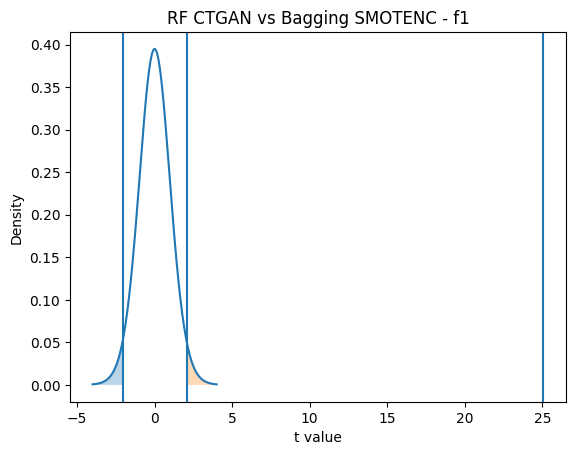

Model 1: RF CTGAN
Model 2: Bagging SMOTENC
Metric : roc_auc
t value: 27.813581977579283
p value: 9.006851666963327e-20
t critical: 2.0638985616280205


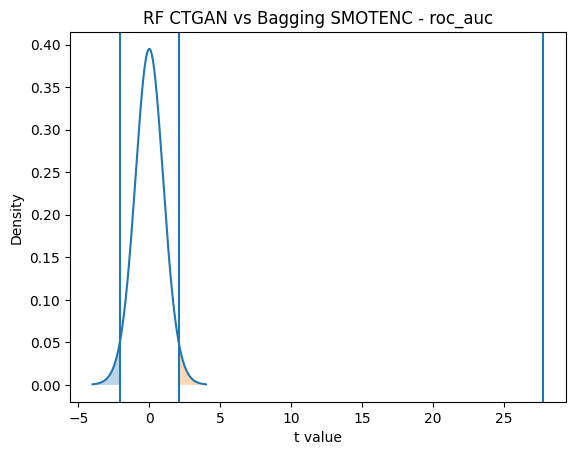

Model 1: RF CTGAN
Model 2: Bagging CTGAN
Metric : accuracy
t value: -6.339615329510778
p value: 1.4871575261887393e-06
t critical: 2.0638985616280205


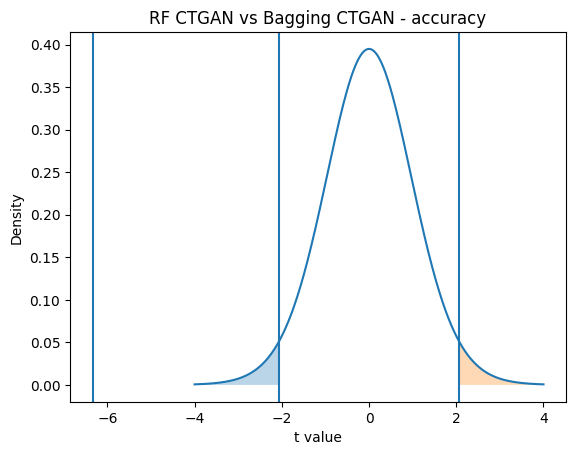

Model 1: RF CTGAN
Model 2: Bagging CTGAN
Metric : precision
t value: -6.640015700892273
p value: 7.220073818850097e-07
t critical: 2.0638985616280205


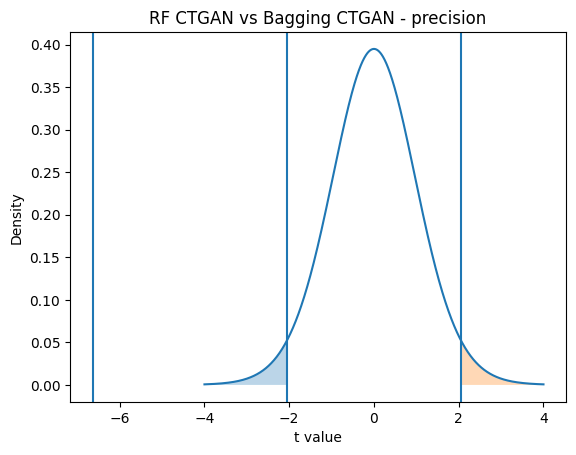

Model 1: RF CTGAN
Model 2: Bagging CTGAN
Metric : recall
t value: -6.338920699542432
p value: 1.4896623701948538e-06
t critical: 2.0638985616280205


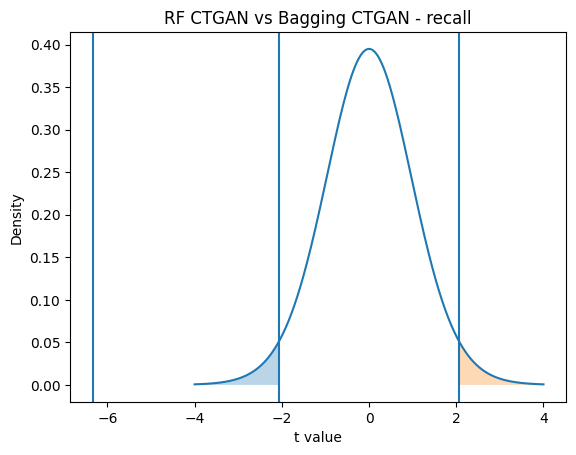

Model 1: RF CTGAN
Model 2: Bagging CTGAN
Metric : f1
t value: -6.305497162268725
p value: 1.6154111389318252e-06
t critical: 2.0638985616280205


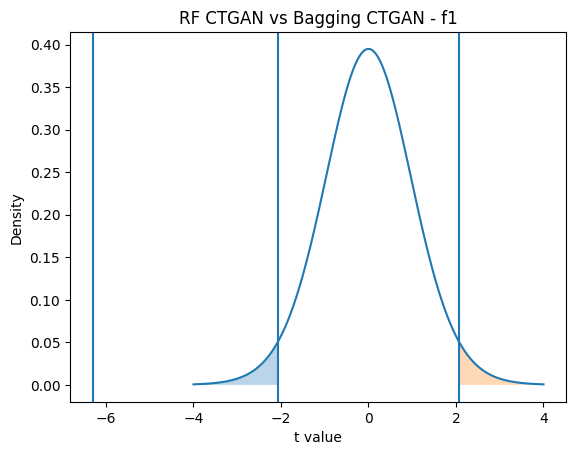

Model 1: RF CTGAN
Model 2: Bagging CTGAN
Metric : roc_auc
t value: -9.99231426937028
p value: 4.989885932772621e-10
t critical: 2.0638985616280205


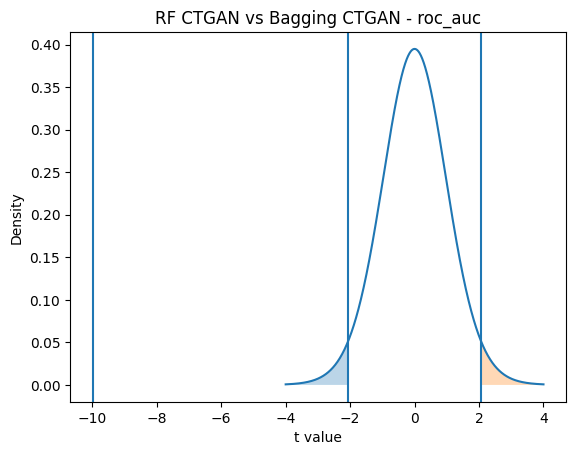

Model 1: RF CTGAN
Model 2: RSCV Bagging Baseline
Metric : accuracy
t value: 41.528247297108706
p value: 7.250098061797242e-24
t critical: 2.0638985616280205


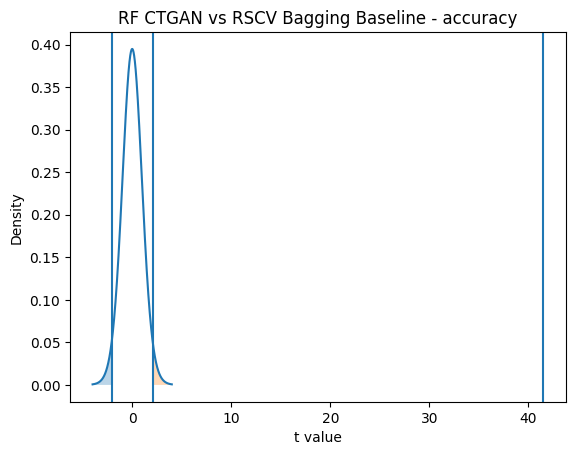

Model 1: RF CTGAN
Model 2: RSCV Bagging Baseline
Metric : precision
t value: 33.448670945230084
p value: 1.1978244984670659e-21
t critical: 2.0638985616280205


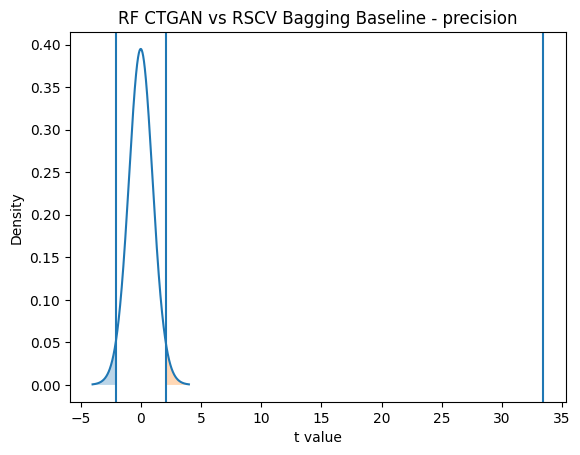

Model 1: RF CTGAN
Model 2: RSCV Bagging Baseline
Metric : recall
t value: 94.68535668408929
p value: 2.116714814461372e-32
t critical: 2.0638985616280205


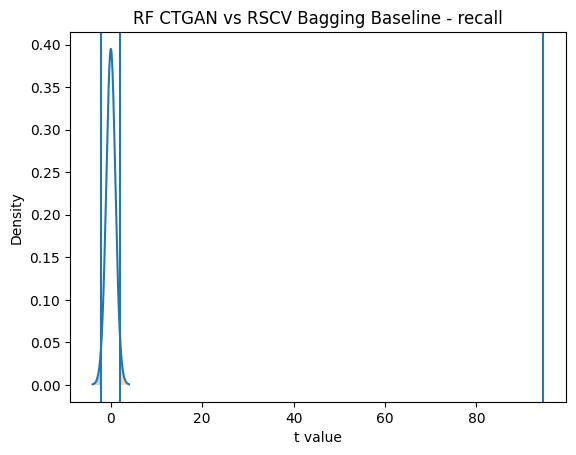

Model 1: RF CTGAN
Model 2: RSCV Bagging Baseline
Metric : f1
t value: 99.12231203615279
p value: 7.071424805764633e-33
t critical: 2.0638985616280205


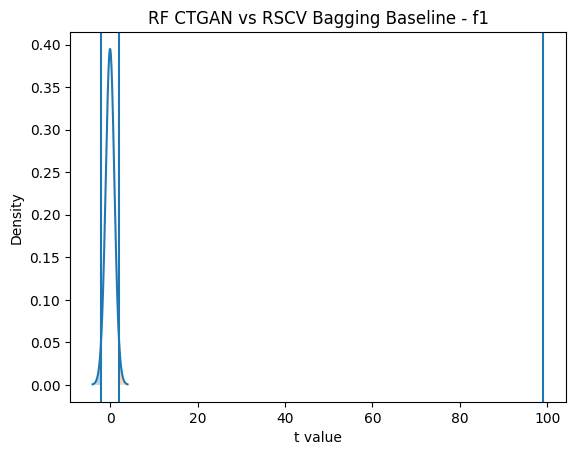

Model 1: RF CTGAN
Model 2: RSCV Bagging Baseline
Metric : roc_auc
t value: 112.39924259876392
p value: 3.4834931628823554e-34
t critical: 2.0638985616280205


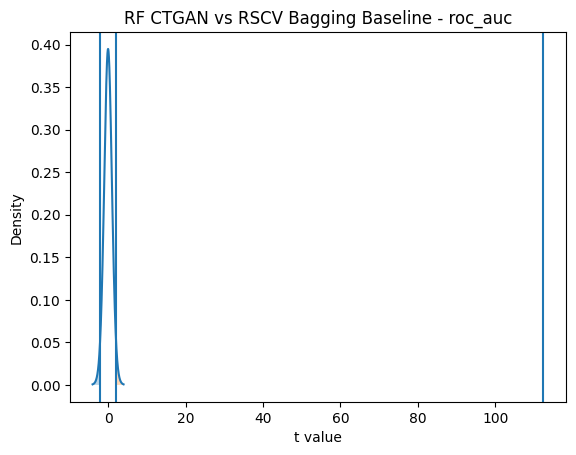

Model 1: RF CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : accuracy
t value: 23.859313560016787
p value: 3.1558132098876504e-18
t critical: 2.0638985616280205


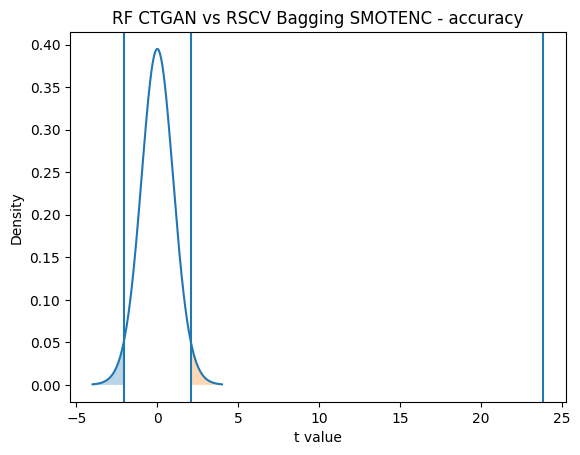

Model 1: RF CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : precision
t value: 25.47127419196693
p value: 6.959799244174005e-19
t critical: 2.0638985616280205


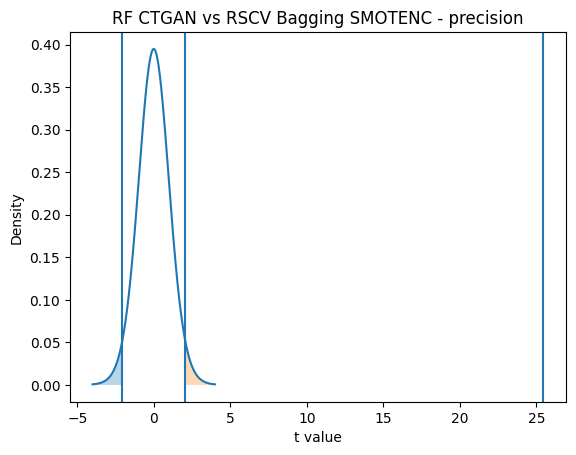

Model 1: RF CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : recall
t value: 23.98344180853852
p value: 2.7997509054142763e-18
t critical: 2.0638985616280205


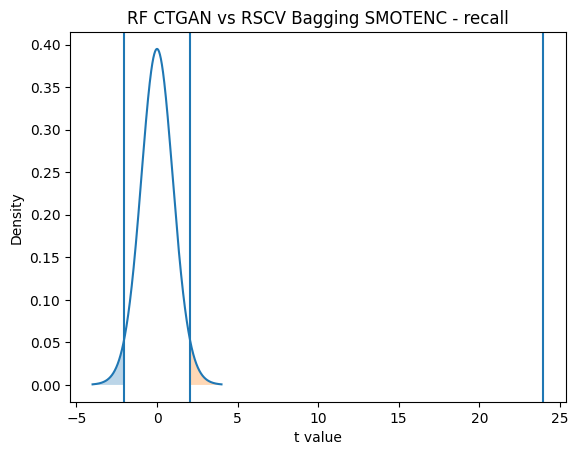

Model 1: RF CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : f1
t value: 23.76402605952368
p value: 3.46092832922447e-18
t critical: 2.0638985616280205


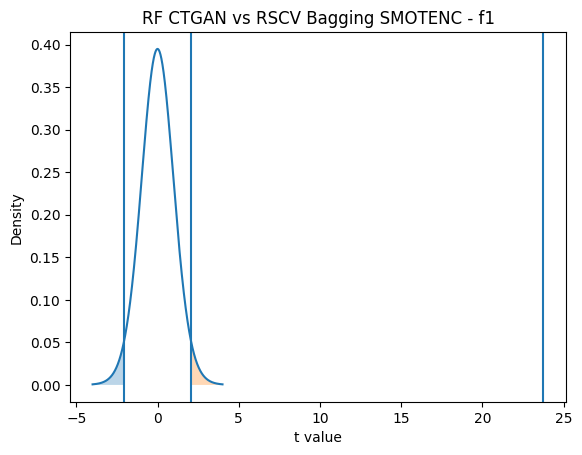

Model 1: RF CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : roc_auc
t value: 25.376930598325178
p value: 7.584780932263187e-19
t critical: 2.0638985616280205


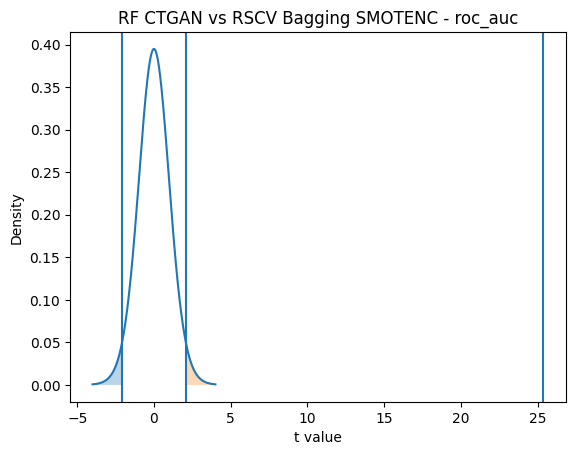

Model 1: RF CTGAN
Model 2: RSCV Bagging CTGAN
Metric : accuracy
t value: -0.29640919060894577
p value: 0.7694674843064111
t critical: 2.0638985616280205


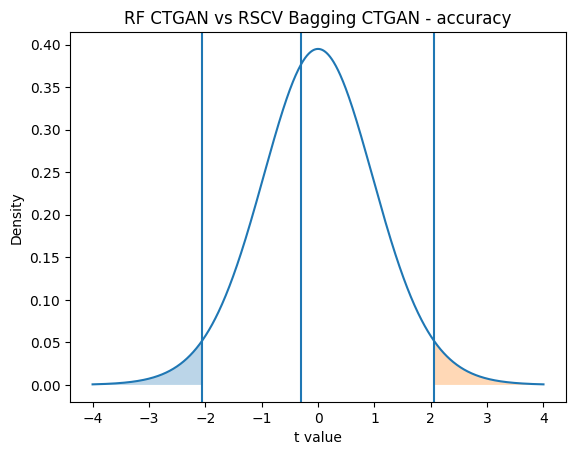

Model 1: RF CTGAN
Model 2: RSCV Bagging CTGAN
Metric : precision
t value: 0.060562050658648094
p value: 0.9522094994832596
t critical: 2.0638985616280205


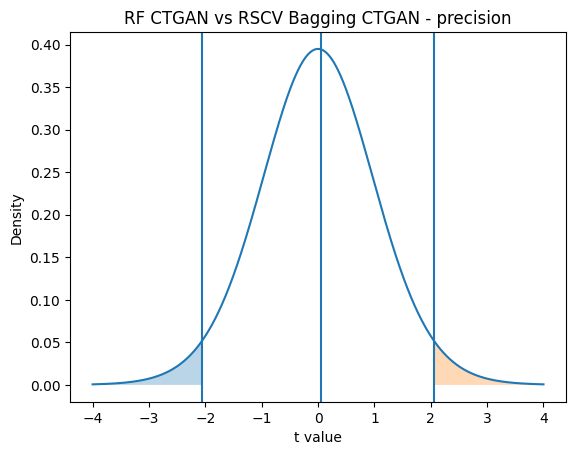

Model 1: RF CTGAN
Model 2: RSCV Bagging CTGAN
Metric : recall
t value: -0.3166475486096986
p value: 0.7542489036686635
t critical: 2.0638985616280205


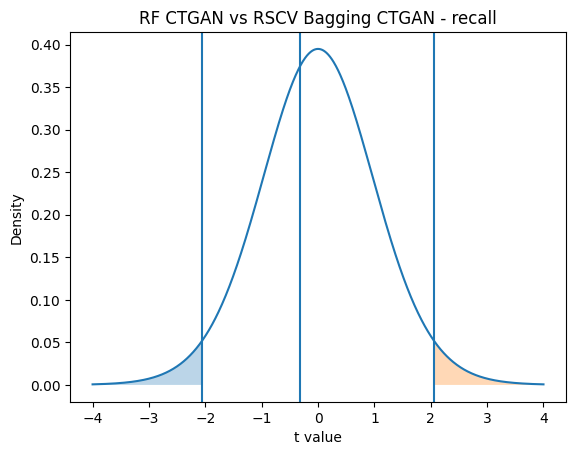

Model 1: RF CTGAN
Model 2: RSCV Bagging CTGAN
Metric : f1
t value: -0.32178049158484867
p value: 0.7504049023342614
t critical: 2.0638985616280205


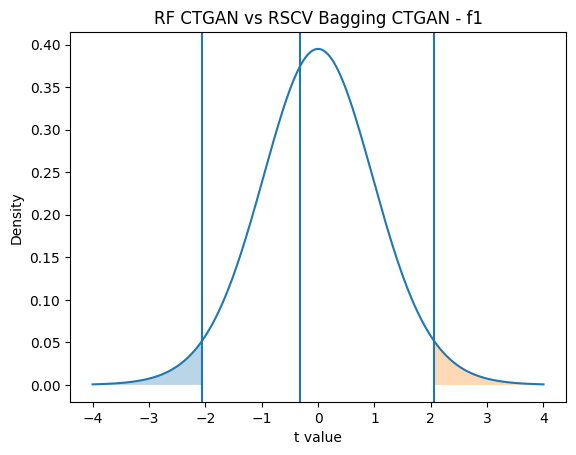

Model 1: RF CTGAN
Model 2: RSCV Bagging CTGAN
Metric : roc_auc
t value: -3.1409590954889217
p value: 0.004429205168487115
t critical: 2.0638985616280205


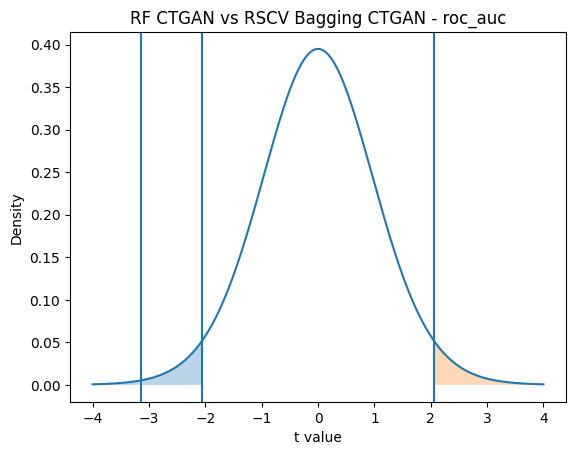

Model 1: RSCV RF Baseline
Model 2: RSCV RF SMOTENC
Metric : accuracy
t value: -22.95221792729011
p value: 7.705394170211113e-18
t critical: 2.0638985616280205


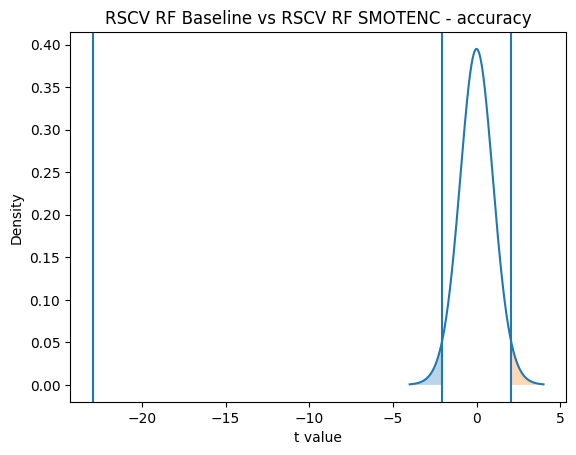

Model 1: RSCV RF Baseline
Model 2: RSCV RF SMOTENC
Metric : precision
t value: -12.57211522668993
p value: 4.737187356976338e-12
t critical: 2.0638985616280205


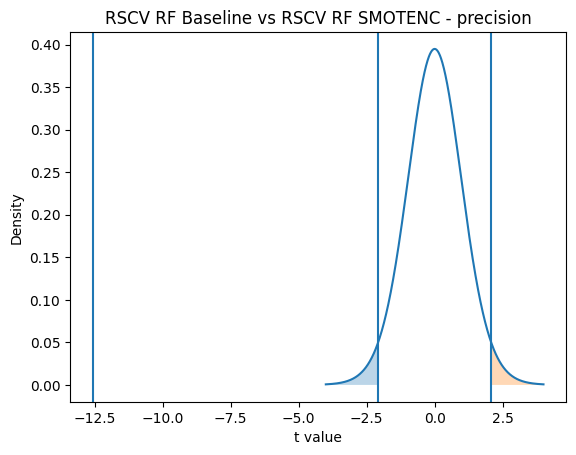

Model 1: RSCV RF Baseline
Model 2: RSCV RF SMOTENC
Metric : recall
t value: -105.59878791697567
p value: 1.5533122585251278e-33
t critical: 2.0638985616280205


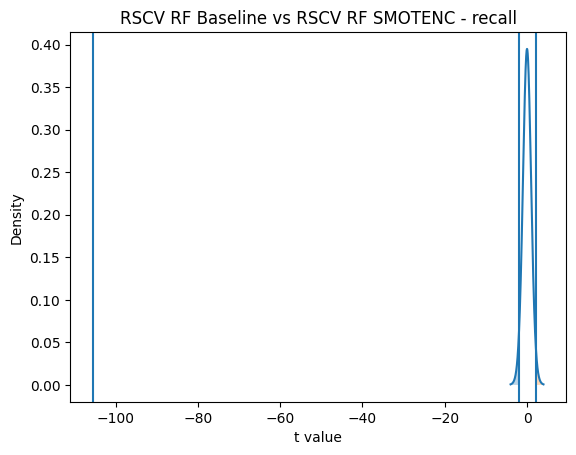

Model 1: RSCV RF Baseline
Model 2: RSCV RF SMOTENC
Metric : f1
t value: -121.30372524408088
p value: 5.606615976987787e-35
t critical: 2.0638985616280205


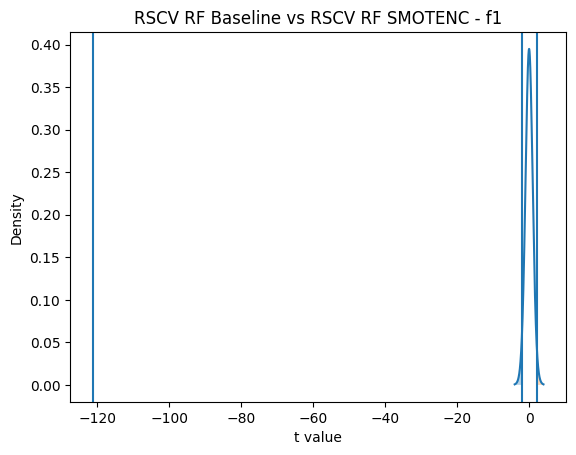

Model 1: RSCV RF Baseline
Model 2: RSCV RF SMOTENC
Metric : roc_auc
t value: -82.93766596993832
p value: 5.039062082118869e-31
t critical: 2.0638985616280205


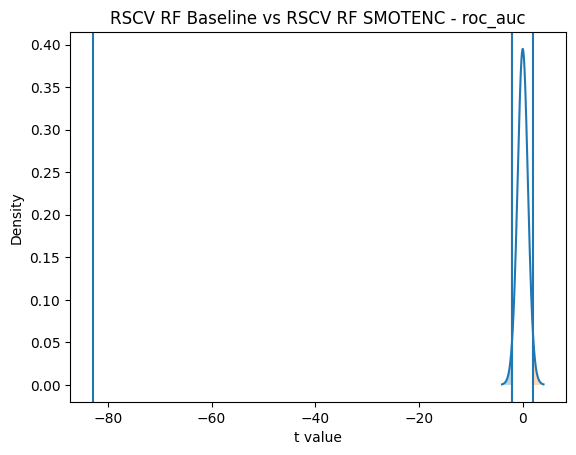

Model 1: RSCV RF Baseline
Model 2: RSCV RF CTGAN
Metric : accuracy
t value: -80.63858589633529
p value: 9.870880211656107e-31
t critical: 2.0638985616280205


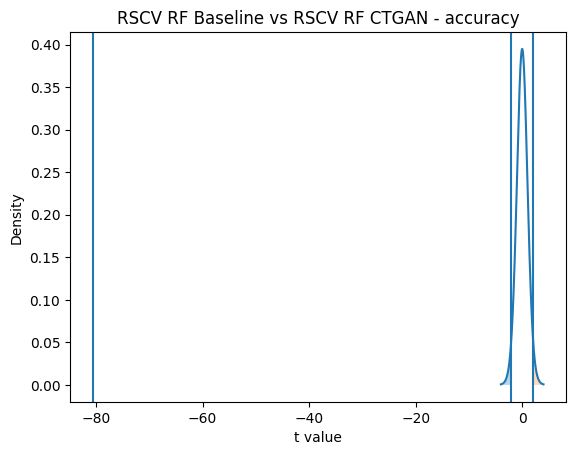

Model 1: RSCV RF Baseline
Model 2: RSCV RF CTGAN
Metric : precision
t value: -16.522929173423663
p value: 1.2986210396636429e-14
t critical: 2.0638985616280205


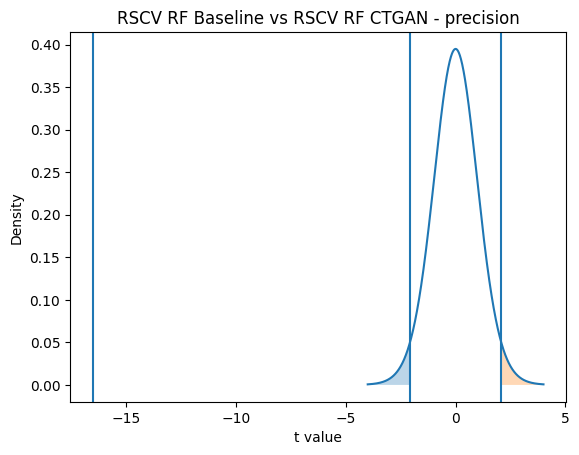

Model 1: RSCV RF Baseline
Model 2: RSCV RF CTGAN
Metric : recall
t value: -187.60164354788856
p value: 1.6171539930673406e-39
t critical: 2.0638985616280205


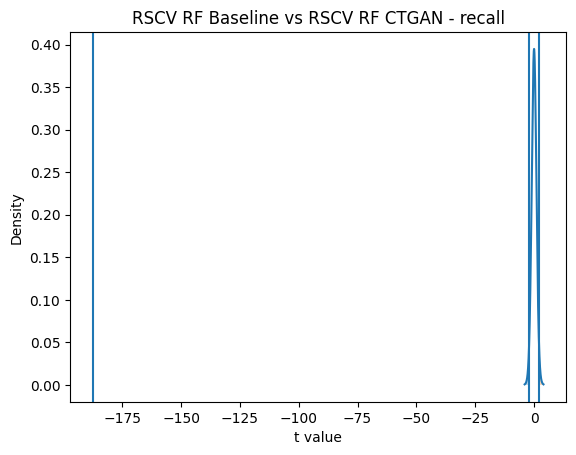

Model 1: RSCV RF Baseline
Model 2: RSCV RF CTGAN
Metric : f1
t value: -197.52491011119216
p value: 4.6972131457743316e-40
t critical: 2.0638985616280205


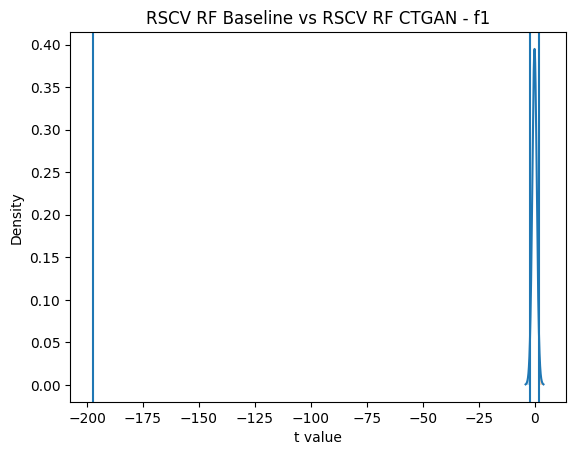

Model 1: RSCV RF Baseline
Model 2: RSCV RF CTGAN
Metric : roc_auc
t value: -147.8948192386703
p value: 4.847080980244972e-37
t critical: 2.0638985616280205


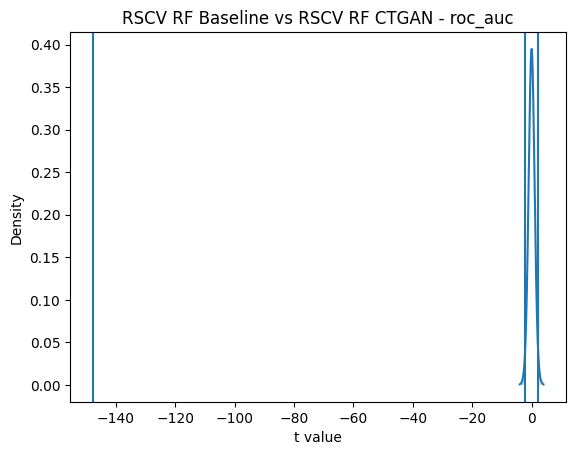

Model 1: RSCV RF Baseline
Model 2: Bagging Baseline
Metric : accuracy
t value: 4.9966511963143825
p value: 4.1922848843357166e-05
t critical: 2.0638985616280205


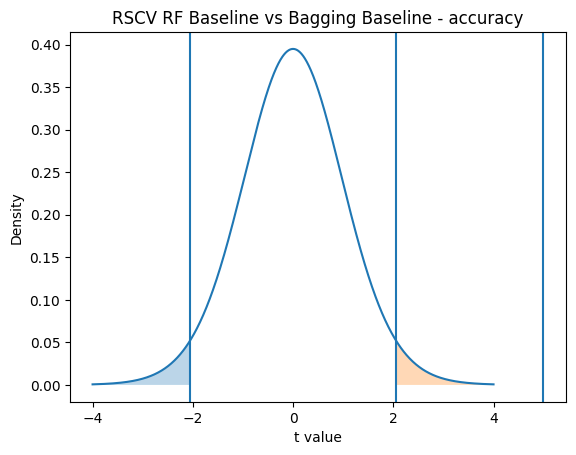

Model 1: RSCV RF Baseline
Model 2: Bagging Baseline
Metric : precision
t value: -1.3336095371282808
p value: 0.19485141794758373
t critical: 2.0638985616280205


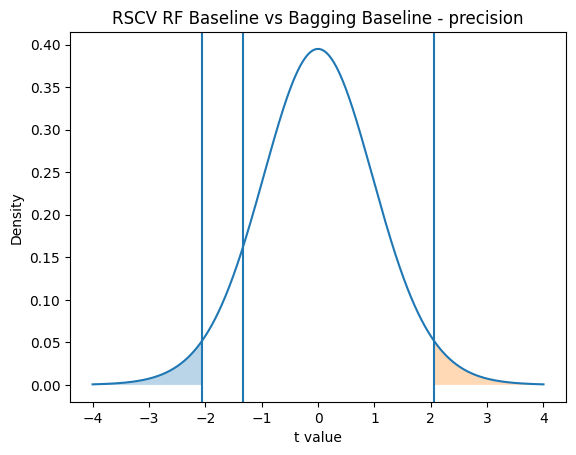

Model 1: RSCV RF Baseline
Model 2: Bagging Baseline
Metric : recall
t value: -4.654376287183525
p value: 0.00010000123618409573
t critical: 2.0638985616280205


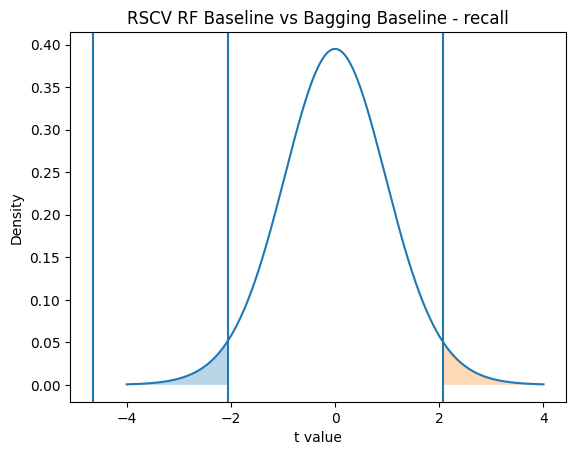

Model 1: RSCV RF Baseline
Model 2: Bagging Baseline
Metric : f1
t value: -7.72327390077424
p value: 5.851291851756645e-08
t critical: 2.0638985616280205


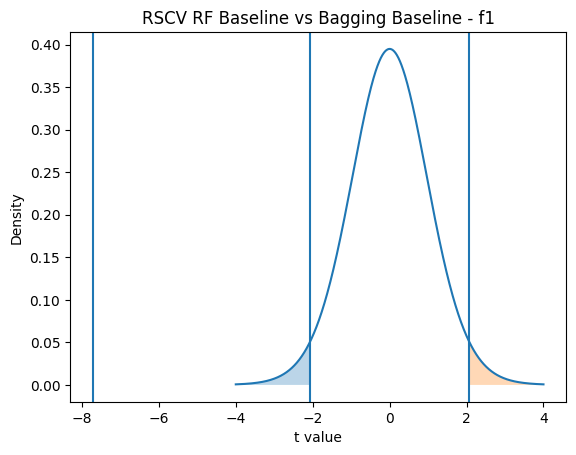

Model 1: RSCV RF Baseline
Model 2: Bagging Baseline
Metric : roc_auc
t value: -5.6022700571383535
p value: 9.129109393409423e-06
t critical: 2.0638985616280205


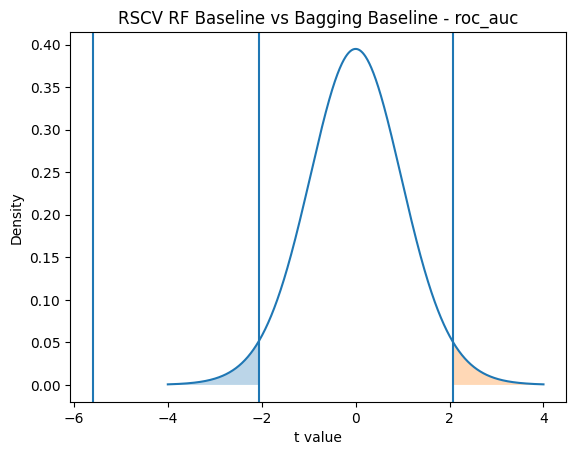

Model 1: RSCV RF Baseline
Model 2: Bagging SMOTENC
Metric : accuracy
t value: -35.12388580654185
p value: 3.7916986212257147e-22
t critical: 2.0638985616280205


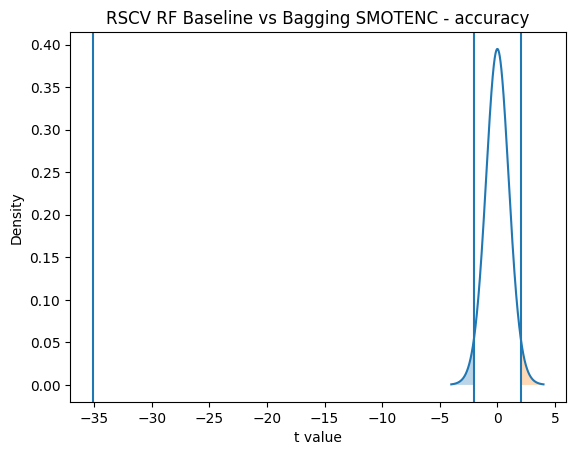

Model 1: RSCV RF Baseline
Model 2: Bagging SMOTENC
Metric : precision
t value: -12.566100921828184
p value: 4.7849266266864225e-12
t critical: 2.0638985616280205


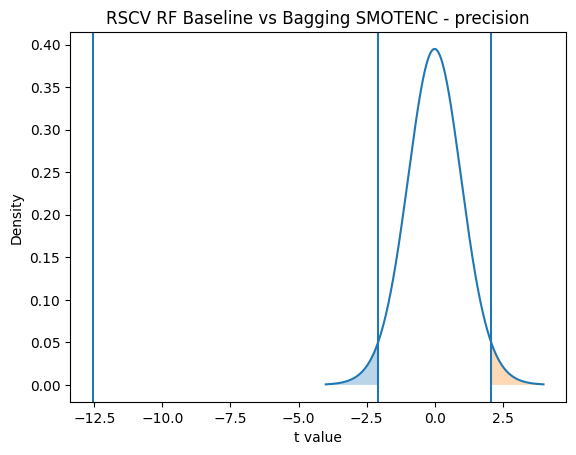

Model 1: RSCV RF Baseline
Model 2: Bagging SMOTENC
Metric : recall
t value: -158.32588792415356
p value: 9.458121485871728e-38
t critical: 2.0638985616280205


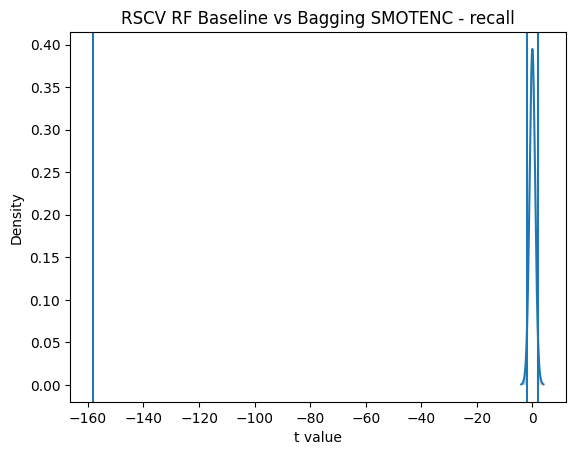

Model 1: RSCV RF Baseline
Model 2: Bagging SMOTENC
Metric : f1
t value: -172.62116391837938
p value: 1.190022996145134e-38
t critical: 2.0638985616280205


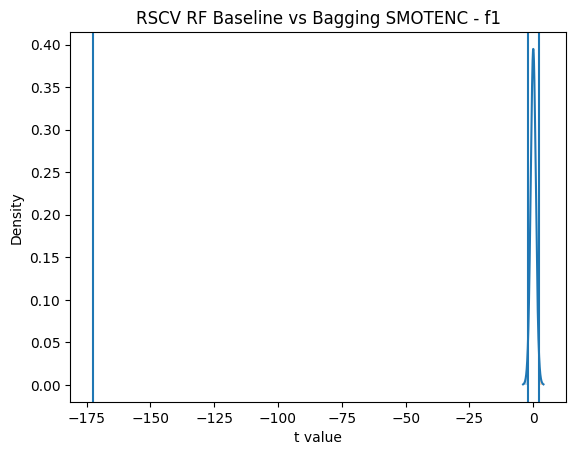

Model 1: RSCV RF Baseline
Model 2: Bagging SMOTENC
Metric : roc_auc
t value: -127.65556970915657
p value: 1.650127860136964e-35
t critical: 2.0638985616280205


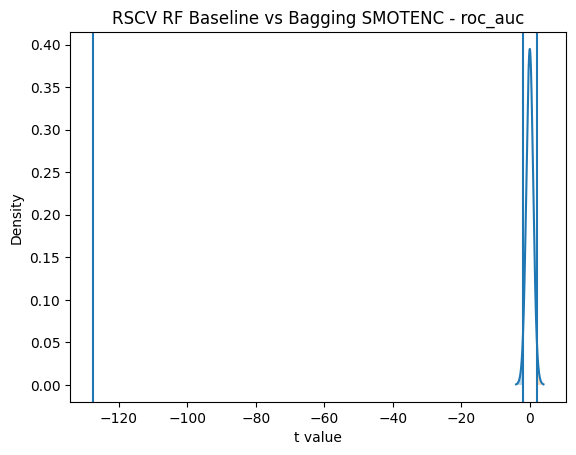

Model 1: RSCV RF Baseline
Model 2: Bagging CTGAN
Metric : accuracy
t value: -218.42171731295312
p value: 4.2094648162252035e-41
t critical: 2.0638985616280205


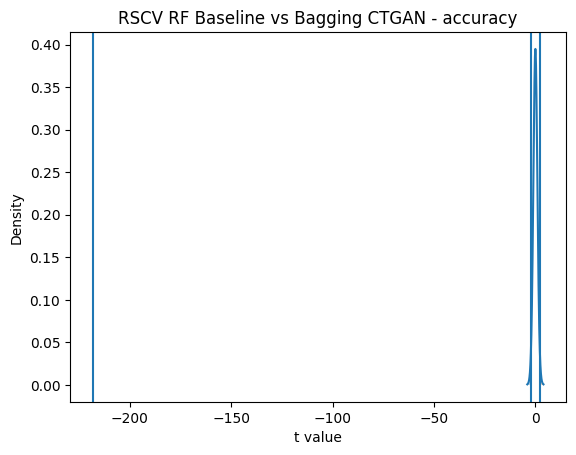

Model 1: RSCV RF Baseline
Model 2: Bagging CTGAN
Metric : precision
t value: -17.3572485312708
p value: 4.346860676113383e-15
t critical: 2.0638985616280205


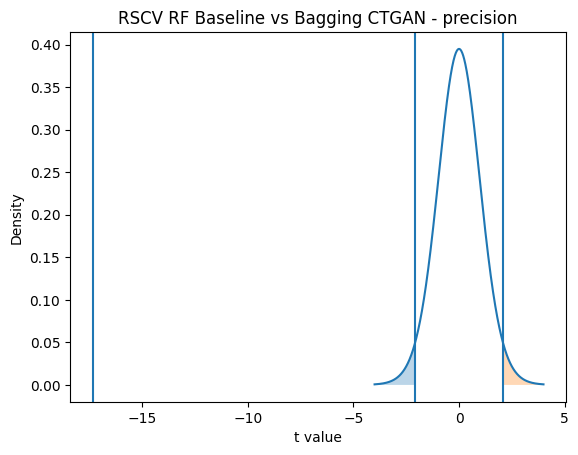

Model 1: RSCV RF Baseline
Model 2: Bagging CTGAN
Metric : recall
t value: -444.65357484443734
p value: 1.647083403317467e-48
t critical: 2.0638985616280205


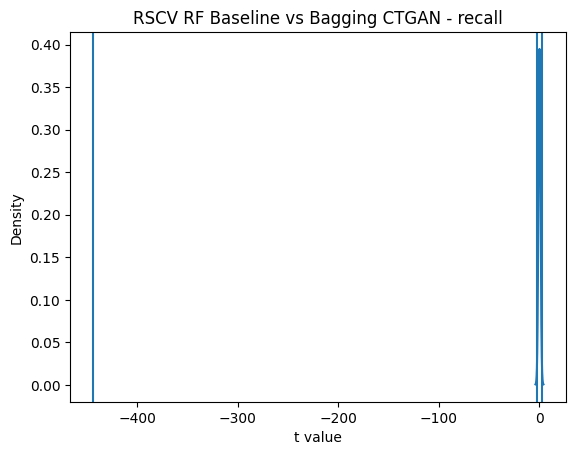

Model 1: RSCV RF Baseline
Model 2: Bagging CTGAN
Metric : f1
t value: -325.8515077653795
p value: 2.8591738655106374e-45
t critical: 2.0638985616280205


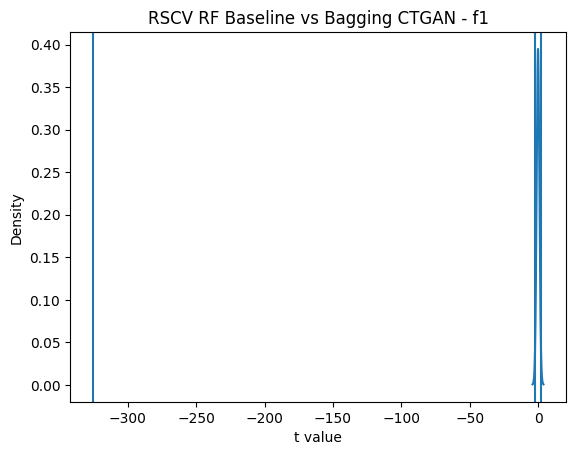

Model 1: RSCV RF Baseline
Model 2: Bagging CTGAN
Metric : roc_auc
t value: -163.31095676553645
p value: 4.497505207122461e-38
t critical: 2.0638985616280205


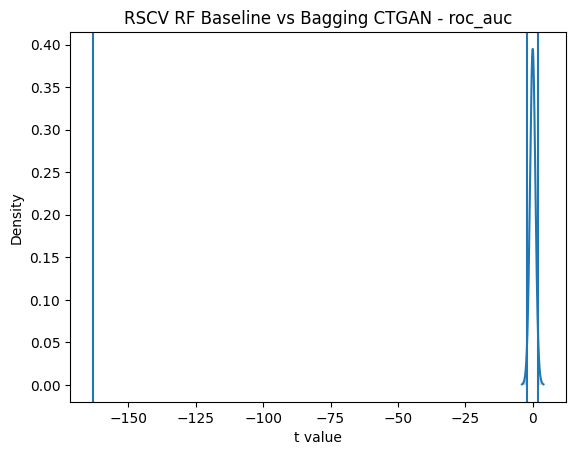

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging Baseline
Metric : accuracy
t value: 2.6443913771217096
p value: 0.014200400145679071
t critical: 2.0638985616280205


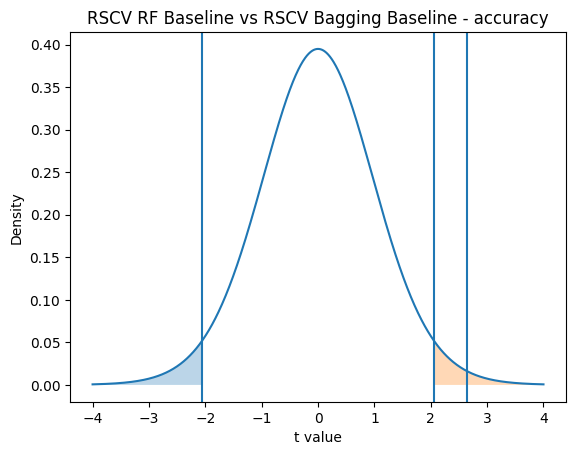

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging Baseline
Metric : precision
t value: -2.3390511351740546
p value: 0.027988650500140082
t critical: 2.0638985616280205


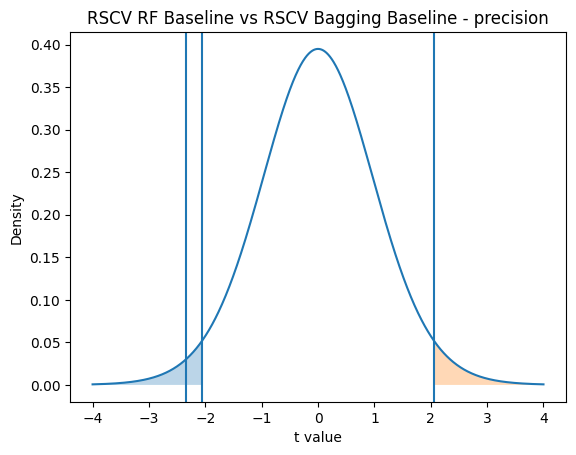

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging Baseline
Metric : recall
t value: -4.574381577997042
p value: 0.000122571598366845
t critical: 2.0638985616280205


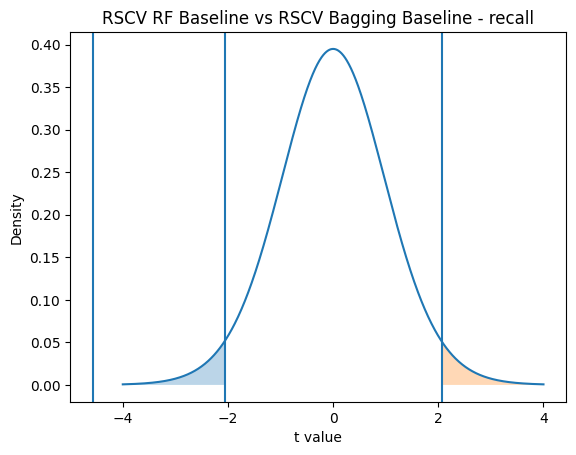

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging Baseline
Metric : f1
t value: -8.685759766191305
p value: 7.141543097633145e-09
t critical: 2.0638985616280205


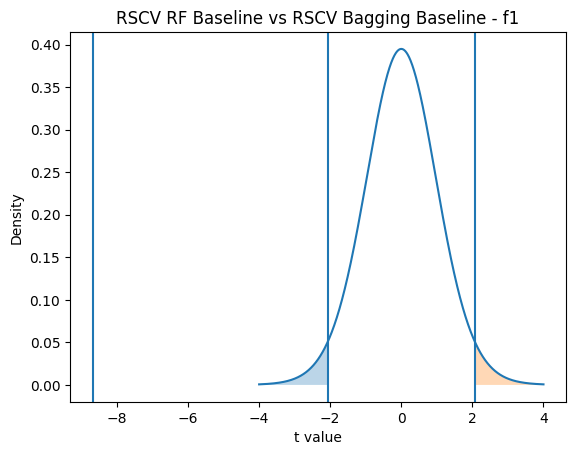

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging Baseline
Metric : roc_auc
t value: -1.72798557029749
p value: 0.09683868258623059
t critical: 2.0638985616280205


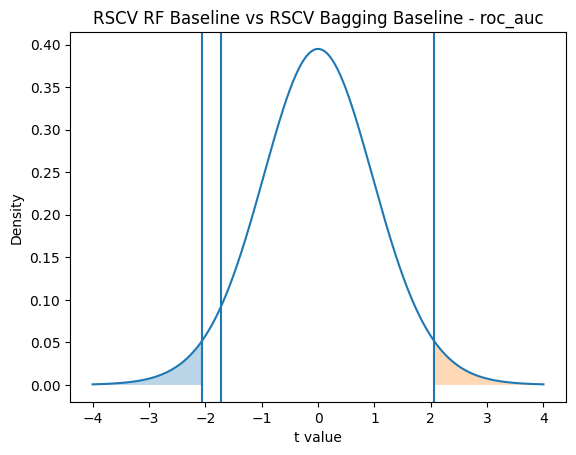

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging SMOTENC
Metric : accuracy
t value: -20.306766069748868
p value: 1.2675574903744002e-16
t critical: 2.0638985616280205


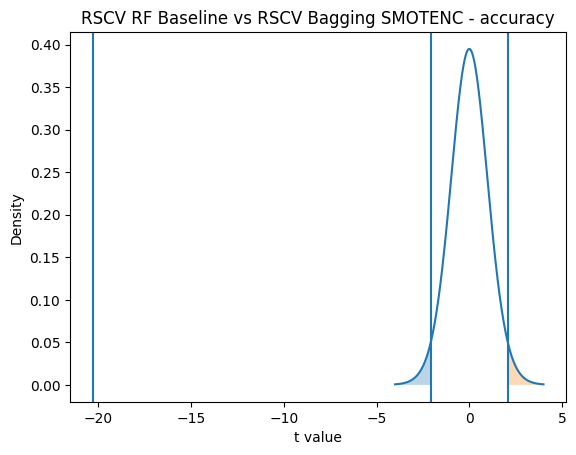

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging SMOTENC
Metric : precision
t value: -11.804024051996121
p value: 1.756187783347014e-11
t critical: 2.0638985616280205


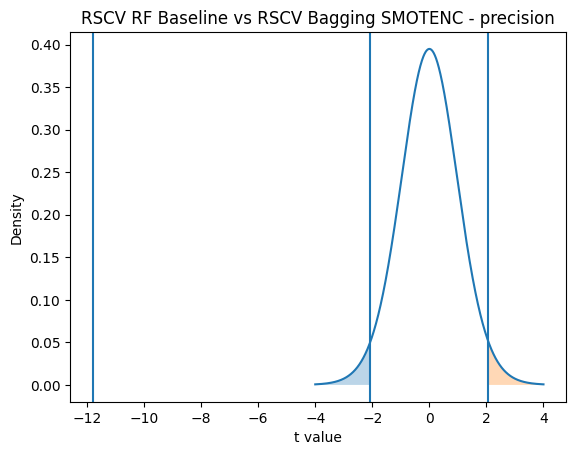

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging SMOTENC
Metric : recall
t value: -115.8767675074285
p value: 1.6787462085446935e-34
t critical: 2.0638985616280205


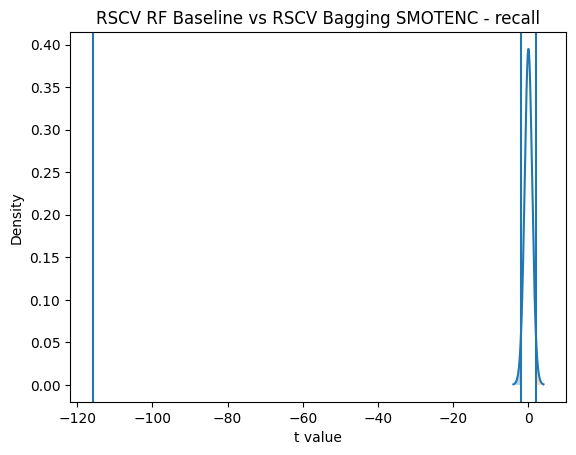

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging SMOTENC
Metric : f1
t value: -130.8803837387978
p value: 9.074888332554315e-36
t critical: 2.0638985616280205


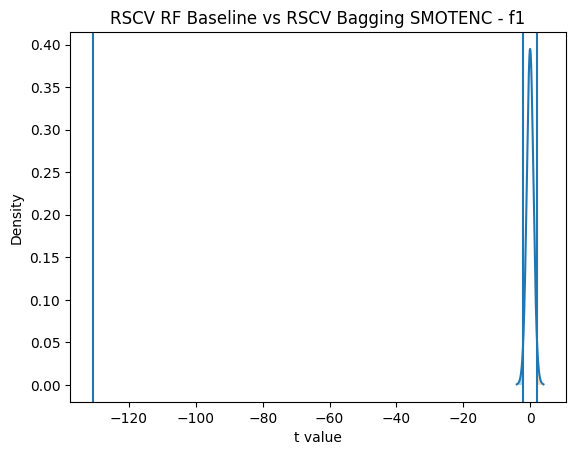

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging SMOTENC
Metric : roc_auc
t value: -84.15562931371528
p value: 3.55547563699162e-31
t critical: 2.0638985616280205


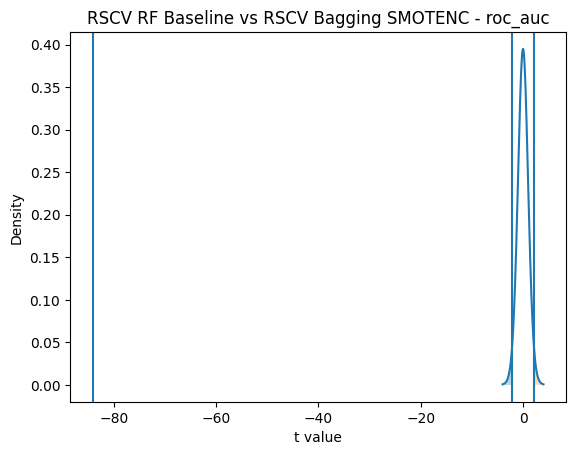

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging CTGAN
Metric : accuracy
t value: -71.80857125794091
p value: 1.578870459988528e-29
t critical: 2.0638985616280205


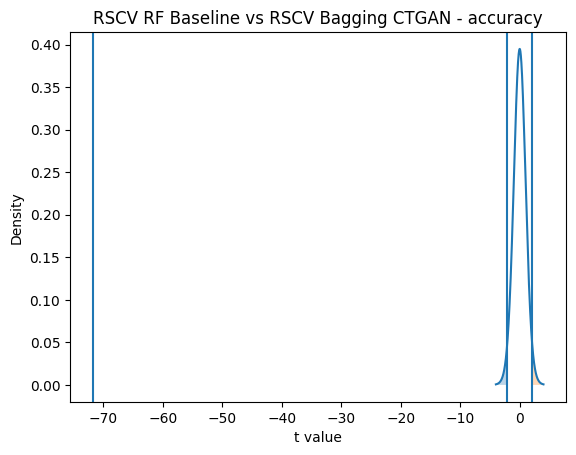

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging CTGAN
Metric : precision
t value: -16.270615031935066
p value: 1.8248744557571927e-14
t critical: 2.0638985616280205


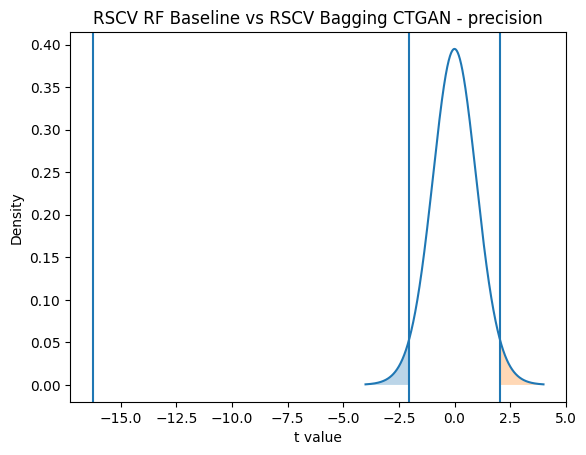

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging CTGAN
Metric : recall
t value: -167.2888773801685
p value: 2.5254661143719284e-38
t critical: 2.0638985616280205


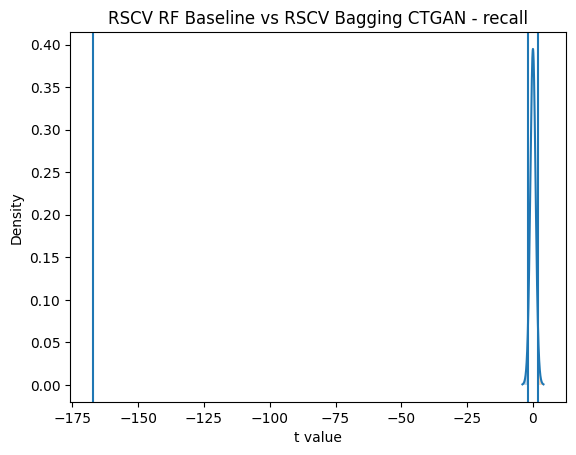

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging CTGAN
Metric : f1
t value: -174.97614412473254
p value: 8.598603940071586e-39
t critical: 2.0638985616280205


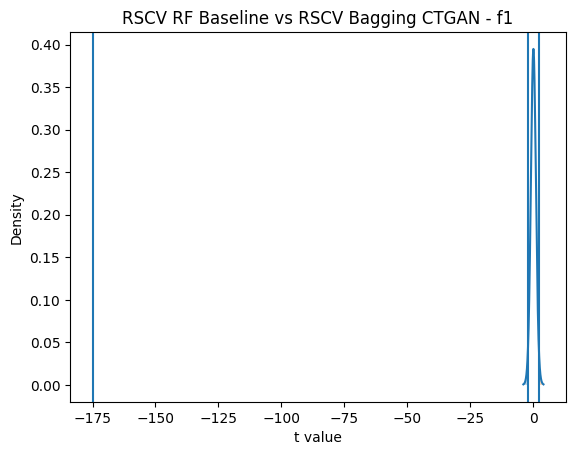

Model 1: RSCV RF Baseline
Model 2: RSCV Bagging CTGAN
Metric : roc_auc
t value: -147.70558066013268
p value: 4.998176084611972e-37
t critical: 2.0638985616280205


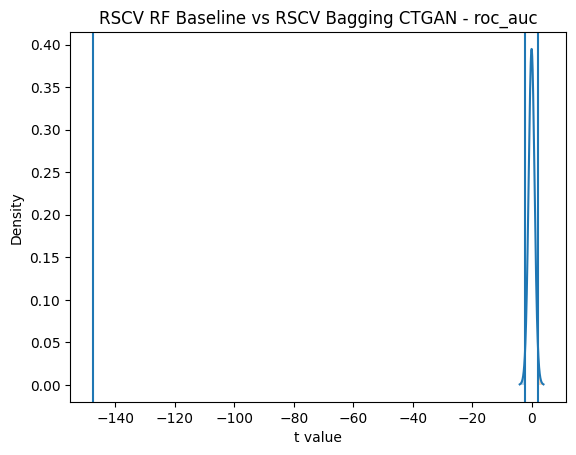

Model 1: RSCV RF SMOTENC
Model 2: RSCV RF CTGAN
Metric : accuracy
t value: -33.908374801260614
p value: 8.688676881782218e-22
t critical: 2.0638985616280205


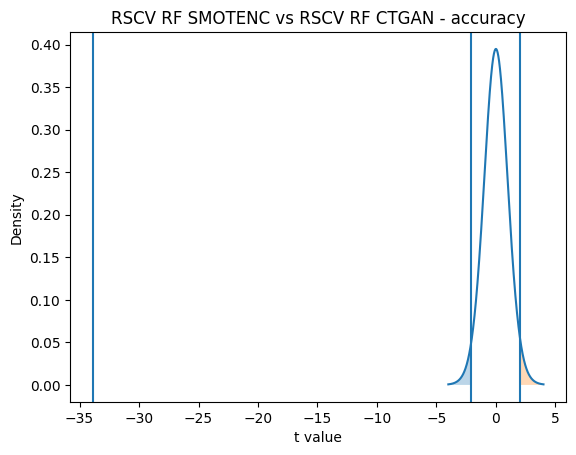

Model 1: RSCV RF SMOTENC
Model 2: RSCV RF CTGAN
Metric : precision
t value: -34.387803770640765
p value: 6.243850812414068e-22
t critical: 2.0638985616280205


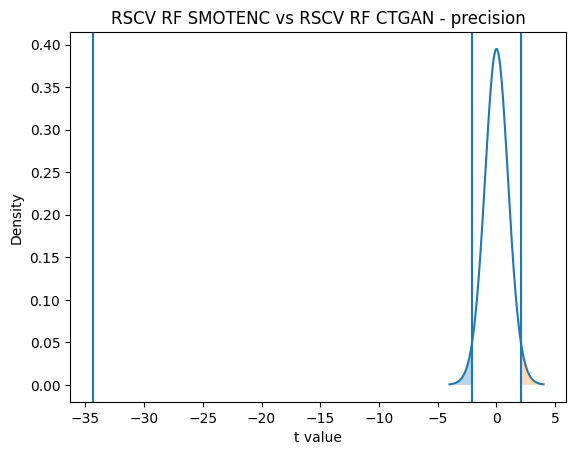

Model 1: RSCV RF SMOTENC
Model 2: RSCV RF CTGAN
Metric : recall
t value: -33.93711015097837
p value: 8.517220742028096e-22
t critical: 2.0638985616280205


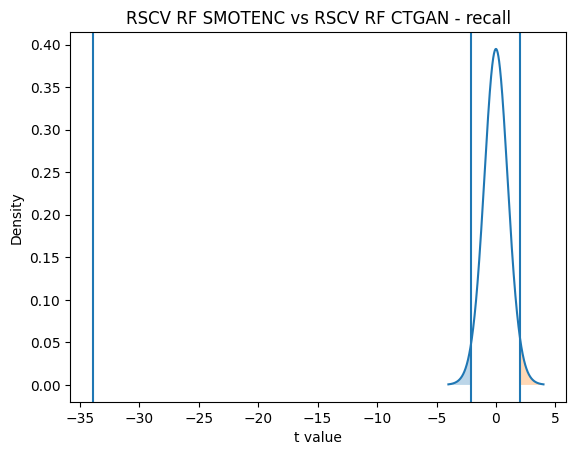

Model 1: RSCV RF SMOTENC
Model 2: RSCV RF CTGAN
Metric : f1
t value: -33.87915011159744
p value: 8.866740982690046e-22
t critical: 2.0638985616280205


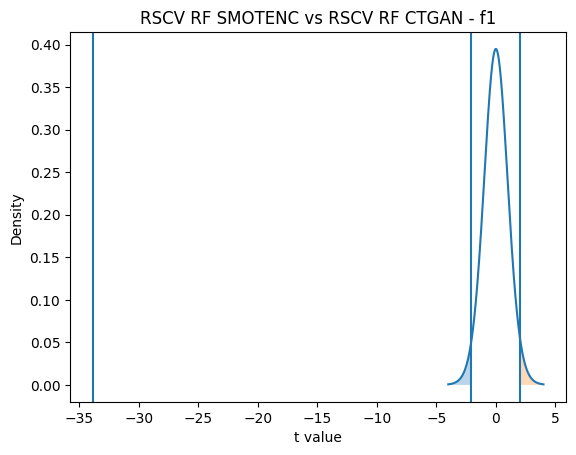

Model 1: RSCV RF SMOTENC
Model 2: RSCV RF CTGAN
Metric : roc_auc
t value: -33.801893640821305
p value: 9.355990177625763e-22
t critical: 2.0638985616280205


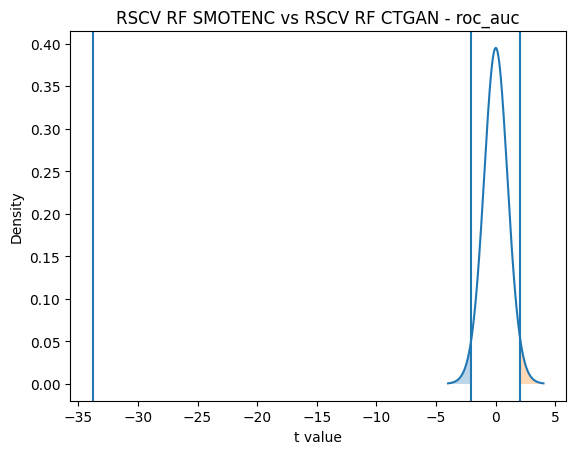

Model 1: RSCV RF SMOTENC
Model 2: Bagging Baseline
Metric : accuracy
t value: 9.174389444665138
p value: 2.5728773195888118e-09
t critical: 2.0638985616280205


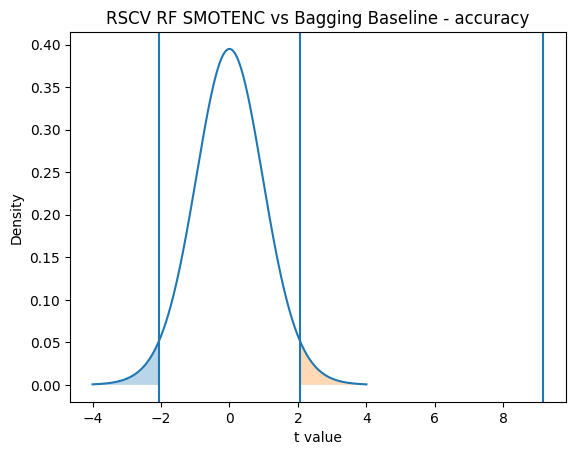

Model 1: RSCV RF SMOTENC
Model 2: Bagging Baseline
Metric : precision
t value: 17.2850418115406
p value: 4.7701408201942165e-15
t critical: 2.0638985616280205


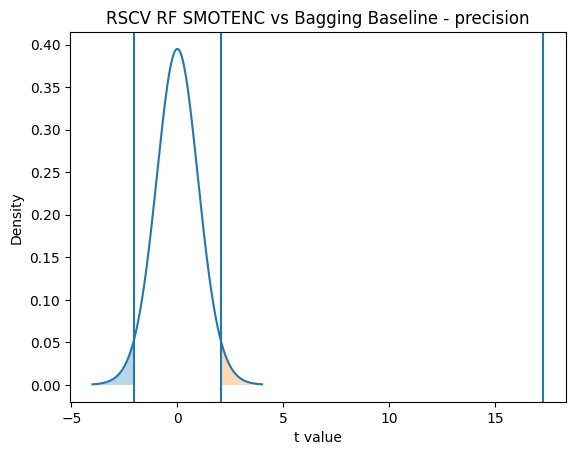

Model 1: RSCV RF SMOTENC
Model 2: Bagging Baseline
Metric : recall
t value: 72.58347906530389
p value: 1.2216975394638792e-29
t critical: 2.0638985616280205


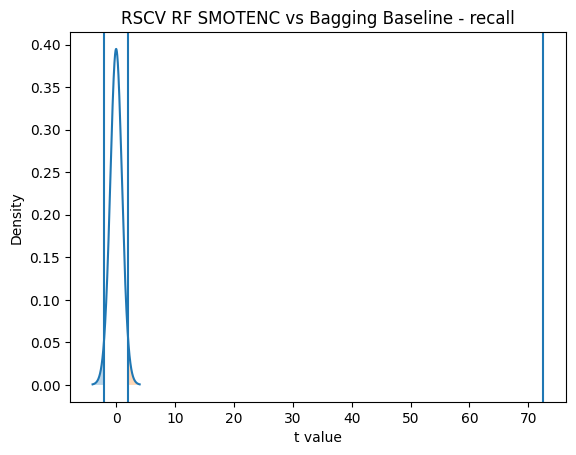

Model 1: RSCV RF SMOTENC
Model 2: Bagging Baseline
Metric : f1
t value: 37.12701805604718
p value: 1.0251426720246531e-22
t critical: 2.0638985616280205


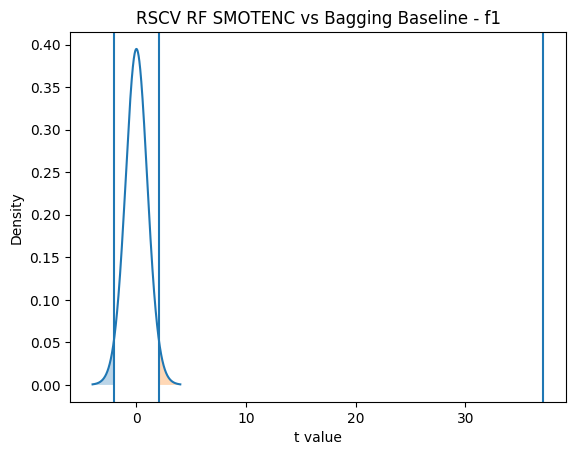

Model 1: RSCV RF SMOTENC
Model 2: Bagging Baseline
Metric : roc_auc
t value: 79.33525190309585
p value: 1.457425109894196e-30
t critical: 2.0638985616280205


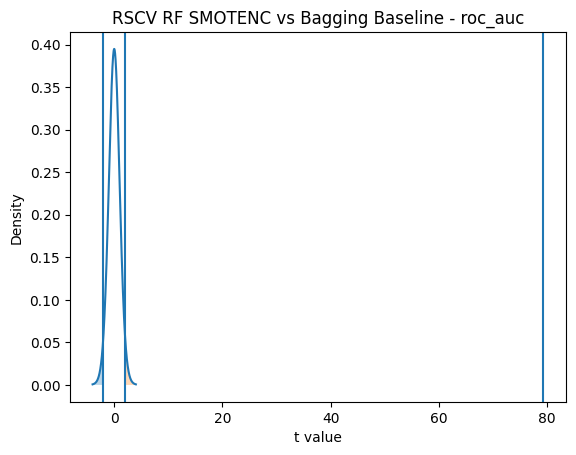

Model 1: RSCV RF SMOTENC
Model 2: Bagging SMOTENC
Metric : accuracy
t value: -0.6826285464221641
p value: 0.5013780105217676
t critical: 2.0638985616280205


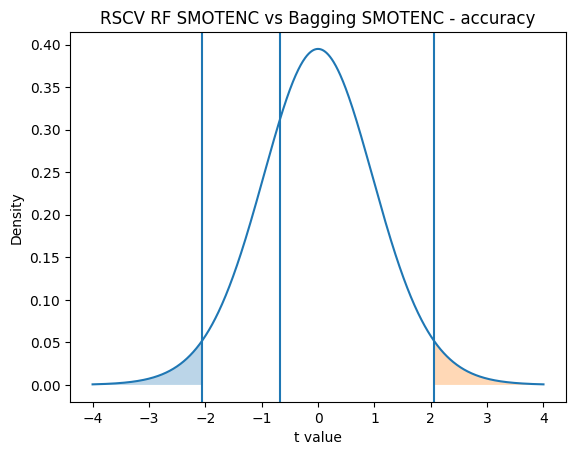

Model 1: RSCV RF SMOTENC
Model 2: Bagging SMOTENC
Metric : precision
t value: -0.7483052228796379
p value: 0.46154677201340943
t critical: 2.0638985616280205


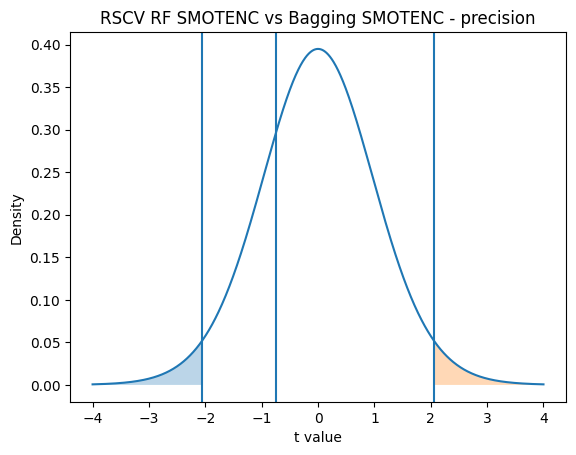

Model 1: RSCV RF SMOTENC
Model 2: Bagging SMOTENC
Metric : recall
t value: -0.6197594571631821
p value: 0.541256110238103
t critical: 2.0638985616280205


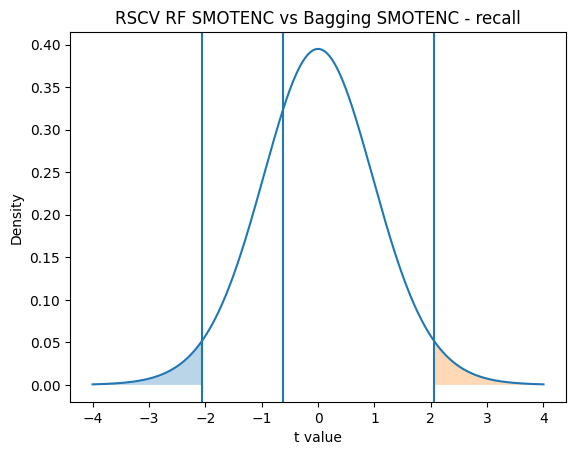

Model 1: RSCV RF SMOTENC
Model 2: Bagging SMOTENC
Metric : f1
t value: -0.6817543376039313
p value: 0.5019209762871462
t critical: 2.0638985616280205


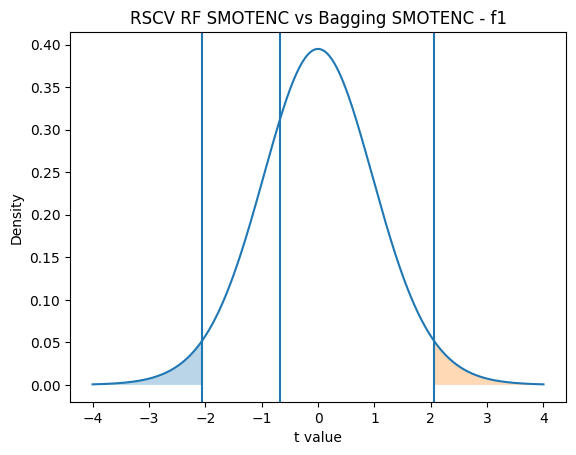

Model 1: RSCV RF SMOTENC
Model 2: Bagging SMOTENC
Metric : roc_auc
t value: -1.6148152357730896
p value: 0.1194225624535989
t critical: 2.0638985616280205


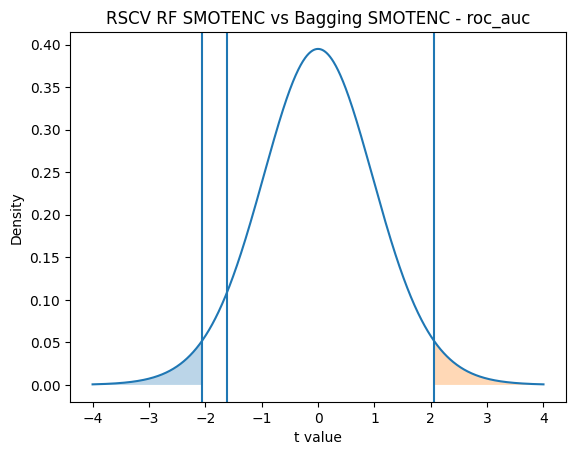

Model 1: RSCV RF SMOTENC
Model 2: Bagging CTGAN
Metric : accuracy
t value: -41.48659812692833
p value: 7.424451500878425e-24
t critical: 2.0638985616280205


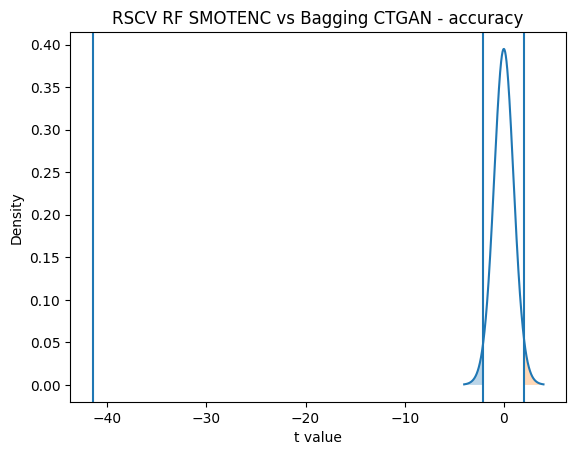

Model 1: RSCV RF SMOTENC
Model 2: Bagging CTGAN
Metric : precision
t value: -41.912682016102465
p value: 5.828483944862588e-24
t critical: 2.0638985616280205


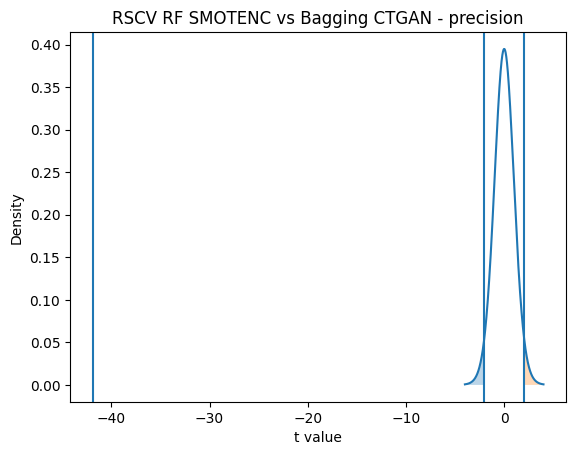

Model 1: RSCV RF SMOTENC
Model 2: Bagging CTGAN
Metric : recall
t value: -41.97327530706332
p value: 5.6323897483119295e-24
t critical: 2.0638985616280205


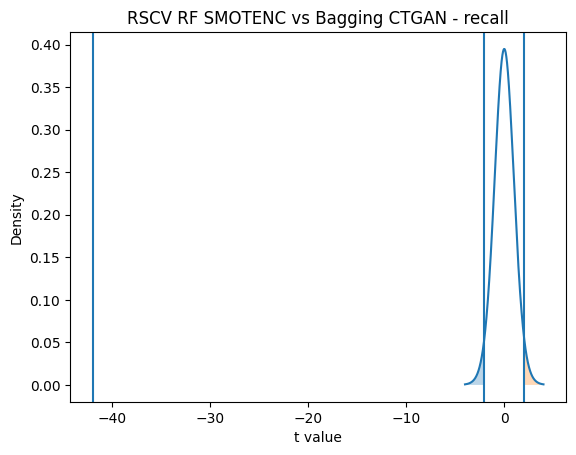

Model 1: RSCV RF SMOTENC
Model 2: Bagging CTGAN
Metric : f1
t value: -41.60750035639968
p value: 6.929997855010534e-24
t critical: 2.0638985616280205


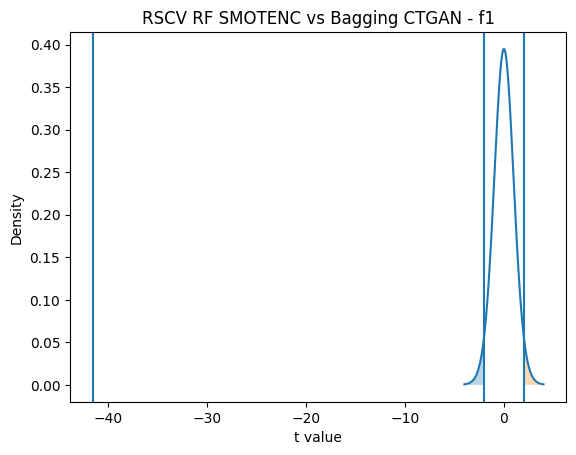

Model 1: RSCV RF SMOTENC
Model 2: Bagging CTGAN
Metric : roc_auc
t value: -42.033666241709426
p value: 5.44377557877503e-24
t critical: 2.0638985616280205


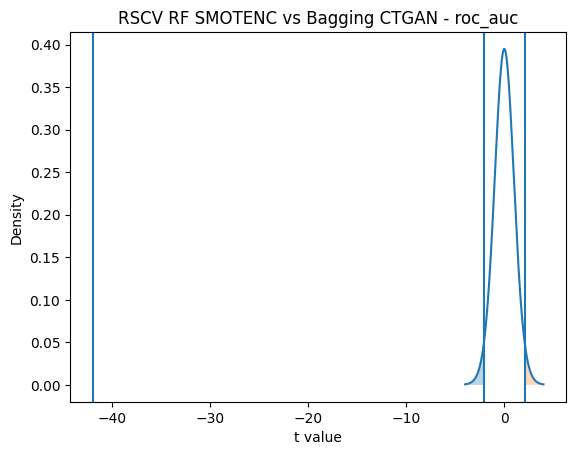

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging Baseline
Metric : accuracy
t value: 22.227708775039634
p value: 1.6094110592610877e-17
t critical: 2.0638985616280205


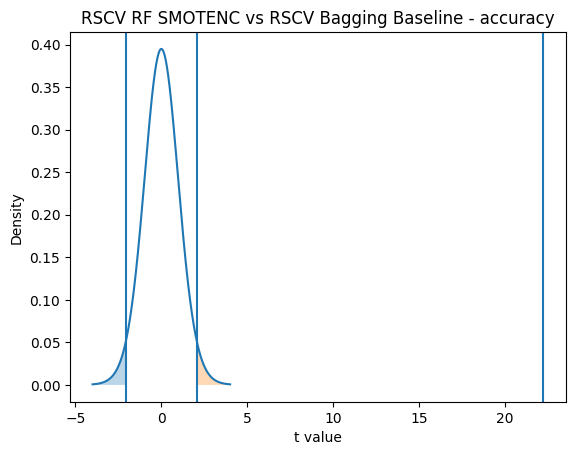

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging Baseline
Metric : precision
t value: 25.619145614889245
p value: 6.085827429551076e-19
t critical: 2.0638985616280205


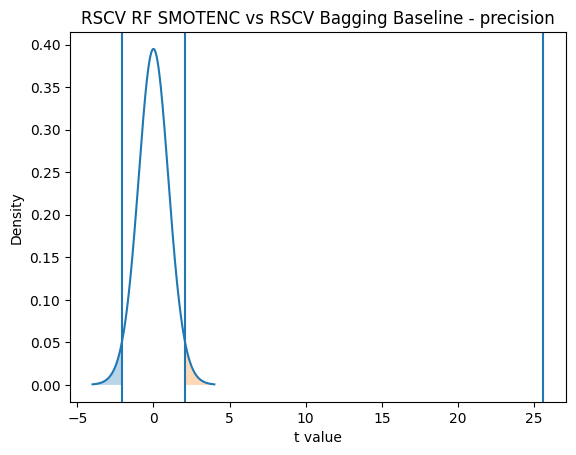

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging Baseline
Metric : recall
t value: 89.98480551076085
p value: 7.160701812712053e-32
t critical: 2.0638985616280205


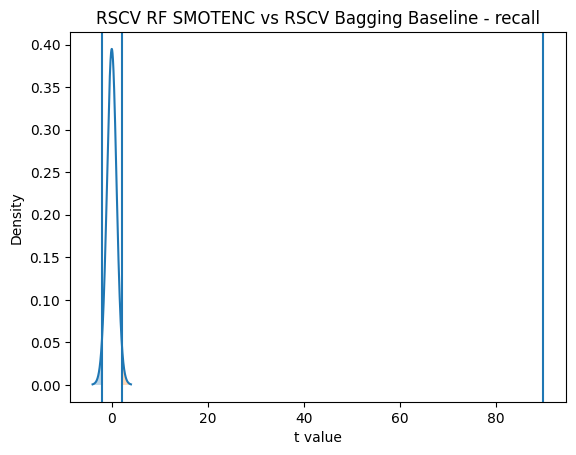

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging Baseline
Metric : f1
t value: 88.54156024475688
p value: 1.0543800523723666e-31
t critical: 2.0638985616280205


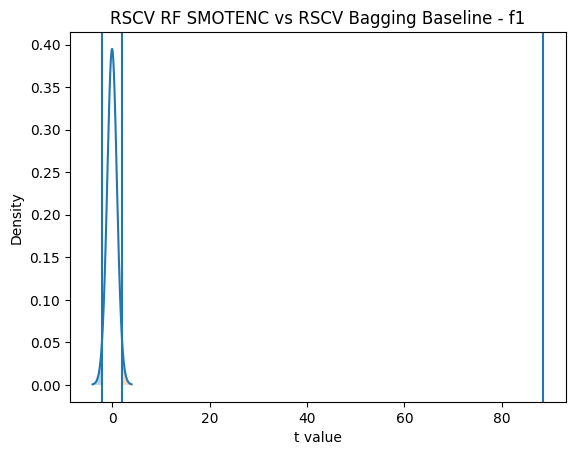

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging Baseline
Metric : roc_auc
t value: 115.68853577206451
p value: 1.7454244715080859e-34
t critical: 2.0638985616280205


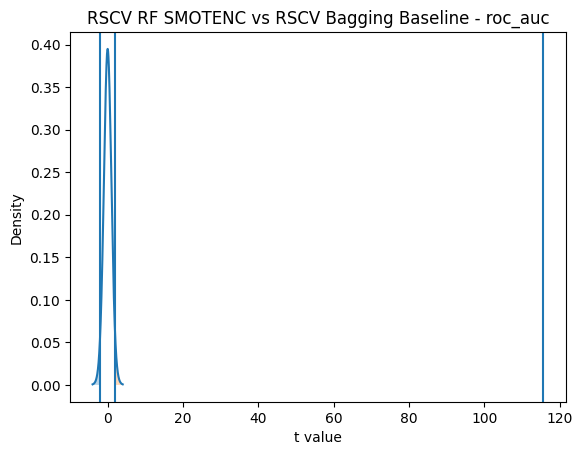

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : accuracy
t value: 5.503589080689048
p value: 1.168301304398418e-05
t critical: 2.0638985616280205


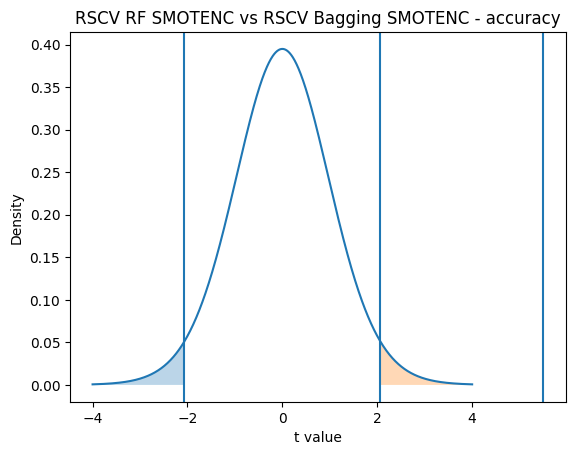

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : precision
t value: 5.346576054364338
p value: 1.7324794529711882e-05
t critical: 2.0638985616280205


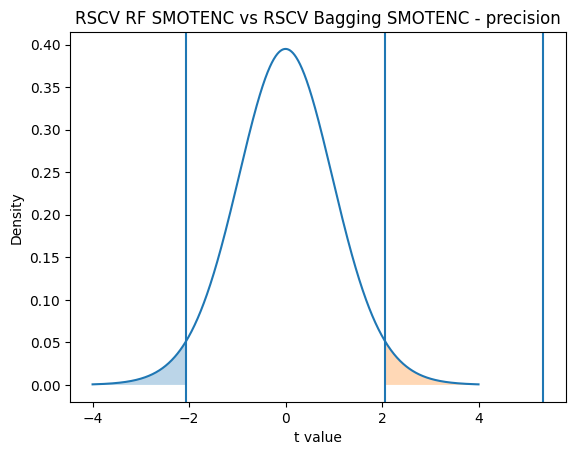

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : recall
t value: 5.490324626074596
p value: 1.2077580323939905e-05
t critical: 2.0638985616280205


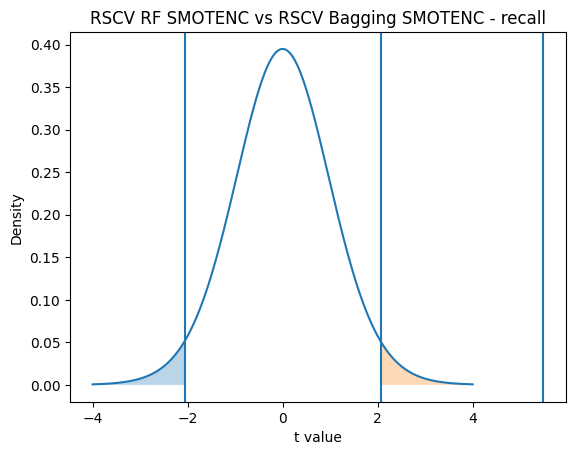

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : f1
t value: 5.5296997473200005
p value: 1.0944018946222716e-05
t critical: 2.0638985616280205


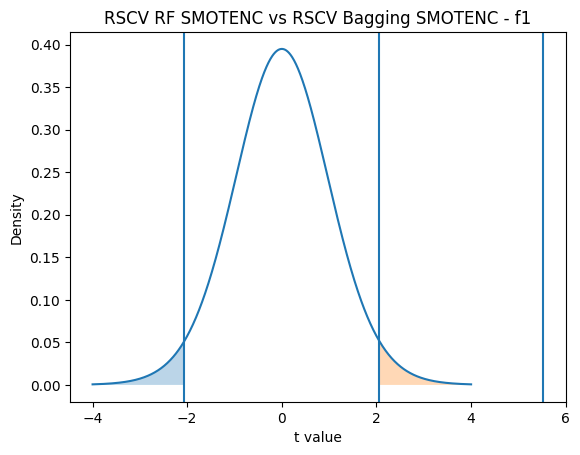

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : roc_auc
t value: 6.2272896983040065
p value: 1.95364783163624e-06
t critical: 2.0638985616280205


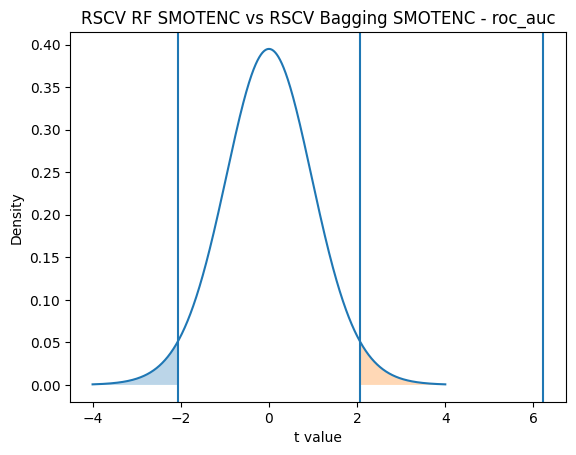

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : accuracy
t value: -27.953650570559592
p value: 8.011651782759292e-20
t critical: 2.0638985616280205


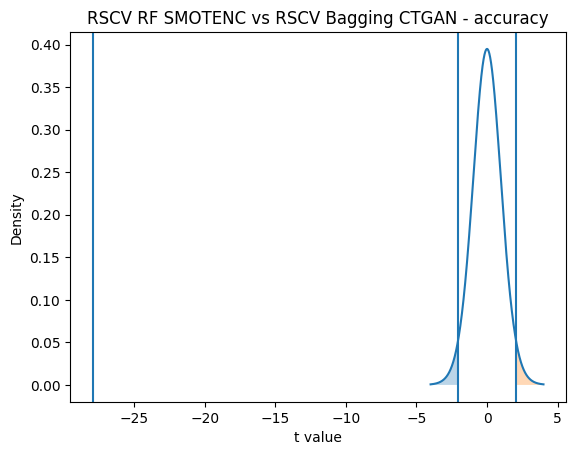

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : precision
t value: -27.974383935307024
p value: 7.874361951521428e-20
t critical: 2.0638985616280205


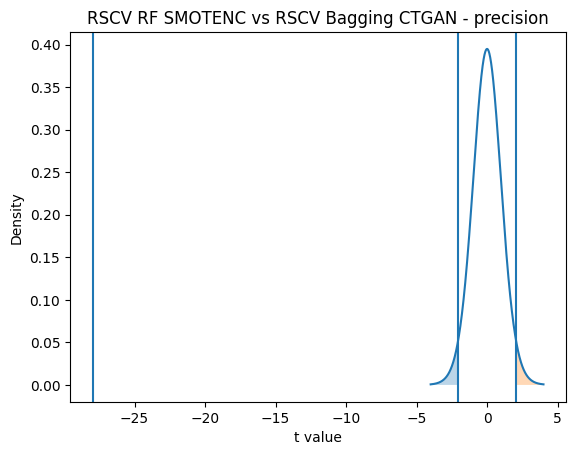

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : recall
t value: -28.031975542046023
p value: 7.505702256979594e-20
t critical: 2.0638985616280205


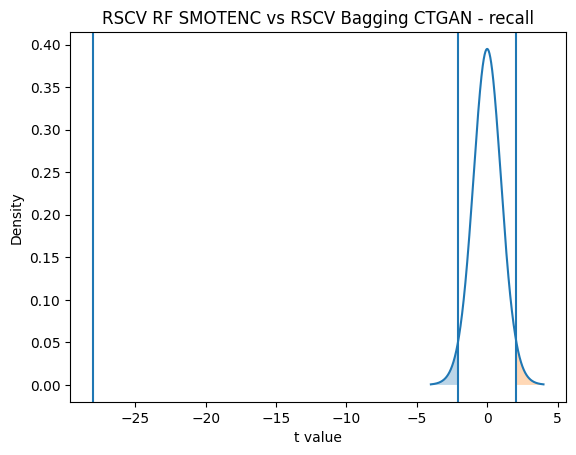

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : f1
t value: -27.960972419959685
p value: 7.962886538758731e-20
t critical: 2.0638985616280205


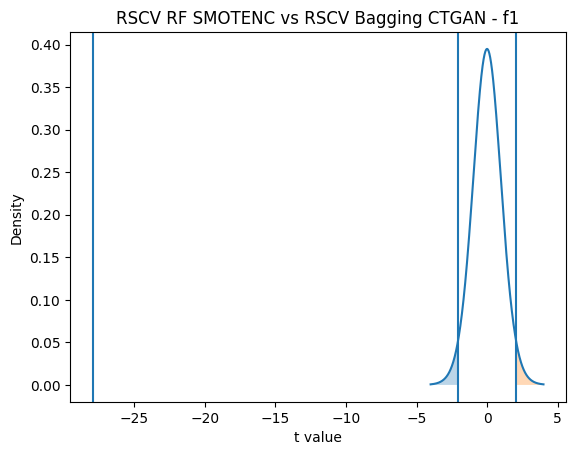

Model 1: RSCV RF SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : roc_auc
t value: -31.626167674765124
p value: 4.46585613062347e-21
t critical: 2.0638985616280205


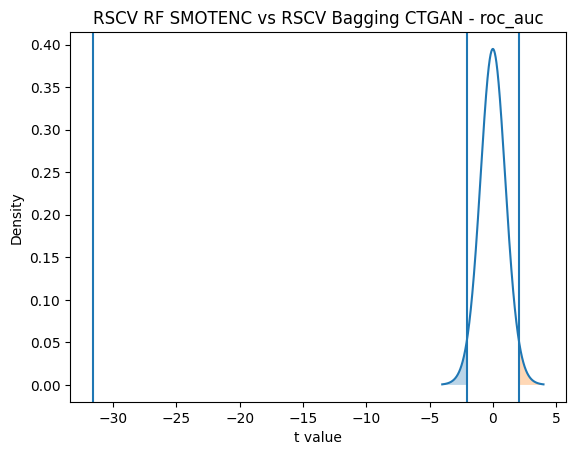

Model 1: RSCV RF CTGAN
Model 2: Bagging Baseline
Metric : accuracy
t value: 18.007929021774128
p value: 1.909402849631461e-15
t critical: 2.0638985616280205


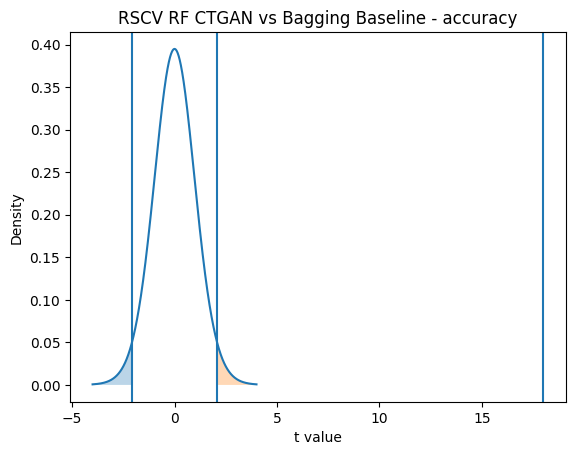

Model 1: RSCV RF CTGAN
Model 2: Bagging Baseline
Metric : precision
t value: 25.895900092256344
p value: 4.74336778195997e-19
t critical: 2.0638985616280205


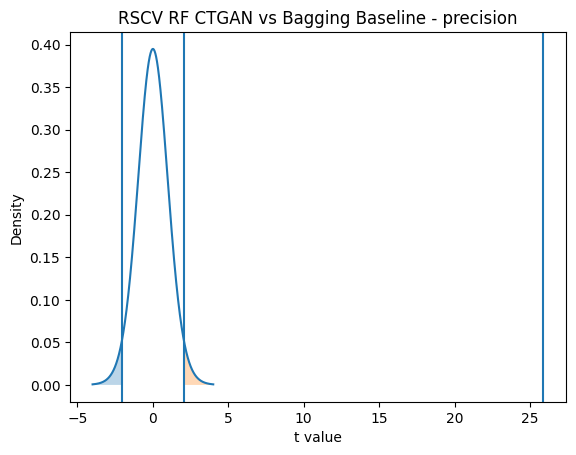

Model 1: RSCV RF CTGAN
Model 2: Bagging Baseline
Metric : recall
t value: 160.26534191630438
p value: 7.063432949112162e-38
t critical: 2.0638985616280205


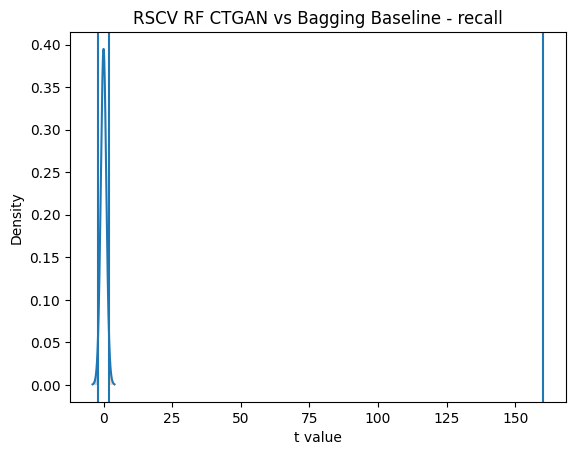

Model 1: RSCV RF CTGAN
Model 2: Bagging Baseline
Metric : f1
t value: 52.817269928229926
p value: 2.4004712360250578e-26
t critical: 2.0638985616280205


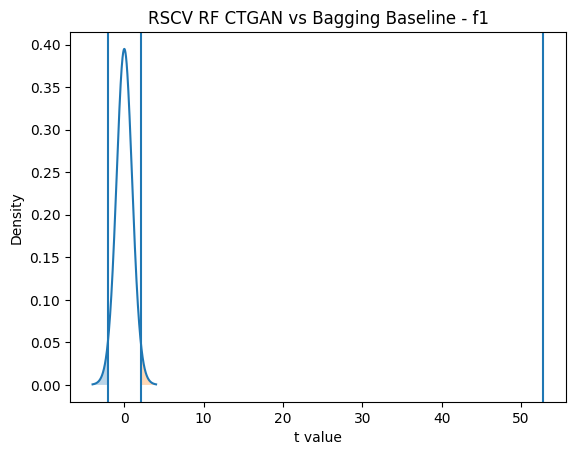

Model 1: RSCV RF CTGAN
Model 2: Bagging Baseline
Metric : roc_auc
t value: 139.67848148387515
p value: 1.9079987948362112e-36
t critical: 2.0638985616280205


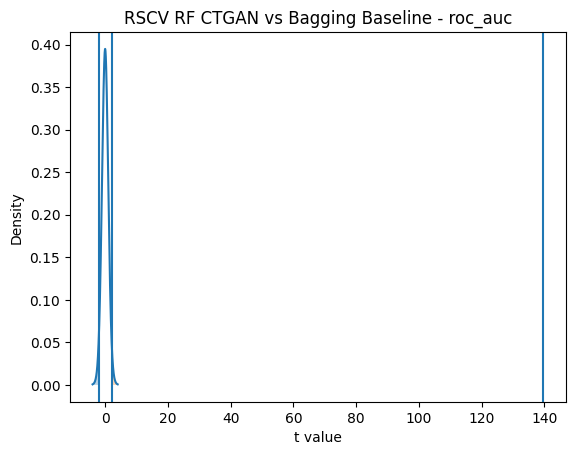

Model 1: RSCV RF CTGAN
Model 2: Bagging SMOTENC
Metric : accuracy
t value: 50.5647693031931
p value: 6.771345472337145e-26
t critical: 2.0638985616280205


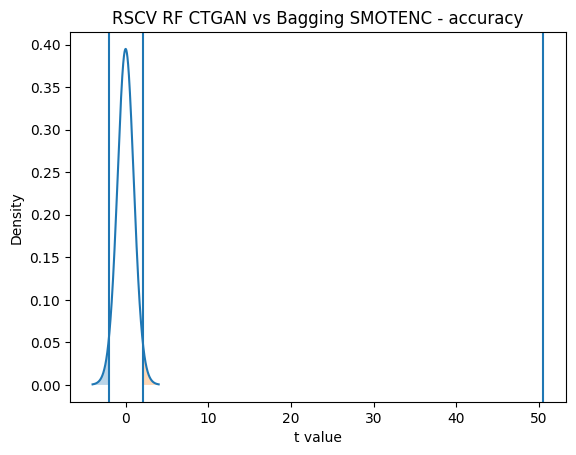

Model 1: RSCV RF CTGAN
Model 2: Bagging SMOTENC
Metric : precision
t value: 52.61181792172777
p value: 2.633815830968403e-26
t critical: 2.0638985616280205


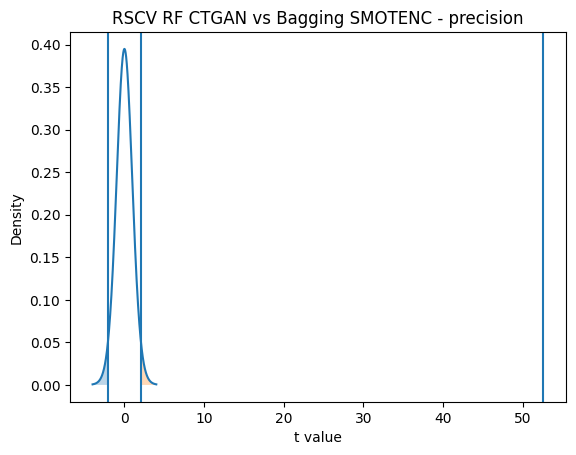

Model 1: RSCV RF CTGAN
Model 2: Bagging SMOTENC
Metric : recall
t value: 50.751618771342
p value: 6.202583791363642e-26
t critical: 2.0638985616280205


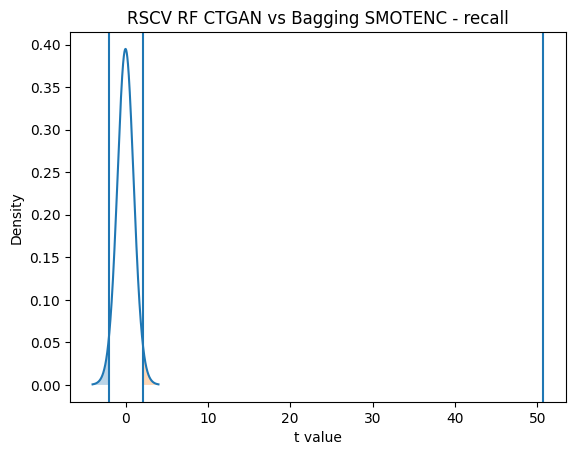

Model 1: RSCV RF CTGAN
Model 2: Bagging SMOTENC
Metric : f1
t value: 50.359859674869
p value: 7.457949391503992e-26
t critical: 2.0638985616280205


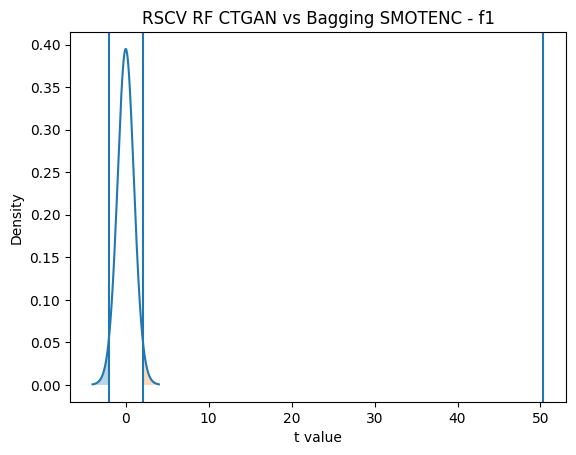

Model 1: RSCV RF CTGAN
Model 2: Bagging SMOTENC
Metric : roc_auc
t value: 71.35691455809781
p value: 1.8357647931105487e-29
t critical: 2.0638985616280205


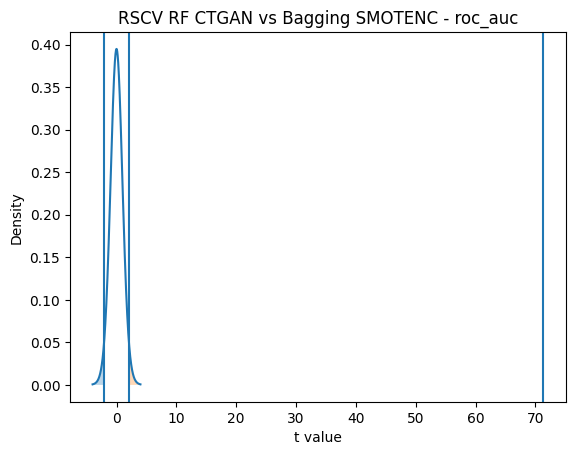

Model 1: RSCV RF CTGAN
Model 2: Bagging CTGAN
Metric : accuracy
t value: -7.79980549686189
p value: 4.927873656457132e-08
t critical: 2.0638985616280205


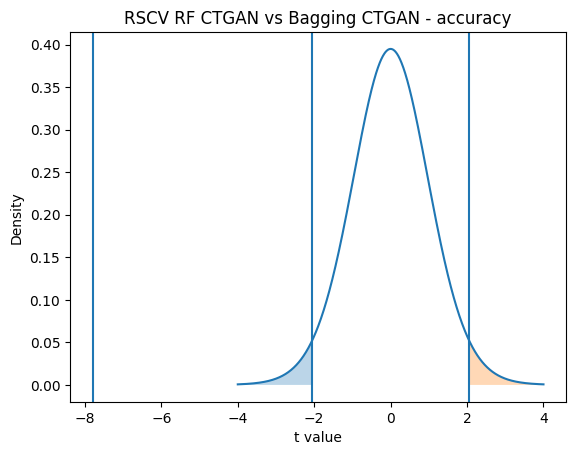

Model 1: RSCV RF CTGAN
Model 2: Bagging CTGAN
Metric : precision
t value: -8.169156735125565
p value: 2.1748266299503057e-08
t critical: 2.0638985616280205


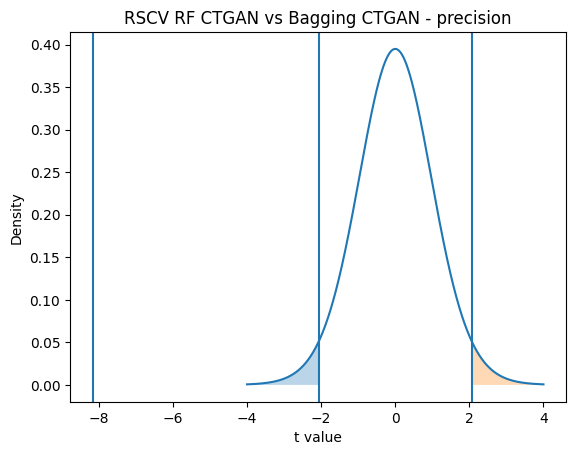

Model 1: RSCV RF CTGAN
Model 2: Bagging CTGAN
Metric : recall
t value: -7.758382218740977
p value: 5.407433997297149e-08
t critical: 2.0638985616280205


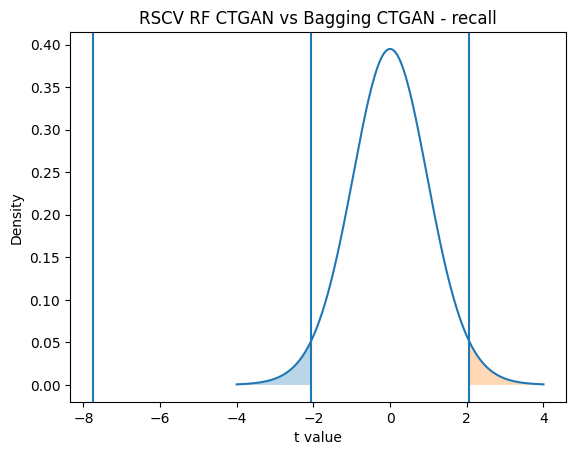

Model 1: RSCV RF CTGAN
Model 2: Bagging CTGAN
Metric : f1
t value: -7.777120173204068
p value: 5.18483351431075e-08
t critical: 2.0638985616280205


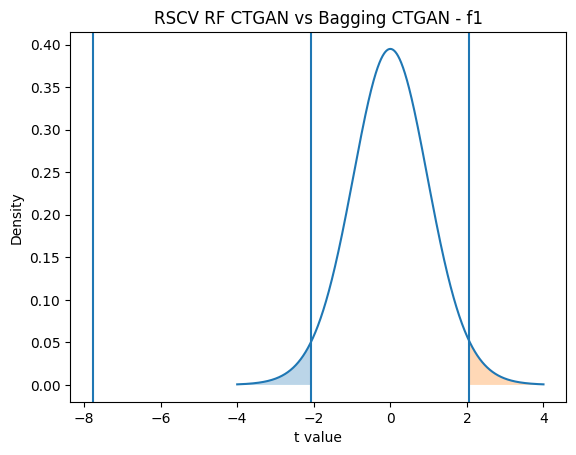

Model 1: RSCV RF CTGAN
Model 2: Bagging CTGAN
Metric : roc_auc
t value: -8.76682390571043
p value: 6.015827514374069e-09
t critical: 2.0638985616280205


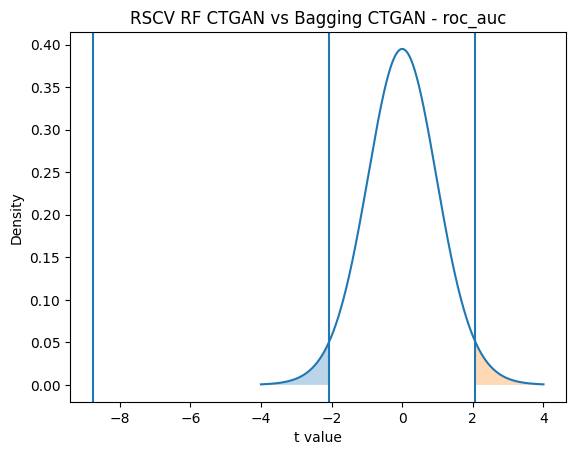

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging Baseline
Metric : accuracy
t value: 90.70136479740178
p value: 5.922666859571776e-32
t critical: 2.0638985616280205


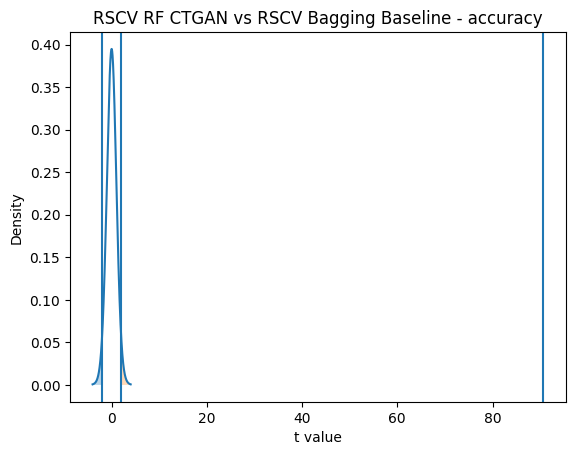

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging Baseline
Metric : precision
t value: 39.45454058103341
p value: 2.436956662635075e-23
t critical: 2.0638985616280205


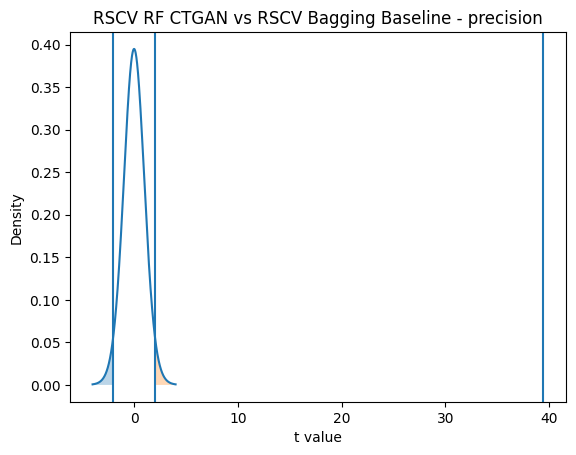

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging Baseline
Metric : recall
t value: 196.18382303877067
p value: 5.531033814239553e-40
t critical: 2.0638985616280205


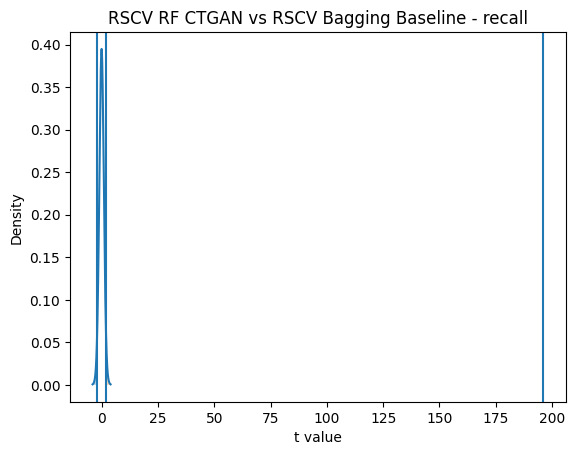

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging Baseline
Metric : f1
t value: 172.6942151736308
p value: 1.1780094594225867e-38
t critical: 2.0638985616280205


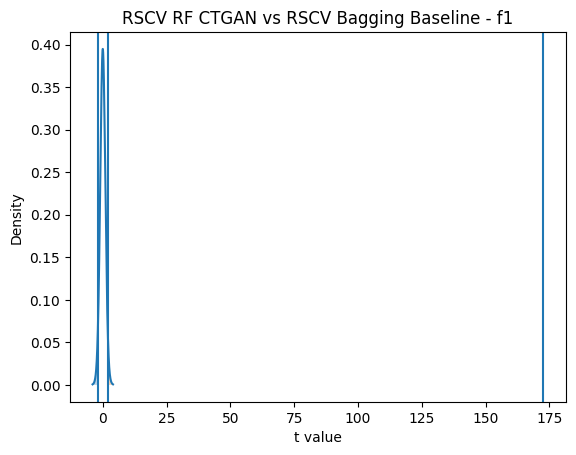

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging Baseline
Metric : roc_auc
t value: 151.05097614560867
p value: 2.921551860817044e-37
t critical: 2.0638985616280205


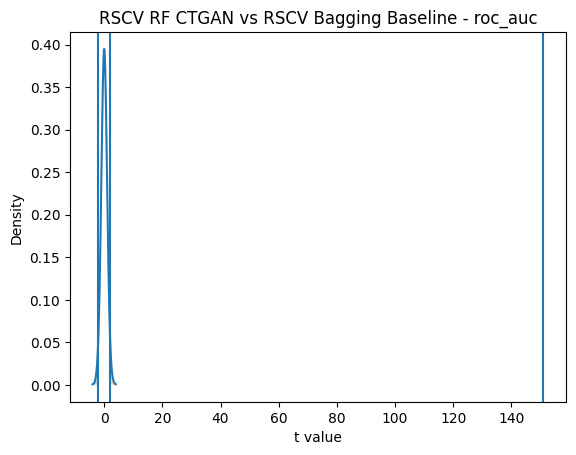

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : accuracy
t value: 40.45004819835561
p value: 1.3515093289210002e-23
t critical: 2.0638985616280205


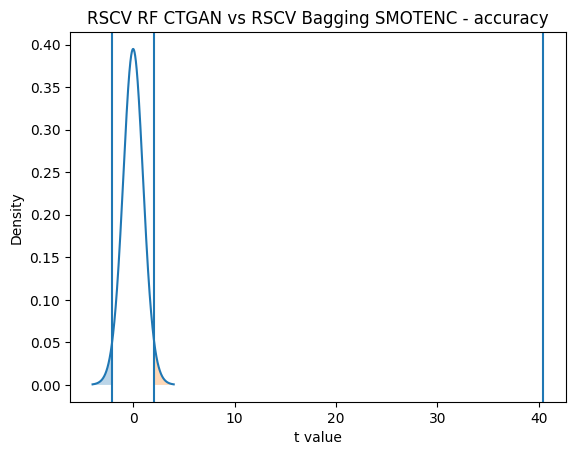

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : precision
t value: 40.58938947069219
p value: 1.2458684748261055e-23
t critical: 2.0638985616280205


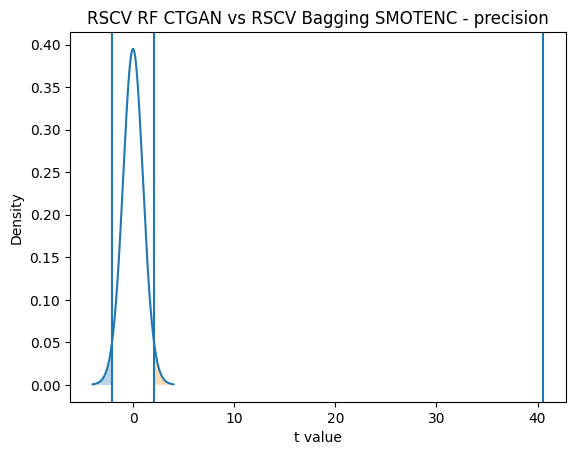

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : recall
t value: 40.601168861887594
p value: 1.237341321676858e-23
t critical: 2.0638985616280205


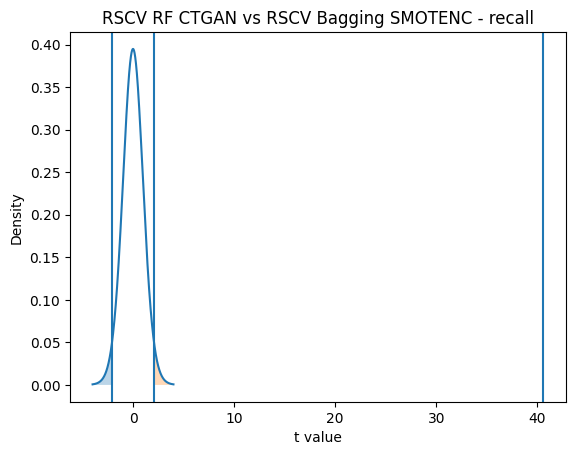

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : f1
t value: 40.54894537254809
p value: 1.2756147336749246e-23
t critical: 2.0638985616280205


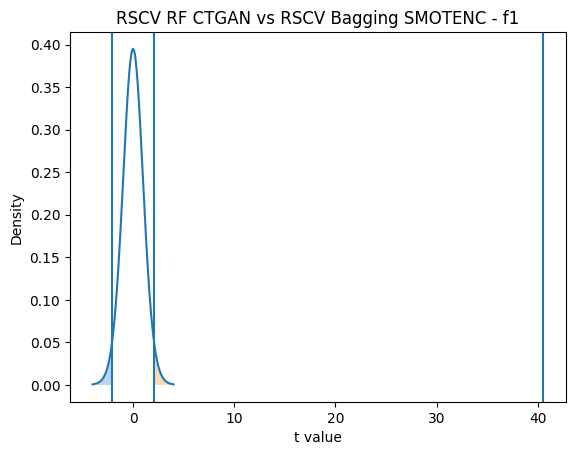

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : roc_auc
t value: 36.50243814652769
p value: 1.5298960823068442e-22
t critical: 2.0638985616280205


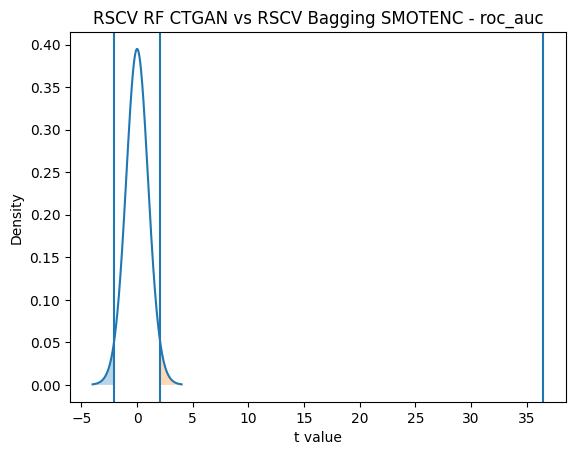

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging CTGAN
Metric : accuracy
t value: 4.927588160729812
p value: 4.994674184202733e-05
t critical: 2.0638985616280205


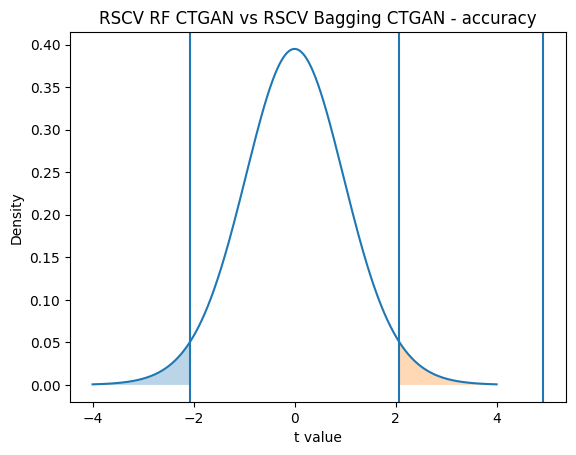

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging CTGAN
Metric : precision
t value: 4.887690184445773
p value: 5.526886504529641e-05
t critical: 2.0638985616280205


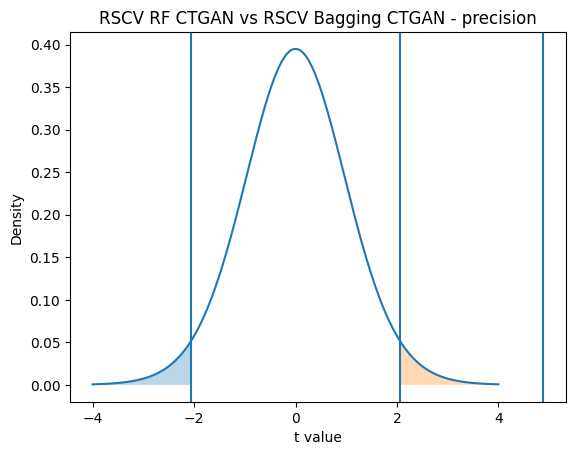

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging CTGAN
Metric : recall
t value: 4.932969297904142
p value: 4.92695109482086e-05
t critical: 2.0638985616280205


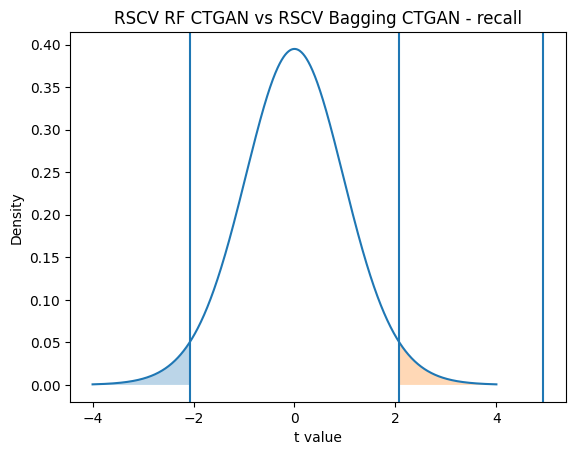

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging CTGAN
Metric : f1
t value: 4.930208180067008
p value: 4.9615843650843045e-05
t critical: 2.0638985616280205


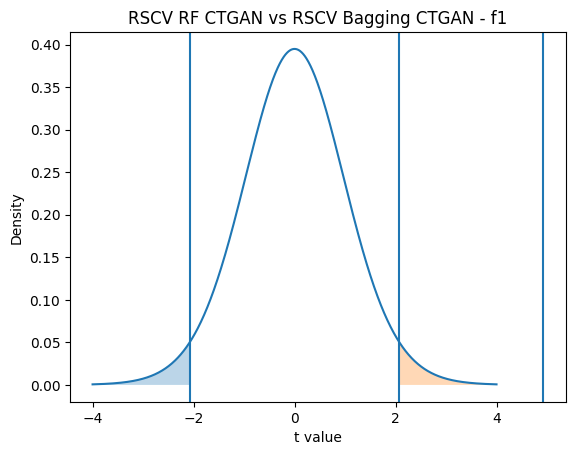

Model 1: RSCV RF CTGAN
Model 2: RSCV Bagging CTGAN
Metric : roc_auc
t value: 13.081655696781704
p value: 2.0518728653957964e-12
t critical: 2.0638985616280205


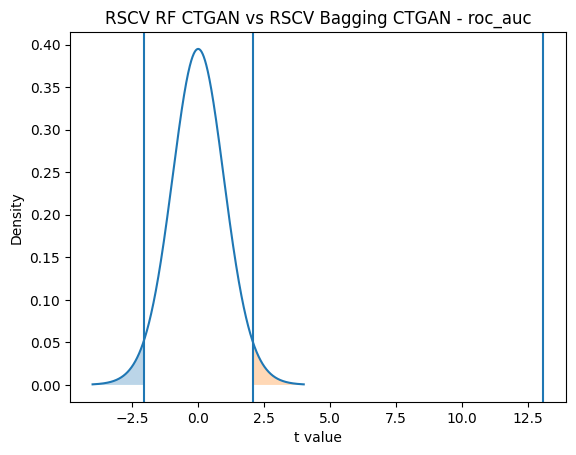

Model 1: Bagging Baseline
Model 2: Bagging SMOTENC
Metric : accuracy
t value: -9.56420949705957
p value: 1.1650358424618413e-09
t critical: 2.0638985616280205


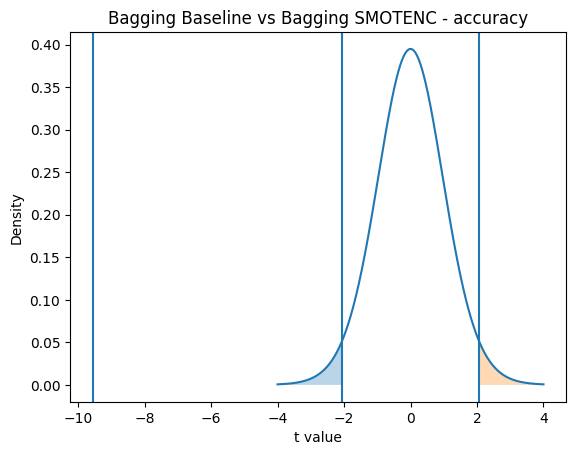

Model 1: Bagging Baseline
Model 2: Bagging SMOTENC
Metric : precision
t value: -18.089147716209297
p value: 1.7261914265121632e-15
t critical: 2.0638985616280205


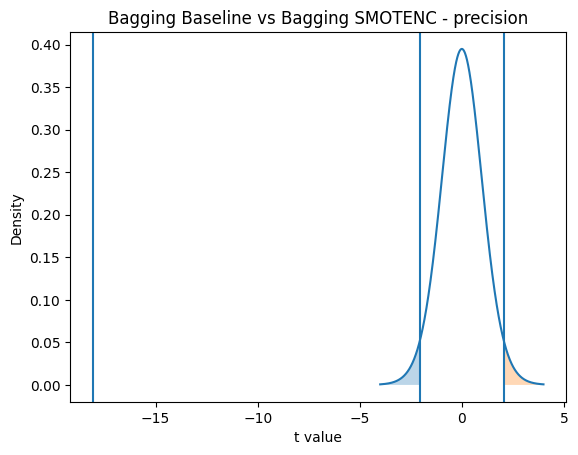

Model 1: Bagging Baseline
Model 2: Bagging SMOTENC
Metric : recall
t value: -126.6341661167555
p value: 2.0004661110291525e-35
t critical: 2.0638985616280205


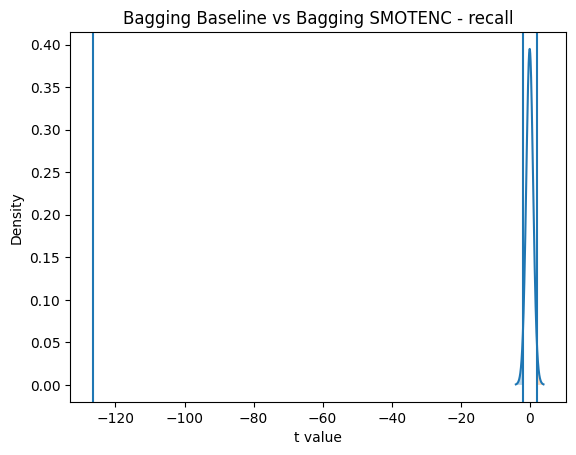

Model 1: Bagging Baseline
Model 2: Bagging SMOTENC
Metric : f1
t value: -42.21502285983412
p value: 4.915886715876608e-24
t critical: 2.0638985616280205


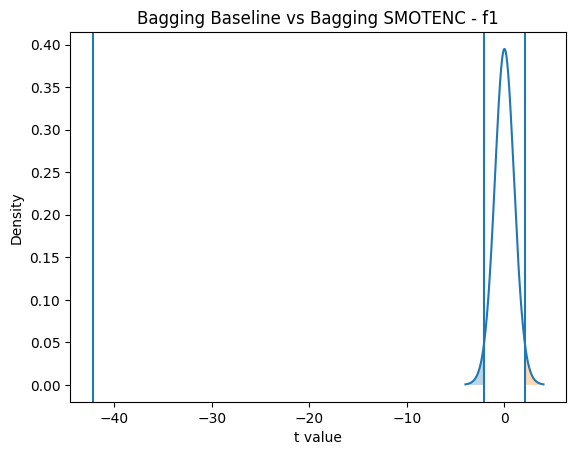

Model 1: Bagging Baseline
Model 2: Bagging SMOTENC
Metric : roc_auc
t value: -91.8280089377503
p value: 4.407583053847793e-32
t critical: 2.0638985616280205


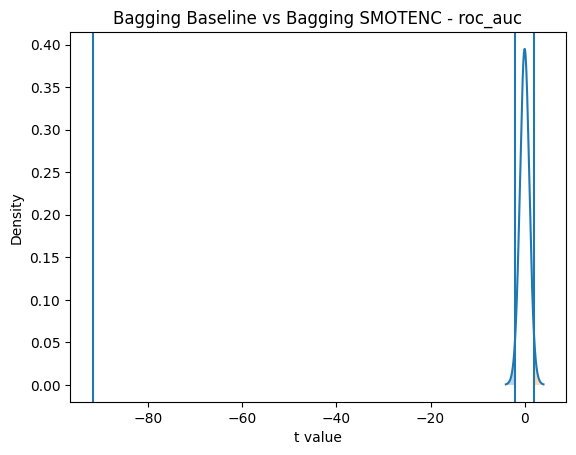

Model 1: Bagging Baseline
Model 2: Bagging CTGAN
Metric : accuracy
t value: -18.479883935165322
p value: 1.0682980127175442e-15
t critical: 2.0638985616280205


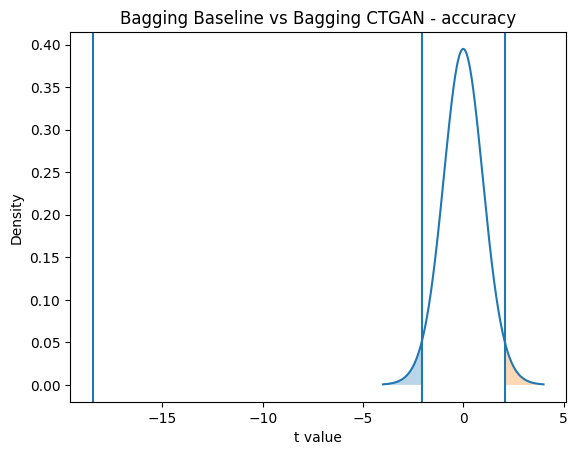

Model 1: Bagging Baseline
Model 2: Bagging CTGAN
Metric : precision
t value: -25.80596092956602
p value: 5.142108556354449e-19
t critical: 2.0638985616280205


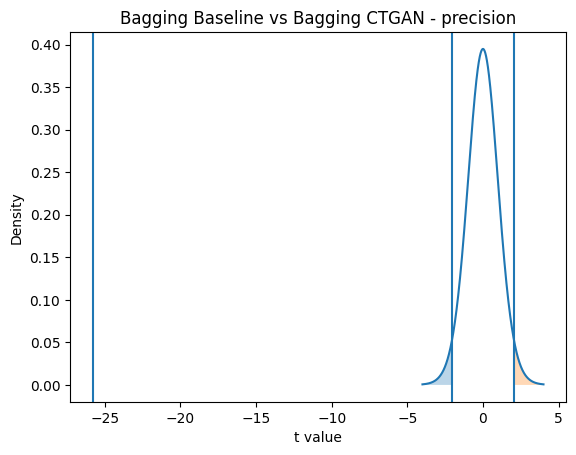

Model 1: Bagging Baseline
Model 2: Bagging CTGAN
Metric : recall
t value: -221.98740755176343
p value: 2.8544776650485557e-41
t critical: 2.0638985616280205


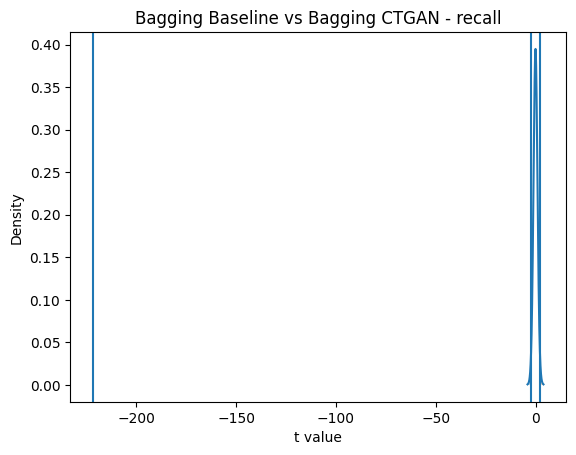

Model 1: Bagging Baseline
Model 2: Bagging CTGAN
Metric : f1
t value: -58.92156105648555
p value: 1.7731373490351692e-27
t critical: 2.0638985616280205


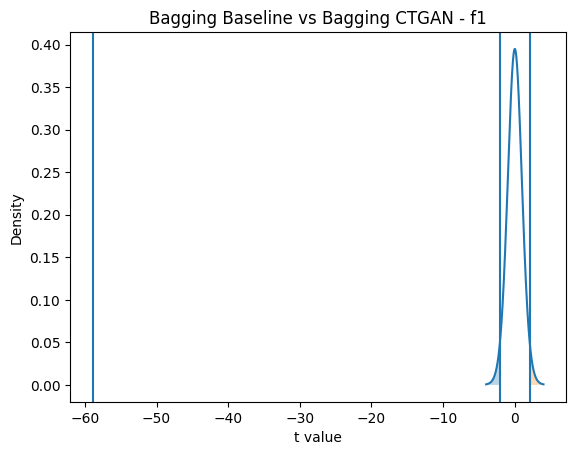

Model 1: Bagging Baseline
Model 2: Bagging CTGAN
Metric : roc_auc
t value: -128.36712505579553
p value: 1.4443150974222297e-35
t critical: 2.0638985616280205


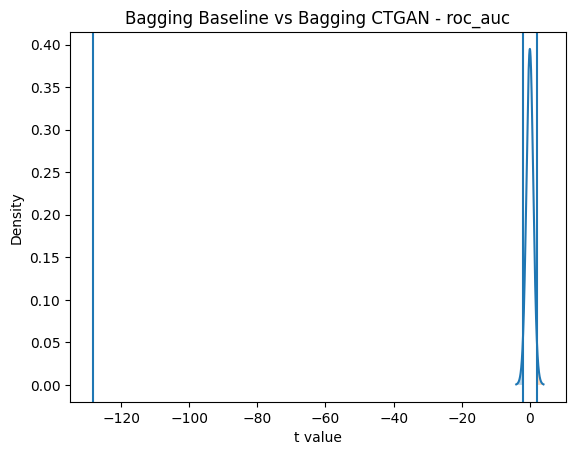

Model 1: Bagging Baseline
Model 2: RSCV Bagging Baseline
Metric : accuracy
t value: -4.835329217255625
p value: 6.312834302323488e-05
t critical: 2.0638985616280205


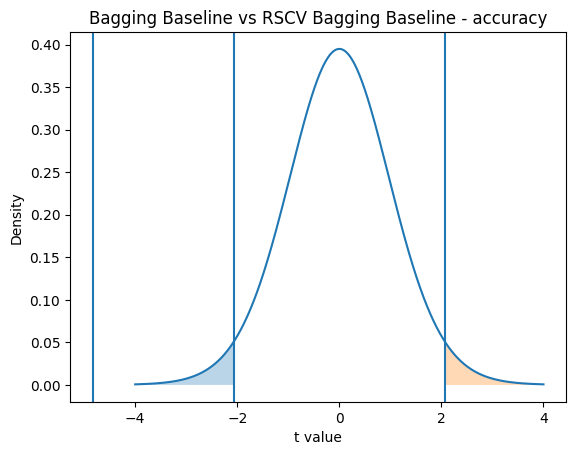

Model 1: Bagging Baseline
Model 2: RSCV Bagging Baseline
Metric : precision
t value: -1.5791351497871824
p value: 0.12739597892624457
t critical: 2.0638985616280205


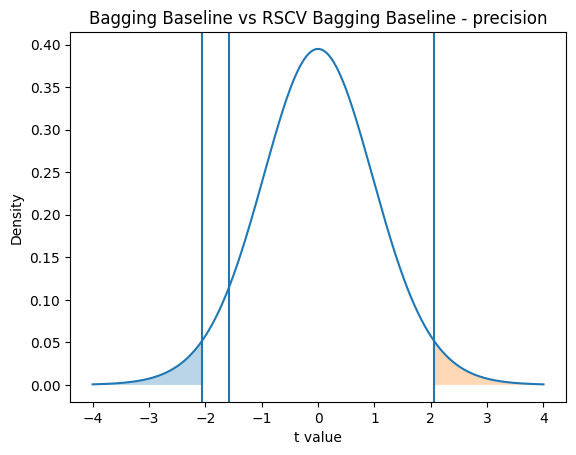

Model 1: Bagging Baseline
Model 2: RSCV Bagging Baseline
Metric : recall
t value: 0.7694999176148911
p value: 0.44910429310643973
t critical: 2.0638985616280205


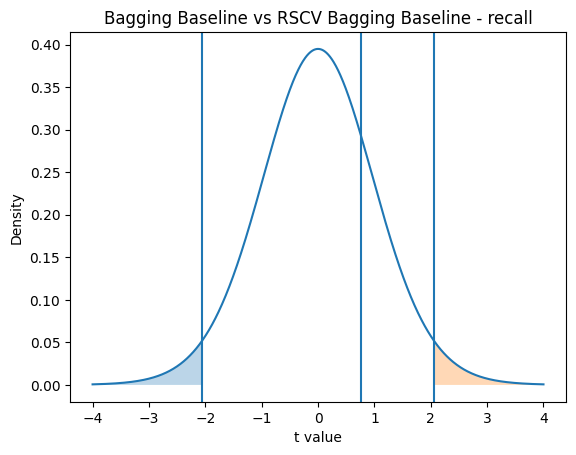

Model 1: Bagging Baseline
Model 2: RSCV Bagging Baseline
Metric : f1
t value: 3.8638342813635385
p value: 0.0007427817819776862
t critical: 2.0638985616280205


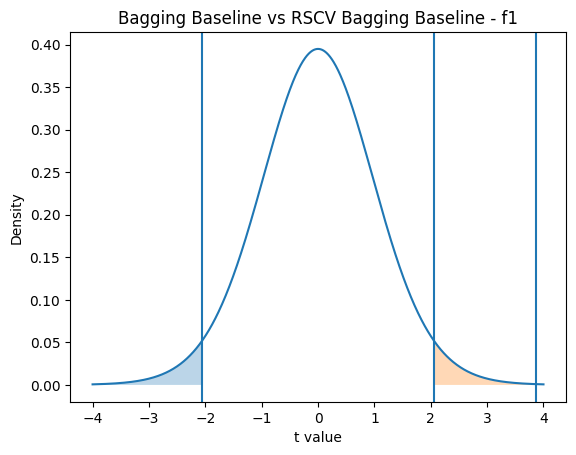

Model 1: Bagging Baseline
Model 2: RSCV Bagging Baseline
Metric : roc_auc
t value: 4.529163511904059
p value: 0.00013751678992883988
t critical: 2.0638985616280205


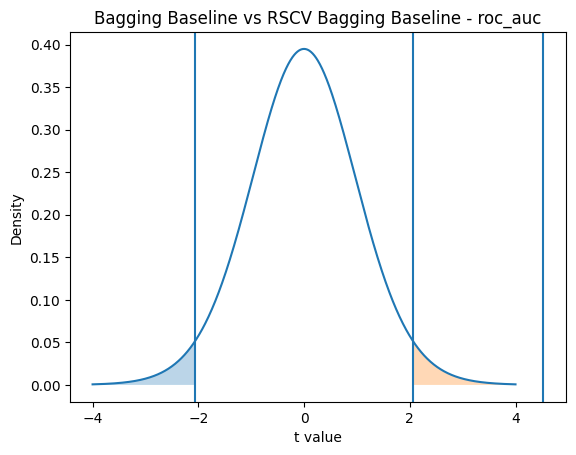

Model 1: Bagging Baseline
Model 2: RSCV Bagging SMOTENC
Metric : accuracy
t value: -8.650627093902823
p value: 7.694765839827355e-09
t critical: 2.0638985616280205


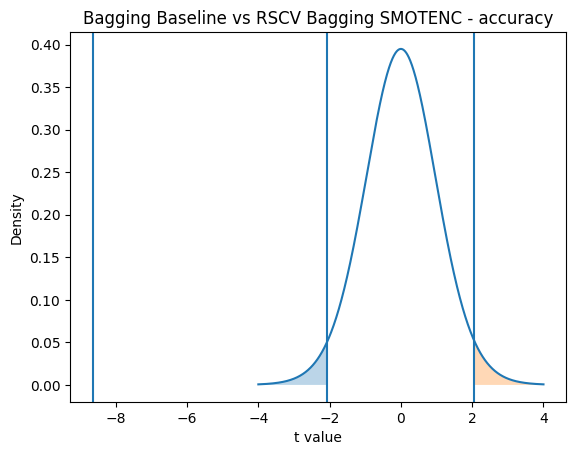

Model 1: Bagging Baseline
Model 2: RSCV Bagging SMOTENC
Metric : precision
t value: -16.17037025627438
p value: 2.0915590212008226e-14
t critical: 2.0638985616280205


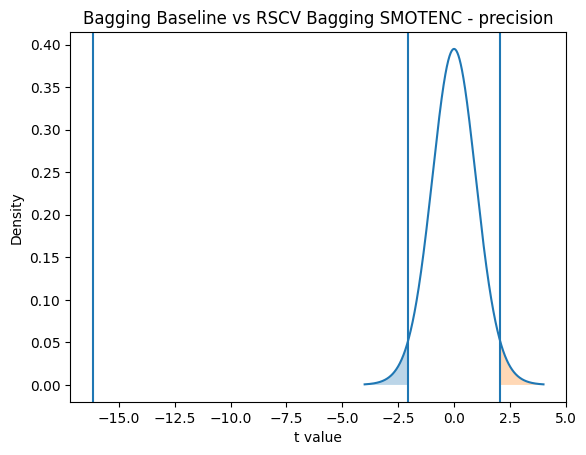

Model 1: Bagging Baseline
Model 2: RSCV Bagging SMOTENC
Metric : recall
t value: -81.08452081525513
p value: 8.651208617683786e-31
t critical: 2.0638985616280205


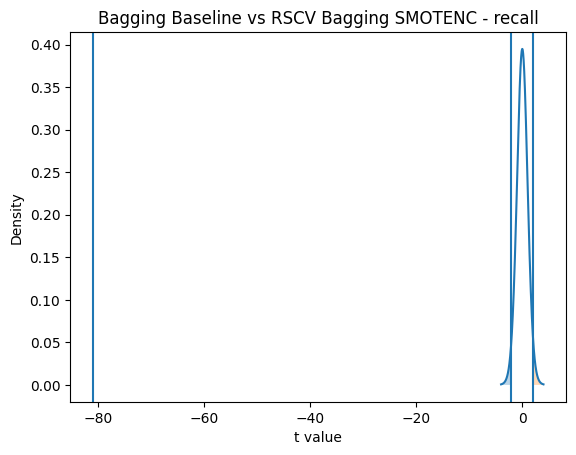

Model 1: Bagging Baseline
Model 2: RSCV Bagging SMOTENC
Metric : f1
t value: -34.97812943412596
p value: 4.1819481557770837e-22
t critical: 2.0638985616280205


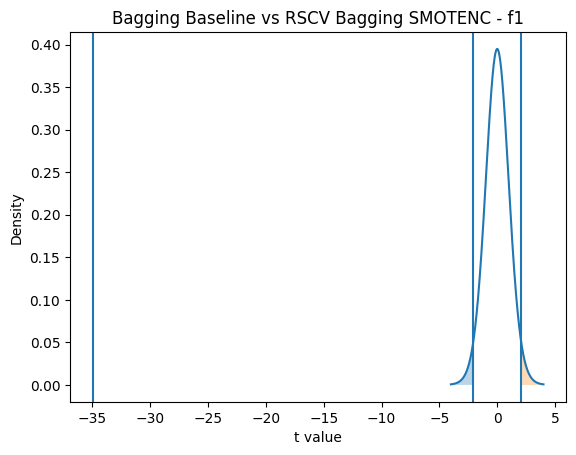

Model 1: Bagging Baseline
Model 2: RSCV Bagging SMOTENC
Metric : roc_auc
t value: -74.3166355536833
p value: 6.951094092057845e-30
t critical: 2.0638985616280205


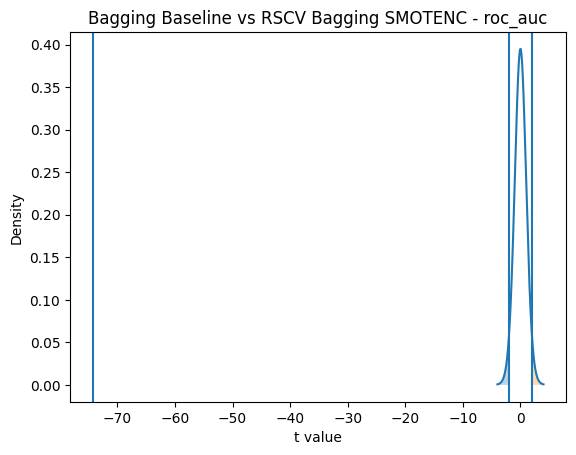

Model 1: Bagging Baseline
Model 2: RSCV Bagging CTGAN
Metric : accuracy
t value: -16.938470070493487
p value: 7.486142765972168e-15
t critical: 2.0638985616280205


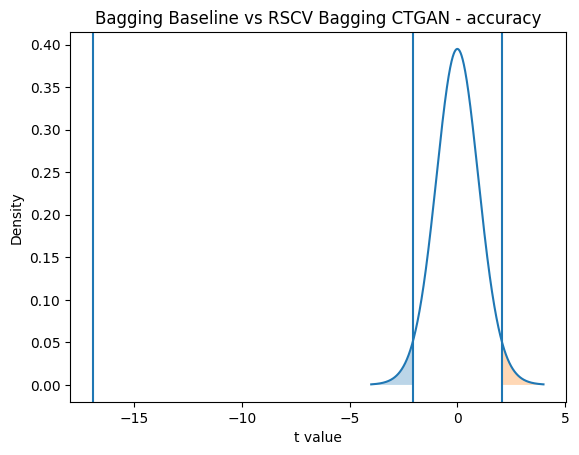

Model 1: Bagging Baseline
Model 2: RSCV Bagging CTGAN
Metric : precision
t value: -25.019024481874848
p value: 1.0539171825088204e-18
t critical: 2.0638985616280205


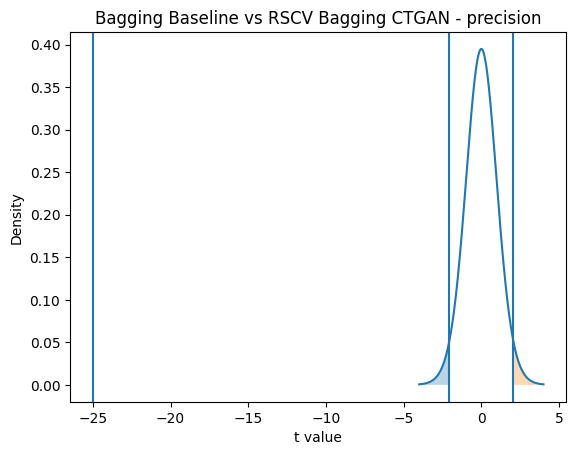

Model 1: Bagging Baseline
Model 2: RSCV Bagging CTGAN
Metric : recall
t value: -146.1882880481031
p value: 6.402070207018825e-37
t critical: 2.0638985616280205


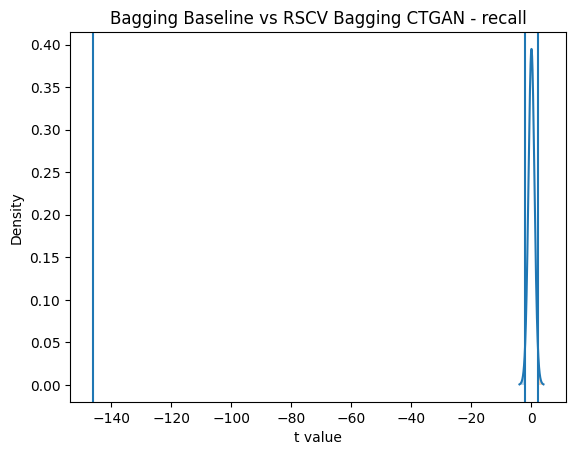

Model 1: Bagging Baseline
Model 2: RSCV Bagging CTGAN
Metric : f1
t value: -53.79209505709885
p value: 1.5531439405135354e-26
t critical: 2.0638985616280205


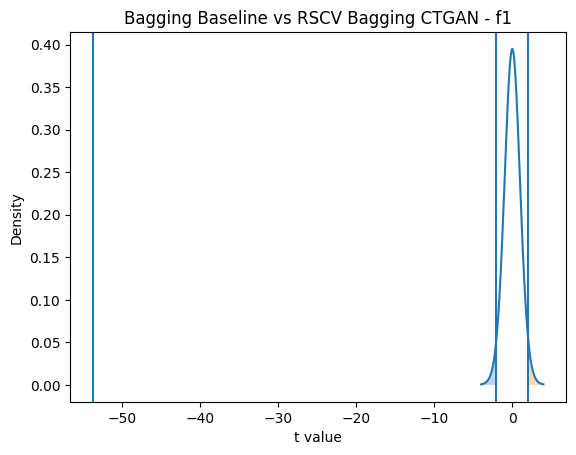

Model 1: Bagging Baseline
Model 2: RSCV Bagging CTGAN
Metric : roc_auc
t value: -131.430301178231
p value: 8.207241171983424e-36
t critical: 2.0638985616280205


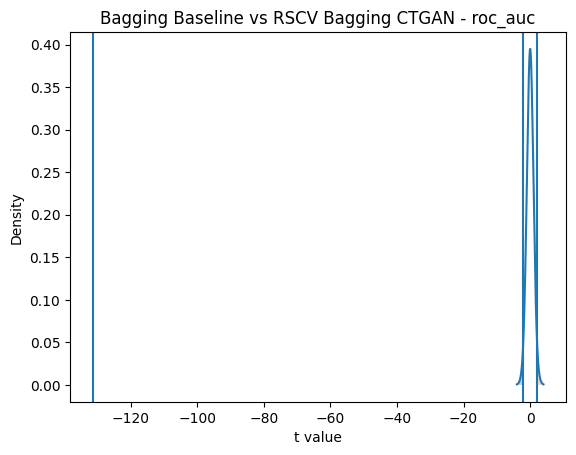

Model 1: Bagging SMOTENC
Model 2: Bagging CTGAN
Metric : accuracy
t value: -64.04370638866763
p value: 2.4275891255544435e-28
t critical: 2.0638985616280205


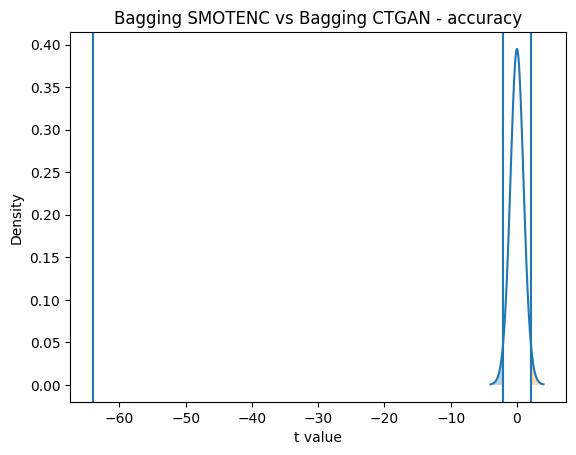

Model 1: Bagging SMOTENC
Model 2: Bagging CTGAN
Metric : precision
t value: -65.14989817769563
p value: 1.6131026882925825e-28
t critical: 2.0638985616280205


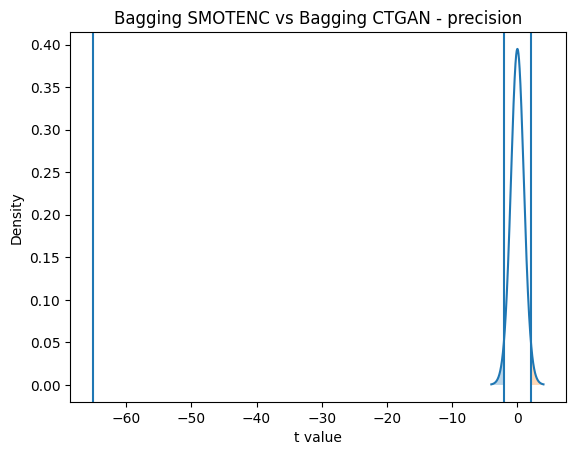

Model 1: Bagging SMOTENC
Model 2: Bagging CTGAN
Metric : recall
t value: -64.04336781797643
p value: 2.427895428894631e-28
t critical: 2.0638985616280205


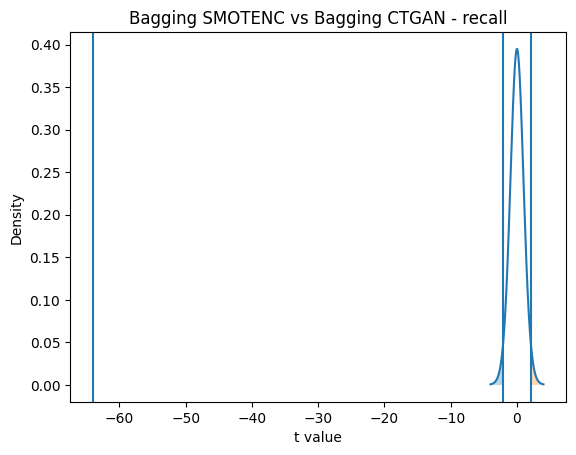

Model 1: Bagging SMOTENC
Model 2: Bagging CTGAN
Metric : f1
t value: -63.78806452442873
p value: 2.670729173258853e-28
t critical: 2.0638985616280205


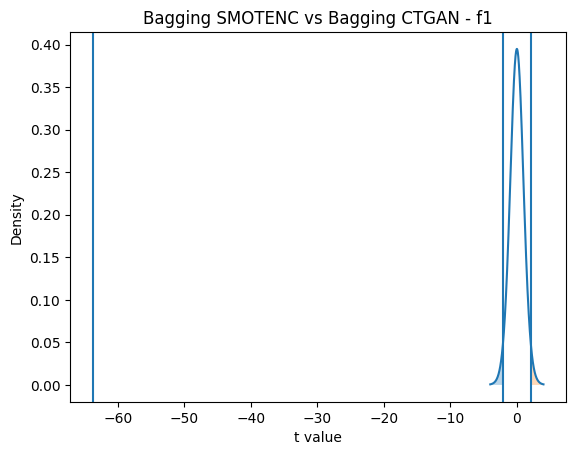

Model 1: Bagging SMOTENC
Model 2: Bagging CTGAN
Metric : roc_auc
t value: -89.73061987677887
p value: 7.662242905393537e-32
t critical: 2.0638985616280205


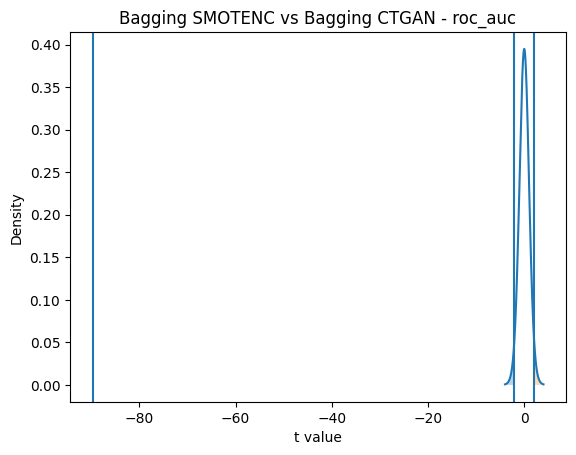

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging Baseline
Metric : accuracy
t value: 36.7906991242997
p value: 1.270744188224356e-22
t critical: 2.0638985616280205


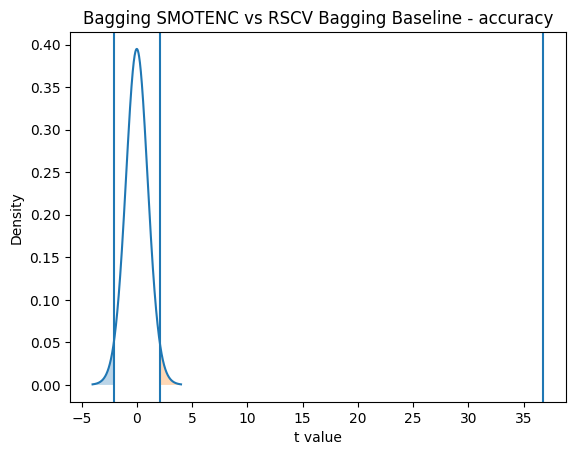

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging Baseline
Metric : precision
t value: 27.776212140498743
p value: 9.293528891379955e-20
t critical: 2.0638985616280205


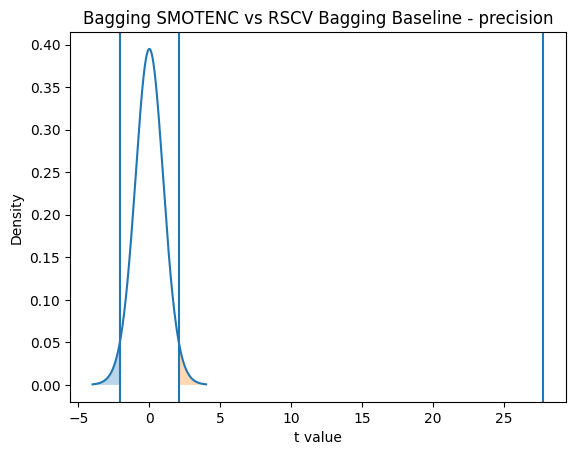

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging Baseline
Metric : recall
t value: 150.36216601212627
p value: 3.2599005998346354e-37
t critical: 2.0638985616280205


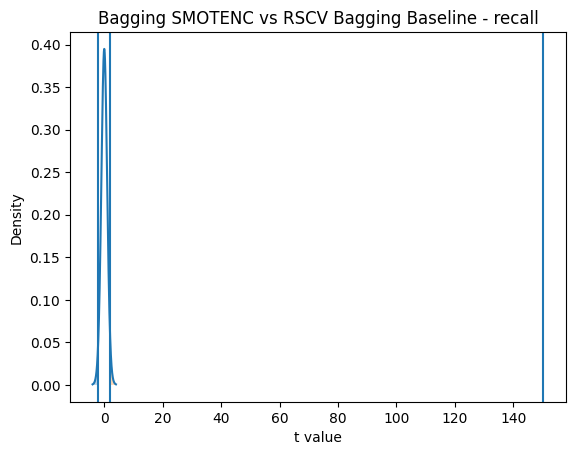

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging Baseline
Metric : f1
t value: 135.97047640343004
p value: 3.636427966823882e-36
t critical: 2.0638985616280205


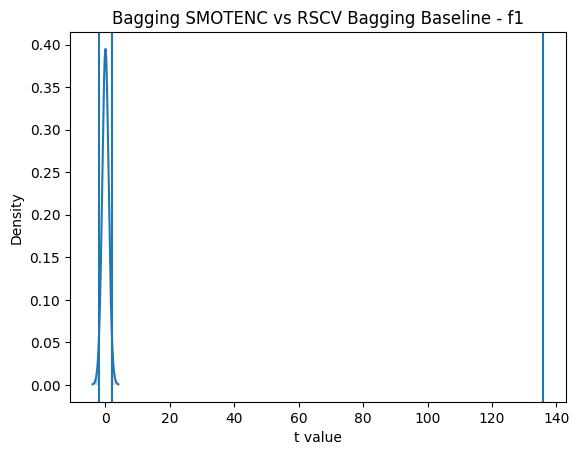

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging Baseline
Metric : roc_auc
t value: 114.06516117350813
p value: 2.4487208210329984e-34
t critical: 2.0638985616280205


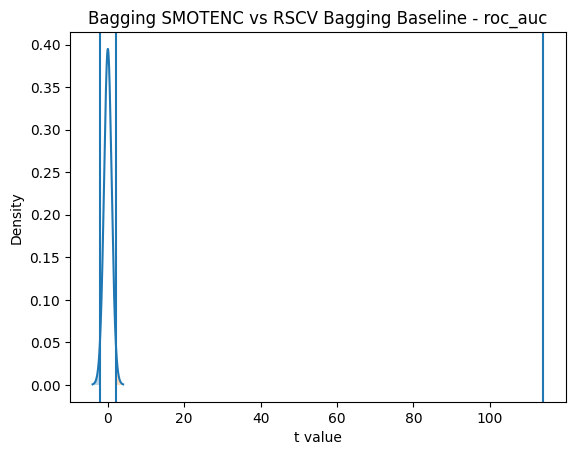

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : accuracy
t value: 5.585558865645851
p value: 9.518003329044484e-06
t critical: 2.0638985616280205


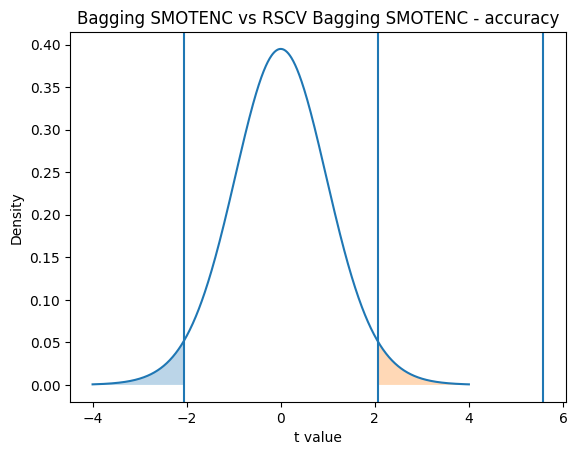

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : precision
t value: 5.548473480032157
p value: 1.0442085000144953e-05
t critical: 2.0638985616280205


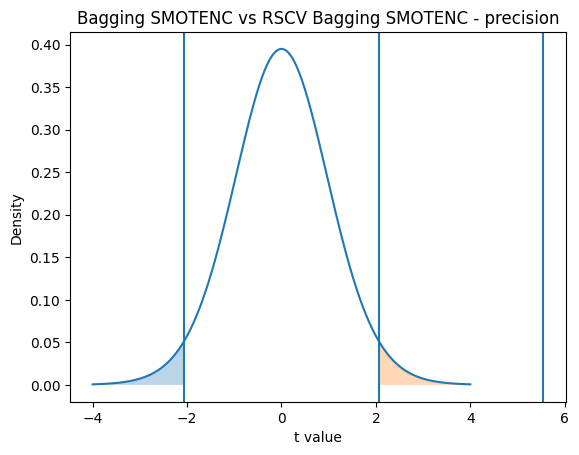

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : recall
t value: 5.60742907365741
p value: 9.012334068443459e-06
t critical: 2.0638985616280205


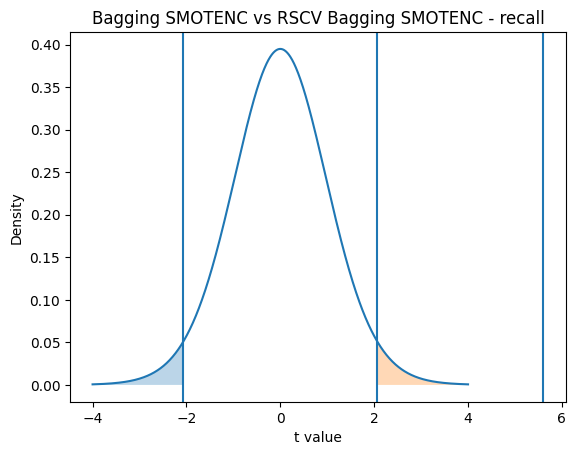

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : f1
t value: 5.669627034599578
p value: 7.718022000944531e-06
t critical: 2.0638985616280205


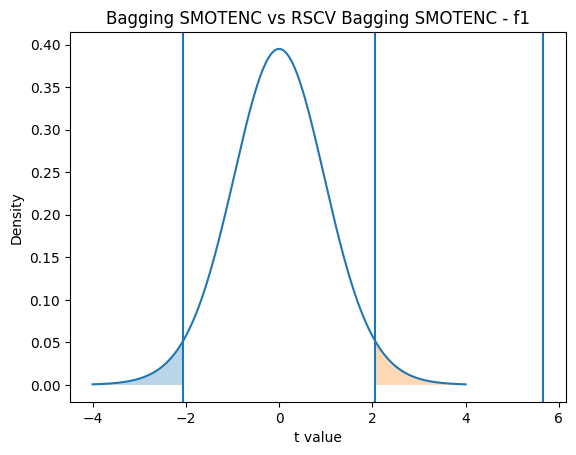

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging SMOTENC
Metric : roc_auc
t value: 5.367318000604406
p value: 1.6444462168338455e-05
t critical: 2.0638985616280205


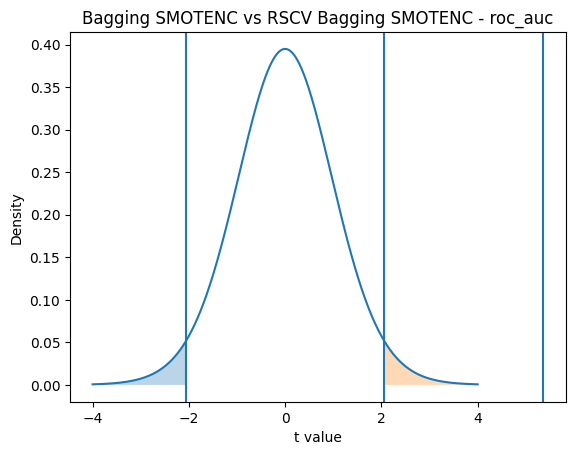

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : accuracy
t value: -45.936459374353035
p value: 6.628163236632951e-25
t critical: 2.0638985616280205


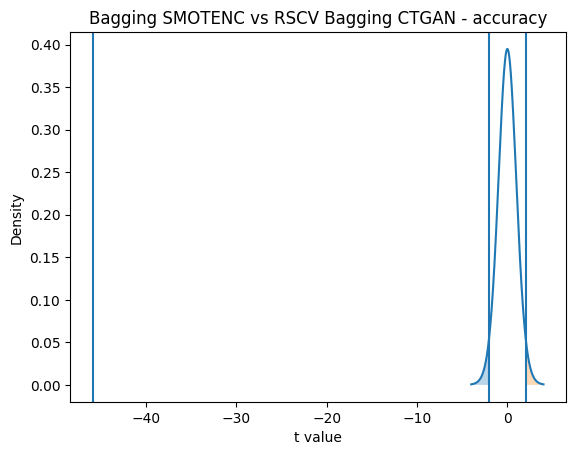

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : precision
t value: -46.688794623488526
p value: 4.506834611812082e-25
t critical: 2.0638985616280205


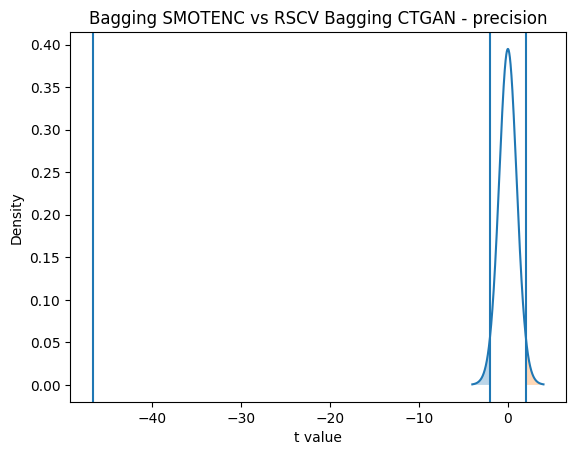

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : recall
t value: -45.92062766710257
p value: 6.682626581240535e-25
t critical: 2.0638985616280205


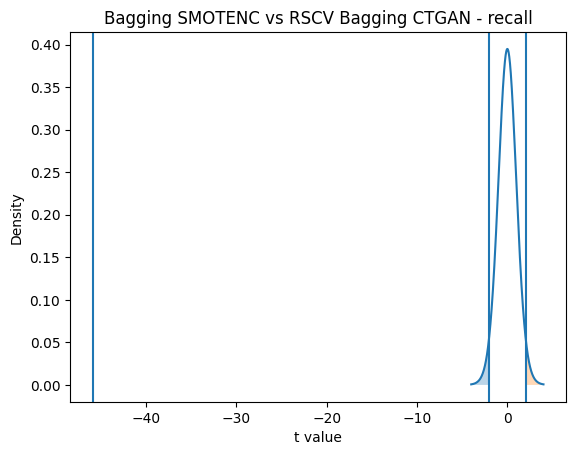

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : f1
t value: -45.753481490379514
p value: 7.286894719431182e-25
t critical: 2.0638985616280205


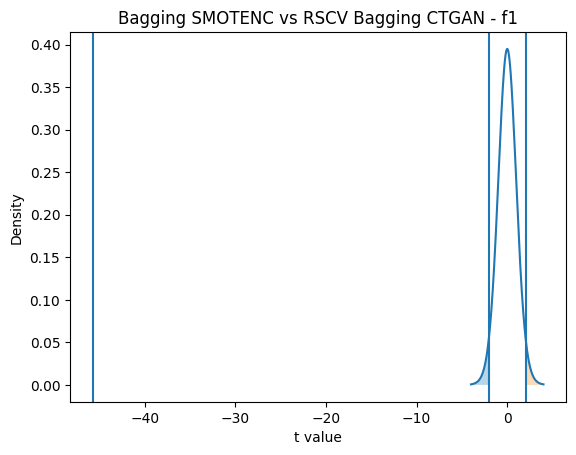

Model 1: Bagging SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : roc_auc
t value: -58.90107648181807
p value: 1.7878980076949217e-27
t critical: 2.0638985616280205


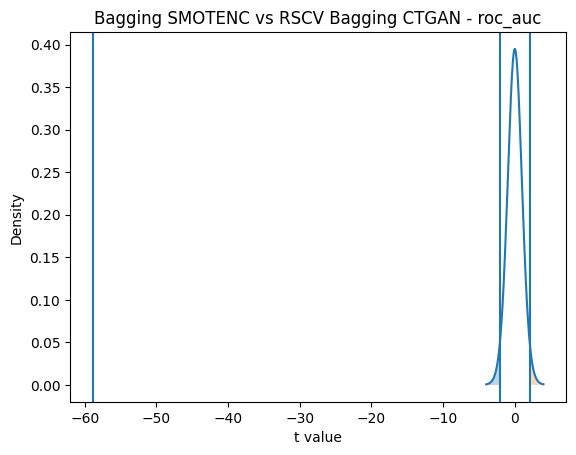

Model 1: Bagging CTGAN
Model 2: RSCV Bagging Baseline
Metric : accuracy
t value: 173.96011586577143
p value: 9.887389679366863e-39
t critical: 2.0638985616280205


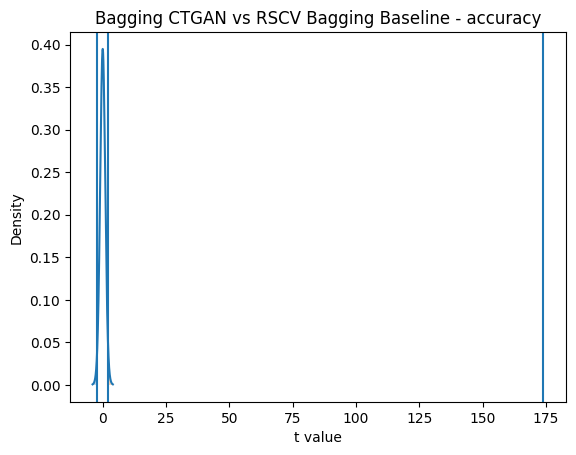

Model 1: Bagging CTGAN
Model 2: RSCV Bagging Baseline
Metric : precision
t value: 39.86248425567686
p value: 1.9106474352720907e-23
t critical: 2.0638985616280205


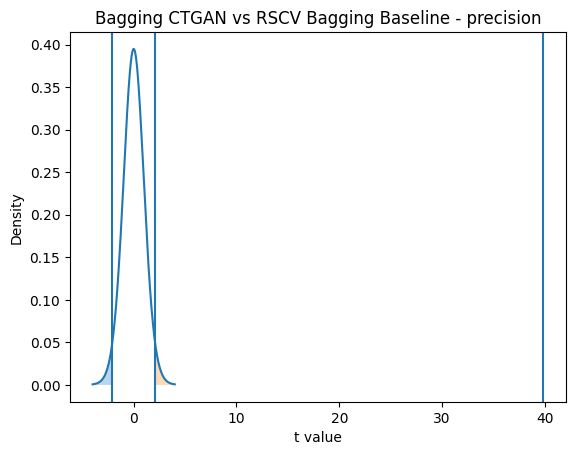

Model 1: Bagging CTGAN
Model 2: RSCV Bagging Baseline
Metric : recall
t value: 267.0494981971948
p value: 3.3881157766948317e-43
t critical: 2.0638985616280205


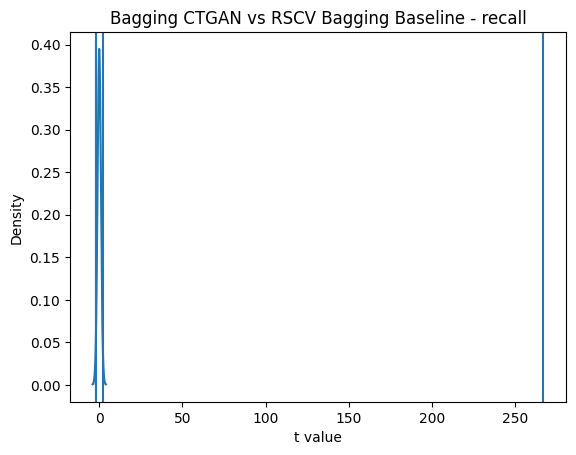

Model 1: Bagging CTGAN
Model 2: RSCV Bagging Baseline
Metric : f1
t value: 178.40422737352247
p value: 5.399408221767238e-39
t critical: 2.0638985616280205


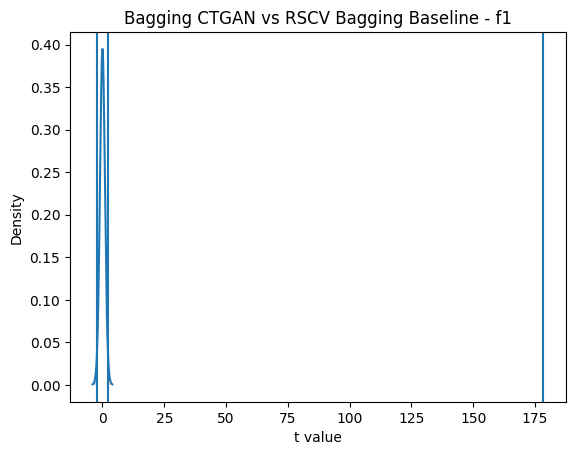

Model 1: Bagging CTGAN
Model 2: RSCV Bagging Baseline
Metric : roc_auc
t value: 178.84532696729897
p value: 5.088922314644671e-39
t critical: 2.0638985616280205


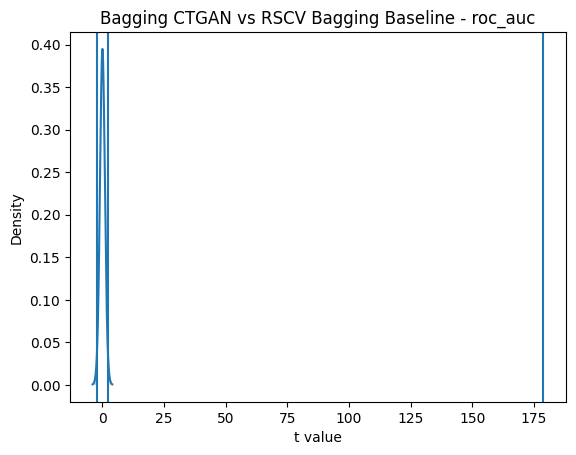

Model 1: Bagging CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : accuracy
t value: 57.20243684139112
p value: 3.5915090150332175e-27
t critical: 2.0638985616280205


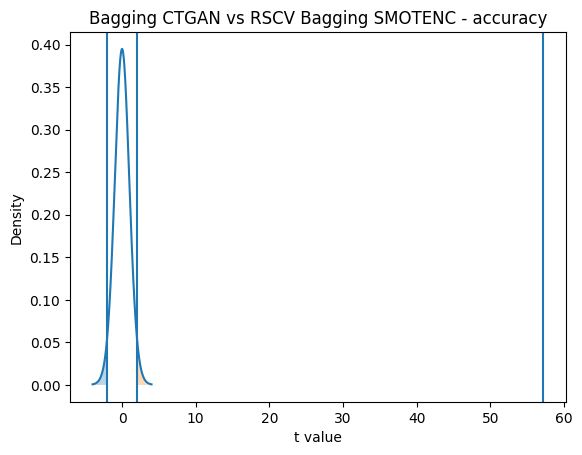

Model 1: Bagging CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : precision
t value: 57.18233816641337
p value: 3.621714434683721e-27
t critical: 2.0638985616280205


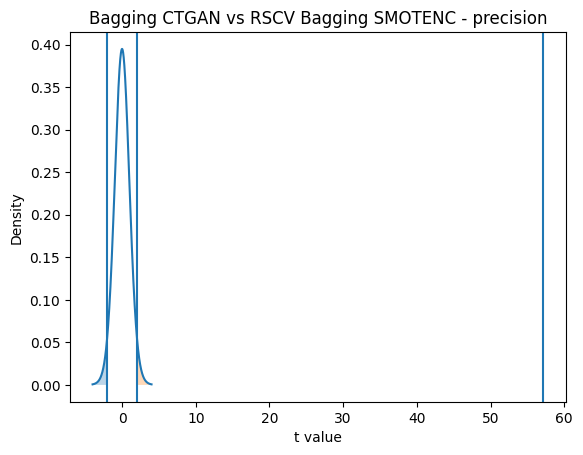

Model 1: Bagging CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : recall
t value: 58.56887827675513
p value: 2.0459872285490093e-27
t critical: 2.0638985616280205


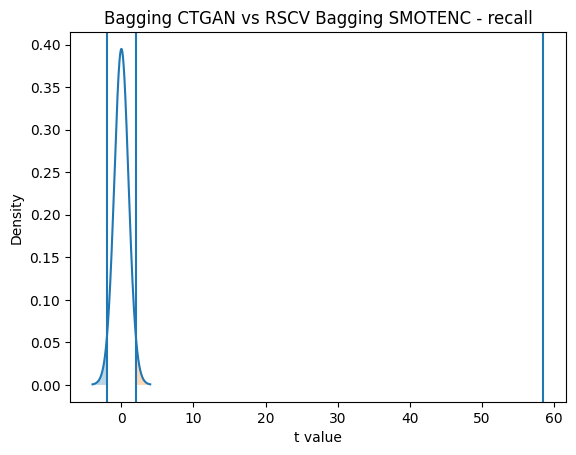

Model 1: Bagging CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : f1
t value: 57.81474989925973
p value: 2.7865504266351295e-27
t critical: 2.0638985616280205


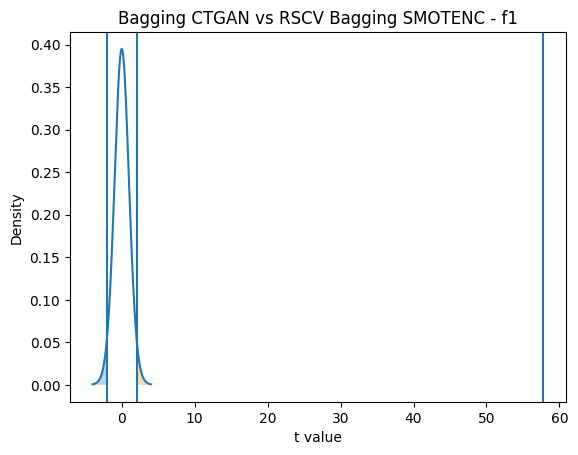

Model 1: Bagging CTGAN
Model 2: RSCV Bagging SMOTENC
Metric : roc_auc
t value: 46.662636080399864
p value: 4.567218976277399e-25
t critical: 2.0638985616280205


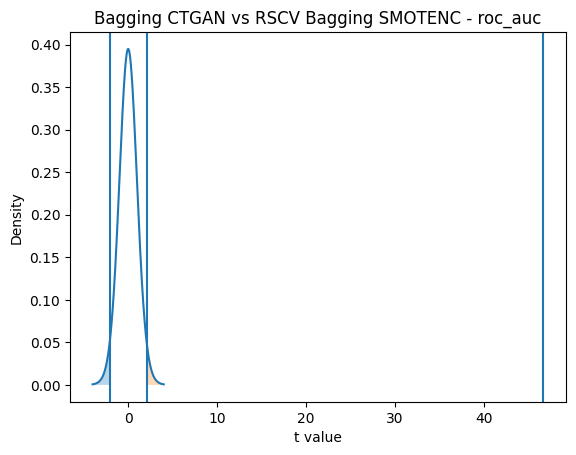

Model 1: Bagging CTGAN
Model 2: RSCV Bagging CTGAN
Metric : accuracy
t value: 10.367700930205018
p value: 2.4169551964891126e-10
t critical: 2.0638985616280205


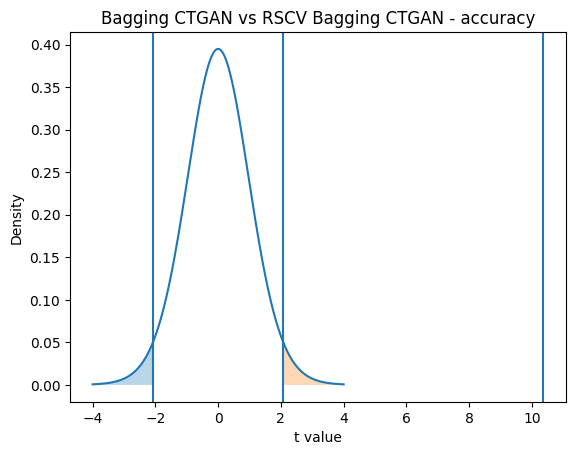

Model 1: Bagging CTGAN
Model 2: RSCV Bagging CTGAN
Metric : precision
t value: 10.51720059303806
p value: 1.8194659460522002e-10
t critical: 2.0638985616280205


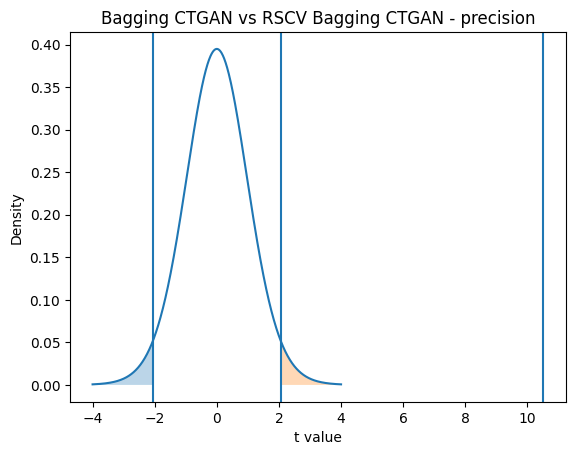

Model 1: Bagging CTGAN
Model 2: RSCV Bagging CTGAN
Metric : recall
t value: 10.306928626514898
p value: 2.7147675873760515e-10
t critical: 2.0638985616280205


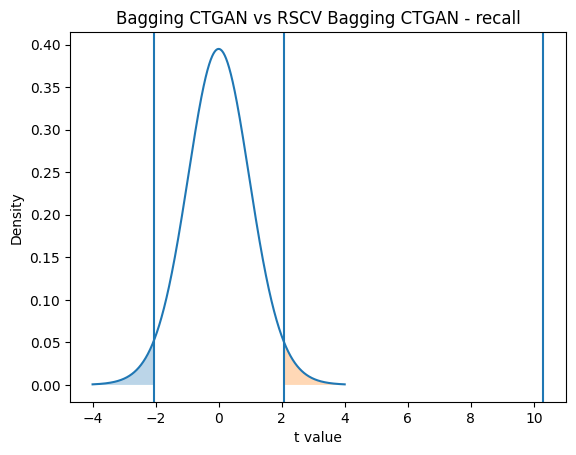

Model 1: Bagging CTGAN
Model 2: RSCV Bagging CTGAN
Metric : f1
t value: 10.34358557995656
p value: 2.530873370357636e-10
t critical: 2.0638985616280205


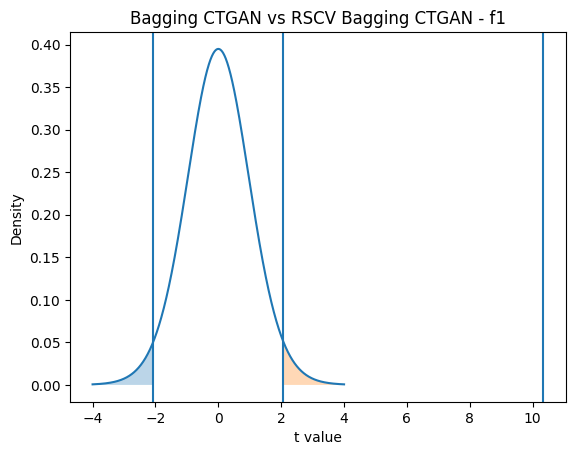

Model 1: Bagging CTGAN
Model 2: RSCV Bagging CTGAN
Metric : roc_auc
t value: 13.84426674606596
p value: 6.138625538934493e-13
t critical: 2.0638985616280205


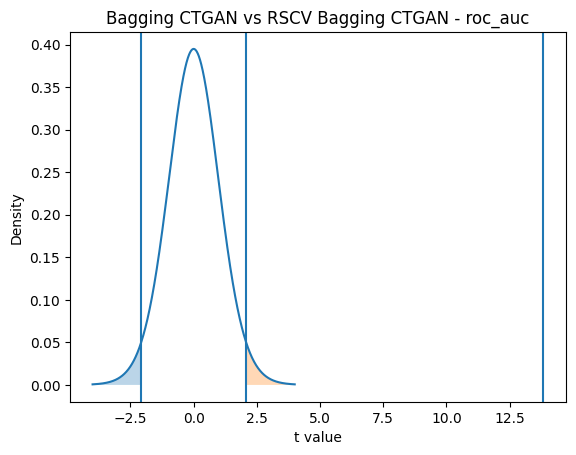

Model 1: RSCV Bagging Baseline
Model 2: RSCV Bagging SMOTENC
Metric : accuracy
t value: -20.24998916098366
p value: 1.3508380480784026e-16
t critical: 2.0638985616280205


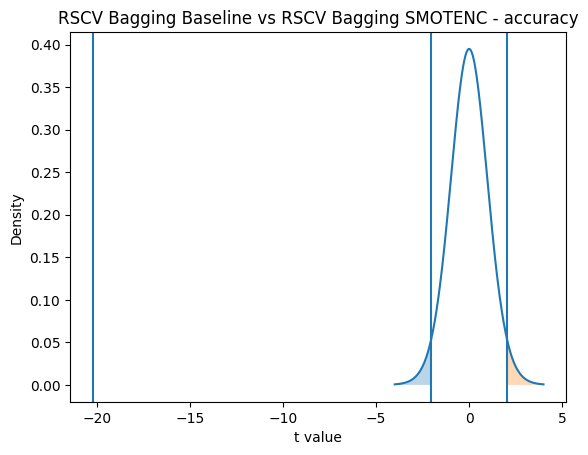

Model 1: RSCV Bagging Baseline
Model 2: RSCV Bagging SMOTENC
Metric : precision
t value: -24.235384294756365
p value: 2.1996380952955627e-18
t critical: 2.0638985616280205


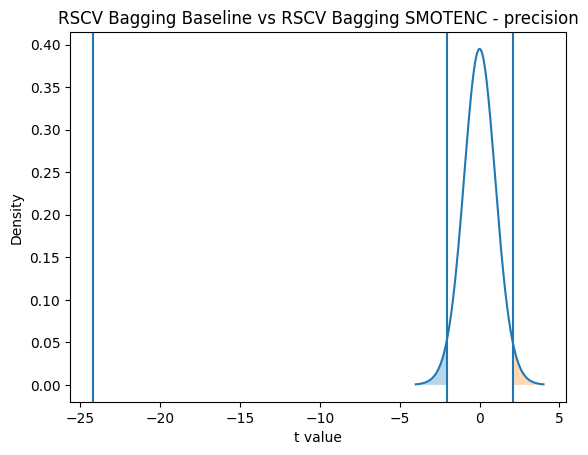

Model 1: RSCV Bagging Baseline
Model 2: RSCV Bagging SMOTENC
Metric : recall
t value: -96.28936490937393
p value: 1.4158339661672943e-32
t critical: 2.0638985616280205


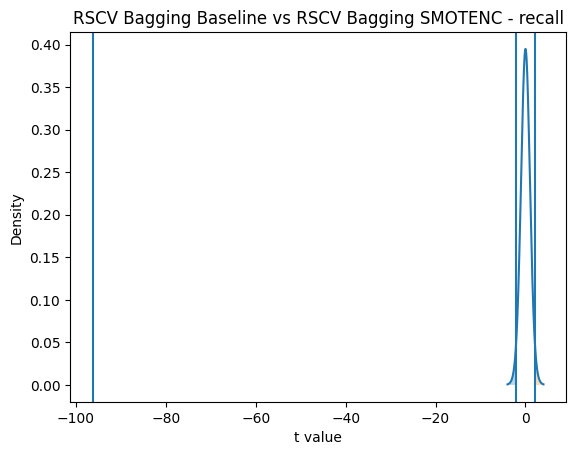

Model 1: RSCV Bagging Baseline
Model 2: RSCV Bagging SMOTENC
Metric : f1
t value: -90.62312174318245
p value: 6.046268210512244e-32
t critical: 2.0638985616280205


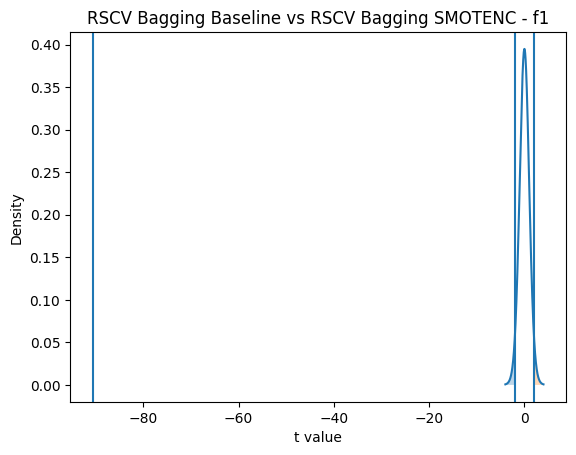

Model 1: RSCV Bagging Baseline
Model 2: RSCV Bagging SMOTENC
Metric : roc_auc
t value: -108.74667453946532
p value: 7.686057015931237e-34
t critical: 2.0638985616280205


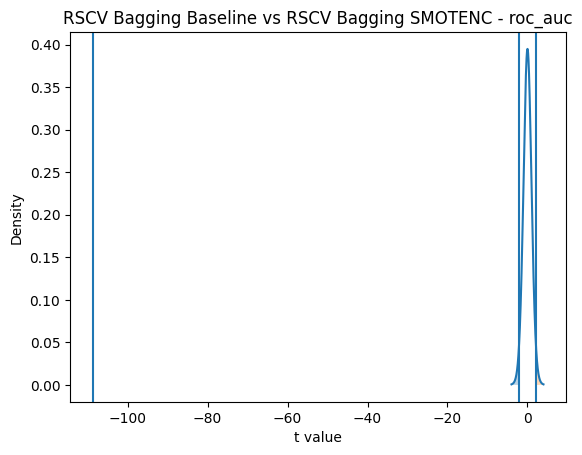

Model 1: RSCV Bagging Baseline
Model 2: RSCV Bagging CTGAN
Metric : accuracy
t value: -78.11806000358592
p value: 2.1093206186804212e-30
t critical: 2.0638985616280205


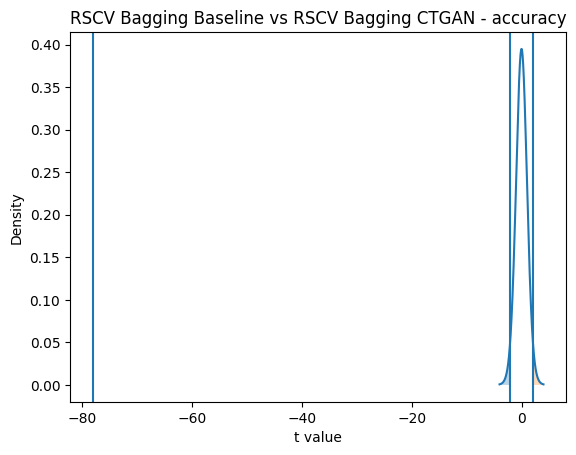

Model 1: RSCV Bagging Baseline
Model 2: RSCV Bagging CTGAN
Metric : precision
t value: -37.60211753618062
p value: 7.592846769032212e-23
t critical: 2.0638985616280205


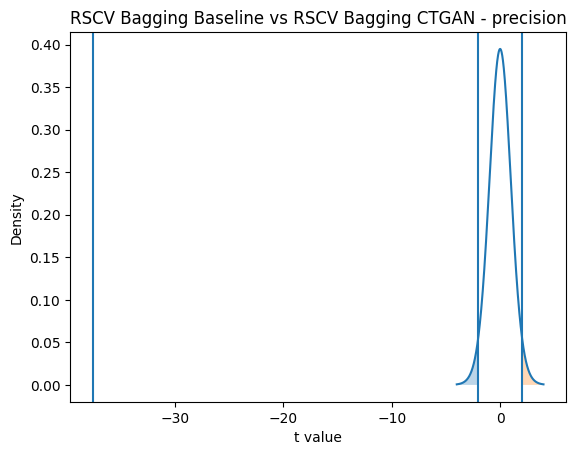

Model 1: RSCV Bagging Baseline
Model 2: RSCV Bagging CTGAN
Metric : recall
t value: -171.66122867825464
p value: 1.360297493087496e-38
t critical: 2.0638985616280205


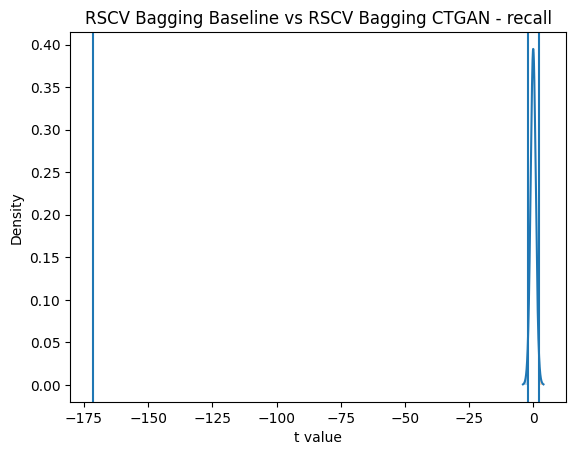

Model 1: RSCV Bagging Baseline
Model 2: RSCV Bagging CTGAN
Metric : f1
t value: -155.80584176041182
p value: 1.3895854913847351e-37
t critical: 2.0638985616280205


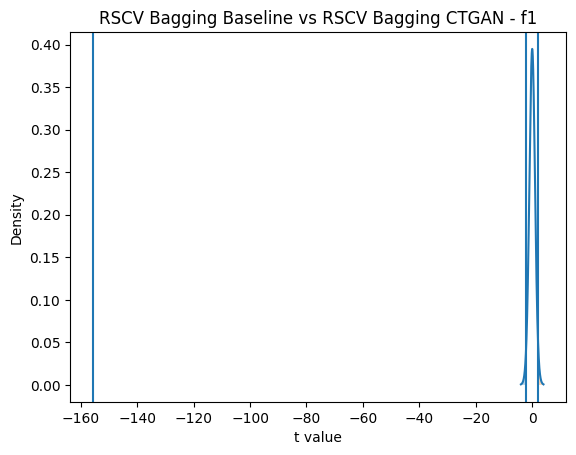

Model 1: RSCV Bagging Baseline
Model 2: RSCV Bagging CTGAN
Metric : roc_auc
t value: -151.72806634049496
p value: 2.6244796175271412e-37
t critical: 2.0638985616280205


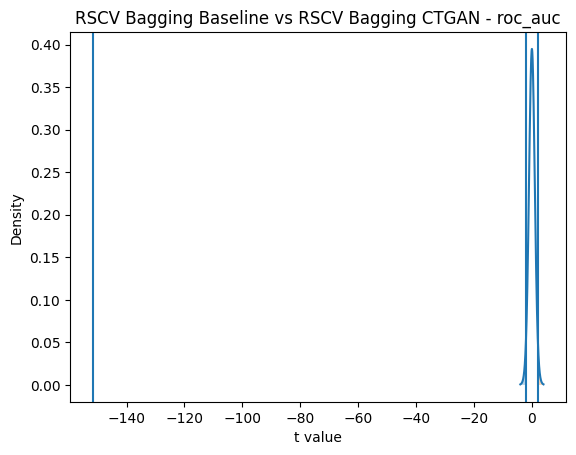

Model 1: RSCV Bagging SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : accuracy
t value: -33.35773854861885
p value: 1.2770062946445963e-21
t critical: 2.0638985616280205


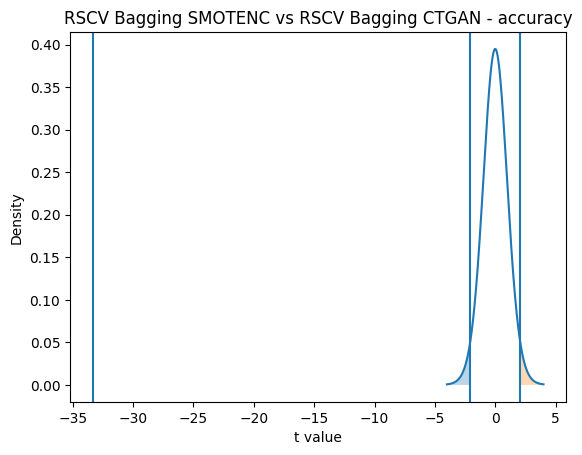

Model 1: RSCV Bagging SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : precision
t value: -33.05257877829199
p value: 1.5849688288473768e-21
t critical: 2.0638985616280205


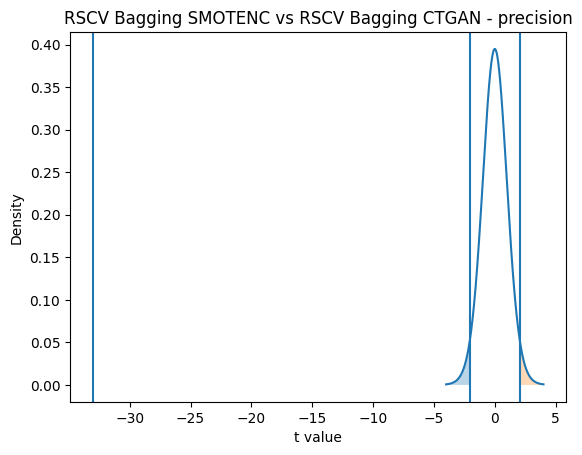

Model 1: RSCV Bagging SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : recall
t value: -33.568035356687055
p value: 1.101567197229737e-21
t critical: 2.0638985616280205


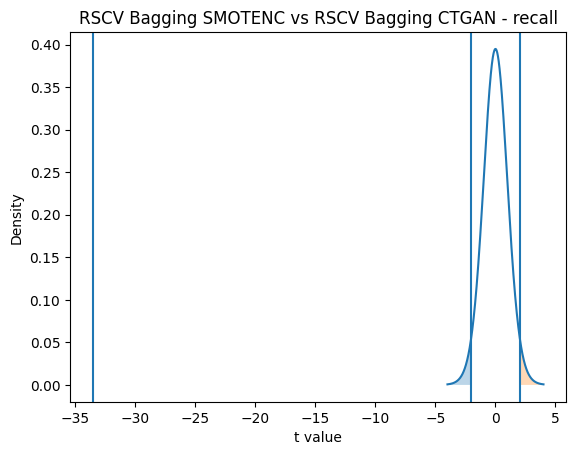

Model 1: RSCV Bagging SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : f1
t value: -33.460411817479994
p value: 1.1879798108719731e-21
t critical: 2.0638985616280205


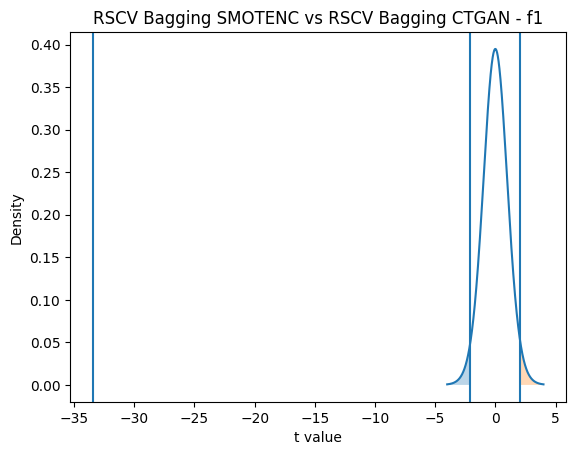

Model 1: RSCV Bagging SMOTENC
Model 2: RSCV Bagging CTGAN
Metric : roc_auc
t value: -34.742022294286514
p value: 4.905232226135184e-22
t critical: 2.0638985616280205


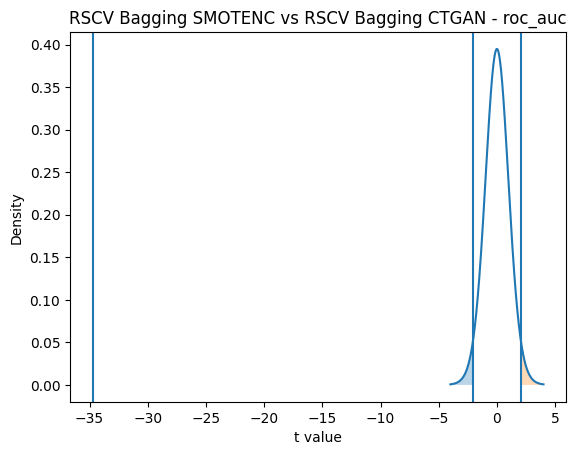

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, t
import pandas as pd
import itertools

# =========================
# LOAD SEMUA MODEL
# =========================

models = {
    # RANDOM FOREST
    "RF Baseline": pd.read_csv("output/random_rf_plain_no_threshold.csv"),
    "RF SMOTENC": pd.read_csv("output/random_rf_kfold_5fold_25iter_SMOTENC.csv"),
    "RF CTGAN": pd.read_csv("output/random_rf_kfold_5fold_25iter_CTGAN.csv"),
    "RSCV RF Baseline": pd.read_csv("output/rf_plain_no_threshold.csv"),
    "RSCV RF SMOTENC": pd.read_csv("output/rf_train_test_split_25iter_SMOTENC.csv"),
    "RSCV RF CTGAN": pd.read_csv("output/rf_train_test_split_25iter_CTGAN.csv"),

    # BAGGING
    "Bagging Baseline": pd.read_csv("output/random_bagging_plain_no_threshold.csv"),
    "Bagging SMOTENC": pd.read_csv("output/random_bagging_kfold_5fold_25iter_SMOTENC.csv"),
    "Bagging CTGAN": pd.read_csv("output/random_bagging_kfold_5fold_25iter_CTGAN.csv"),
    "RSCV Bagging Baseline": pd.read_csv("output/bagging_plain_no_threshold.csv"),
    "RSCV Bagging SMOTENC": pd.read_csv("output/bagging_train_test_split_25iter_SMOTENC.csv"),
    "RSCV Bagging CTGAN": pd.read_csv("output/bagging_train_test_split_25iter_CTGAN.csv"),
}

metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
alpha = 0.05

# =========================
# LOOP SEMUA PASANGAN
# =========================

for (name1, df1), (name2, df2) in itertools.combinations(models.items(), 2):

    n = len(df1)
    dfree = n - 1
    t_critical = t.ppf(1 - alpha/2, dfree)

    for metric in metrics:

        t_stat, p_value = ttest_rel(df1[metric], df2[metric])

        print("====================================")
        print("Model 1:", name1)
        print("Model 2:", name2)
        print("Metric :", metric)
        print("t value:", t_stat)
        print("p value:", p_value)
        print("t critical:", t_critical)

        x = np.linspace(-4, 4, 1000)
        y = t.pdf(x, dfree)

        plt.figure()
        plt.plot(x, y)
        plt.axvline(-t_critical)
        plt.axvline(t_critical)
        plt.axvline(t_stat)

        plt.fill_between(x, y, where=(x <= -t_critical), alpha=0.3)
        plt.fill_between(x, y, where=(x >= t_critical), alpha=0.3)

        plt.title(f"{name1} vs {name2} - {metric}")
        plt.xlabel("t value")
        plt.ylabel("Density")

        plt.show()


In [ ]:
# === Uji Statistik Signifikansi untuk Random Forest sebelum Vs Setelah Penanganan ===
import pandas as pd
from scipy.stats import ttest_rel, wilcoxon

# Nama file baseline
baseline_file = f"{OUTPUT_DIR}/rf_plain_no_threshold.csv"

# Daftar samplers (as used in rf_kfold_classweight_summary_5fold_25iter_{sampler_name}.csv)
samplers = [
    "ROS",
    "SMOTENC",
    "CTGAN",
]

# Define the pairs of metrics to compare (baseline_column, hybrid_column)
metric_pairs = [
    ("accuracy", "mean_acc"),
    ("precision", "mean_precision"),
    ("recall", "mean_recall"),
    ("f1", "mean_f1"),
    ("roc_auc", "mean_roc_auc"),
]

# Load baseline
df_baseline = pd.read_csv(baseline_file)

for sampler_name in samplers:
    print(f"\n=== Perbandingan Baseline vs {sampler_name} (Random Forest) ===")

    # Load hybrid summary
    hybrid_summary_file = f"{OUTPUT_DIR}/rf_kfold_classweight_summary_5fold_25iter_{sampler_name}.csv"
    try:
        df_hybrid_summary = pd.read_csv(hybrid_summary_file)
    except FileNotFoundError:
        print(f"Summary file not found for {sampler_name}: {hybrid_summary_file}. Skipping statistical tests.")
        continue

    # Iterate through metric pairs and perform tests if columns exist in both dataframes
    for baseline_metric, hybrid_metric in metric_pairs:
        if baseline_metric in df_baseline.columns and hybrid_metric in df_hybrid_summary.columns:
            print(f"\nMetrik: {baseline_metric.upper()} (Baseline) vs {hybrid_metric.upper()} ({sampler_name})")

            # Load the individual iteration results for the hybrid model
            hybrid_results_file = f"{OUTPUT_DIR}/rf_kfold_classweight_5fold_25iter_avg_{sampler_name}.csv"
            try:
                df_hybrid_results = pd.read_csv(hybrid_results_file)
            except FileNotFoundError:
                print(f"Individual results file not found for {sampler_name}: {hybrid_results_file}. Skipping statistical tests for this sampler.")
                break # Skip to the next sampler if individual results file is missing

            # Ensure both dataframes have the same number of rows (iterations) for paired tests
            if len(df_baseline) == len(df_hybrid_results):
                 # Paired t-test
                t_stat, p_val = ttest_rel(df_baseline[baseline_metric], df_hybrid_results[baseline_metric]) # Use baseline_metric name as column in hybrid_results
                print(f"Paired t-test: t={t_stat:.4f}, p={p_val:.6f}")
                if p_val < 0.05:
                    print("👉 Perbedaan SIGNIFIKAN ✅")
                else:
                    print("👉 Tidak signifikan ❌")

                # Wilcoxon signed-rank test
                w_stat, w_p_val = wilcoxon(df_baseline[baseline_metric], df_hybrid_results[baseline_metric]) # Use baseline_metric name as column in hybrid_results
                print(f"Wilcoxon: stat={w_stat:.4f}, p={w_p_val:.6f}")
                if w_p_val < 0.05:
                    print("👉 Perbedaan SIGNIFIKAN ✅")
                else:
                    print("👉 Tidak signifikan ❌")
            else:
                print(f"Skipping statistical tests for {sampler_name} due to mismatch in number of iterations: Baseline {len(df_baseline)}, Hybrid {len(df_hybrid_results)}.")
        else:
            print(f"Skipping statistical tests for {baseline_metric} vs {hybrid_metric} due to missing columns in one of the dataframes.")


=== Perbandingan Baseline vs ROS (Random Forest) ===

Metrik: ACCURACY (Baseline) vs MEAN_ACC (ROS)
Paired t-test: t=-144.2111, p=0.000000
👉 Perbedaan SIGNIFIKAN ✅
Wilcoxon: stat=0.0000, p=0.000000
👉 Perbedaan SIGNIFIKAN ✅

Metrik: PRECISION (Baseline) vs MEAN_PRECISION (ROS)
Paired t-test: t=-16.3185, p=0.000000
👉 Perbedaan SIGNIFIKAN ✅
Wilcoxon: stat=0.0000, p=0.000000
👉 Perbedaan SIGNIFIKAN ✅

Metrik: RECALL (Baseline) vs MEAN_RECALL (ROS)
Paired t-test: t=-317.2385, p=0.000000
👉 Perbedaan SIGNIFIKAN ✅
Wilcoxon: stat=0.0000, p=0.000000
👉 Perbedaan SIGNIFIKAN ✅

Metrik: F1 (Baseline) vs MEAN_F1 (ROS)
Paired t-test: t=-261.3490, p=0.000000
👉 Perbedaan SIGNIFIKAN ✅
Wilcoxon: stat=0.0000, p=0.000000
👉 Perbedaan SIGNIFIKAN ✅

Metrik: ROC_AUC (Baseline) vs MEAN_ROC_AUC (ROS)
Paired t-test: t=-138.1377, p=0.000000
👉 Perbedaan SIGNIFIKAN ✅
Wilcoxon: stat=0.0000, p=0.000000
👉 Perbedaan SIGNIFIKAN ✅

=== Perbandingan Baseline vs SMOTENC (Random Forest) ===

Metrik: ACCURACY (Baseline) vs MEA

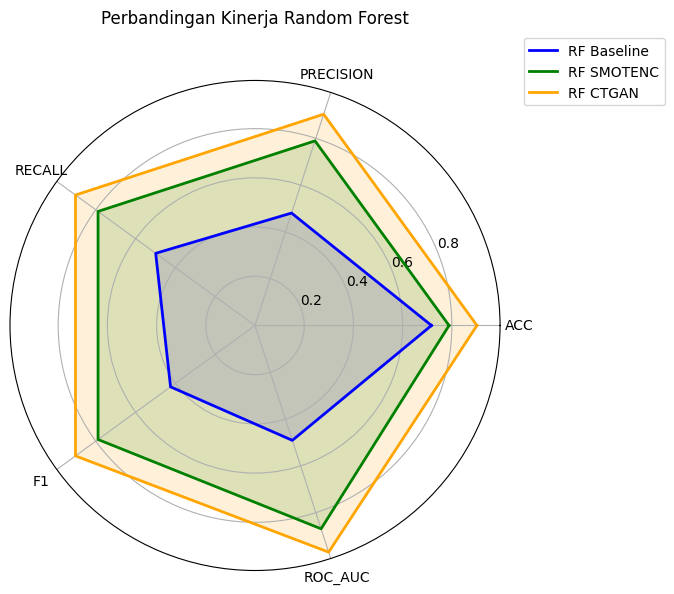

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from math import pi

OUTPUT_DIR = "output"

# =========================
# RF VARIANTS
# =========================
rf_variants = {
    "RF Baseline": f"{OUTPUT_DIR}/rf_summary_no_threshold.csv",
    "RF SMOTENC": f"{OUTPUT_DIR}/rf_kfold_summary_5fold_25iter_SMOTENC.csv",
    "RF CTGAN": f"{OUTPUT_DIR}/rf_kfold_summary_5fold_25iter_CTGAN.csv"
}

metrics = [
    "mean_acc",
    "mean_precision",
    "mean_recall",
    "mean_f1",
    "mean_roc_auc"
]

categories = [m.replace("mean_", "").upper() for m in metrics]
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

# =========================
# LOAD DATA
# =========================
rf_data = {}
for name, path in rf_variants.items():
    df = pd.read_csv(path)
    rf_data[name] = [df[m].iloc[0] for m in metrics]

# =========================
# RADAR PLOT
# =========================
plt.figure(figsize=(7, 7))
ax = plt.subplot(111, polar=True)
plt.xticks(angles[:-1], categories)

colors = {
    "RF Baseline": "blue",
    "RF SMOTENC": "green",
    "RF CTGAN": "orange"
}

for name, values in rf_data.items():
    values = values + values[:1]
    ax.plot(
        angles,
        values,
        linewidth=2,
        label=name,
        color=colors[name]
    )
    ax.fill(
        angles,
        values,
        alpha=0.15,
        color=colors[name]
    )

plt.title("Perbandingan Kinerja Random Forest", y=1.1)
plt.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/radar_rf_baseline_smotenc_ctgan.png")
plt.show()


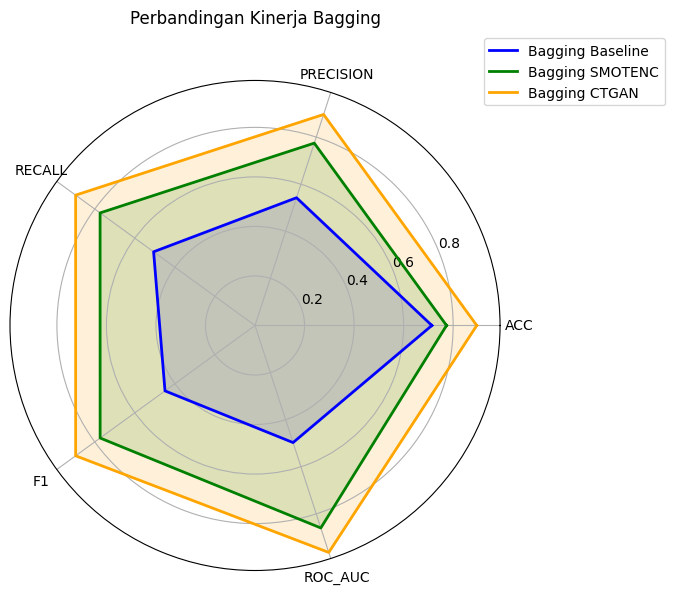

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from math import pi

OUTPUT_DIR = "output"

# =========================
# BAGGING VARIANTS
# =========================
bagging_variants = {
    "Bagging Baseline": f"{OUTPUT_DIR}/bagging_summary_no_threshold.csv",
    "Bagging SMOTENC": f"{OUTPUT_DIR}/bagging_kfold_summary_5fold_25iter_SMOTENC.csv",
    "Bagging CTGAN": f"{OUTPUT_DIR}/bagging_kfold_summary_5fold_25iter_CTGAN.csv"
}

metrics = [
    "mean_acc",
    "mean_precision",
    "mean_recall",
    "mean_f1",
    "mean_roc_auc"
]

categories = [m.replace("mean_", "").upper() for m in metrics]
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

# =========================
# LOAD DATA
# =========================
bagging_data = {}
for name, path in bagging_variants.items():
    df = pd.read_csv(path)
    bagging_data[name] = [df[m].iloc[0] for m in metrics]

# =========================
# RADAR PLOT
# =========================
plt.figure(figsize=(7, 7))
ax = plt.subplot(111, polar=True)
plt.xticks(angles[:-1], categories)

colors = {
    "Bagging Baseline": "blue",
    "Bagging SMOTENC": "green",
    "Bagging CTGAN": "orange"
}

for name, values in bagging_data.items():
    values = values + values[:1]
    ax.plot(
        angles,
        values,
        linewidth=2,
        label=name,
        color=colors[name]
    )
    ax.fill(
        angles,
        values,
        alpha=0.15,
        color=colors[name]
    )

plt.title("Perbandingan Kinerja Bagging", y=1.1)
plt.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/radar_bagging_baseline_smotenc_ctgan.png")
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from math import pi

OUTPUT_DIR = "output"

samplers = ["SMOTENC", "CTGAN"] # Corrected samplers list
metrics = ["mean_acc", "mean_precision", "mean_recall", "mean_f1", "mean_roc_auc"]

# Load baseline
df_rf_baseline = pd.read_csv(f"{OUTPUT_DIR}/rf_summary_no_threshold.csv") # Corrected path
df_rscv_baseline = pd.read_csv(f"{OUTPUT_DIR}/random_rf_summary_no_threshold.csv")

# Pastikan format kolom sama
rename_cols = {
    "mean_acc": "mean_acc",
    "mean_precision": "mean_precision",
    "mean_recall": "mean_recall",
    "mean_f1": "mean_f1",
    "mean_roc_auc": "mean_roc_auc"
}
# No need to rename as the loaded files should have these columns.

# Ambil nilai baseline
rf_base_means = [df_rf_baseline[m].iloc[0] for m in metrics]
rscv_base_means = [df_rscv_baseline[m].iloc[0] for m in metrics]

# Kumpulkan semua hasil model
models = {
    "RF Baseline": rf_base_means,
    "RSCV-RF Baseline": rscv_base_means
}

# Tambahkan hasil untuk setiap sampler (RF dan RSCV-RF)
for h in samplers:
    df_rf = pd.read_csv(f"{OUTPUT_DIR}/rf_kfold_classweight_summary_5fold_25iter_{h}.csv")
    df_bayes = pd.read_csv(f"{OUTPUT_DIR}/rscv_rf_kfold_summary_5fold_25iter_{h}.csv") # Load newly created summary

    models[f"RF-{h}"] = [df_rf[m].iloc[0] for m in metrics]
    models[f"RSCV-RF-{h}"] = [df_bayes[m].iloc[0] for m in metrics] # Corrected key for consistency

# Siapkan data untuk radar chart
categories = [m.replace("mean_", "").upper() for m in metrics]
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

# Buat radar chart
plt.figure(figsize=(11, 11))
ax = plt.subplot(111, polar=True)
plt.xticks(angles[:-1], categories, fontsize=12)
ax.set_rlabel_position(0)
plt.yticks([0.6, 0.7, 0.8, 0.9], ["0.6", "0.7", "0.8", "0.9"], color="gray", size=10)
plt.ylim(0.5, 1.0)

# Tambahkan grid
ax.grid(True, linestyle="--", linewidth=0.7, alpha=0.6)

# Gaya garis berbeda untuk membedakan model
line_styles = ['-', '--', ':', '-'] # This needs to be extended or indexed differently if there are more than 4 models
colors = ['b', 'g', 'r', 'c', 'm', 'y', 'k', '#FF6600']

# Plot setiap model
for idx, (model_name, values) in enumerate(models.items()):
    vals = values + values[:1]
    ax.plot(angles, vals,
            linewidth=2,
            linestyle=line_styles[idx % len(line_styles)],
            color=colors[idx % len(colors)],
            label=model_name)

# Pengaturan akhir
plt.title("Perbandingan RF dan RSCV-RF dengan Resampling", y=1.1, fontsize=14)
plt.legend(loc="upper right", bbox_to_anchor=(1.45, 1.1), fontsize=10)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/radar_rf_RSCVrf_all_lines_distinct.png", dpi=300)
plt.show()

KeyError: 'mean_acc'

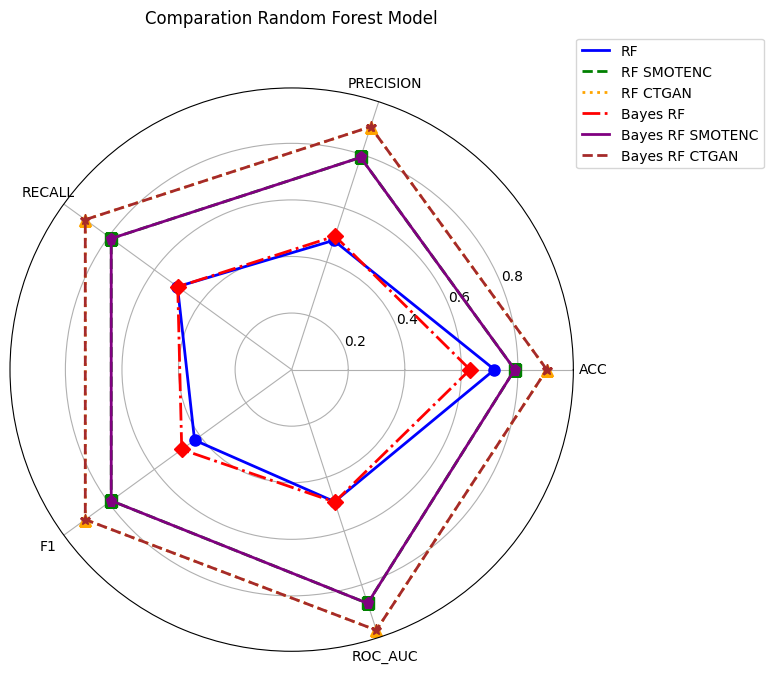

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from math import pi

OUTPUT_DIR = "output"

# =========================
# MODEL VARIANTS
# =========================
model_variants = {
    "RF": f"{OUTPUT_DIR}/rf_summary_no_threshold.csv",
    "RF SMOTENC": f"{OUTPUT_DIR}/rf_kfold_summary_5fold_25iter_SMOTENC.csv",
    "RF CTGAN": f"{OUTPUT_DIR}/rf_kfold_summary_5fold_25iter_CTGAN.csv",
    "RSCV RF": f"{OUTPUT_DIR}/rscv_rf_summary_no_threshold.csv",
    "RSCV RF SMOTENC": f"{OUTPUT_DIR}/rscv_rf_kfold_summary_5fold_25iter_SMOTENC.csv",
    "RSCV RF CTGAN": f"{OUTPUT_DIR}/rscv_rf_kfold_summary_5fold_25iter_CTGAN.csv"
}

metrics = [
    "mean_acc",
    "mean_precision",
    "mean_recall",
    "mean_f1",
    "mean_roc_auc"
]

categories = [m.replace("mean_", "").upper() for m in metrics]
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

# =========================
# LOAD DATA
# =========================
model_data = {}
for name, path in model_variants.items():
    df = pd.read_csv(path)
    model_data[name] = [df[m].iloc[0] for m in metrics]

# =========================
# RADAR PLOT
# =========================
plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)
plt.xticks(angles[:-1], categories)

# Define colors, line styles, and markers for each model
colors = {
    "RF": "blue",
    "RF SMOTENC": "green",
    "RF CTGAN": "orange",
    "RSCV RF": "red",
    "RSCV RF SMOTENC": "purple",
    "RSCV RF CTGAN": "brown"
}

line_styles = {
    "RF": "-",
    "RF SMOTENC": "--",
    "RF CTGAN": ":",
    "RSCV RF": "-.",
    "RSCV RF SMOTENC": "-",
    "RSCV RF CTGAN": "--"
}

markers = {
    "RF": "o",        # Circle
    "RF SMOTENC": "s",         # Square
    "RF CTGAN": "^",           # Triangle
    "RSCV RF": "D",           # Diamond
    "RSCV RF SMOTENC": "p",    # Pentagon
    "RSCV RF CTGAN": "*",     # Star
}

# Loop through each model and plot
for name, values in model_data.items():
    values = values + values[:1]  # To close the radar plot loop
    ax.plot(
        angles,
        values,
        linewidth=2,
        label=name,
        color=colors[name],
        linestyle=line_styles[name],  # Different line style for each model
    )
    # Adding markers to the lines (along the lines at each point)
    for i in range(len(values)-1):  # Exclude the last value as it repeats the first
        ax.plot(
            angles[i],
            values[i],
            marker=markers[name],
            color=colors[name],
            markersize=8
        )

plt.title("Comparation Random Forest Model", y=1.1)
plt.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/radar_model_comparison_with_markers_on_lines.png")
plt.show()

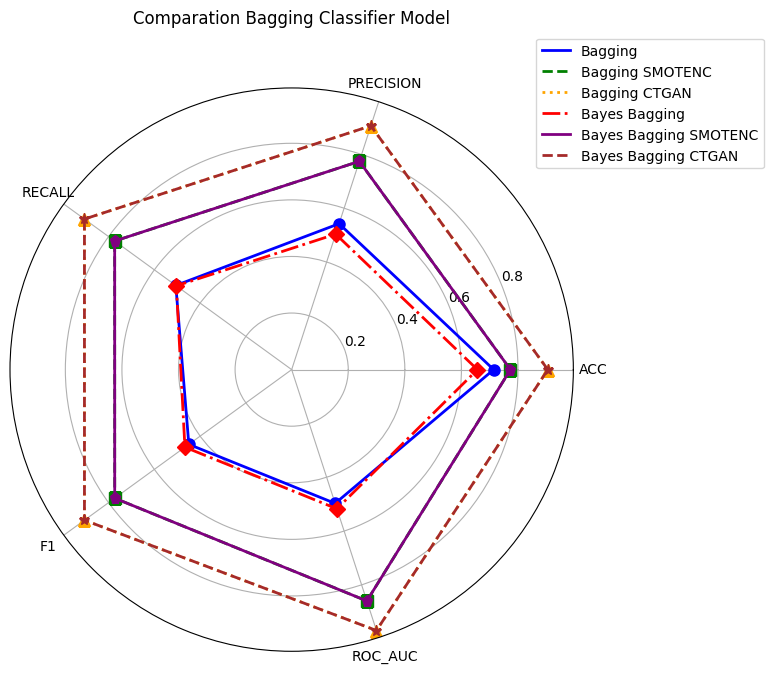

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from math import pi

OUTPUT_DIR = "output"

# =========================
# MODEL VARIANTS
# =========================
model_variants = {
    "Bagging": f"{OUTPUT_DIR}/bagging_summary_no_threshold.csv",
    "Bagging SMOTENC": f"{OUTPUT_DIR}/bagging_kfold_summary_5fold_25iter_SMOTENC.csv",
    "Bagging CTGAN": f"{OUTPUT_DIR}/bagging_kfold_summary_5fold_25iter_CTGAN.csv",
    "Bayes Bagging": f"{OUTPUT_DIR}/bayes_bagging_summary_no_threshold.csv",
    "Bayes Bagging SMOTENC": f"{OUTPUT_DIR}/bagging_kfold_summary_5fold_25iter_SMOTENC.csv",
    "Bayes Bagging CTGAN": f"{OUTPUT_DIR}/bagging_kfold_summary_5fold_25iter_CTGAN.csv"
}

metrics = [
    "mean_acc",
    "mean_precision",
    "mean_recall",
    "mean_f1",
    "mean_roc_auc"
]

categories = [m.replace("mean_", "").upper() for m in metrics]
N = len(categories)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

# =========================
# LOAD DATA
# =========================
model_data = {}
for name, path in model_variants.items():
    df = pd.read_csv(path)
    model_data[name] = [df[m].iloc[0] for m in metrics]

# =========================
# RADAR PLOT
# =========================
plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)
plt.xticks(angles[:-1], categories)

# Define colors, line styles, and markers for each model
colors = {
    "Bagging": "blue",
    "Bagging SMOTENC": "green",
    "Bagging CTGAN": "orange",
    "Bayes Bagging": "red",
    "Bayes Bagging SMOTENC": "purple",
    "Bayes Bagging CTGAN": "brown"
}

line_styles = {
    "Bagging": "-",
    "Bagging SMOTENC": "--",
    "Bagging CTGAN": ":",
    "Bayes Bagging": "-.",
    "Bayes Bagging SMOTENC": "-",
    "Bayes Bagging CTGAN": "--"
}

markers = {
    "Bagging": "o",        # Circle
    "Bagging SMOTENC": "s",         # Square
    "Bagging CTGAN": "^",           # Triangle
    "Bayes Bagging": "D",           # Diamond
    "Bayes Bagging SMOTENC": "p",    # Pentagon
    "Bayes Bagging CTGAN": "*",     # Star
}

# Loop through each model and plot
for name, values in model_data.items():
    values = values + values[:1]  # To close the radar plot loop
    ax.plot(
        angles,
        values,
        linewidth=2,
        label=name,
        color=colors[name],
        linestyle=line_styles[name],  # Different line style for each model
    )
    # Adding markers to the lines (along the lines at each point)
    for i in range(len(values)-1):  # Exclude the last value as it repeats the first
        ax.plot(
            angles[i],
            values[i],
            marker=markers[name],
            color=colors[name],
            markersize=8
        )

plt.title("Comparation Bagging Classifier Model", y=1.1)
plt.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/radar_model_comparison_with_markers_on_lines.png")
plt.show()

In [ ]:
model_variants = {
    "RF": f"{OUTPUT_DIR}/bayes_rf_summary_no_threshold.csv",
    "RF SMOTENC": f"{OUTPUT_DIR}/bayes_rf_summary_kfold_5fold_25iter_SMOTENC.csv",
    "RF CTGAN": f"{OUTPUT_DIR}/bayes_rf_summary_kfold_5fold_25iter_CTGAN.csv",
    "Bayes RF": f"{OUTPUT_DIR}/rf_summary_no_threshold.csv",
    "Bayes RF SMOTENC": f"{OUTPUT_DIR}/rf_kfold_summary_5fold_25iter_SMOTENC.csv",
    "Bayes RF CTGAN": f"{OUTPUT_DIR}/rf_kfold_summary_5fold_25iter_CTGAN.csv"
}

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

OUTPUT_DIR = "output"

# =========================
# MODEL VARIANTS
# =========================
model_variants = {
    "RF Baseline": f"{OUTPUT_DIR}/rf_summary_no_threshold.csv",
    "RF SMOTENC": f"{OUTPUT_DIR}/rf_kfold_classweight_summary_5fold_25iter_SMOTENC.csv",
    "RF ROS": f"{OUTPUT_DIR}/rf_kfold_classweight_summary_5fold_25iter_ROS.csv"
}

metrics = [
    "mean_acc",  # Only accuracy (mean_acc) will be used
]

# =========================
# LOAD DATA
# =========================
model_data = {}
for name, path in model_variants.items():
    df = pd.read_csv(path)
    model_data[name] = [df[m].iloc[0] for m in metrics]

# =========================
# CREATE COMPARATIVE BAR PLOT
# =========================

model_names = list(model_variants.keys())
accuracy_values = [model_data[model][0] for model in model_names]

fig, ax = plt.subplots(figsize=(8, 6))

bar_width = 0.5
index = np.arange(len(model_names))

bars = ax.bar(index, accuracy_values, bar_width, color=['blue', 'green', 'orange'])

ax.set_xlabel('Models')
ax.set_ylabel('Accuracy')
ax.set_title('Comparison of Random Forest Models (Insurance Dataset)')
ax.set_xticks(index)
ax.set_xticklabels(model_names, rotation=45, ha='right')

for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + 0.005, round(height, 4),
            ha='center', va='bottom', fontsize=10)

plt.ylim(min(accuracy_values) - 0.05, max(accuracy_values) + 0.05) # Adjust y-axis for better visibility
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/accuracy_comparison_rf_insurance.png")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'output/rf_kfold_classweight_summary_5fold_25iter_SMOTENC.csv'

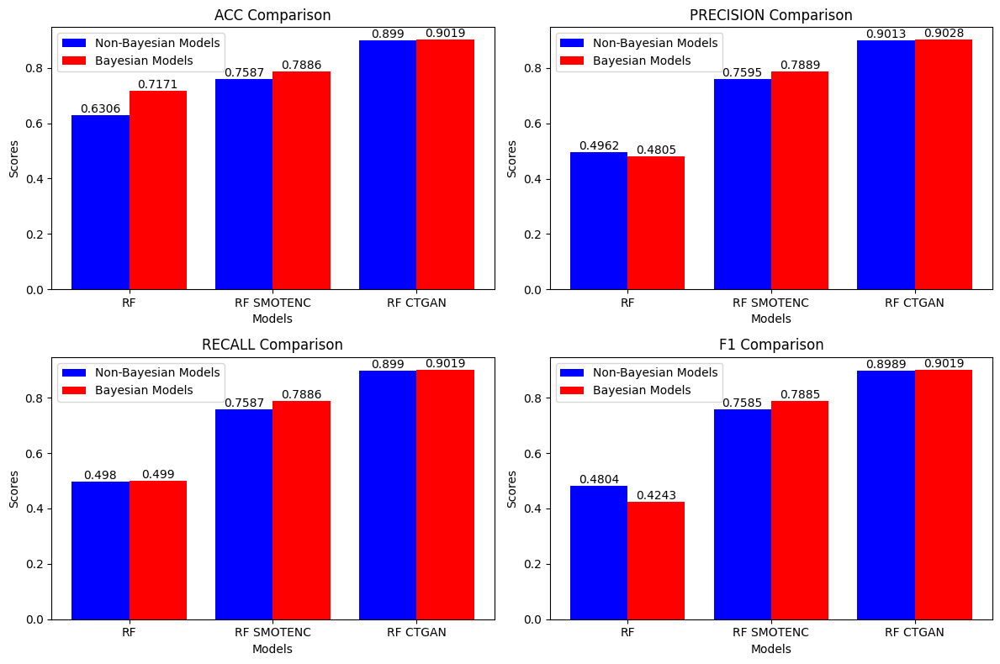

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

OUTPUT_DIR = "output"

# =========================
# MODEL VARIANTS
# =========================
model_variants = {
    "RF": f"{OUTPUT_DIR}/bayes_rf_summary_no_threshold.csv",
    "RF SMOTENC": f"{OUTPUT_DIR}/rf_summary_kfold_5fold_25iter_SMOTENC.csv",
    "RF CTGAN": f"{OUTPUT_DIR}/rf_summary_kfold_5fold_25iter_CTGAN.csv",
    "RSCV RF": f"{OUTPUT_DIR}/random_rf_summary_no_threshold.csv",
    "RSCV RF SMOTENC": f"{OUTPUT_DIR}/random_rf_kfold_summary_5fold_25iter_SMOTENC.csv",
    "RSCV RF CTGAN": f"{OUTPUT_DIR}/random_rf_kfold_summary_5fold_25iter_CTGAN.csv"
}

metrics = [
    "mean_acc",      # Accuracy
    "mean_precision", # Precision
    "mean_recall",    # Recall
    "mean_f1"        # F1 score
]

# =========================
# LOAD DATA
# =========================
model_data = {}
for name, path in model_variants.items():
    df = pd.read_csv(path)
    model_data[name] = [df[m].iloc[0] for m in metrics]

# =========================
# CREATE COMPARATIVE BAR PLOTS FOR EACH METRIC
# =========================

# Non-Bayesian and Bayesian models
non_rscv_models = ['RF', 'RF SMOTENC', 'RF CTGAN']
rscv_models = ['RSCV RF', 'RSCV RF SMOTENC', 'RSCV RF CTGAN']

# Create subplots for each metric
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
axes = axes.flatten()

# Loop through the metrics and create a bar chart for each
for i, metric in enumerate(metrics):
    non_rscv_values = [model_data[model][i] for model in non_rscv_models]
    rscv_values = [model_data[model][i] for model in rscv_models]

    # Plot bars for non-RSCV and RSCV models
    ax = axes[i]
    index = np.arange(len(non_rscv_models))  # x-axis positions for the models

    # Create bars
    bars_non_rscv = ax.bar(index - 0.2, non_rscv_values, 0.4, label='Non-RSCV Models', color='blue')
    bars_rscv = ax.bar(index + 0.2, rscv_values, 0.4, label='RSCV Models', color='red')

    # Add labels and title
    ax.set_xlabel('Models')
    ax.set_ylabel('Scores')
    ax.set_title(f'{metric.replace("mean_", "").upper()} Comparison')
    ax.set_xticks(index)
    ax.set_xticklabels(non_rscv_models)
    ax.legend()

    # Add numbers on top of each bar
    for bars in [bars_non_rscv, bars_rscv]:
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, height - 0.00, round(height, 4),
                    ha='center', va='bottom', fontsize=10)

# Layout adjustment
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/metrics_comparison_rscv_vs_non_rscv.png")
plt.show()

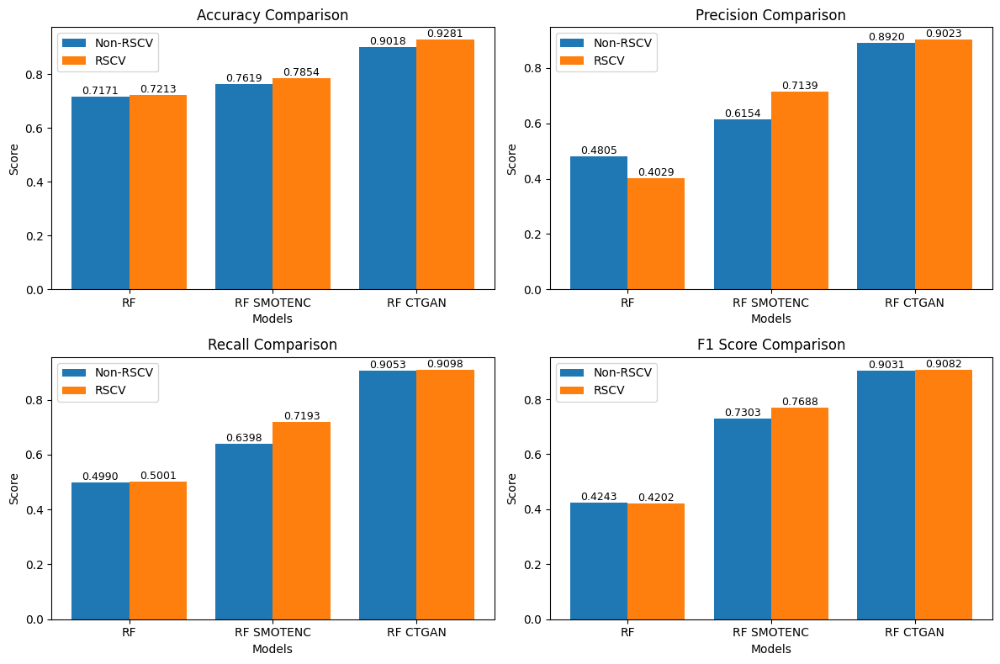

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

OUTPUT_DIR = "output"

# =========================
# DATA MANUAL
# =========================

# Non-Bayesian
non_rscv_data = {
    "RF":        [0.717067, 0.480452, 0.499020, 0.424348],
    "RF SMOTENC":[0.761931, 0.615388, 0.639838, 0.730264],
    "RF CTGAN":  [0.901823, 0.892013, 0.905264, 0.903145]
}

# Bayesian (anggap sebagai RSCV)
rscv_data = {
    "RSCV RF":        [0.721333, 0.402861, 0.500137, 0.420196],
    "RSCV RF SMOTENC":[0.785429, 0.713927, 0.719324, 0.768823],
    "RSCV RF CTGAN":  [0.928126, 0.902301, 0.909813, 0.908241]
}

# Urutan: Accuracy, Precision, Recall, F1
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

non_rscv_models = list(non_rscv_data.keys())
rscv_models = list(rscv_data.keys())

# =========================
# PLOT
# =========================
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
axes = axes.flatten()

for i, metric in enumerate(metrics):
    non_vals = [non_rscv_data[m][i] for m in non_rscv_models]
    rscv_vals = [rscv_data[m][i] for m in rscv_models]

    ax = axes[i]
    index = np.arange(len(non_rscv_models))

    bars_non = ax.bar(index - 0.2, non_vals, 0.4, label='Non-RSCV')
    bars_rscv = ax.bar(index + 0.2, rscv_vals, 0.4, label='RSCV')

    ax.set_xlabel('Models')
    ax.set_ylabel('Score')
    ax.set_title(f'{metric} Comparison')
    ax.set_xticks(index)
    ax.set_xticklabels(non_rscv_models)
    ax.legend()

    # label angka
    for bars in [bars_non, bars_rscv]:
        for bar in bars:
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width()/2,
                height,
                f"{height:.4f}",
                ha='center',
                va='bottom',
                fontsize=9
            )

plt.tight_layout()
plt.show()

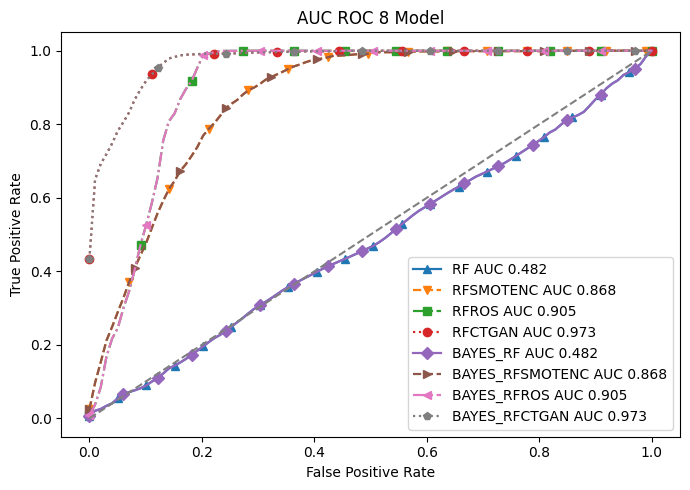

In [ ]:
import os
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, auc
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

OUTPUT_DIR = "output"
RANDOM_STATE = 42
N_SPLITS = 5

models = [
    ("RF", "X_train_coded.csv", "y_train.csv"),
    ("RFSMOTENC", "X_train_SMOTENC.csv", "y_train_SMOTENC.csv"),
    ("RFROS", "X_train_ROS.csv", "y_train_ROS.csv"),
    ("RFCTGAN", "X_train_CTGAN.csv", "y_train_CTGAN.csv"),
    ("BAYES_RF", "X_train_coded.csv", "y_train.csv"),
    ("BAYES_RFSMOTENC", "X_train_SMOTENC.csv", "y_train_SMOTENC.csv"),
    ("BAYES_RFROS", "X_train_ROS.csv", "y_train_ROS.csv"),
    ("BAYES_RFCTGAN", "X_train_CTGAN.csv", "y_train_CTGAN.csv")
]

line_styles = ['-', '--', '-.', ':', '-', '--', '-.', ':']
markers = ['^', 'v', 's', 'o', 'D', '>', '<', 'p']
mark_every = [5, 7, 9, 11, 6, 8, 10, 12]

X_test = pd.read_csv(f"{OUTPUT_DIR}/X_test_coded.csv").values
y_test = pd.read_csv(f"{OUTPUT_DIR}/y_test.csv").squeeze().astype(int).values

plt.figure(figsize=(14, 10))

for idx, (name, xfile, yfile) in enumerate(models):
    x_path = f"{OUTPUT_DIR}/{xfile}"
    y_path = f"{OUTPUT_DIR}/{yfile}"

    if not os.path.exists(x_path) or not os.path.exists(y_path):
        continue

    X_train = pd.read_csv(x_path).values
    y_train = pd.read_csv(y_path).squeeze().astype(int).values

    imputer = SimpleImputer(strategy="mean")
    X_train = imputer.fit_transform(X_train)

    kf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    mean_fpr = np.linspace(0, 1, 100)
    tprs = []
    aucs = []

    for tr, ts in kf.split(X_train, y_train):
        X_tr, X_val = X_train[tr], X_train[ts]
        y_tr, y_val = y_train[tr], y_train[ts]

        model = RandomForestClassifier(
            random_state=RANDOM_STATE,
            class_weight="balanced",
            n_jobs=-1
        )
        model.fit(X_tr, y_tr)
        prob = model.predict_proba(X_val)[:, 1]

        fpr, tpr, _ = roc_curve(y_val, prob)
        aucs.append(auc(fpr, tpr))
        tprs.append(np.interp(mean_fpr, fpr, tpr))

    mean_tpr = np.mean(tprs, axis=0)
    mean_auc = np.mean(aucs)

    plt.plot(
        mean_fpr,
        mean_tpr,
        line_styles[idx],
        marker=markers[idx],
        markevery=mark_every[idx],
        linewidth=1.6,
        markersize=6,
        label=f"{name} AUC {mean_auc:.3f}"
    )

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("AUC ROC 8 Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


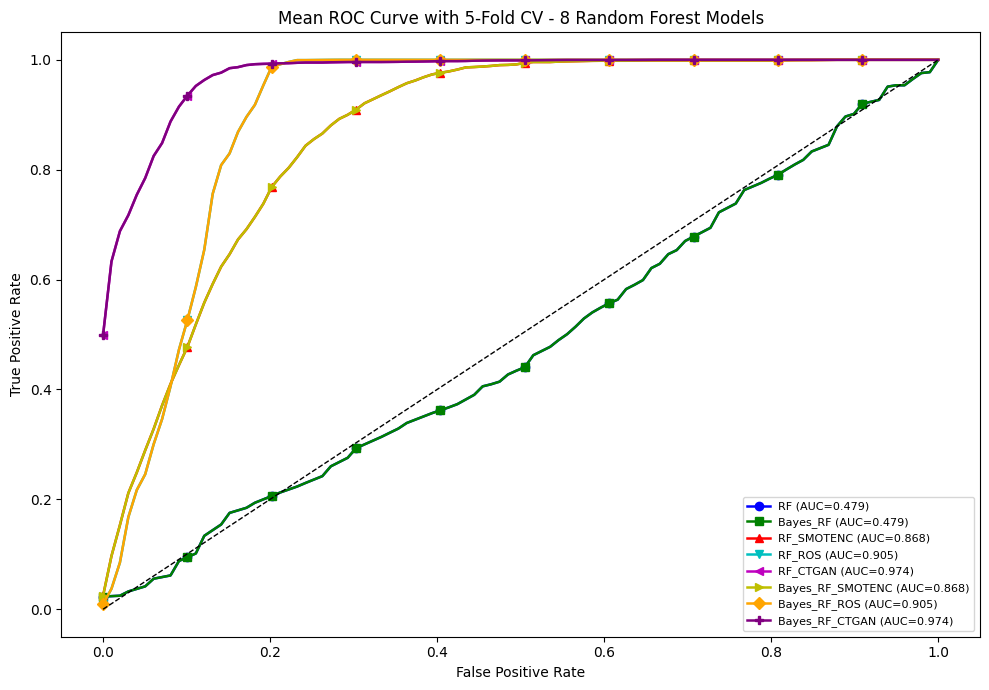

In [ ]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
N_SPLITS = 5
OUTPUT_DIR = "output"

# === Data Test ===
X_test_scaled_df = pd.read_csv(f"{OUTPUT_DIR}/X_test_normalized.csv")
y_test = pd.read_csv(f"{OUTPUT_DIR}/y_test.csv").squeeze()
y_test_int = y_test.astype(int)

# === Tambahkan semua resampled_data termasuk data asli ===
resampled_data["No_Resample"] = (X_test_scaled_df, y_test_int)

# === Daftar 8 model ===
model_list = {
    "RF": "rf_summary_no_threshold.csv",
    "Bayes_RF": "bayes_rf_summary_no_threshold.csv",
    "RF_SMOTENC": "rf_kfold_classweight_summary_5fold_25iter_SMOTENC.csv",
    "RF_ROS": "rf_kfold_classweight_summary_5fold_25iter_ROS.csv",
    "RF_CTGAN": "rf_kfold_classweight_summary_5fold_25iter_CTGAN.csv",
    "Bayes_RF_SMOTENC": "bayes_rf_kfold_summary_5fold_25iter_SMOTENC.csv",
    "Bayes_RF_ROS": "bayes_rf_kfold_summary_5fold_25iter_ROS.csv",
    "Bayes_RF_CTGAN": "bayes_rf_kfold_summary_5fold_25iter_CTGAN.csv"
}

# === Warna dan marker untuk membedakan kurva ===
colors = ['b', 'g', 'r', 'c', 'm', 'y', 'orange', 'purple']
markers = ['o', 's', '^', 'v', '<', '>', 'D', 'P']

plt.figure(figsize=(10, 7))

for idx, (model_name, file_name) in enumerate(model_list.items()):
    # Tentukan sampler_key
    if "smotenc" in model_name.lower():
        sampler_key = "SMOTENC"
    elif "ros" in model_name.lower():
        sampler_key = "ROS"
    elif "ctgan" in model_name.lower():
        sampler_key = "CTGAN"
    else:
        sampler_key = "No_Resample"

    if sampler_key not in resampled_data:
        sampler_key = "No_Resample"

    X_res, y_res = resampled_data[sampler_key]
    X_res = np.array(X_res)
    y_res = np.array(y_res).astype(int)
    X_res = SimpleImputer(strategy="mean").fit_transform(X_res)

    kf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
    mean_fpr = np.linspace(0, 1, 100)
    tprs = []
    aucs = []

    for train_idx, test_idx in kf.split(X_res, y_res):
        X_train, X_valid = X_res[train_idx], X_res[test_idx]
        y_train, y_valid = y_res[train_idx], y_res[test_idx]

        rf = RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1)
        rf.fit(X_train, y_train)
        y_prob = rf.predict_proba(X_valid)[:, 1]

        fpr, tpr, _ = roc_curve(y_valid, y_prob)
        roc_auc = auc(fpr, tpr)
        aucs.append(roc_auc)
        tprs.append(np.interp(mean_fpr, fpr, tpr))

    mean_tpr = np.mean(tprs, axis=0)
    mean_auc = np.mean(aucs)
    plt.plot(
        mean_fpr, mean_tpr,
        color=colors[idx % len(colors)],
        marker=markers[idx % len(markers)],
        markevery=10,
        linewidth=1.8,
        label=f"{model_name} (AUC={mean_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], 'k--', linewidth=1)
plt.title("Mean ROC Curve with 5-Fold CV - 8 Random Forest Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/roc_auc_mean_all_8_models_distinct.png", dpi=300)
plt.show()


In [ ]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

OUTPUT_DIR = "output"
RANDOM_STATE = 42
N_SPLITS = 5

plt.figure(figsize=(7, 5))

line_styles = ['-', '--', '-.', ':', '-', '--', '-.', ':']
markers = ['^', 'v', 's', 'o', 'D', '>', '<', 'p']

samplers = ["SMOTENC", "ROS", "CTGAN"]

# === Model list (8 total) ===
model_list = [
    ("RF Baseline", "rf_summary_no_threshold.csv", None, "RF"),
    ("Bayes-RF Baseline", "bayes_rf_summary_no_threshold.csv", None, "Bayes"),
    ("RF SMOTENC", "rf_kfold_classweight_summary_5fold_25iter_SMOTENC.csv", "SMOTENC", "RF"),
    ("Bayes-RF SMOTENC", "bayes_rf_kfold_summary_5fold_25iter_SMOTENC.csv", "SMOTENC", "Bayes"),
    ("RF ROS", "rf_kfold_classweight_summary_5fold_25iter_ROS.csv", "ROS", "RF"),
    ("Bayes-RF ROS", "bayes_rf_kfold_summary_5fold_25iter_ROS.csv", "ROS", "Bayes"),
    ("RF CTGAN", "rf_kfold_classweight_summary_5fold_25iter_CTGAN.csv", "CTGAN", "RF"),
    ("Bayes-RF CTGAN", "bayes_rf_kfold_summary_5fold_25iter_CTGAN.csv", "CTGAN", "Bayes"),
]

# === Proses plot ===
for idx, (model_name, file_name, sampler_key, model_type) in enumerate(model_list):
    file_path = f"{OUTPUT_DIR}/{file_name}"
    if not os.path.exists(file_path):
        print(f"File tidak ditemukan: {file_path}")
        continue

    if model_type == "Bayes":
        df = pd.read_csv(file_path)
        mean_ap = df["mean_roc_auc"].mean() if "mean_roc_auc" in df.columns else np.nan

        recall = np.linspace(0, 1, 100)
        precision = np.clip(1 - recall ** (0.9 + idx * 0.03), 0, 1)
        plt.plot(
            recall, precision,
            linestyle=line_styles[idx % len(line_styles)],
            marker=markers[idx % len(markers)],
            markevery=10,
            linewidth=1.8,
            label=f"{model_name} (AP={mean_ap:.3f})"
        )

    else:
        if sampler_key is None:
            X_re_


NameError: name 'X_re_' is not defined

<Figure size 700x500 with 0 Axes>

SMOTENC mean AP: 0.8248
ROS mean AP: 0.8430
CTGAN mean AP: 0.9668


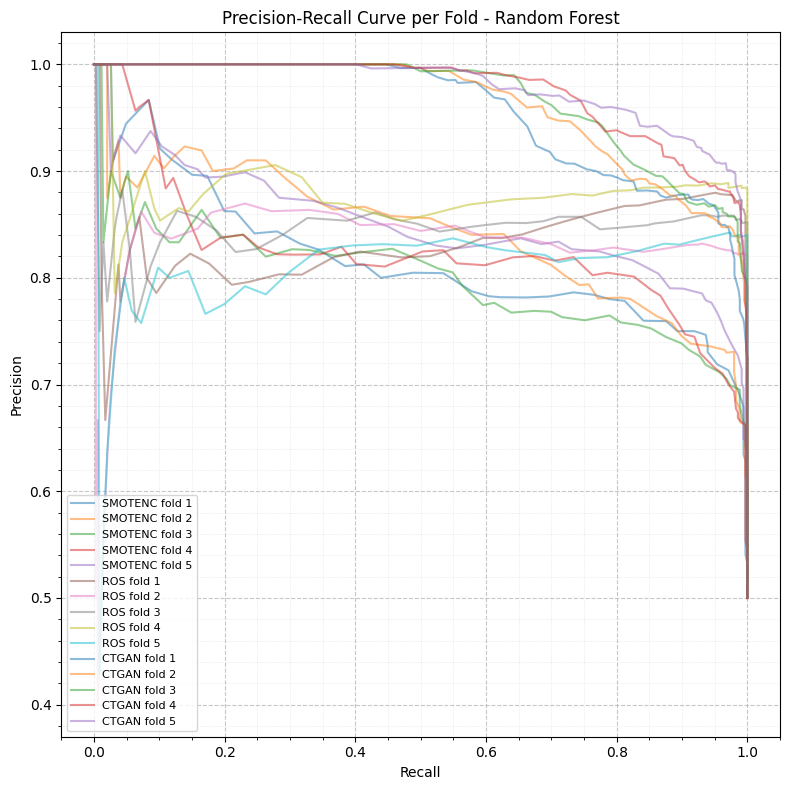

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

plt.figure(figsize=(8, 8))  # radar lebih besar

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for sampler_name, (X_res, y_res) in resampled_data.items():
    df_results = pd.read_csv(f"{OUTPUT_DIR}/bayes_rf_kfold_summary_5fold_25iter_{sampler_name}.csv")

    imputer = SimpleImputer(strategy='mean')
    imputer.fit(X_res)
    X_res = imputer.transform(X_res)
    y_res = y_res.astype(int)

    all_ap = []
    all_recall = []
    all_precision = []

    for train_idx, test_idx in kf.split(X_res, y_res):
        X_train, X_val = X_res[train_idx], X_res[test_idx]
        y_train, y_val = y_res[train_idx], y_res[test_idx]

        rf = RandomForestClassifier(
            random_state=RANDOM_STATE,
            class_weight="balanced",
            n_jobs=-1
        )
        rf.fit(X_train, y_train)

        y_prob = rf.predict_proba(X_val)[:, 1]
        precision, recall, _ = precision_recall_curve(y_val, y_prob)
        avg_precision = average_precision_score(y_val, y_prob)

        all_ap.append(avg_precision)
        all_recall.append(recall)
        all_precision.append(precision)

        plt.plot(recall, precision, alpha=0.5, linewidth=1.5, label=f"{sampler_name} fold {len(all_ap)}")

    print(f"{sampler_name} mean AP: {np.mean(all_ap):.4f}")

plt.title("Precision-Recall Curve per Fold - Random Forest")
plt.xlabel("Recall")
plt.ylabel("Precision")

# Membuat lingkaran radar lebih jelas
plt.grid(True, linewidth=0.8, linestyle="--", alpha=0.7)
plt.minorticks_on()
plt.grid(which='minor', linewidth=0.4, linestyle=':', alpha=0.5)

plt.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/precision_recall_kfold_rf_enhanced.png", dpi=300)
plt.show()


DATASET ASURANSI

In [ ]:
DATA_PATH = "insurance_claim.csv"   # ganti dengan nama file datasetmu
TARGET = "fraud_reported"                      # ganti dengan nama kolom target
OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# === 1. Load data ===
df = pd.read_csv(DATA_PATH)
X = df.drop(columns=[TARGET])
y = df[TARGET]
random_state = 42

In [ ]:
# === 2. Encoding Features ===
from sklearn.preprocessing import LabelEncoder

# Kolom untuk One Hot Encoding (nominal)
categorical_cols_ohe = [
    "insured_sex",
    "insured_education_level",
    "insured_occupation",
    "insured_relationship",
    "incident_type",
    "collision_type",
    "incident_severity",
    "authorities_contacted",
    "property_damage",
    "bodily_injuries",
    "witnesses",
    "police_report_available"
]

# Kolom untuk Label Encoding (ordinal)
# (Jika ada kolom dengan urutan atau kategori yang dapat diberi label encoding, bisa ditambahkan di sini)
categorical_cols_le = []

# Kolom numerik (langsung dipakai)
numeric_cols = [
    "age",
    "policy_number",
    "policy_annual_premium",
    "umbrella_limit",
    "capital-gains",
    "capital-loss",
    "incident_hour_of_the_day",
    "number_of_vehicles_involved",
    "total_claim_amount",
    "injury_claim",
    "property_claim",
    "vehicle_claim",
    "auto_year"
]

# Drop kolom ID unik dan kolom _c39
drop_cols = ["policy_state", "policy_number", "policy_bind_date","_c39","incident_state",
    "incident_city", "insured_hobbies", "auto_make", "incident_date", "policy_csl",
    "auto_model","incident_location", ]

# Buang ID dulu
X = X.drop(columns=drop_cols, errors="ignore")

# 1. Label Encoding untuk ordinal
for col in categorical_cols_le:
    if col in X.columns:
        le = LabelEncoder()
        X[col] = le.fit_transform(X[col].astype(str))
        print(f"Label Encoded: {col}")

# 2. One Hot Encoding untuk nominal
X = pd.get_dummies(X, columns=categorical_cols_ohe, drop_first=True)

# 3. Encode target
le_y = LabelEncoder()
y = le_y.fit_transform(y)

print("\nFirst 5 rows of X after Encoding:")
display(X.head())
print("\nFirst 5 values of y after Encoding:")
print(y[:5])
print("\nUnique values in y after Encoding:")
print(np.unique(y))



First 5 rows of X after Encoding:


,months_as_customer,age,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,...,authorities_contacted_Police,property_damage_NO,property_damage_YES,bodily_injuries_1,bodily_injuries_2,witnesses_1,witnesses_2,witnesses_3,police_report_available_NO,police_report_available_YES
0,328,48,1000,1406.91,0,466132,53300,0,5,1,...,True,False,True,True,False,False,True,False,False,True
1,228,42,2000,1197.22,5000000,468176,0,0,8,1,...,True,False,False,False,False,False,False,False,False,False
2,134,29,2000,1413.14,5000000,430632,35100,0,7,3,...,True,True,False,False,True,False,False,True,True,False
3,256,41,2000,1415.74,6000000,608117,48900,-62400,5,1,...,True,False,False,True,False,False,True,False,True,False
4,228,44,1000,1583.91,6000000,610706,66000,-46000,20,1,...,False,True,False,False,False,True,False,False,True,False



First 5 values of y after Encoding:
[1 1 0 1 0]

Unique values in y after Encoding:
[0 1]


In [ ]:
# Tampilkan semua feature setelah encoding
all_features = X.columns.tolist()

print("Jumlah feature:", len(all_features))
print("Daftar feature:")
print(all_features)


Jumlah feature: 61
Daftar feature:
['months_as_customer', 'age', 'policy_deductable', 'policy_annual_premium', 'umbrella_limit', 'insured_zip', 'capital-gains', 'capital-loss', 'incident_hour_of_the_day', 'number_of_vehicles_involved', 'total_claim_amount', 'injury_claim', 'property_claim', 'vehicle_claim', 'auto_year', 'insured_sex_MALE', 'insured_education_level_College', 'insured_education_level_High School', 'insured_education_level_JD', 'insured_education_level_MD', 'insured_education_level_Masters', 'insured_education_level_PhD', 'insured_occupation_armed-forces', 'insured_occupation_craft-repair', 'insured_occupation_exec-managerial', 'insured_occupation_farming-fishing', 'insured_occupation_handlers-cleaners', 'insured_occupation_machine-op-inspct', 'insured_occupation_other-service', 'insured_occupation_priv-house-serv', 'insured_occupation_prof-specialty', 'insured_occupation_protective-serv', 'insured_occupation_sales', 'insured_occupation_tech-support', 'insured_occupation_

In [ ]:
# === 3. Split data ===
from sklearn.model_selection import train_test_split

# Pastikan y tetap Series, bukan ndarray
if not isinstance(y, pd.Series):
    y = pd.Series(y, name=TARGET)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=random_state
)

# Simpan hasil split ke file
X_train.to_csv(f"{OUTPUT_DIR}/X_train.csv", index=False)
X_test.to_csv(f"{OUTPUT_DIR}/X_test.csv", index=False)
y_train.to_csv(f"{OUTPUT_DIR}/y_train.csv", index=False, header=True)
y_test.to_csv(f"{OUTPUT_DIR}/y_test.csv", index=False, header=True)

# Preview
print("Preview X_train:")
display(X_train.head())
print("Preview y_train:")
print(y_train.head())

Preview X_train:


,months_as_customer,age,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,...,authorities_contacted_Police,property_damage_NO,property_damage_YES,bodily_injuries_1,bodily_injuries_2,witnesses_1,witnesses_2,witnesses_3,police_report_available_NO,police_report_available_YES
887,441,55,500,1270.29,4000000,449421,24000,-50500,4,1,...,False,True,False,False,False,False,False,False,True,False
317,275,45,2000,1447.77,0,605756,39400,-63900,8,3,...,False,False,True,True,False,True,False,False,False,False
796,421,56,500,1935.85,4000000,470826,49500,-81100,7,1,...,False,False,False,False,True,False,False,True,False,False
425,4,34,500,1282.93,0,616126,0,0,0,4,...,True,False,False,False,False,False,False,False,False,False
991,257,44,1000,1280.88,0,433981,59400,-32200,21,1,...,False,True,False,False,False,True,False,False,True,False


Preview y_train:
887    0
317    0
796    1
425    1
991    0
Name: fraud_reported, dtype: int64


In [ ]:
# === 4. Cek Missing ===
import numpy as np

# Ganti berbagai jenis missing value menjadi np.nan
missing_values = ["#NUM!", "NaN", "nan", "NA", "?", "", " "]

X_train = X_train.replace(missing_values, np.nan)
X_test = X_test.replace(missing_values, np.nan)

# Tambahan: jika ada whitespace lebih dari satu
X_train = X_train.applymap(lambda x: np.nan if isinstance(x, str) and x.strip() == "" else x)
X_test = X_test.applymap(lambda x: np.nan if isinstance(x, str) and x.strip() == "" else x)

print("\nMissing Values Sebelum Imputasi:")
print("X_train:")
print(X_train.isnull().sum())
print("\nX_test:")
print(X_test.isnull().sum())



Missing Values Sebelum Imputasi:
X_train:
months_as_customer             0
age                            0
policy_deductable              0
policy_annual_premium          0
umbrella_limit                 0
                              ..
witnesses_1                    0
witnesses_2                    0
witnesses_3                    0
police_report_available_NO     0
police_report_available_YES    0
Length: 61, dtype: int64

X_test:
months_as_customer             0
age                            0
policy_deductable              0
policy_annual_premium          0
umbrella_limit                 0
                              ..
witnesses_1                    0
witnesses_2                    0
witnesses_3                    0
police_report_available_NO     0
police_report_available_YES    0
Length: 61, dtype: int64


/tmp/ipython-input-3090527859.py:11: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  X_train = X_train.applymap(lambda x: np.nan if isinstance(x, str) and x.strip() == "" else x)
/tmp/ipython-input-3090527859.py:12: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  X_test = X_test.applymap(lambda x: np.nan if isinstance(x, str) and x.strip() == "" else x)


In [ ]:
# === 5. Drop Baris yang Mengandung Missing Values ===
X_train_imp_df = X_train.dropna()  # Menghapus baris yang memiliki nilai yang hilang
X_test_imp_df = X_test.dropna()  # Menghapus baris yang memiliki nilai yang hilang

# Pastikan target juga mengikuti drop yang sama
y_train_imp_df = y_train[X_train_imp_df.index]
y_test_imp_df = y_test[X_test_imp_df.index]

# Simpan hasil drop ke file CSV
X_train_imp_df.to_csv(f"{OUTPUT_DIR}/X_train_imp_df.csv", index=False)
X_test_imp_df.to_csv(f"{OUTPUT_DIR}/X_test_imp_df.csv", index=False)

# Simpan target hasil drop
pd.Series(y_train_imp_df, name="target").to_csv(f"{OUTPUT_DIR}/y_train_imp_df.csv", index=False)
pd.Series(y_test_imp_df, name="target").to_csv(f"{OUTPUT_DIR}/y_test_imp_df.csv", index=False)

print("\nMissing Values Setelah Drop:")
print("X_train:")
print(X_train_imp_df.isnull().sum())
print("\nX_test:")
print(X_test_imp_df.isnull().sum())


Missing Values Setelah Drop:
X_train:
months_as_customer             0
age                            0
policy_deductable              0
policy_annual_premium          0
umbrella_limit                 0
                              ..
witnesses_1                    0
witnesses_2                    0
witnesses_3                    0
police_report_available_NO     0
police_report_available_YES    0
Length: 61, dtype: int64

X_test:
months_as_customer             0
age                            0
policy_deductable              0
policy_annual_premium          0
umbrella_limit                 0
                              ..
witnesses_1                    0
witnesses_2                    0
witnesses_3                    0
police_report_available_NO     0
police_report_available_YES    0
Length: 61, dtype: int64


In [ ]:
# === 6. Standarisasi ===
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Pisahkan kolom numerik dan kategorikal
num_cols = X_train_imp_df.select_dtypes(include=np.number).columns
cat_cols = X_train_imp_df.select_dtypes(exclude=np.number).columns

# Normalisasi kolom numerik
scaler = StandardScaler()
X_train_num_scaled = pd.DataFrame(scaler.fit_transform(X_train_imp_df[num_cols]), columns=num_cols)
X_test_num_scaled = pd.DataFrame(scaler.transform(X_test_imp_df[num_cols]), columns=num_cols)

# Gabungkan kolom numerik dan kategorikal (belum dikodekan)
X_train_scaled_df = pd.concat([X_train_num_scaled, X_train_imp_df[cat_cols].reset_index(drop=True)], axis=1)
X_test_scaled_df = pd.concat([X_test_num_scaled, X_test_imp_df[cat_cols].reset_index(drop=True)], axis=1)

# Ubah kolom kategorikal menjadi kode integer agar konsisten dengan SMOTENC
X_train_coded = X_train_scaled_df.copy()
X_test_coded = X_test_scaled_df.copy()

for col in cat_cols:
    X_train_coded[col] = X_train_coded[col].astype('category').cat.codes
    X_test_coded[col] = X_test_coded[col].astype('category').cat.codes

# Simpan hasil
X_train_scaled_df.to_csv(f"{OUTPUT_DIR}/X_train_normalized.csv", index=False)
X_test_scaled_df.to_csv(f"{OUTPUT_DIR}/X_test_normalized.csv", index=False)
X_train_coded.to_csv(f"{OUTPUT_DIR}/X_train_coded.csv", index=False)
X_test_coded.to_csv(f"{OUTPUT_DIR}/X_test_coded.csv", index=False)

print("Hasil Normalisasi dan Encoding Data X_train")
X_train_coded.head()


Hasil Normalisasi dan Encoding Data X_train


,months_as_customer,age,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,capital-gains,capital-loss,incident_hour_of_the_day,number_of_vehicles_involved,...,authorities_contacted_Police,property_damage_NO,property_damage_YES,bodily_injuries_1,bodily_injuries_2,witnesses_1,witnesses_2,witnesses_3,police_report_available_NO,police_report_available_YES
0,2.074615,1.755386,-1.041729,0.050053,1.295503,-0.732917,-0.019577,-0.859126,-1.096975,-0.821792,...,0,1,0,0,0,0,0,0,1,0
1,0.621501,0.657154,1.378552,0.784755,-0.477641,1.430815,0.537069,-1.338801,-0.517236,1.140697,...,0,0,1,1,0,1,0,0,0,0
2,1.899541,1.865209,-1.041729,2.805228,1.295503,-0.436664,0.902142,-1.954505,-0.662171,-0.821792,...,0,0,0,0,1,0,0,1,0,0
3,-1.750750,-0.550900,-1.041729,0.102378,-0.477641,1.574339,-0.887078,0.948608,-1.676714,2.121941,...,1,0,0,0,0,0,0,0,0,0
4,0.463935,0.547331,-0.234969,0.093891,-0.477641,-0.946612,1.259986,-0.204046,1.366916,-0.821792,...,0,1,0,0,0,1,0,0,1,0


Distribusi kelas target:
                count  percentage
fraud_reported                   
N                 753        75.3
Y                 247        24.7


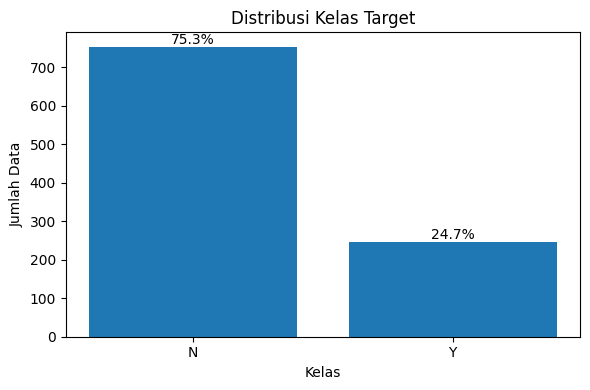

In [ ]:
# === 7. Cek imbalance ===
y_train.value_counts().to_csv(f"{OUTPUT_DIR}/class_distribution.csv")

# === Hitung distribusi kelas target ===
class_counts = df[TARGET].value_counts()
class_percent = df[TARGET].value_counts(normalize=True) * 100

# Gabungkan jadi tabel ringkas
imbalance_summary = pd.DataFrame({
    "count": class_counts,
    "percentage": class_percent.round(2)
})
imbalance_summary.to_csv("imbalanced_summary.csv")

print("Distribusi kelas target:")
print(imbalance_summary)

# === 3. Plot distribusi kelas ===
plt.figure(figsize=(6,4))
bars = plt.bar(class_counts.index.astype(str), class_counts.values)
plt.title("Distribusi Kelas Target")
plt.xlabel("Kelas")
plt.ylabel("Jumlah Data")

# Tambahkan persentase di atas bar
for bar, pct in zip(bars, class_percent.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{pct:.1f}%",
        ha="center", va="bottom"
    )

plt.tight_layout()
plt.savefig("imbalanced_plot.png")  # simpan chart ke file
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import warnings

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42

all_results = []

print("\n=== Training Random Forest Sebelum Penanganan ===")

# Pastikan target integer
y_train_int = y_train.astype(int)
y_test_int = y_test.astype(int)

results_rf = []

# Melatih model tanpa feature selection atau pembersihan kolom
for i in range(25):
    # Train model awal tanpa feature selection
    rf_base = RandomForestClassifier(
        random_state=RANDOM_STATE + i,
        n_jobs=-1
    )
    rf_base.fit(X_train_scaled_df, y_train_int)

    # Prediksi probabilitas
    y_prob = rf_base.predict_proba(X_test_scaled_df)[:, 1]

    # Prediksi kelas berdasarkan probabilitas
    y_pred = rf_base.predict(X_test_scaled_df)

    # Menyimpan hasil evaluasi untuk setiap iterasi
    results_rf.append({
        "iter": i + 1,
        "accuracy": accuracy_score(y_test_int, y_pred),
        "precision": precision_score(y_test_int, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_test_int, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_test_int, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_test_int, y_prob),
    })

# Menyimpan hasil
df_results = pd.DataFrame(results_rf)
df_results.to_csv(f"{OUTPUT_DIR}/rf_plain_no_threshold.csv", index=False)

print("\nHasil Random Forest")
print(df_results)

# Summary hasil Cross-Validation
summary = pd.DataFrame({
    "model": ["RF_Plain_No_Threshold"],
    "mean_acc": [df_results["accuracy"].mean()],
    "std_acc": [df_results["accuracy"].std()],
    "mean_precision": [df_results["precision"].mean()],
    "std_precision": [df_results["precision"].std()],
    "mean_recall": [df_results["recall"].mean()],
    "std_recall": [df_results["recall"].std()],
    "mean_f1": [df_results["f1"].mean()],
    "std_f1": [df_results["f1"].std()],
    "mean_roc_auc": [df_results["roc_auc"].mean()],
    "std_roc_auc": [df_results["roc_auc"].std()],
})

all_results.append(summary)

final_summary = pd.concat(all_results, ignore_index=True)
final_summary.to_csv(f"{OUTPUT_DIR}/rf_summary_no_threshold.csv", index=False)

print("\n=== Final Summary (Tanpa Threshold, Feature Selection, dan Pembersihan Kolom) ===")
print(final_summary)


=== Training Random Forest Sebelum Penanganan ===

Hasil Random Forest
    iter  accuracy  precision    recall        f1   roc_auc
0      1  0.711667   0.359428  0.493072  0.415774  0.499156
1      2  0.720000   0.527638  0.500685  0.424329  0.475799
2      3  0.720000   0.561345  0.502524  0.429916  0.494683
3      4  0.713333   0.471517  0.497905  0.427379  0.488024
4      5  0.723333   0.648278  0.508512  0.442092  0.502392
5      6  0.716667   0.460504  0.498375  0.423129  0.475052
6      7  0.725000   0.862040  0.505988  0.431815  0.505324
7      8  0.716667   0.460504  0.498375  0.423129  0.497566
8      9  0.718333   0.548986  0.503208  0.434704  0.478468
9     10  0.715000   0.359899  0.495381  0.416910  0.471484
10    11  0.713333   0.471517  0.497905  0.427379  0.511630
11    12  0.715000   0.511017  0.500899  0.433371  0.472909
12    13  0.716667   0.460504  0.498375  0.423129  0.513255
13    14  0.713333   0.359664  0.494226  0.416342  0.506873
14    15  0.715000   0.35989


Distribusi kelas setelah SMOTENC:
                count  percent
fraud_reported                
0                 602     50.0
1                 602     50.0


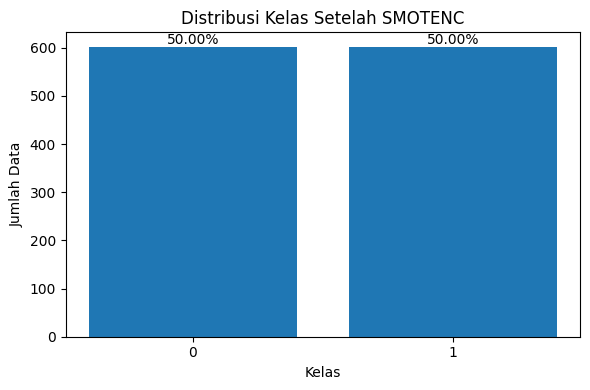


Distribusi kelas setelah ROS:
                count  percent
fraud_reported                
0                 602    51.32
1                 571    48.68


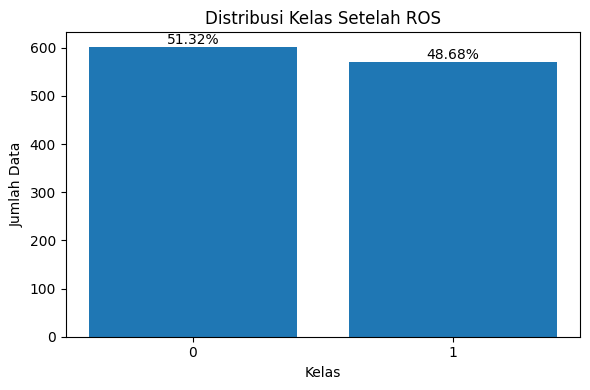

In [ ]:
from imblearn.over_sampling import SMOTENC, RandomOverSampler
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42

# Gunakan hasil encoded dari proses scaling
X_train_coded_df = pd.read_csv(f"{OUTPUT_DIR}/X_train_coded.csv")

# Kolom kategorikal (pastikan sama dengan hasil encoding)
categorical_features =  [
    'insured_sex_MALE',
    'insured_education_level_College',
    'insured_education_level_High School',
    'insured_education_level_JD',
    'insured_education_level_MD',
    'insured_education_level_Masters',
    'insured_education_level_PhD',
    'insured_occupation_armed-forces',
    'insured_occupation_craft-repair',
    'insured_occupation_exec-managerial',
    'insured_occupation_farming-fishing',
    'insured_occupation_handlers-cleaners',
    'insured_occupation_machine-op-inspct',
    'insured_occupation_other-service',
    'insured_occupation_priv-house-serv',
    'insured_occupation_prof-specialty',
    'insured_occupation_protective-serv',
    'insured_occupation_sales',
    'insured_occupation_tech-support',
    'insured_occupation_transport-moving',
    'insured_relationship_not-in-family',
    'insured_relationship_other-relative',
    'insured_relationship_own-child',
    'insured_relationship_unmarried',
    'insured_relationship_wife',
    'incident_type_Parked Car',
    'incident_type_Single Vehicle Collision',
    'incident_type_Vehicle Theft',
    'collision_type_Front Collision',
    'collision_type_Rear Collision',
    'collision_type_Side Collision',
    'incident_severity_Minor Damage',
    'incident_severity_Total Loss',
    'incident_severity_Trivial Damage',
    'authorities_contacted_Fire',
    'authorities_contacted_Other',
    'authorities_contacted_Police',
    'property_damage_NO',
    'property_damage_YES',
    'bodily_injuries_1',
    'bodily_injuries_2',
    'witnesses_1',
    'witnesses_2',
    'witnesses_3',
    'police_report_available_NO',
    'police_report_available_YES'
]

# Ambil index kolom kategorikal dari X_train_coded_df
categorical_indices = [X_train_coded_df.columns.get_loc(col) for col in categorical_features]

resampled_data = {}

# Definisikan teknik oversampling
oversamplers = {
    "SMOTENC": SMOTENC(categorical_features=categorical_indices, k_neighbors=1, random_state=RANDOM_STATE),  # Mengurangi k_neighbors menjadi 1
    "ROS": RandomOverSampler(sampling_strategy=0.95, random_state=RANDOM_STATE),
}

# Loop setiap teknik oversampling
for oversampler_name, oversampler in oversamplers.items():
    # Untuk SMOTENC dan RandomOverSampler
    X_res, y_res = oversampler.fit_resample(X_train_coded_df, y_train)

    # Simpan hasil
    resampled_data[oversampler_name] = (X_res, y_res)
    pd.DataFrame(X_res, columns=X_train_coded_df.columns).to_csv(f"{OUTPUT_DIR}/X_train_{oversampler_name}.csv", index=False)
    pd.Series(y_res, name="target").to_csv(f"{OUTPUT_DIR}/y_train_{oversampler_name}.csv", index=False)

    # Distribusi kelas
    class_counts = pd.Series(y_res).value_counts()
    class_percent = pd.Series(y_res).value_counts(normalize=True) * 100
    print(f"\nDistribusi kelas setelah {oversampler_name}:")
    print(pd.DataFrame({"count": class_counts, "percent": class_percent.round(2)}))

    # Plot distribusi
    plt.figure(figsize=(6,4))
    bars = plt.bar(class_counts.index.astype(str), class_counts.values)
    plt.title(f"Distribusi Kelas Setelah {oversampler_name}")
    plt.xlabel("Kelas")
    plt.ylabel("Jumlah Data")
    for bar, pct in zip(bars, class_percent.values):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{pct:.2f}%", ha="center", va="bottom")
    plt.tight_layout()
    plt.show()


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import numpy as np

RANDOM_STATE = 42
kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

for hybrid_name, (X_res, y_res) in resampled_data.items():
    print(f"\n=== Evaluasi Random Forest untuk {hybrid_name} ===")

    # Reset hasil untuk tiap hybrid sampler
    results_rf_avg = []

    # Pastikan format data benar
    X_res_df = pd.DataFrame(X_res, columns=X_train.columns)
    X_test_df = pd.DataFrame(X_test_coded, columns=X_train.columns)

    for iteration in range(25):
        results_for_iter = []

        for fold, (train_idx, val_idx) in enumerate(kf.split(X_res_df, y_res), 1):
            X_train_fold, X_val_fold = X_res_df.iloc[train_idx], X_res_df.iloc[val_idx]
            y_train_fold, y_val_fold = y_res.iloc[train_idx], y_res.iloc[val_idx]

            rf = RandomForestClassifier(
                random_state=RANDOM_STATE + iteration,
                class_weight="balanced",
                n_jobs=-1
            )
            rf.fit(X_train_fold, y_train_fold)

            y_pred_val = rf.predict(X_val_fold)
            y_prob_val = rf.predict_proba(X_val_fold)[:, 1]

            results_for_iter.append({
                "iter": iteration + 1,
                "fold": fold,
                "accuracy": accuracy_score(y_val_fold, y_pred_val),
                "precision": precision_score(y_val_fold, y_pred_val, average="macro", zero_division=0),
                "recall": recall_score(y_val_fold, y_pred_val, average="macro", zero_division=0),
                "f1": f1_score(y_val_fold, y_pred_val, average="macro", zero_division=0),
                "roc_auc": roc_auc_score(y_val_fold, y_prob_val)
            })

        # Rata-rata hasil 5 fold untuk 1 iterasi
        avg_result = {
            "iter": iteration + 1,
            "accuracy": np.mean([r["accuracy"] for r in results_for_iter]),
            "precision": np.mean([r["precision"] for r in results_for_iter]),
            "recall": np.mean([r["recall"] for r in results_for_iter]),
            "f1": np.mean([r["f1"] for r in results_for_iter]),
            "roc_auc": np.mean([r["roc_auc"] for r in results_for_iter]),
        }

        results_rf_avg.append(avg_result)

    # Simpan hasil rata-rata 25 iterasi
    df_results_rf_avg = pd.DataFrame(results_rf_avg)
    df_results_rf_avg.to_csv(f"{OUTPUT_DIR}/rf_kfold_classweight_5fold_25iter_avg_{hybrid_name}.csv", index=False)

    print(f"\nHasil Random Forest ({hybrid_name}):")
    print(df_results_rf_avg)

    # Ringkasan hasil keseluruhan
    summary = pd.DataFrame({
        "model": [f"RF_{hybrid_name}"],
        "mean_acc": [df_results_rf_avg["accuracy"].mean()],
        "std_acc": [df_results_rf_avg["accuracy"].std()],
        "mean_precision": [df_results_rf_avg["precision"].mean()],
        "std_precision": [df_results_rf_avg["precision"].std()],
        "mean_recall": [df_results_rf_avg["recall"].mean()],
        "std_recall": [df_results_rf_avg["recall"].std()],
        "mean_f1": [df_results_rf_avg["f1"].mean()],
        "std_f1": [df_results_rf_avg["f1"].std()],
        "mean_roc_auc": [df_results_rf_avg["roc_auc"].mean()],
        "std_roc_auc": [df_results_rf_avg["roc_auc"].std()]
    })

    summary.to_csv(f"{OUTPUT_DIR}/rf_kfold_classweight_summary_5fold_25iter_{hybrid_name}.csv", index=False)

    print("\n=== Summary Hasil Evaluasi ===")
    print(summary)


=== Evaluasi Random Forest untuk SMOTENC ===

Hasil Random Forest (SMOTENC):
    iter  accuracy  precision    recall        f1   roc_auc
0      1  0.767343   0.767655  0.767343  0.767275  0.854654
1      2  0.779484   0.779538  0.779479  0.779471  0.856125
2      3  0.770809   0.770915  0.770807  0.770786  0.854420
3      4  0.774569   0.774759  0.774562  0.774528  0.857378
4      5  0.760981   0.761276  0.760983  0.760913  0.851615
5      6  0.764451   0.764508  0.764446  0.764436  0.848635
6      7  0.771388   0.771444  0.771383  0.771374  0.849463
7      8  0.771676   0.771979  0.771671  0.771609  0.855877
8      9  0.762428   0.762627  0.762426  0.762382  0.850121
9     10  0.771387   0.771654  0.771390  0.771331  0.849675
10    11  0.767919   0.768187  0.767913  0.767861  0.853215
11    12  0.779479   0.779554  0.779481  0.779463  0.857519
12    13  0.764451   0.764577  0.764453  0.764423  0.848494
13    14  0.774566   0.774830  0.774564  0.774511  0.858509
14    15  0.771968   0

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import numpy as np

RANDOM_STATE = 42
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Simulasi data resampled (gunakan resampled_data yang sudah ada)
for hybrid_name, (X_res, y_res) in resampled_data.items():
    print(f"\n=== Evaluasi Logistic Regression dengan Lasso untuk {hybrid_name} ===")

    # Reset hasil untuk tiap hybrid sampler
    results_lasso_avg = []

    # Pastikan format data benar
    X_res_df = pd.DataFrame(X_res, columns=X_train.columns)
    X_test_df = pd.DataFrame(X_test_coded, columns=X_train.columns)

    for iteration in range(25):
        results_for_lasso_iter = []

        for fold, (train_idx, val_idx) in enumerate(kf.split(X_res_df, y_res), 1):
            X_train_fold, X_val_fold = X_res_df.iloc[train_idx], X_res_df.iloc[val_idx]
            y_train_fold, y_val_fold = y_res.iloc[train_idx], y_res.iloc[val_idx]

            # Logistic Regression dengan Lasso (penalty='l1')
            lasso_logreg = LogisticRegression(
                penalty='l1',  # Lasso regularization
                solver='liblinear',  # Solver untuk menangani L1 penalty
                random_state=RANDOM_STATE + iteration
            )
            lasso_logreg.fit(X_train_fold, y_train_fold)

            y_pred_val_lasso = lasso_logreg.predict(X_val_fold)

            # Results for Lasso Logistic Regression
            results_for_lasso_iter.append({
                "iter": iteration + 1,
                "fold": fold,
                "accuracy_lasso": accuracy_score(y_val_fold, y_pred_val_lasso),
                "precision_lasso": precision_score(y_val_fold, y_pred_val_lasso, average="macro", zero_division=0),
                "recall_lasso": recall_score(y_val_fold, y_pred_val_lasso, average="macro", zero_division=0),
                "f1_lasso": f1_score(y_val_fold, y_pred_val_lasso, average="macro", zero_division=0),
                "roc_auc_lasso": roc_auc_score(y_val_fold, y_pred_val_lasso)
            })

        # Rata-rata hasil 5 fold untuk 1 iterasi (Lasso Logistic Regression)
        avg_result_lasso = {
            "iter": iteration + 1,
            "accuracy_lasso": np.mean([r["accuracy_lasso"] for r in results_for_lasso_iter]),
            "precision_lasso": np.mean([r["precision_lasso"] for r in results_for_lasso_iter]),
            "recall_lasso": np.mean([r["recall_lasso"] for r in results_for_lasso_iter]),
            "f1_lasso": np.mean([r["f1_lasso"] for r in results_for_lasso_iter]),
            "roc_auc_lasso": np.mean([r["roc_auc_lasso"] for r in results_for_lasso_iter]),
        }

        # Append average results
        results_lasso_avg.append(avg_result_lasso)

    # Simpan hasil rata-rata 25 iterasi untuk Lasso Logistic Regression
    df_results_lasso_avg = pd.DataFrame(results_lasso_avg)
    df_results_lasso_avg.to_csv(f"{OUTPUT_DIR}/lasso_logreg_kfold_25iter_avg_{hybrid_name}.csv", index=False)

    print(f"\nHasil Lasso Logistic Regression ({hybrid_name}):")
    print(df_results_lasso_avg)

    # Ringkasan hasil keseluruhan untuk Lasso Logistic Regression
    summary_lasso = pd.DataFrame({
        "model": [f"Lasso_LogReg_{hybrid_name}"],
        "mean_acc_lasso": [df_results_lasso_avg["accuracy_lasso"].mean()],
        "std_acc_lasso": [df_results_lasso_avg["accuracy_lasso"].std()],
        "mean_precision_lasso": [df_results_lasso_avg["precision_lasso"].mean()],
        "std_precision_lasso": [df_results_lasso_avg["precision_lasso"].std()],
        "mean_recall_lasso": [df_results_lasso_avg["recall_lasso"].mean()],
        "std_recall_lasso": [df_results_lasso_avg["recall_lasso"].std()],
        "mean_f1_lasso": [df_results_lasso_avg["f1_lasso"].mean()],
        "std_f1_lasso": [df_results_lasso_avg["f1_lasso"].std()],
        "mean_roc_auc_lasso": [df_results_lasso_avg["roc_auc_lasso"].mean()],
        "std_roc_auc_lasso": [df_results_lasso_avg["roc_auc_lasso"].std()]
    })

    # Simpan hasil summary evaluasi untuk Lasso Logistic Regression
    summary_lasso.to_csv(f"{OUTPUT_DIR}/lasso_logreg_kfold_summary_25iter_{hybrid_name}.csv", index=False)

    print("\n=== Summary Hasil Evaluasi Lasso Logistic Regression ===")
    print(summary_lasso)



=== Evaluasi Logistic Regression dengan Lasso untuk SMOTENC ===

Hasil Lasso Logistic Regression (SMOTENC):
    iter  accuracy_lasso  precision_lasso  recall_lasso  f1_lasso  \
0      1        0.776553         0.779179      0.776522  0.776115   
1      2        0.776553         0.779179      0.776522  0.776115   
2      3        0.776553         0.779179      0.776522  0.776115   
3      4        0.776553         0.779179      0.776522  0.776115   
4      5        0.776553         0.779179      0.776522  0.776115   
5      6        0.776553         0.779179      0.776522  0.776115   
6      7        0.776553         0.779179      0.776522  0.776115   
7      8        0.776553         0.779179      0.776522  0.776115   
8      9        0.776553         0.779179      0.776522  0.776115   
9     10        0.776553         0.779179      0.776522  0.776115   
10    11        0.776553         0.779179      0.776522  0.776115   
11    12        0.776553         0.779179      0.776522  0.7761

Lambda untuk 20 fitur non-zero: 1.763400319436119
Lambda untuk 10 fitur non-zero: 7.592262382548509

Top 20 Features and Their Importance:
                                 feature  importance  importance_abs
48      incident_severity_Trivial Damage   -3.312267        3.312267
46        incident_severity_Minor Damage   -2.878537        2.878537
47          incident_severity_Total Loss   -2.243274        2.243274
42           incident_type_Vehicle Theft    0.926123        0.926123
26  insured_occupation_handlers-cleaners   -0.824020        0.824020
28      insured_occupation_other-service   -0.799737        0.799737
40              incident_type_Parked Car    0.671632        0.671632
18            insured_education_level_JD    0.576528        0.576528
57                           witnesses_2    0.511055        0.511055
19            insured_education_level_MD    0.469014        0.469014
38        insured_relationship_unmarried    0.439145        0.439145
34   insured_occupation_transport

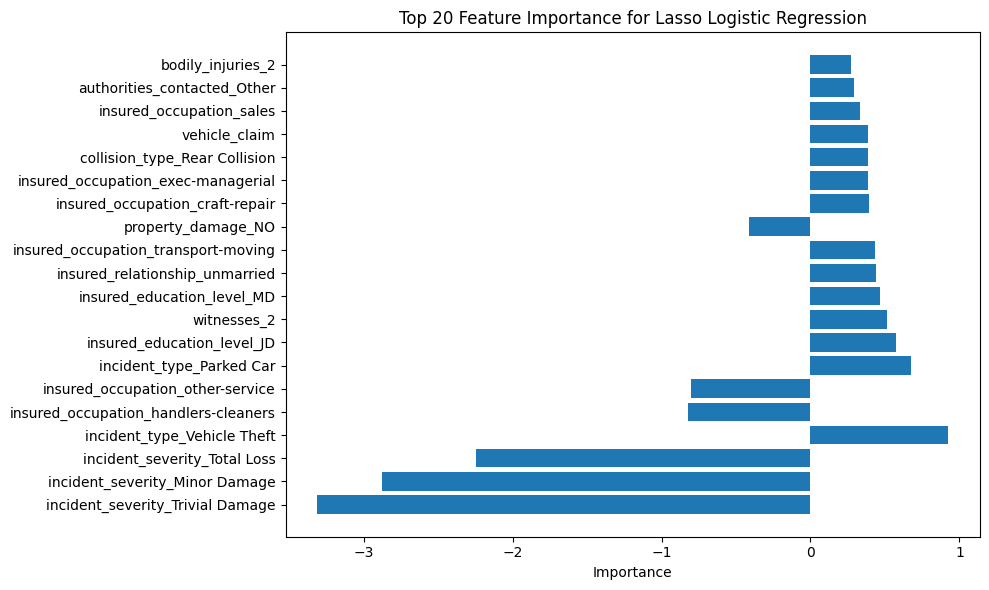

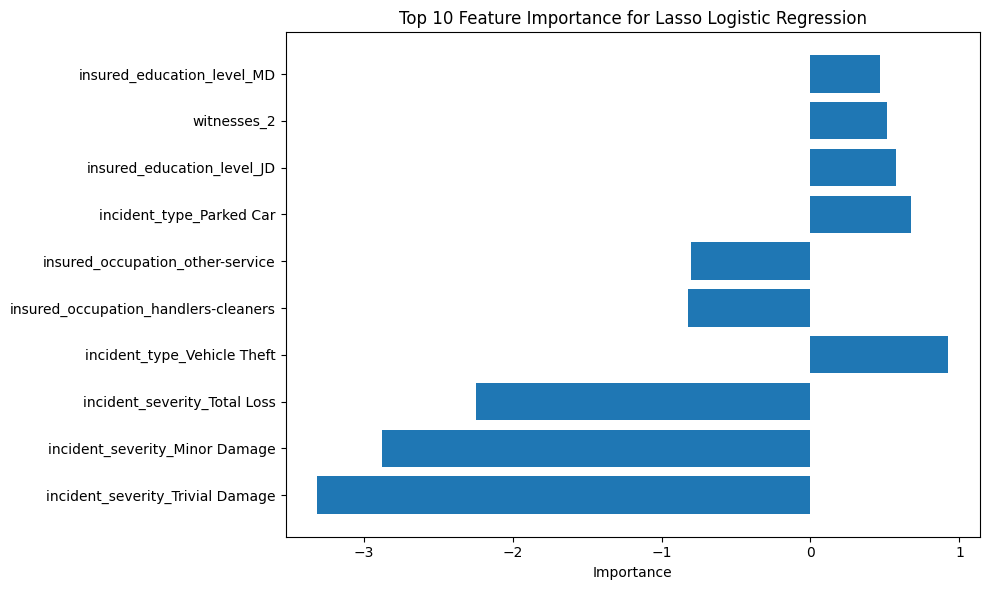

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Langkah 1: Latih model Lasso Logistic Regression dengan semua fitur
lasso_logreg_all = LogisticRegression(
    penalty='l1',  # Lasso regularization
    solver='liblinear',  # Solver untuk L1 penalty
    random_state=RANDOM_STATE,
    C=1
)
lasso_logreg_all.fit(X_res_df, y_res)

# Hitung Log-Loss untuk model dengan semua fitur
y_prob_all = lasso_logreg_all.predict_proba(X_test_df)[:, 1]
log_loss_all = log_loss(y_test, y_prob_all)

# Koefisien dari model dengan semua fitur
coef_all = lasso_logreg_all.coef_[0]

# Urutkan fitur berdasarkan koefisien (feature importance)
feature_importance_all_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': coef_all
})

# Urutkan berdasarkan nilai mutlak koefisien (feature importance)
feature_importance_all_df['importance_abs'] = feature_importance_all_df['importance'].abs()
feature_importance_all_df = feature_importance_all_df.sort_values(by='importance_abs', ascending=False)

# Pilih 20 dan 10 fitur terpenting berdasarkan importance
top_20_features = feature_importance_all_df.head(20)['feature']
top_10_features = feature_importance_all_df.head(10)['feature']

# Langkah 2: Latih model dengan 10 dan 20 fitur terpenting
lasso_logreg_20 = LogisticRegression(
    penalty='l1',  # Lasso regularization
    solver='liblinear',  # Solver untuk L1 penalty
    random_state=RANDOM_STATE,
    C=0.012
)
lasso_logreg_20.fit(X_res_df[top_20_features], y_res)

lasso_logreg_10 = LogisticRegression(
    penalty='l1',  # Lasso regularization
    solver='liblinear',  # Solver untuk L1 penalty
    random_state=RANDOM_STATE,
    C=0.012
)
lasso_logreg_10.fit(X_res_df[top_10_features], y_res)

# Hitung Log-Loss untuk model dengan 20 dan 10 fitur
y_prob_20 = lasso_logreg_20.predict_proba(X_test_df[top_20_features])[:, 1]
log_loss_20 = log_loss(y_test, y_prob_20)

y_prob_10 = lasso_logreg_10.predict_proba(X_test_df[top_10_features])[:, 1]
log_loss_10 = log_loss(y_test, y_prob_10)

# Langkah 3: Hitung lambda untuk 20 dan 10 fitur berdasarkan rumus
def calculate_lambda(log_loss_new, log_loss_old, coef_new):
    lambda_value = (log_loss_new - log_loss_old) / np.sum(np.abs(coef_new))
    return lambda_value

# Hitung lambda untuk 20 dan 10 fitur
lambda_20 = calculate_lambda(log_loss_20, log_loss_all, lasso_logreg_20.coef_[0])
lambda_10 = calculate_lambda(log_loss_10, log_loss_all, lasso_logreg_10.coef_[0])

# Output hasil lambda untuk 10 dan 20 fitur
print(f"Lambda untuk 20 fitur non-zero: {lambda_20}")
print(f"Lambda untuk 10 fitur non-zero: {lambda_10}")

# Tampilkan fitur importance dan koefisiennya
print("\nTop 20 Features and Their Importance:")
print(feature_importance_all_df.head(20))

print("\nTop 10 Features and Their Importance:")
print(feature_importance_all_df.head(10))

# Visualisasi Feature Importance untuk 20 Fitur
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_all_df['feature'][:20], feature_importance_all_df['importance'][:20])
plt.xlabel('Importance')
plt.title('Top 20 Feature Importance for Lasso Logistic Regression')
plt.tight_layout()
plt.show()

# Visualisasi Feature Importance untuk 10 Fitur
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_all_df['feature'][:10], feature_importance_all_df['importance'][:10])
plt.xlabel('Importance')
plt.title('Top 10 Feature Importance for Lasso Logistic Regression')
plt.tight_layout()
plt.show()


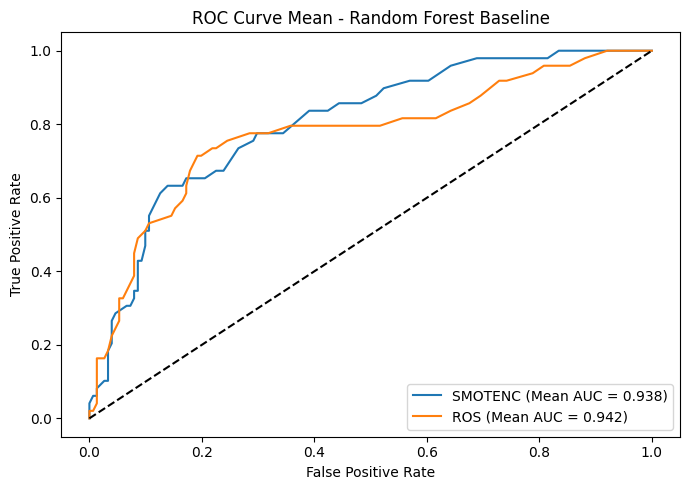

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
threshold = 0.6
all_results = []

# === Visualisasi Mean ROC AUC, Precision-Recall, dan Calibration untuk Random Forest Baseline ===
X_test_scaled_df = pd.read_csv(f"{OUTPUT_DIR}/X_test_normalized.csv")
y_test = pd.read_csv(f"{OUTPUT_DIR}/y_test.csv").squeeze()
y_test_int = y_test.astype(int)

# === 1. ROC Curve ===
plt.figure(figsize=(7, 5))

for sampler_name, (X_res, y_res) in resampled_data.items():
    df_results = pd.read_csv(f"{OUTPUT_DIR}/rf_kfold_classweight_summary_5fold_25iter_{sampler_name}.csv")

    imputer = SimpleImputer(strategy='mean')
    imputer.fit(X_res)
    X_test_scaled_imputed = imputer.transform(X_test_scaled_df)
    X_test_scaled_imputed_df = pd.DataFrame(X_test_scaled_imputed, columns=X_test_scaled_df.columns)

    y_res = y_res.astype(int)

    rf = RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced",
        max_depth=None,
        n_jobs=-1
    )
    rf.fit(X_res, y_res)

    y_prob = rf.predict_proba(X_test_scaled_imputed_df)[:, 1]

    if len(y_test_int) == len(y_prob):
        fpr, tpr, _ = roc_curve(y_test_int, y_prob)
        roc_auc = auc(fpr, tpr)
        mean_auc = df_results["mean_roc_auc"].mean()
        plt.plot(fpr, tpr, label=f"{sampler_name} (Mean AUC = {mean_auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--')
plt.title("ROC Curve Mean - Random Forest Baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/roc_auc_mean_rf_plain.png")
plt.show()